# Week - 41

- Revisar el paper de Athen con respecto a generality y vulerability.
- Agregar logica para almacenar las redes deducidas/predichas.
- Revisar si podemos agregar pesos a los links usando SEAL o solo podemos agregar propieades a los nodos?
    - En caso de poder usar pesos en links, podemos agregar body mass ratio? o ecosystem type?
- Terminar refactorizacion de SEAL para CUDA Python

- Testear la data de Yujie:
    - Correr 2 escenarios:
        - 1. Correr la foodweb por cada año (60% a 90% train ratio).
        - 2. Correr toda la foodweb entera y volver al master de Eoen para valudar con las foodwebs potenciales.

- Change all the equation to use plain text in the manuscript.
- Generar todas las figuras con los resultados de performance sin filtro Tukey y colocar debajo del caption en cada una para comparar.
-

# Week 40: SEAL_directed ×100 en GPU en Apocrita

## Resumen

Se ejecutarán **100 corridas GPU completamente nuevas para cada una de las 290 redes**: 29,000 experimentos. Las tres corridas históricas CPU permanecerán separadas.

SEAL conservará su configuración científica actual, sin imitar a WLNM:

- Splits 90/10 generados independientemente.
- 44 atributos nodales.
- Negativos 1:1.
- Filtro ecológico actual y fallback al conjunto completo de non-links cuando sea insuficiente.
- `hop=1`, 50 épocas, batch 50 y threshold 0.5.
- Embeddings desactivados.
- Resultados raw, sin Tukey.
- Semilla única por red y repetición:

  `seed = 12345 + 100 × (foodweb_index − 1) + (ExperimentID − 1)`.

La comparación posterior representará configuraciones completas independientes. No permitirá atribuir las diferencias exclusivamente al algoritmo, especialmente para PR-AUC, Precision y F1, porque WLNM y SEAL usan balances de clases y estrategias negativas diferentes.

## Refactorización necesaria

Se refactorizarán [Main_directed.py](/Users/acw792/Developer/qmul-phd-framework/src/python/seal_directed/Main_directed.py), [run_foodweb_seal_directed.py](/Users/acw792/Developer/qmul-phd-framework/src/python/seal_directed/run_foodweb_seal_directed.py) y el backend DGCNN para:

- Separar `run_experiment(config)` del parseo global de argumentos.
- Reemplazar `--cuda` por `--device cuda --require-cuda`; abortar si CUDA no está disponible, sin fallback silencioso a CPU.
- Modernizar `.cuda()` y comprobaciones de tipos a `.to(device)` y `.is_cuda`.
- Guardar y restaurar el modelo del mejor epoch según validation loss, evaluando test una sola vez al final.
- Reemplazar `fork + mp.cpu_count()` por un pool `spawn` reutilizable y `--num-workers`, limitado por Slurm.
- Corregir la escritura duplicada actual y eliminar el append concurrente.
- Escribir cada corrida atómicamente en un namespace único:

  `runs/<foodweb>/experiment_<id>_seed_<seed>/`

- Implementar resume idempotente: saltar únicamente una corrida con artefactos válidos y configuration hash idéntico.
- Hacer que los fallos produzcan exit code no cero, aunque se terminen de procesar las demás redes del shard.
- Registrar tiempos separados de carga, muestreo, extracción de subgrafos, entrenamiento, inferencia y escritura.
- Separar `RequestedTrainRatio=90` de `RealizedTrainRatio`.
- Reducir los logs por época para evitar varios gigabytes de salida.
- Importar `gensim/node2vec` solo si se solicitan embeddings.

El `libgnn.so` actual es Mach-O ARM64 de macOS. Se retirará el binario compilado del control de versiones, se ignorará `lib/build/` y se recompilará en Apocrita; `file libgnn.so` deberá reportar **ELF x86-64**.

## Entorno GPU reproducible

Se usará **Miniforge**, recomendado por Apocrita en lugar de Anaconda/Miniconda, con un entorno por prefijo almacenado en el storage del proyecto. El entorno se creará dentro de una sesión `salloc`, nunca en el login node. Véanse las guías de [Miniforge](https://docs.hpc.qmul.ac.uk/apps/languages/miniforge/) y [PyTorch](https://docs.hpc.qmul.ac.uk/apps/ml/pytorch/).

Baseline:

- Python 3.12.
- PyTorch 2.11.0 con wheel oficial CUDA 12.8.
- FP32.
- Versiones exactas de NumPy, SciPy, scikit-learn, NetworkX y tqdm bloqueadas.
- `environment.yml`, lock de pip y `pip freeze` guardados con el run.
- No se cargará un módulo CUDA separado salvo que el smoke test demuestre que el wheel lo necesita.

El launcher exigirá:

- `PROJECT_RESULTS_ROOT`: ruta persistente del proyecto.
- `SEAL_ENV_PREFIX`: entorno Miniforge persistente.
- `SCRATCH_ROOT=/gpfs/scratch/$USER/...`: staging y caché.
- Un commit limpio o un snapshot de código con hash registrado.

No podrá lanzarse la campaña completa hasta que `PROJECT_RESULTS_ROOT` exista, sea escribible y tenga al menos dos veces el almacenamiento extrapolado en el piloto.

## Artefactos y reproducibilidad

Por corrida se guardará: teams

- Train/test positivos y negativos.
- Scores y labels individuales.
- Pseudo-red inferida en representación sparse.
- Hashes del split y del orden de nodos.
- Métricas predictivas y ecológicas.
- Seed, configuración, commit, versiones, hostname, GPU, CUDA y tiempos por fase.
- `metrics.json`, `artifacts.npz` comprimido y marcador `_SUCCESS`.

No se guardarán 29,000 checkpoints del modelo.

Al finalizar se generarán:

- Una tabla raw de 29,000 filas.
- CSV compatibles con 100 filas por food web.
- Una tabla de una media raw por `food web × metric`, sin Tukey, para boxplots con 290 observaciones por método.
- Un informe explícito de las corridas que utilizaron el fallback de negativos; con los datos actuales se esperan 8 redes y aproximadamente 800 corridas.

## Estrategia Slurm

### 1. Smoke test en `gpushort`

Apocrita requiere probar primero en `gpushort`, demostrar uso real de GPU durante al menos 20 minutos y después solicitar acceso a producción. Se usará una GPU, 8 CPU y 88 GB de RAM según la [plantilla GPU oficial](https://docs.hpc.qmul.ac.uk/using/usingGPU/):

- Una red normal pequeña.
- Una red que active el fallback, por ejemplo `PP1I4`.
- Una red costosa, como Weddell Sea o Chesapeake Bay.
- Al menos dos seeds cuando quepan en una hora.

El smoke deberá registrar `torch.cuda.is_available()`, GPU, VRAM, versiones y muestras de `nvidia-smi`. No se fijará manualmente `CUDA_VISIBLE_DEVICES`.

Se iniciará con determinismo estricto. Si una operación CUDA no lo soporta, solo esa restricción podrá relajarse, documentando la operación y la evidencia.

### 2. Benchmark y acceso de producción

Con el job ID y evidencia de uso real se solicitará acceso a la partición `gpu`. No se impondrá inicialmente `ampere` o `hopper`, para no restringir innecesariamente la cola.

Después del acceso:

- `ExperimentID=1` recorrerá las 290 redes como shard de calibración con walltime de 24 horas.
- Si completa y valida, contará como la primera de las 100 corridas.
- El walltime restante será `1.5 × duración del shard`, redondeado hacia arriba y con una hora adicional, sin superar 240 horas.
- Si el preprocesamiento consume más del 50% del tiempo o la utilización GPU mediana durante entrenamiento es menor del 20%, se añadirá un productor CPU que prepare la siguiente red en `$TMPDIR` mientras la GPU entrena la actual.

### 3. Array completo

Se utilizará:

- `--array=1-100%2`.
- Un task por `ExperimentID`.
- Cada task recorrerá las 290 redes.
- Una GPU por task.
- Throttle inicial de dos GPU simultáneas.
- Tras cinco shards válidos y estables, podrá aumentarse a cuatro si la cuota y la partición lo permiten.
- Reintentos únicamente para los ExperimentID fallidos; resume omitirá las corridas ya validadas.

Este diseño equilibra redes grandes y pequeñas, evita 29,000 jobs individuales y elimina escrituras concurrentes sobre un mismo CSV. La implementación seguirá la guía oficial de [arrays Slurm](https://docs.hpc.qmul.ac.uk/using/arrays/), usará `$TMPDIR` para I/O temporal y conservará los resultados finales fuera del [scratch sujeto a eliminación](https://docs.hpc.qmul.ac.uk/storage/scratch/).

## Pruebas y criterios de aceptación

Antes del full run:

- Tests unitarios de seeds, splits, negativos sin solapamiento, threshold `score > 0.5`, métricas, resume y escrituras atómicas.
- Confirmar exactamente una fila por corrida.
- Confirmar que el filtro y fallback actuales de SEAL no cambiaron.
- Importar el backend ELF y ejecutar forward/backward en CUDA.
- Verificar determinismo repitiendo la misma corrida GPU.
- Verificar hashes de split idénticos entre una ejecución diagnóstica CPU/GPU.
- Confirmar que el modelo y los tensores están realmente en `cuda:0`.
- Smoke de tres redes sin OOM ni valores no finitos.

El full run solo se considerará terminado cuando:

- Existan exactamente 29,000 registros y 29,000 NPZ válidos.
- Cada una de las 290 redes tenga ExperimentID 1–100.
- Las 29,000 seeds sean únicas.
- No haya duplicados, artefactos parciales ni configuration hashes discordantes.
- ROC-AUC, PR-AUC, Precision, Recall y F1 estén en `[0,1]`; MCC y TSS en `[-1,1]`.
- `sacct` confirme estados y exit codes correctos para todos los tasks.
- El validador final pase después de Slurm; la presencia de archivos por sí sola no contará como finalización.
- Se copie y verifique el resultado completo en `PROJECT_RESULTS_ROOT`.

No se modificará código ni se enviará ningún job hasta aprobar este plan.


[INFO] Repository: /Users/acw792/Developer/qmul-phd-framework
[INFO] Loading and validating the four result sets...
[PASS] Matched 290/290 food webs; 1,160 method-level rows and 5,800 plotting observations.

=== Input and protocol audit ===


,Method,Source,Food webs,Raw runs,Runs/web,Aggregation,Test negatives:positives,Target train ratio,Achieved ratio recorded,Threshold,Notes
0,WLNM original,result_wlnm_original_100x290_train10-90_thresh...,290,29000,100,Mean across all raw runs; no Tukey filtering,2:1,90%,90% label,0.50,All 100 raw runs included
1,WLNM directed-negative,result_wlnm_dir_neg_roleonly_trophicv2_100x290...,290,29000,100,Mean across all raw runs; no Tukey filtering,2:1,90%,90% label,0.50,All 100 raw runs included
2,SEAL original,src/python/data/result/prediction_scores_logs,290,580,2,Mean across repeats,1:1,90%,50.00–94.74% (median 90.23%),0.50,Balanced held-out positives/negatives
3,SEAL directed,src/python/seal_directed/data/result/predictio...,290,870,3,Mean across repeats,1:1,90%,90.00–94.74% (median 90.13%),0.50,Balanced held-out positives/negatives; role-po...



=== WLNM raw-run counts for the five common metrics ===


,Metric,FoodWebs,MinimumRetainedRuns,MedianRetainedRuns,MaximumRetainedRuns,Method
0,ROC-AUC,290,100,100.0,100,WLNM original
1,PR-AUC,290,100,100.0,100,WLNM original
2,F1,290,100,100.0,100,WLNM original
3,Precision,290,100,100.0,100,WLNM original
4,Recall,290,100,100.0,100,WLNM original
5,ROC-AUC,290,100,100.0,100,WLNM directed-negative
6,PR-AUC,290,100,100.0,100,WLNM directed-negative
7,F1,290,100,100.0,100,WLNM directed-negative
8,Precision,290,100,100.0,100,WLNM directed-negative
9,Recall,290,100,100.0,100,WLNM directed-negative



=== Food-web-level descriptive medians ===


Method,WLNM original,WLNM directed-negative,SEAL original,SEAL directed
Metric,,,,
ROC-AUC,0.8306,0.9102,0.8474,0.9203
PR-AUC,0.6032,0.5475,0.8326,0.9222
F1,0.6591,0.7201,0.7719,0.8465
Precision,0.7180,0.9507,0.7230,0.8350
Recall,0.6372,0.6079,0.8472,0.8743



[CAUTION] Preliminary descriptive comparison only. SEAL uses 2/3 repeats and a 1:1 held-out negative:positive ratio; WLNM uses all 100 raw repeats and a 2:1 ratio. PR-AUC, Precision and F1 are especially sensitive to this prevalence difference.
[CAUTION] 'SEAL directed' is the complete current configuration (directionality, node attributes and role-aware negative sampling), not a direction-only ablation.

[PASS] Generated 20 boxplots (4 methods × 5 metrics).


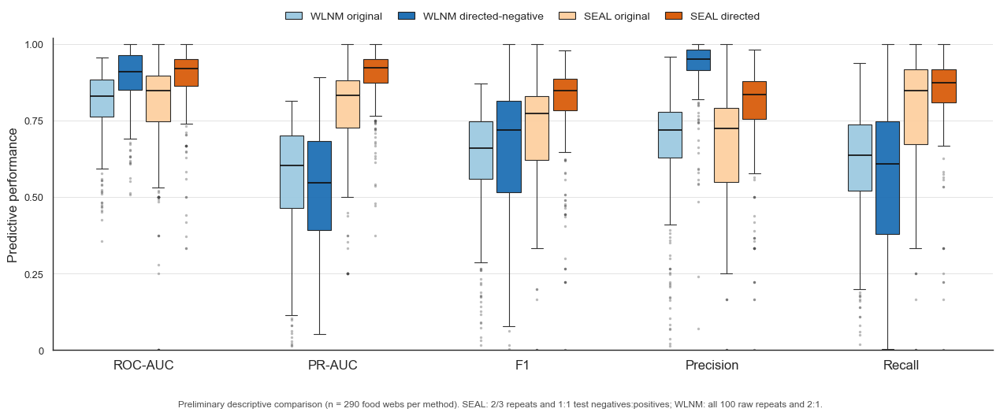

In [1]:
from pathlib import Path
import json
import re

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.patches import Patch




# ============================================================
# Raw predictive inputs (no Tukey filtering)
# ============================================================

import re


def _raw_foodweb_name(path):
    return re.sub(
        r"_tax_mass_results_random_wlnm_.*$",
        "",
        path.stem,
        flags=re.I,
    )


def load_raw_predictive_compat(
    result_root,
    expected_version,
    metric_specs,
    expected_runs,
    minimum_retained_runs,
    *,
    train_ratios=None,
    cvk_values=None,
    k_target=10,
    threshold=0.50,
    kfold=False,
    scenario=None,
):
    """Return raw web-level means in the legacy plotting schema.

    The legacy column names are retained only so that the original plotting,
    layout, scale, colour and export code remains byte-for-byte unchanged.
    MeanAfterTukey below is a compatibility alias for the arithmetic mean of
    every complete raw run unit; no Tukey fences or outlier exclusions occur.
    """
    metrics = [metric for metric, _ in metric_specs]
    labels = dict(metric_specs)
    files = sorted((result_root / "prediction_scores_logs").glob("*.csv"))
    if not files:
        raise FileNotFoundError(result_root / "prediction_scores_logs")

    required = {
        "Version",
        "TrainRatio",
        "ExperimentID",
        "Seed",
        "Threshold",
        "K",
        "CvK",
        "FoldID",
        "EmpiricalConnectance",
        *metrics,
    }
    frames = []
    for path in files:
        frame = pd.read_csv(
            path,
            usecols=lambda column: column in required,
        )
        missing = required.difference(frame.columns)
        if missing:
            raise ValueError(
                f"{path.name}: missing raw columns {sorted(missing)}"
            )
        frame["Foodweb"] = _raw_foodweb_name(path)
        frames.append(frame)

    raw = pd.concat(frames, ignore_index=True)
    for column in required.difference({"Version"}):
        raw[column] = pd.to_numeric(raw[column], errors="coerce")
    raw["TrainRatio"] = np.where(
        raw["TrainRatio"].abs().le(1.0),
        raw["TrainRatio"] * 100.0,
        raw["TrainRatio"],
    )
    raw = raw.loc[
        raw["Version"].eq(expected_version)
        & np.isclose(raw["Threshold"], threshold, atol=1e-9)
        & np.isclose(raw["K"], k_target, atol=1e-9)
    ].copy()
    if train_ratios is not None:
        requested = np.asarray(list(train_ratios), dtype=float)
        raw = raw.loc[
            raw["TrainRatio"].map(
                lambda value: np.isclose(
                    value,
                    requested,
                    atol=1e-8,
                ).any()
            )
        ].copy()
    if cvk_values is not None:
        raw = raw.loc[raw["CvK"].isin(cvk_values)].copy()
    if raw.empty:
        raise ValueError(f"No raw observations selected from {result_root}")

    metric_values = raw[metrics].to_numpy(float)
    if not np.isfinite(metric_values).all():
        raise ValueError(f"Non-finite raw predictive values in {result_root}")
    probability_metrics = [
        metric for metric in metrics if metric not in {"TestMCC", "TestTSS"}
    ]
    signed_metrics = [
        metric for metric in metrics if metric in {"TestMCC", "TestTSS"}
    ]
    if probability_metrics:
        values = raw[probability_metrics].to_numpy(float)
        if ((values < 0) | (values > 1)).any():
            raise ValueError("Raw probability metrics must be within [0, 1]")
    if signed_metrics:
        values = raw[signed_metrics].to_numpy(float)
        if ((values < -1) | (values > 1)).any():
            raise ValueError("Raw MCC/TSS values must be within [-1, 1]")

    group_columns = [
        "Foodweb",
        "Version",
        "TrainRatio",
        "Threshold",
        "K",
        "CvK",
    ]
    if kfold:
        experiment_columns = [*group_columns, "ExperimentID"]
        fold_check = (
            raw.groupby(experiment_columns, dropna=False)
            .agg(
                FoldRows=("FoldID", "size"),
                UniqueFolds=("FoldID", "nunique"),
            )
            .reset_index()
        )
        incomplete = fold_check.loc[
            ~fold_check["FoldRows"].eq(fold_check["CvK"])
            | ~fold_check["UniqueFolds"].eq(fold_check["CvK"])
        ]
        if not incomplete.empty:
            raise ValueError(
                "Incomplete repeated-CV experiments found:\n"
                + incomplete.head(10).to_string(index=False)
            )
        run_units = (
            raw.groupby(
                experiment_columns,
                dropna=False,
                as_index=False,
            )
            .agg(
                **{
                    metric: (metric, "mean")
                    for metric in metrics
                },
                EmpiricalConnectance=(
                    "EmpiricalConnectance",
                    "first",
                ),
            )
        )
    else:
        experiment_columns = [*group_columns, "ExperimentID"]
        if raw.duplicated(experiment_columns).any():
            raise ValueError(f"Duplicate raw ExperimentID rows in {result_root}")
        run_units = raw

    counts = run_units.groupby(group_columns, dropna=False).size()
    if not counts.eq(expected_runs).all():
        raise ValueError(
            f"{result_root.name}: expected {expected_runs} complete raw "
            "run units per group; observed "
            f"{counts.value_counts().to_dict()}"
        )

    wide = (
        run_units.groupby(
            group_columns,
            dropna=False,
            as_index=False,
        )
        .agg(
            **{
                metric: (metric, "mean")
                for metric in metrics
            },
            EmpiricalConnectance=(
                "EmpiricalConnectance",
                "first",
            ),
            RawRunUnits=("ExperimentID", "size"),
        )
    )
    long = wide.melt(
        id_vars=[
            *group_columns,
            "EmpiricalConnectance",
            "RawRunUnits",
        ],
        value_vars=metrics,
        var_name="Metric",
        value_name="MeanAfterTukey",
    )
    long["Scenario"] = scenario or result_root.name
    long["MetricLabel"] = long["Metric"].map(labels)
    long["MetricFamily"] = "predictive"
    long["SourceColumn"] = long["Metric"]
    long["ReferenceColumn"] = ""
    long["MeanBeforeTukey"] = long["MeanAfterTukey"]
    long["TotalRunUnits"] = long["RawRunUnits"]
    long["ValidRunsBeforeTukey"] = long["RawRunUnits"]
    long["InvalidRunsBeforeTukey"] = 0
    long["OutlierRunsExcluded"] = 0
    long["RetainedRunsAfterTukey"] = long["RawRunUnits"]
    long["ExpectedRuns"] = expected_runs
    long["MinimumRetainedRuns"] = minimum_retained_runs
    long["MeetsMinimumRetainedRuns"] = 1
    long["ReferenceValue"] = long["EmpiricalConnectance"]
    return long

# ============================================================
# Configuration
# ============================================================

def find_repo_root(start):
    start = Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / ".git").exists() and (candidate / "src").is_dir():
            return candidate
    raise FileNotFoundError(f"Repository root not found from {start}")


REPO_ROOT = find_repo_root(Path.cwd())
TRAIN_RATIO = 90
THRESHOLD = 0.50
N_WEBS = 290
WLNM_RUNS = 100
MIN_RETAINED = 25
RETENTION = "tukey_iqr_1p5_min25runs_threshold0p50_v1"

WLNM_ROOTS = {
    "WLNM_original": REPO_ROOT / "src/matlab/data/result_wlnm_original_100x290_train10-90_thresh0p50_Apocrita_20260916_221905",
    "WLNM_dir_neg": REPO_ROOT / "src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848",
}
SEAL_CONFIG = {
    "SEAL_original": {
        "results": REPO_ROOT / "src/python/data/result/prediction_scores_logs",
        "logs": REPO_ROOT / "src/python/data/result/terminal_logs",
        "pattern": "*_results_SEAL.csv",
        "version": "SEAL_undirected",
        "repeats": 2,
        "seeds": {12345, 12346},
        "fallbacks": 0,
    },
    "SEAL_directed": {
        "results": REPO_ROOT / "src/python/seal_directed/data/result/prediction_scores_logs",
        "logs": REPO_ROOT / "src/python/seal_directed/data/result/terminal_logs",
        "pattern": "*_results_SEAL_directed.csv",
        "version": "SEAL_directed",
        "repeats": 3,
        "seeds": {12345, 12346, 12347},
        "fallbacks": 24,
    },
}
METRIC_SPECS = [
    ("ROC_AUC", "ROC-AUC"),
    ("PR_AUC", "PR-AUC"),
    ("F1Score", "F1"),
    ("Precision", "Precision"),
    ("Recall", "Recall"),
]
METRICS = [x for x, _ in METRIC_SPECS]
METRIC_LABELS = dict(METRIC_SPECS)
METHOD_ORDER = ["WLNM_original", "WLNM_dir_neg", "SEAL_original", "SEAL_directed"]
METHOD_LABELS = {
    "WLNM_original": "WLNM original",
    "WLNM_dir_neg": "WLNM directed-negative",
    "SEAL_original": "SEAL original",
    "SEAL_directed": "SEAL directed",
}
PALETTE = {
    "WLNM_original": "#9ECAE1",
    "WLNM_dir_neg": "#2171B5",
    "SEAL_original": "#FDD0A2",
    "SEAL_directed": "#D95F0E",
}


# ============================================================
# Loaders and validation
# ============================================================

def fw_key(value):
    text = Path(str(value)).stem.strip()
    text = re.sub(r"_tax_mass_results_SEAL(?:_directed)?$", "", text, flags=re.I)
    text = re.sub(r"_tax_mass_results_random_wlnm_(?:original|dir_neg)$", "", text, flags=re.I)
    return " ".join(re.sub(r"[^a-z0-9]+", " ", text.casefold()).split())


def validate_values(frame, label):
    values = frame[METRICS].apply(pd.to_numeric, errors="coerce")
    if values.isna().any().any():
        raise ValueError(f"{label}: missing or non-numeric metric values")
    array = values.to_numpy(float)
    if not np.isfinite(array).all() or ((array < 0) | (array > 1)).any():
        raise ValueError(f"{label}: metric values must be finite and within [0, 1]")


def validate_keys(frame, source_col, label):
    collisions = (
        frame[["FW_KEY", source_col]].drop_duplicates()
        .groupby("FW_KEY")[source_col].nunique()
    )
    if (collisions > 1).any():
        raise ValueError(f"{label}: normalized food-web name collision")
    if frame["FW_KEY"].nunique() != N_WEBS:
        raise ValueError(f"{label}: expected {N_WEBS} food webs")


def validate_wlnm_raw(root):
    files = sorted((root / "prediction_scores_logs").glob("*.csv"))
    if len(files) != N_WEBS:
        raise ValueError(f"{root.name}: expected {N_WEBS} raw CSV files")
    ratios = []
    total_rows = 0
    usecols = ["TrainRatio", "TestTP", "TestFP", "TestFN", "TestTN"]
    for path in files:
        data = pd.read_csv(path, usecols=usecols)
        data = data[np.isclose(data["TrainRatio"], TRAIN_RATIO)]
        if len(data) != WLNM_RUNS:
            raise ValueError(f"{path.name}: expected {WLNM_RUNS} train-90 runs")
        positives = data["TestTP"] + data["TestFN"]
        negatives = data["TestFP"] + data["TestTN"]
        if (positives <= 0).any():
            raise ValueError(f"{path.name}: invalid test-positive count")
        ratios.extend((negatives / positives).to_numpy(float))
        total_rows += len(data)
    ratios = np.asarray(ratios)
    if not np.allclose(ratios, 2.0):
        raise ValueError(f"{root.name}: test negative:positive ratio is not 2:1")
    return total_rows


def load_wlnm(method):
    root = WLNM_ROOTS[method]
    data = load_raw_predictive_compat(
        root,
        method,
        METRIC_SPECS,
        WLNM_RUNS,
        WLNM_RUNS,
        train_ratios=[TRAIN_RATIO],
    )
    data["FW_KEY"] = data["Foodweb"].map(fw_key)
    validate_keys(data, "Foodweb", method)
    if data.duplicated(["FW_KEY", "Metric"]).any():
        raise ValueError(f"{method}: duplicate food-web/metric rows")
    wide = (
        data.pivot(
            index="FW_KEY",
            columns="Metric",
            values="MeanAfterTukey",
        )
        .rename_axis(None, axis=1)
        .reset_index()
    )
    validate_values(wide, method)
    wide["Method"] = method
    raw_rows = validate_wlnm_raw(root)
    retention = data.groupby("Metric", as_index=False).agg(
        FoodWebs=("FW_KEY", "nunique"),
        MinimumRetainedRuns=("RetainedRunsAfterTukey", "min"),
        MedianRetainedRuns=("RetainedRunsAfterTukey", "median"),
        MaximumRetainedRuns=("RetainedRunsAfterTukey", "max"),
    )
    retention["Method"] = METHOD_LABELS[method]
    retention["Metric"] = retention["Metric"].map(METRIC_LABELS)
    audit = {
        "Method": METHOD_LABELS[method],
        "Source": root.name,
        "Food webs": N_WEBS,
        "Raw runs": raw_rows,
        "Runs/web": "100",
        "Aggregation": "Mean across all raw runs; no Tukey filtering",
        "Test negatives:positives": "2:1",
        "Target train ratio": "90%",
        "Achieved ratio recorded": "90% label",
        "Threshold": f"{THRESHOLD:.2f}",
        "Notes": "All 100 raw runs included",
    }
    return wide, audit, retention

def load_seal(method, config):
    files = sorted(config["results"].glob(config["pattern"]))
    if len(files) != N_WEBS:
        raise ValueError(f"{method}: expected {N_WEBS} result CSVs, found {len(files)}")
    frames = []
    required = set(METRICS) | {"Version", "TrainRatio", "ExperimentID", "Seed", "Threshold"}
    for path in files:
        data = pd.read_csv(path)
        if missing := required.difference(data.columns):
            raise ValueError(f"{path.name}: missing {sorted(missing)}")
        data["SourceFoodweb"] = re.sub(r"_tax_mass_results_SEAL(?:_directed)?\.csv$", "", path.name, flags=re.I)
        data["FW_KEY"] = data["SourceFoodweb"].map(fw_key)
        frames.append(data)
    raw = pd.concat(frames, ignore_index=True)
    validate_keys(raw, "SourceFoodweb", method)
    if set(raw["Version"].unique()) != {config["version"]}:
        raise ValueError(f"{method}: unexpected Version")
    if not np.allclose(raw["Threshold"], THRESHOLD):
        raise ValueError(f"{method}: unexpected threshold")
    if set(raw["Seed"].astype(int)) != config["seeds"] or set(raw["ExperimentID"].astype(int)) != set(range(1, config["repeats"] + 1)):
        raise ValueError(f"{method}: unexpected seeds or ExperimentID values")
    if set(raw.groupby("FW_KEY").size()) != {config["repeats"]}:
        raise ValueError(f"{method}: unexpected repeats per food web")
    if raw.duplicated(["FW_KEY", "ExperimentID"]).any():
        raise ValueError(f"{method}: duplicate food-web/experiment rows")
    validate_values(raw, method)

    log_files = sorted(config["logs"].glob("*.log"))
    if len(log_files) != len(raw):
        raise ValueError(f"{method}: expected {len(raw)} terminal logs, found {len(log_files)}")
    fallback_text = "role-constrained negative pool too small; falling back to all directed unknown links"
    fallbacks = sum(fallback_text in path.read_text(errors="replace") for path in log_files)
    if fallbacks != config["fallbacks"]:
        raise ValueError(f"{method}: expected {config['fallbacks']} fallbacks, found {fallbacks}")

    wide = raw.groupby("FW_KEY", as_index=False)[METRICS].mean()
    validate_values(wide, f"{method} means")
    wide["Method"] = method
    ratio_min, ratio_median, ratio_max = raw.TrainRatio.min(), raw.TrainRatio.median(), raw.TrainRatio.max()
    note = "Balanced held-out positives/negatives"
    if method == "SEAL_directed":
        note += f"; role-pool fallback in {fallbacks}/{len(raw)} runs"
    audit = {
        "Method": METHOD_LABELS[method],
        "Source": str(config["results"].relative_to(REPO_ROOT)),
        "Food webs": N_WEBS,
        "Raw runs": len(raw),
        "Runs/web": str(config["repeats"]),
        "Aggregation": "Mean across repeats",
        "Test negatives:positives": "1:1",
        "Target train ratio": "90%",
        "Achieved ratio recorded": f"{ratio_min:.2f}–{ratio_max:.2f}% (median {ratio_median:.2f}%)",
        "Threshold": f"{THRESHOLD:.2f}",
        "Notes": note,
    }
    return wide, audit


# ============================================================
# Build the matched comparison table
# ============================================================

print(f"[INFO] Repository: {REPO_ROOT}")
print("[INFO] Loading and validating the four result sets...")

wlnm_original, audit_wo, retention_wo = load_wlnm("WLNM_original")
wlnm_dir_neg, audit_wd, retention_wd = load_wlnm("WLNM_dir_neg")
seal_original, audit_so = load_seal("SEAL_original", SEAL_CONFIG["SEAL_original"])
seal_directed, audit_sd = load_seal("SEAL_directed", SEAL_CONFIG["SEAL_directed"])
frames = {
    "WLNM_original": wlnm_original,
    "WLNM_dir_neg": wlnm_dir_neg,
    "SEAL_original": seal_original,
    "SEAL_directed": seal_directed,
}
key_sets = {method: set(frame.FW_KEY) for method, frame in frames.items()}
common = set.intersection(*key_sets.values())
union = set.union(*key_sets.values())
if len(common) != N_WEBS or len(union) != N_WEBS:
    details = {method: {"missing": sorted(union - keys)[:10], "unpaired": sorted(keys - common)[:10]} for method, keys in key_sets.items()}
    raise ValueError(f"Food-web matching failed: {details}")

comparison_wide = pd.concat([frames[m] for m in METHOD_ORDER], ignore_index=True)[["FW_KEY", "Method", *METRICS]]
if comparison_wide.shape != (1160, 7) or comparison_wide.duplicated(["FW_KEY", "Method"]).any():
    raise ValueError(f"Invalid wide table: shape={comparison_wide.shape}")
validate_values(comparison_wide, "combined comparison")
comparison_long = comparison_wide.melt(
    id_vars=["FW_KEY", "Method"], value_vars=METRICS,
    var_name="Metric", value_name="Value",
)
comparison_long["MethodLabel"] = comparison_long.Method.map(METHOD_LABELS)
comparison_long["MetricLabel"] = comparison_long.Metric.map(METRIC_LABELS)
if len(comparison_long) != 5800 or comparison_long.Value.isna().any():
    raise ValueError(f"Invalid long table: rows={len(comparison_long)}")
print("[PASS] Matched 290/290 food webs; 1,160 method-level rows and 5,800 plotting observations.")


# ============================================================
# Audit and descriptive summaries
# ============================================================

audit_table = pd.DataFrame([audit_wo, audit_wd, audit_so, audit_sd])
print("\n=== Input and protocol audit ===")
display(audit_table)

retention_table = pd.concat([retention_wo, retention_wd], ignore_index=True)
metric_order = [label for _, label in METRIC_SPECS]
retention_table["Metric"] = pd.Categorical(retention_table.Metric, metric_order, ordered=True)
retention_table["Method"] = pd.Categorical(
    retention_table.Method,
    [METHOD_LABELS[m] for m in METHOD_ORDER[:2]],
    ordered=True,
)
retention_table = retention_table.sort_values(["Method", "Metric"]).reset_index(drop=True)
print("\n=== WLNM raw-run counts for the five common metrics ===")
display(retention_table)

median_table = (
    comparison_long.groupby(["Metric", "Method"], observed=True).Value.median()
    .unstack("Method").reindex(index=METRICS, columns=METHOD_ORDER)
    .rename(index=METRIC_LABELS, columns=METHOD_LABELS).round(4)
)
print("\n=== Food-web-level descriptive medians ===")
display(median_table)

print("\n[CAUTION] Preliminary descriptive comparison only. SEAL uses 2/3 repeats and a 1:1 held-out negative:positive ratio; WLNM uses all 100 raw repeats and a 2:1 ratio. PR-AUC, Precision and F1 are especially sensitive to this prevalence difference.")
print("[CAUTION] 'SEAL directed' is the complete current configuration (directionality, node attributes and role-aware negative sampling), not a direction-only ablation.")


# ============================================================
# Grouped boxplots (one value per food web and method)
# ============================================================

sns.set_theme(context="paper", style="white", font_scale=1.05)
fig, ax = plt.subplots(figsize=(12.8, 5.8))
centers = np.arange(len(METRICS), dtype=float) * 1.35 + 1.0
offsets = {"WLNM_original": -0.30, "WLNM_dir_neg": -0.10, "SEAL_original": 0.10, "SEAL_directed": 0.30}
box_count = 0
for method in METHOD_ORDER:
    datasets, positions = [], []
    for i, metric in enumerate(METRICS):
        values = comparison_long.loc[
            comparison_long.Method.eq(method) & comparison_long.Metric.eq(metric), "Value"
        ].to_numpy(float)
        if len(values) != N_WEBS:
            raise ValueError(f"{method}/{metric}: expected {N_WEBS} values")
        datasets.append(values)
        positions.append(centers[i] + offsets[method])
    artists = ax.boxplot(
        datasets, positions=positions, widths=0.17, patch_artist=True,
        manage_ticks=False, showfliers=True, whis=1.5,
        boxprops={"facecolor": PALETTE[method], "edgecolor": "#222222", "linewidth": 0.8, "alpha": 0.96},
        medianprops={"color": "#111111", "linewidth": 1.25},
        whiskerprops={"color": "#333333", "linewidth": 0.8},
        capprops={"color": "#333333", "linewidth": 0.8},
        flierprops={"marker": "o", "markersize": 2.4, "markerfacecolor": "#4D4D4D", "markeredgecolor": "none", "alpha": 0.38},
    )
    box_count += len(artists["boxes"])
if box_count != 20:
    raise RuntimeError(f"Expected 20 box artists, created {box_count}")

handles = [Patch(facecolor=PALETTE[m], edgecolor="#222222", linewidth=0.8, label=METHOD_LABELS[m]) for m in METHOD_ORDER]
ax.set_xlim(centers[0] - 0.65, centers[-1] + 0.65)
ax.set_ylim(0, 1.02)
ax.set_xticks(centers, [METRIC_LABELS[m] for m in METRICS], fontsize=12)
ax.set_yticks([0, 0.25, 0.50, 0.75, 1.00], ["0", "0.25", "0.50", "0.75", "1.00"])
ax.set_ylabel("Predictive performance", fontsize=12)
ax.grid(axis="y", color="#D9D9D9", linewidth=0.7, alpha=0.75)
ax.set_axisbelow(True)
ax.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=4, frameon=False, fontsize=10, columnspacing=1.4, handlelength=1.5)
sns.despine(ax=ax)
fig.text(
    0.5, 0.015,
    "Preliminary descriptive comparison (n = 290 food webs per method). SEAL: 2/3 repeats and 1:1 test negatives:positives; WLNM: all 100 raw repeats and 2:1.",
    ha="center", va="bottom", fontsize=8.5, color="#4D4D4D",
)
fig.tight_layout(rect=(0, 0.07, 1, 0.92))
print(f"\n[PASS] Generated {box_count} boxplots (4 methods × 5 metrics).")
plt.show()


[INFO] Panel a: Grand Caricaie  marsh dominated by Cladietum marisci, not mown  ClControl2


/var/folders/fh/0vq0142d1t36s502_bgq3z480000gp/T/ipykernel_1063/2185562803.py:795: DeprecationWarning: The default value for `spmatrix` is changing to `False` in v1.20.
        That means the default return type will be a sparse array.
        Unless you use * instead of @, ** for matrix power, or you depend
        on 2D shapes from e.g. `A.sum(axis=0)` it may not matter to you.
        See the spmatrix to sparray migration guide for details.
        https://docs.scipy.org/doc/scipy/reference/sparse.migration_to_sparray.html
        
  data = scipy.io.loadmat(


[INFO] Snapshot node names match tax_mass taxonomy.
[INFO] Exact run validated:
  K=10, TrainRatio=90%, ExperimentID=21, threshold=0.50
  Seed=1316850472
  Train=691, TP=39, FP=0, FN=38
  CSV=/Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/prediction_scores_logs/Grand Caricaie  marsh dominated by Cladietum marisci, not mown  ClControl2_tax_mass_results_random_wlnm_dir_neg.csv
  Snapshot=/Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/ecological_snapshots/Grand_Caricaie__marsh_dominated_by_Cladietum_marisci__not_mown__ClControl2_tax_mass_K10_ratio0.9_exp21_seed1316850472_threshold0.5_validated_v2.mat

[INFO] Panel b: Grand Caricaie  marsh dominated by Cladietum marisci, not mown  ClControl2
[INFO] Snapshot node names match tax_mass taxonomy.
[INFO] Exact run validated:
  K=10, TrainRatio=60%, Experimen

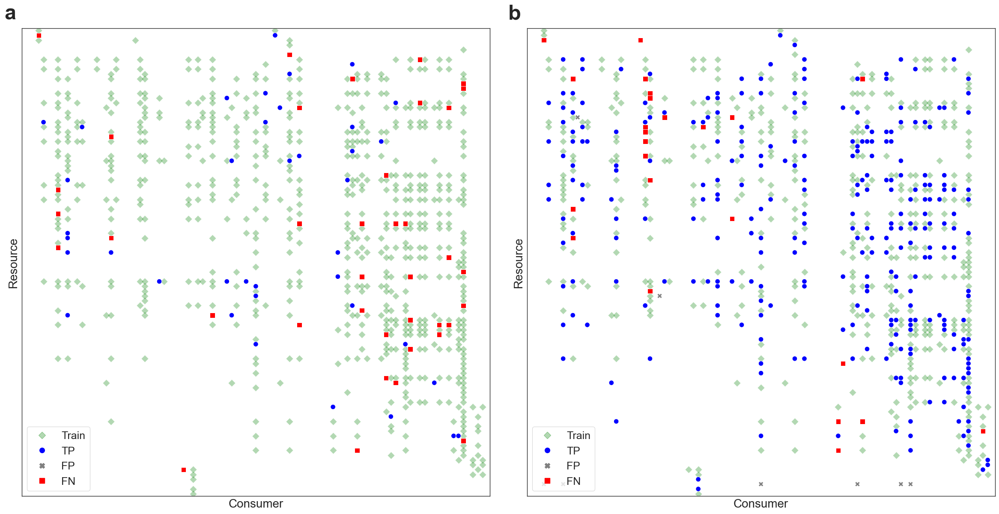

In [2]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.io
import seaborn as sns
from matplotlib.lines import Line2D
from scipy.sparse import csr_matrix, issparse


# ============================================================
# Style + repository
# ============================================================

sns.set_theme(context="paper", style="white", font_scale=3)


def find_repo_root(start=Path.cwd()):
    start = Path(start).resolve()

    for candidate in [start, *start.parents]:
        if (
            (candidate / "src/matlab").is_dir()
            and (candidate / "docs").is_dir()
        ):
            return candidate

    raise RuntimeError(
        f"Could not locate repository root from {start}"
    )


REPO_ROOT = find_repo_root()


# ============================================================
# SIMPLE PANEL CONFIGURATION
# Edit foodweb, train_ratio and experiment_id per panel.
# train_ratio accepts 60 / 90 or 0.60 / 0.90.
# ============================================================

DEFAULT_FOODWEB = (
    "Grand Caricaie  marsh dominated by "
    "Cladietum marisci, not mown  ClControl2"
)

PANELS = [
    {
        "letter": "a",
        "foodweb": DEFAULT_FOODWEB,
        "train_ratio": 90,
        "experiment_id": 21,
    },
    {
        "letter": "b",
        "foodweb": DEFAULT_FOODWEB,
        "train_ratio": 60,
        "experiment_id": 21,
    },
]

K_TARGET = 10
CLASSIFICATION_THRESHOLD = 0.50


# ============================================================
# Existing figure controls
# ============================================================

MIN_NODES = 40

SHOW_TITLES = False
SHOW_TICKS = False
USE_NUMERIC_AXIS_LABELS = False

XLAB = "Consumer"
YLAB = "Resource"

PANEL_XTICK_FONTSIZES = [12, 12]
PANEL_YTICK_FONTSIZES = [12, 12]

PRINT_SPECIES_KEY = False
EXPORT_SPECIES_KEY_FILE = True
SPECIES_KEY_FORMAT = "csv"

SPECIES_KEY_DIR = (
    REPO_ROOT
    / "docs/progress_notebooks_logs/2026/species_keys"
)


# ============================================================
# Input paths
# ============================================================

RESULT_ROOT = (
    REPO_ROOT
    / "src/matlab/data"
    / (
        "result_wlnm_dir_neg_roleonly_trophicv2_"
        "100x290_train10-90_Apocrita_20260910_011848"
    )
)

PREDICTION_LOG_DIR = (
    RESULT_ROOT
    / "prediction_scores_logs"
)

ECOLOGICAL_SNAPSHOTS_DIR = (
    RESULT_ROOT
    / "ecological_snapshots"
)

BASE_MAT_PATH = (
    REPO_ROOT
    / "src/matlab/data/foodwebs_mat"
)


# ============================================================
# Initial references
# Used only for the untouched initial configuration.
# Seeds are always read from the selected CSV row.
# ============================================================

def canonical_foodweb(name):
    name = str(name).strip()

    return (
        name[:-len("_tax_mass")]
        if name.endswith("_tax_mass")
        else name
    )


REFERENCE_FOODWEB = (
    "Grand Caricaie  marsh dominated by "
    "Cladietum marisci, not mown  ClControl2"
)


INITIAL_REFERENCE = {
    (
        canonical_foodweb(REFERENCE_FOODWEB),
        60.0,
        21,
    ): {
        "seed": 1314098572,
        "TrainLinks": 460,
        "TestTP": 284,
        "TestFP": 8,
        "TestFN": 24,
    },
    (
        canonical_foodweb(REFERENCE_FOODWEB),
        90.0,
        21,
    ): {
        "seed": 1316850472,
        "TrainLinks": 691,
        "TestTP": 39,
        "TestFP": 0,
        "TestFN": 38,
    },
}


# ============================================================
# Helpers
# ============================================================

def norm_name(value):
    return re.sub(
        r"[^a-z0-9]+",
        "",
        str(value).lower(),
    )


def find_col(
    df,
    *aliases,
    required=True,
):
    lookup = {
        norm_name(column): column
        for column in df.columns
    }

    for alias in aliases:
        key = norm_name(alias)

        if key in lookup:
            return lookup[key]

    if required:
        raise KeyError(
            f"Missing required column. Tried {aliases}. "
            f"Available columns: {list(df.columns)}"
        )

    return None


def ratio_percent(value):
    value = float(value)

    if 0 < value <= 1:
        value *= 100

    if not 0 < value <= 100:
        raise ValueError(
            f"Invalid train_ratio={value!r}"
        )

    return float(value)


def tax_mass_stem(foodweb):
    foodweb = str(foodweb).strip()

    return (
        foodweb
        if foodweb.endswith("_tax_mass")
        else f"{foodweb}_tax_mass"
    )


def as_int(
    value,
    label,
):
    numeric = pd.to_numeric(
        pd.Series([value]),
        errors="coerce",
    ).iloc[0]

    if pd.isna(numeric):
        raise ValueError(
            f"{label} is not numeric: {value!r}"
        )

    integer = int(
        round(
            float(numeric)
        )
    )

    if not np.isclose(
        float(numeric),
        integer,
        atol=1e-9,
        rtol=0,
    ):
        raise ValueError(
            f"{label} is not an integer: {value!r}"
        )

    return integer


def binary_csr(matrix):
    if issparse(matrix):
        out = matrix.tocsr(
            copy=True
        )
    else:
        out = csr_matrix(
            np.asarray(matrix)
        )

    out.sum_duplicates()
    out.eliminate_zeros()

    if out.nnz:
        out.data = np.ones(
            out.nnz,
            dtype=np.int8,
        )

    return out.astype(
        np.int8
    )


def mask_and(
    a,
    b,
):
    out = a.multiply(
        b
    ).tocsr()

    out.eliminate_zeros()

    if out.nnz:
        out.data[:] = 1

    return out


def mask_and_not(
    a,
    b,
):
    out = (
        a.astype(np.int8)
        - a.multiply(b).astype(np.int8)
    ).tocsr()

    out.eliminate_zeros()

    if out.nnz:
        if np.any(
            out.data < 0
        ):
            raise ValueError(
                "Unexpected negative entries while "
                "reconstructing sparse masks."
            )

        out.data[:] = 1

    return out


def sparse_equal(
    a,
    b,
):
    if a.shape != b.shape:
        return False

    diff = (
        a.astype(np.int8)
        - b.astype(np.int8)
    ).tocsr()

    diff.eliminate_zeros()

    return (
        diff.nnz == 0
    )


def unwrap(value):
    while (
        isinstance(
            value,
            np.ndarray,
        )
        and value.size == 1
    ):
        value = value.reshape(
            -1
        )[0]

    return value


def matlab_str(value):
    value = unwrap(
        value
    )

    if isinstance(
        value,
        (bytes, np.bytes_),
    ):
        return bytes(
            value
        ).decode(
            "utf-8",
            errors="replace",
        ).strip()

    if isinstance(
        value,
        str,
    ):
        return value.strip()

    if isinstance(
        value,
        np.str_,
    ):
        return str(
            value
        ).strip()

    if (
        isinstance(
            value,
            np.ndarray,
        )
        and value.dtype.kind
        in {
            "U",
            "S",
        }
    ):
        parts = []

        for item in value.reshape(
            -1
        ):
            if isinstance(
                item,
                (bytes, np.bytes_),
            ):
                parts.append(
                    bytes(
                        item
                    ).decode(
                        "utf-8",
                        errors="replace",
                    )
                )

            else:
                parts.append(
                    str(
                        item
                    )
                )

        return "".join(
            parts
        ).strip()

    return str(
        value
    ).strip()


def matlab_str_list(value):
    return [
        matlab_str(
            item
        )
        for item
        in np.asarray(
            value,
            dtype=object,
        ).reshape(-1)
    ]


def struct_fields(obj):
    obj = unwrap(
        obj
    )

    if isinstance(
        obj,
        dict,
    ):
        return list(
            obj.items()
        )

    names = getattr(
        obj,
        "_fieldnames",
        None,
    )

    if names:
        return [
            (
                name,
                getattr(
                    obj,
                    name,
                ),
            )
            for name in names
        ]

    if (
        isinstance(
            obj,
            np.void,
        )
        and obj.dtype.names
    ):
        return [
            (
                name,
                obj[name],
            )
            for name
            in obj.dtype.names
        ]

    return []


def struct_get(
    obj,
    field,
):
    target = norm_name(
        field
    )

    for name, value in struct_fields(
        obj
    ):
        if norm_name(
            name
        ) == target:
            return value

    raise KeyError(
        f"MATLAB struct is missing field "
        f"{field!r}. "
        f"Available fields: "
        f"{[name for name, _ in struct_fields(obj)]}"
    )


def struct_get_optional(
    obj,
    *aliases,
):
    targets = {
        norm_name(alias)
        for alias in aliases
    }

    for name, value in struct_fields(
        obj
    ):
        if norm_name(
            name
        ) in targets:
            return value

    return None


# ============================================================
# Exact CSV row selection
# ============================================================

def select_run(panel):
    foodweb = panel[
        "foodweb"
    ]

    ratio = ratio_percent(
        panel[
            "train_ratio"
        ]
    )

    experiment_id = int(
        panel[
            "experiment_id"
        ]
    )

    csv_path = (
        PREDICTION_LOG_DIR
        / (
            f"{tax_mass_stem(foodweb)}"
            "_results_random_wlnm_dir_neg.csv"
        )
    )

    if not csv_path.is_file():
        raise FileNotFoundError(
            "Results CSV not found:\n"
            f"  {csv_path}"
        )

    df = pd.read_csv(
        csv_path
    )

    k_col = find_col(
        df,
        "K",
        "SubgraphK",
    )

    ratio_col = find_col(
        df,
        "TrainRatio",
        "TrainingRatio",
    )

    exp_col = find_col(
        df,
        "ExperimentID",
        "Experiment",
    )

    threshold_col = find_col(
        df,
        "Threshold",
        "ClassificationThreshold",
    )

    foodweb_col = find_col(
        df,
        "Foodweb",
        "FoodWebName",
        required=False,
    )

    k = pd.to_numeric(
        df[k_col],
        errors="coerce",
    )

    train_ratio = pd.to_numeric(
        df[ratio_col],
        errors="coerce",
    )

    train_ratio = np.where(
        train_ratio
        <= 1.0 + 1e-12,
        train_ratio * 100.0,
        train_ratio,
    )

    experiment = pd.to_numeric(
        df[exp_col],
        errors="coerce",
    )

    threshold = pd.to_numeric(
        df[threshold_col],
        errors="coerce",
    )

    mask = (
        np.isclose(
            k,
            K_TARGET,
            atol=1e-12,
            rtol=0,
        )
        & np.isclose(
            train_ratio,
            ratio,
            atol=1e-9,
            rtol=0,
        )
        & np.isclose(
            experiment,
            experiment_id,
            atol=1e-12,
            rtol=0,
        )
        & np.isclose(
            threshold,
            CLASSIFICATION_THRESHOLD,
            atol=1e-12,
            rtol=0,
        )
    )

    if (
        foodweb_col
        is not None
    ):
        mask &= (
            df[foodweb_col]
            .astype(str)
            .map(
                canonical_foodweb
            )
            .eq(
                canonical_foodweb(
                    foodweb
                )
            )
        )

    matches = df.loc[
        mask
    ]

    if len(
        matches
    ) != 1:
        raise ValueError(
            "Expected exactly one matching run, "
            f"but found {len(matches)}.\n"
            f"  foodweb={foodweb!r}\n"
            f"  K={K_TARGET}\n"
            f"  TrainRatio={ratio:g}%\n"
            f"  ExperimentID={experiment_id}\n"
            f"  threshold={CLASSIFICATION_THRESHOLD}\n"
            f"  CSV={csv_path}"
        )

    return (
        matches.iloc[0],
        csv_path,
        ratio,
    )


# ============================================================
# Resolve LOCAL snapshot by basename only
# ============================================================

def local_snapshot_from_row(row):
    row_df = pd.DataFrame(
        [row]
    )

    snapshot_col = find_col(
        row_df,
        "TrophicSnapshotFile",
        "SnapshotFile",
    )

    raw = row[
        snapshot_col
    ]

    if pd.isna(
        raw
    ):
        raise ValueError(
            "TrophicSnapshotFile is empty "
            "for the selected run."
        )

    snapshot_name = (
        str(raw)
        .strip()
        .replace(
            "\\",
            "/",
        )
        .split("/")[-1]
    )

    matches = [
        path
        for path
        in ECOLOGICAL_SNAPSHOTS_DIR.rglob(
            "*.mat"
        )
        if path.name
        == snapshot_name
    ]

    if len(
        matches
    ) != 1:
        raise FileNotFoundError(
            "Expected exactly one LOCAL "
            "ecological snapshot, "
            f"found {len(matches)}.\n"
            f"  basename={snapshot_name!r}\n"
            f"  searched under="
            f"{ECOLOGICAL_SNAPSHOTS_DIR}\n"
            f"  matches={matches}"
        )

    return matches[0]


# ============================================================
# Load tax/mass file
# ============================================================

def load_tax_mass(foodweb):
    mat_path = (
        BASE_MAT_PATH
        / (
            f"{tax_mass_stem(foodweb)}"
            ".mat"
        )
    )

    if not mat_path.is_file():
        raise FileNotFoundError(
            "Food-web tax/mass MAT "
            "not found:\n"
            f"  {mat_path}"
        )

    data = scipy.io.loadmat(
        mat_path,
        struct_as_record=False,
        squeeze_me=True,
    )

    for key in (
        "net",
        "taxonomy",
        "mass",
    ):
        if key not in data:
            raise KeyError(
                f"{mat_path} "
                f"is missing {key!r}"
            )

    net = binary_csr(
        data[
            "net"
        ]
    )
    # WLNM_dir_neg removes self-loops before saving empirical.
    net.setdiag(0)
    net.eliminate_zeros()

    taxonomy = matlab_str_list(
        data[
            "taxonomy"
        ]
    )

    mass = np.asarray(
        data[
            "mass"
        ]
    ).reshape(
        -1
    ).astype(
        float
    )

    n = len(
        taxonomy
    )

    if len(
        mass
    ) != n:
        raise ValueError(
            "taxonomy and mass "
            "have different lengths in "
            f"{mat_path}"
        )

    if net.shape != (
        n,
        n,
    ):
        raise ValueError(
            f"net.shape={net.shape}, "
            f"expected {(n, n)}"
        )

    if n < MIN_NODES:
        raise ValueError(
            f"Selected food web has "
            f"{n} nodes, below "
            f"MIN_NODES={MIN_NODES}."
        )

    if not np.all(
        np.isfinite(
            mass
        )
    ):
        raise ValueError(
            "Non-finite body masses "
            f"found in {mat_path}"
        )

    normalized = [
        re.sub(
            r"\s+",
            " ",
            value.strip(),
        )
        for value
        in taxonomy
    ]

    if len(
        set(
            normalized
        )
    ) != n:
        raise ValueError(
            "Duplicate taxonomy labels "
            "found; node mapping is ambiguous."
        )

    return (
        mat_path,
        net,
        taxonomy,
        mass,
    )


# ============================================================
# Load snapshot + reconstruct Train / TP / FP / FN
# ============================================================

def load_snapshot(
    snapshot_path,
    base_net,
    taxonomy,
):
    data = scipy.io.loadmat(
        snapshot_path,
        struct_as_record=False,
        squeeze_me=True,
    )

    if (
        "snapshot"
        not in data
    ):
        raise KeyError(
            "'snapshot' struct "
            "not found in "
            f"{snapshot_path}"
        )

    snapshot = data[
        "snapshot"
    ]

    empirical = binary_csr(
        struct_get(
            snapshot,
            "empirical",
        )
    )

    train = binary_csr(
        struct_get(
            snapshot,
            "train",
        )
    )

    pseudo = binary_csr(
        struct_get(
            snapshot,
            "pseudo",
        )
    )

    metadata = struct_get(
        snapshot,
        "metadata",
    )

    n = len(
        taxonomy
    )

    for name, matrix in {
        "empirical": empirical,
        "train": train,
        "pseudo": pseudo,
    }.items():

        if matrix.shape != (
            n,
            n,
        ):
            raise ValueError(
                f"snapshot.{name}.shape="
                f"{matrix.shape}, "
                f"expected {(n, n)}"
            )

    # Validate snapshot node indexing and direction against
    # the original directed food-web matrix.
    if not sparse_equal(
        empirical,
        base_net,
    ):
        if sparse_equal(
            empirical,
            base_net.T.tocsr(),
        ):
            raise ValueError(
                "snapshot.empirical matches "
                "net.T rather than net. "
                "Direction/index convention "
                "is inconsistent."
            )

        raise ValueError(
            "snapshot.empirical does not "
            "match the tax_mass net. "
            "Node identity/order cannot "
            "be validated safely."
        )

    train_outside_empirical = (
        mask_and_not(
            train,
            empirical,
        )
    )

    if (
        train_outside_empirical.nnz
    ):
        raise ValueError(
            "snapshot.train contains "
            f"{train_outside_empirical.nnz} "
            "links absent from empirical."
        )

    # If metadata exposes node names, verify those explicitly too.
    metadata_nodes = struct_get_optional(
        metadata,
        "taxonomy",
        "taxa",
        "species",
        "species_names",
        "node_names",
        "node_labels",
    )

    if (
        metadata_nodes
        is not None
    ):
        names = matlab_str_list(
            metadata_nodes
        )

        if len(
            names
        ) == n:

            def clean(value):
                return re.sub(
                    r"\s+",
                    " ",
                    value.strip(),
                )

            if (
                list(
                    map(
                        clean,
                        names,
                    )
                )
                != list(
                    map(
                        clean,
                        taxonomy,
                    )
                )
            ):
                raise ValueError(
                    "Snapshot metadata node names "
                    "do not match tax_mass taxonomy "
                    "in the same index order."
                )

            print(
                "[INFO] Snapshot node names "
                "match tax_mass taxonomy."
            )

    # --------------------------------------------------------
    # Required reconstruction
    # --------------------------------------------------------
    #
    # Train          = train
    # true_test      = empirical & ~train
    # predicted_test = pseudo & ~train
    # TP             = true_test & predicted_test
    # FP             = predicted_test & ~true_test
    # FN             = true_test & ~predicted_test
    #

    true_test = mask_and_not(
        empirical,
        train,
    )

    predicted_test = mask_and_not(
        pseudo,
        train,
    )

    tp = mask_and(
        true_test,
        predicted_test,
    )

    fp = mask_and_not(
        predicted_test,
        true_test,
    )

    fn = mask_and_not(
        true_test,
        predicted_test,
    )

    return {
        "Train": train,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "metadata": metadata,
    }


# ============================================================
# Validate seed + reconstructed counts against selected CSV row
# ============================================================

def validate_run(
    row,
    panel,
    ratio,
    masks,
    snapshot_path,
):
    row_df = pd.DataFrame(
        [row]
    )

    seed_col = find_col(
        row_df,
        "Seed",
        "RandomSeed",
        "ExperimentSeed",
    )

    train_col = find_col(
        row_df,
        "TrainLinks",
    )

    tp_col = find_col(
        row_df,
        "TestTP",
    )

    fp_col = find_col(
        row_df,
        "TestFP",
    )

    fn_col = find_col(
        row_df,
        "TestFN",
    )

    seed = as_int(
        row[
            seed_col
        ],
        "Seed",
    )

    csv_counts = {
        "TrainLinks": as_int(
            row[
                train_col
            ],
            "TrainLinks",
        ),
        "TestTP": as_int(
            row[
                tp_col
            ],
            "TestTP",
        ),
        "TestFP": as_int(
            row[
                fp_col
            ],
            "TestFP",
        ),
        "TestFN": as_int(
            row[
                fn_col
            ],
            "TestFN",
        ),
    }

    reconstructed = {
        "TrainLinks": (
            masks[
                "Train"
            ].nnz
        ),
        "TestTP": (
            masks[
                "TP"
            ].nnz
        ),
        "TestFP": (
            masks[
                "FP"
            ].nnz
        ),
        "TestFN": (
            masks[
                "FN"
            ].nnz
        ),
    }

    if (
        csv_counts
        != reconstructed
    ):
        raise ValueError(
            "Reconstructed counts do not "
            "match the selected CSV row.\n"
            f"  CSV={csv_counts}\n"
            f"  reconstructed={reconstructed}\n"
            f"  snapshot={snapshot_path}"
        )

    # If metadata contains its own seed, verify that too.
    metadata_seed = struct_get_optional(
        masks[
            "metadata"
        ],
        "seed",
        "random_seed",
        "experiment_seed",
    )

    if (
        metadata_seed
        is not None
    ):
        snapshot_seed = as_int(
            unwrap(
                metadata_seed
            ),
            "snapshot metadata seed",
        )

        if (
            snapshot_seed
            != seed
        ):
            raise ValueError(
                "Seed mismatch between CSV "
                "and snapshot metadata:\n"
                f"  CSV={seed}\n"
                f"  snapshot={snapshot_seed}"
            )

    # Only the untouched initial configuration is checked
    # against the supplied reference seed/counts.
    ref_key = (
        canonical_foodweb(
            panel[
                "foodweb"
            ]
        ),
        float(
            ratio
        ),
        int(
            panel[
                "experiment_id"
            ]
        ),
    )

    reference = INITIAL_REFERENCE.get(
        ref_key
    )

    if (
        reference
        is not None
    ):
        if (
            seed
            != reference[
                "seed"
            ]
        ):
            raise ValueError(
                "Initial seed does not match "
                "the supplied reference:\n"
                f"  expected="
                f"{reference['seed']}\n"
                f"  CSV={seed}"
            )

        for key in (
            "TrainLinks",
            "TestTP",
            "TestFP",
            "TestFN",
        ):
            if (
                reconstructed[
                    key
                ]
                != reference[
                    key
                ]
            ):
                raise ValueError(
                    "Initial reference mismatch "
                    f"for {key}: "
                    f"expected={reference[key]}, "
                    f"observed={reconstructed[key]}"
                )

    return (
        seed,
        reconstructed,
    )


# ============================================================
# Sparse directed links -> mass-sorted plotting coordinates
#
# Matrix convention:
#   row    = Resource / Prey
#   column = Consumer / Predator
# ============================================================

def mask_to_df(
    mask,
    original_to_sorted,
    label,
):
    (
        resource_idx,
        consumer_idx,
    ) = mask.nonzero()

    return pd.DataFrame({
        "PreyIdx": (
            original_to_sorted[
                resource_idx
            ]
        ),
        "PredIdx": (
            original_to_sorted[
                consumer_idx
            ]
        ),
        "Label": label,
    })


# ============================================================
# Validate ALL panels before drawing
# ============================================================

for label, path in {
    "prediction_scores_logs":
        PREDICTION_LOG_DIR,
    "ecological_snapshots":
        ECOLOGICAL_SNAPSHOTS_DIR,
    "foodwebs_mat":
        BASE_MAT_PATH,
}.items():

    if not path.is_dir():
        raise FileNotFoundError(
            f"Missing {label} directory:\n"
            f"  {path}"
        )


prepared = []
tax_mass_cache = {}
species_key_done = set()


for panel_idx, panel in enumerate(
    PANELS
):
    letter = panel.get(
        "letter",
        chr(
            ord("a")
            + panel_idx
        ),
    )

    print(
        "\n"
        + "=" * 70
    )

    print(
        f"[INFO] Panel {letter}: "
        f"{canonical_foodweb(panel['foodweb'])}"
    )

    # --------------------------------------------------------
    # 1. Locate exactly one run in prediction_scores_logs
    # --------------------------------------------------------

    (
        row,
        results_csv,
        ratio,
    ) = select_run(
        panel
    )

    # --------------------------------------------------------
    # 2. Resolve LOCAL snapshot from TrophicSnapshotFile basename
    # --------------------------------------------------------

    snapshot_path = (
        local_snapshot_from_row(
            row
        )
    )

    # --------------------------------------------------------
    # 3. Load taxonomy / mass / empirical net
    # --------------------------------------------------------

    stem = tax_mass_stem(
        panel[
            "foodweb"
        ]
    )

    if (
        stem
        not in tax_mass_cache
    ):
        tax_mass_cache[
            stem
        ] = load_tax_mass(
            panel[
                "foodweb"
            ]
        )

    (
        tax_mass_path,
        base_net,
        taxonomy,
        mass,
    ) = tax_mass_cache[
        stem
    ]

    # --------------------------------------------------------
    # 4. Load snapshot and reconstruct Train / TP / FP / FN
    # --------------------------------------------------------

    masks = load_snapshot(
        snapshot_path,
        base_net,
        taxonomy,
    )

    # --------------------------------------------------------
    # 5. Validate seed and reconstructed counts
    # --------------------------------------------------------

    (
        seed,
        counts,
    ) = validate_run(
        row=row,
        panel=panel,
        ratio=ratio,
        masks=masks,
        snapshot_path=snapshot_path,
    )

    print(
        "[INFO] Exact run validated:\n"
        f"  K={K_TARGET}, "
        f"TrainRatio={ratio:g}%, "
        f"ExperimentID="
        f"{panel['experiment_id']}, "
        f"threshold="
        f"{CLASSIFICATION_THRESHOLD:.2f}\n"
        f"  Seed={seed}\n"
        f"  Train="
        f"{counts['TrainLinks']:,}, "
        f"TP={counts['TestTP']:,}, "
        f"FP={counts['TestFP']:,}, "
        f"FN={counts['TestFN']:,}\n"
        f"  CSV={results_csv}\n"
        f"  Snapshot={snapshot_path}"
    )

    # --------------------------------------------------------
    # 6. Sort species by body mass
    # --------------------------------------------------------

    # Same conversion used by the original cell.
    mass_mg = np.round(
        mass * 1000.0,
        4,
    )

    sorted_original_idx = np.argsort(
        mass_mg,
        kind="stable",
    )

    sorted_species = [
        taxonomy[
            index
        ]
        for index
        in sorted_original_idx
    ]

    sorted_mass_mg = (
        mass_mg[
            sorted_original_idx
        ]
    )

    n = len(
        sorted_species
    )

    original_to_sorted = np.empty(
        n,
        dtype=int,
    )

    original_to_sorted[
        sorted_original_idx
    ] = np.arange(
        n
    )

    # Stable numbering for the same food web in both panels.
    species_to_num = {
        species: index + 1
        for index, species
        in enumerate(
            sorted_species
        )
    }

    # --------------------------------------------------------
    # Optional species key
    # --------------------------------------------------------

    if (
        PRINT_SPECIES_KEY
        and stem
        not in species_key_done
    ):
        key_df = pd.DataFrame({
            "Number": np.arange(
                1,
                n + 1,
            ),
            "Species":
                sorted_species,
            "Mass_mg":
                sorted_mass_mg,
        })

        key_df[
            "Mass_mg"
        ] = (
            key_df[
                "Mass_mg"
            ]
            .map(
                lambda value:
                f"{value:.4f}"
            )
        )

        print(
            "\n"
            + key_df.to_string(
                index=False
            )
        )

        if (
            EXPORT_SPECIES_KEY_FILE
        ):
            SPECIES_KEY_DIR.mkdir(
                parents=True,
                exist_ok=True,
            )

            safe_foodweb = re.sub(
                r"[^A-Za-z0-9._-]+",
                "_",
                stem,
            ).strip(
                "_"
            )

            extension = (
                "tsv"
                if (
                    SPECIES_KEY_FORMAT.lower()
                    == "tsv"
                )
                else "csv"
            )

            output_path = (
                SPECIES_KEY_DIR
                / (
                    f"{safe_foodweb}_"
                    f"species_key."
                    f"{extension}"
                )
            )

            key_df.to_csv(
                output_path,
                sep=(
                    "\t"
                    if extension
                    == "tsv"
                    else ","
                ),
                index=False,
                encoding="utf-8",
            )

            print(
                "[INFO] Saved species key: "
                f"{output_path.resolve()}"
            )

        species_key_done.add(
            stem
        )

    # --------------------------------------------------------
    # 7. Convert reconstructed matrices to plot coordinates
    # --------------------------------------------------------

    df_train = mask_to_df(
        masks[
            "Train"
        ],
        original_to_sorted,
        "Train",
    )

    df_pm = pd.concat(
        [
            mask_to_df(
                masks[
                    "TP"
                ],
                original_to_sorted,
                "TP",
            ),
            mask_to_df(
                masks[
                    "FP"
                ],
                original_to_sorted,
                "FP",
            ),
            mask_to_df(
                masks[
                    "FN"
                ],
                original_to_sorted,
                "FN",
            ),
        ],
        ignore_index=True,
    )

    prepared.append({
        "letter":
            letter,
        "foodweb":
            canonical_foodweb(
                panel[
                    "foodweb"
                ]
            ),
        "train_ratio":
            ratio,
        "experiment_id":
            int(
                panel[
                    "experiment_id"
                ]
            ),
        "seed":
            seed,
        "n":
            n,
        "sorted_species":
            sorted_species,
        "species_to_num":
            species_to_num,
        "df_train":
            df_train,
        "df_pm":
            df_pm,
    })


# ============================================================
# Plot only AFTER every panel has passed all checks
# ============================================================

fig, axs = plt.subplots(
    1,
    len(
        prepared
    ),
    figsize=(
        12 * len(
            prepared
        ),
        12,
    ),
    squeeze=False,
)

axs = axs.ravel()


# Keep Train / TP / FP / FN in every legend,
# including FP when FP=0 in panel b.
legend_handles = [
    Line2D(
        [0],
        [0],
        marker="D",
        linestyle="None",
        markerfacecolor="green",
        markeredgecolor="green",
        alpha=0.3,
        markersize=np.sqrt(
            70
        ),
        label="Train",
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="None",
        markerfacecolor="blue",
        markeredgecolor="blue",
        markersize=np.sqrt(
            70
        ),
        label="TP",
    ),
    Line2D(
        [0],
        [0],
        marker="X",
        linestyle="None",
        markerfacecolor="gray",
        markeredgecolor="gray",
        markersize=np.sqrt(
            70
        ),
        label="FP",
    ),
    Line2D(
        [0],
        [0],
        marker="s",
        linestyle="None",
        markerfacecolor="red",
        markeredgecolor="red",
        markersize=np.sqrt(
            70
        ),
        label="FN",
    ),
]


for panel_idx, panel in enumerate(
    prepared
):
    ax = axs[
        panel_idx
    ]

    n = panel[
        "n"
    ]

    # --------------------------------------------------------
    # Training links first
    # green diamond, alpha=0.3, s=70
    # --------------------------------------------------------

    if not panel[
        "df_train"
    ].empty:
        sns.scatterplot(
            data=panel[
                "df_train"
            ],
            x="PredIdx",
            y="PreyIdx",
            color="green",
            marker="D",
            alpha=0.3,
            s=70,
            legend=False,
            ax=ax,
        )

    # --------------------------------------------------------
    # TP / FP / FN
    # --------------------------------------------------------

    if not panel[
        "df_pm"
    ].empty:
        sns.scatterplot(
            data=panel[
                "df_pm"
            ],
            x="PredIdx",
            y="PreyIdx",
            hue="Label",
            style="Label",
            hue_order=[
                "TP",
                "FP",
                "FN",
            ],
            style_order=[
                "TP",
                "FP",
                "FN",
            ],
            markers={
                "TP": "o",
                "FP": "X",
                "FN": "s",
            },
            palette={
                "TP": "blue",
                "FP": "gray",
                "FN": "red",
            },
            s=70,
            legend=False,
            ax=ax,
        )

    # Consumer body mass increases left -> right.
    ax.set_xlim(
        -0.5,
        n - 0.5,
    )

    # Resource body mass increases top -> bottom.
    ax.set_ylim(
        n - 0.5,
        -0.5,
    )

    ax.set_aspect(
        "equal",
        adjustable="box",
    )

    ax.set_xlabel(
        XLAB,
        fontsize=20,
    )

    ax.set_ylabel(
        YLAB,
        fontsize=20,
    )

    # --------------------------------------------------------
    # Existing tick controls
    # --------------------------------------------------------

    if SHOW_TICKS:
        ax.set_xticks(
            range(
                n
            )
        )

        ax.set_yticks(
            range(
                n
            )
        )

        x_fontsize = (
            PANEL_XTICK_FONTSIZES[
                panel_idx
            ]
        )

        y_fontsize = (
            PANEL_YTICK_FONTSIZES[
                panel_idx
            ]
        )

        if (
            USE_NUMERIC_AXIS_LABELS
        ):
            labels = [
                str(
                    panel[
                        "species_to_num"
                    ][
                        species
                    ]
                )
                for species
                in panel[
                    "sorted_species"
                ]
            ]

            ax.set_xticklabels(
                labels,
                rotation=90,
                fontsize=x_fontsize,
            )

            ax.set_yticklabels(
                labels,
                fontsize=y_fontsize,
            )

        else:
            ax.set_xticklabels(
                panel[
                    "sorted_species"
                ],
                rotation=90,
                fontsize=x_fontsize,
            )

            ax.set_yticklabels(
                panel[
                    "sorted_species"
                ],
                fontsize=y_fontsize,
            )

        ax.tick_params(
            axis="both",
            which="both",
            length=3,
        )

    else:
        ax.set_xticks(
            []
        )

        ax.set_yticks(
            []
        )

        ax.set_xticklabels(
            []
        )

        ax.set_yticklabels(
            []
        )

        ax.tick_params(
            axis="both",
            which="both",
            length=0,
        )

    # --------------------------------------------------------
    # Existing title control
    # --------------------------------------------------------

    if SHOW_TITLES:
        ax.set_title(
            panel[
                "foodweb"
            ],
            fontsize=12,
        )

    # --------------------------------------------------------
    # Panel letter outside matrix
    # --------------------------------------------------------

    ax.annotate(
        panel["letter"],
        xy=(0, 1),
        xycoords="axes fraction",
        xytext=(-10, 8),
        textcoords="offset points",
        ha="right",
        va="bottom",
        fontsize=35,
        fontweight="bold",
        annotation_clip=False,
    )

    # --------------------------------------------------------
    # Legend
    # --------------------------------------------------------

    ax.legend(
        handles=legend_handles,
        loc="lower left",
        prop={
            "size": 18,
        },
        title="",
    )


plt.tight_layout()
plt.show()


[INFO] Panel a: Hoel lake


/var/folders/fh/0vq0142d1t36s502_bgq3z480000gp/T/ipykernel_1063/3140162145.py:794: DeprecationWarning: The default value for `spmatrix` is changing to `False` in v1.20.
        That means the default return type will be a sparse array.
        Unless you use * instead of @, ** for matrix power, or you depend
        on 2D shapes from e.g. `A.sum(axis=0)` it may not matter to you.
        See the spmatrix to sparray migration guide for details.
        https://docs.scipy.org/doc/scipy/reference/sparse.migration_to_sparray.html
        
  data = scipy.io.loadmat(


[INFO] Snapshot node names match tax_mass taxonomy.
[INFO] Exact run validated:
  K=10, TrainRatio=60%, ExperimentID=21, threshold=0.50
  Seed=1801531645
  Train=338, TP=221, FP=2, FN=5
  CSV=/Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/prediction_scores_logs/Hoel lake_tax_mass_results_random_wlnm_dir_neg.csv
  Snapshot=/Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/ecological_snapshots/Hoel_lake_tax_mass_K10_ratio0.6_exp21_seed1801531645_threshold0.5_validated_v2.mat

[INFO] Panel b: Hoel lake
[INFO] Snapshot node names match tax_mass taxonomy.
[INFO] Exact run validated:
  K=10, TrainRatio=90%, ExperimentID=21, threshold=0.50
  Seed=1804283545
  Train=507, TP=57, FP=0, FN=0
  CSV=/Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_

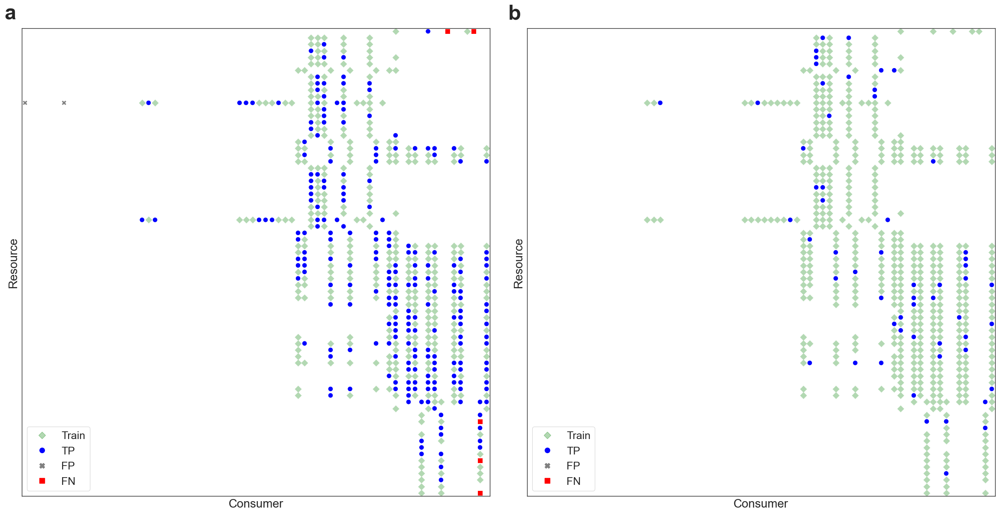

In [3]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.io
import seaborn as sns
from matplotlib.lines import Line2D
from scipy.sparse import csr_matrix, issparse


# ============================================================
# Style + repository
# ============================================================

sns.set_theme(context="paper", style="white", font_scale=3)


def find_repo_root(start=Path.cwd()):
    start = Path(start).resolve()

    for candidate in [start, *start.parents]:
        if (
            (candidate / "src/matlab").is_dir()
            and (candidate / "docs").is_dir()
        ):
            return candidate

    raise RuntimeError(
        f"Could not locate repository root from {start}"
    )


REPO_ROOT = find_repo_root()


# ============================================================
# SIMPLE PANEL CONFIGURATION
# Edit foodweb, train_ratio and experiment_id per panel.
# train_ratio accepts 60 / 90 or 0.60 / 0.90.
# ============================================================

DEFAULT_FOODWEB = (
    "Hoel lake"
)

PANELS = [
    {
        "letter": "a",
        "foodweb": DEFAULT_FOODWEB,
        "train_ratio": 60,
        "experiment_id": 21,
    },
    {
        "letter": "b",
        "foodweb": DEFAULT_FOODWEB,
        "train_ratio": 90,
        "experiment_id": 21,
    },
]

K_TARGET = 10
CLASSIFICATION_THRESHOLD = 0.50


# ============================================================
# Existing figure controls
# ============================================================

MIN_NODES = 40

SHOW_TITLES = False
SHOW_TICKS = False
USE_NUMERIC_AXIS_LABELS = False

XLAB = "Consumer"
YLAB = "Resource"

PANEL_XTICK_FONTSIZES = [12, 12]
PANEL_YTICK_FONTSIZES = [12, 12]

PRINT_SPECIES_KEY = False
EXPORT_SPECIES_KEY_FILE = True
SPECIES_KEY_FORMAT = "csv"

SPECIES_KEY_DIR = (
    REPO_ROOT
    / "docs/progress_notebooks_logs/2026/species_keys"
)


# ============================================================
# Input paths
# ============================================================

RESULT_ROOT = (
    REPO_ROOT
    / "src/matlab/data"
    / (
        "result_wlnm_dir_neg_roleonly_trophicv2_"
        "100x290_train10-90_Apocrita_20260910_011848"
    )
)

PREDICTION_LOG_DIR = (
    RESULT_ROOT
    / "prediction_scores_logs"
)

ECOLOGICAL_SNAPSHOTS_DIR = (
    RESULT_ROOT
    / "ecological_snapshots"
)

BASE_MAT_PATH = (
    REPO_ROOT
    / "src/matlab/data/foodwebs_mat"
)


# ============================================================
# Initial references
# Used only for the untouched initial configuration.
# Seeds are always read from the selected CSV row.
# ============================================================

def canonical_foodweb(name):
    name = str(name).strip()

    return (
        name[:-len("_tax_mass")]
        if name.endswith("_tax_mass")
        else name
    )


REFERENCE_FOODWEB = (
    "Grand Caricaie  marsh dominated by "
    "Cladietum marisci, not mown  ClControl2"
)


INITIAL_REFERENCE = {
    (
        canonical_foodweb(REFERENCE_FOODWEB),
        60.0,
        21,
    ): {
        "seed": 1314098572,
        "TrainLinks": 460,
        "TestTP": 284,
        "TestFP": 8,
        "TestFN": 24,
    },
    (
        canonical_foodweb(REFERENCE_FOODWEB),
        90.0,
        21,
    ): {
        "seed": 1316850472,
        "TrainLinks": 691,
        "TestTP": 39,
        "TestFP": 0,
        "TestFN": 38,
    },
}


# ============================================================
# Helpers
# ============================================================

def norm_name(value):
    return re.sub(
        r"[^a-z0-9]+",
        "",
        str(value).lower(),
    )


def find_col(
    df,
    *aliases,
    required=True,
):
    lookup = {
        norm_name(column): column
        for column in df.columns
    }

    for alias in aliases:
        key = norm_name(alias)

        if key in lookup:
            return lookup[key]

    if required:
        raise KeyError(
            f"Missing required column. Tried {aliases}. "
            f"Available columns: {list(df.columns)}"
        )

    return None


def ratio_percent(value):
    value = float(value)

    if 0 < value <= 1:
        value *= 100

    if not 0 < value <= 100:
        raise ValueError(
            f"Invalid train_ratio={value!r}"
        )

    return float(value)


def tax_mass_stem(foodweb):
    foodweb = str(foodweb).strip()

    return (
        foodweb
        if foodweb.endswith("_tax_mass")
        else f"{foodweb}_tax_mass"
    )


def as_int(
    value,
    label,
):
    numeric = pd.to_numeric(
        pd.Series([value]),
        errors="coerce",
    ).iloc[0]

    if pd.isna(numeric):
        raise ValueError(
            f"{label} is not numeric: {value!r}"
        )

    integer = int(
        round(
            float(numeric)
        )
    )

    if not np.isclose(
        float(numeric),
        integer,
        atol=1e-9,
        rtol=0,
    ):
        raise ValueError(
            f"{label} is not an integer: {value!r}"
        )

    return integer


def binary_csr(matrix):
    if issparse(matrix):
        out = matrix.tocsr(
            copy=True
        )
    else:
        out = csr_matrix(
            np.asarray(matrix)
        )

    out.sum_duplicates()
    out.eliminate_zeros()

    if out.nnz:
        out.data = np.ones(
            out.nnz,
            dtype=np.int8,
        )

    return out.astype(
        np.int8
    )


def mask_and(
    a,
    b,
):
    out = a.multiply(
        b
    ).tocsr()

    out.eliminate_zeros()

    if out.nnz:
        out.data[:] = 1

    return out


def mask_and_not(
    a,
    b,
):
    out = (
        a.astype(np.int8)
        - a.multiply(b).astype(np.int8)
    ).tocsr()

    out.eliminate_zeros()

    if out.nnz:
        if np.any(
            out.data < 0
        ):
            raise ValueError(
                "Unexpected negative entries while "
                "reconstructing sparse masks."
            )

        out.data[:] = 1

    return out


def sparse_equal(
    a,
    b,
):
    if a.shape != b.shape:
        return False

    diff = (
        a.astype(np.int8)
        - b.astype(np.int8)
    ).tocsr()

    diff.eliminate_zeros()

    return (
        diff.nnz == 0
    )


def unwrap(value):
    while (
        isinstance(
            value,
            np.ndarray,
        )
        and value.size == 1
    ):
        value = value.reshape(
            -1
        )[0]

    return value


def matlab_str(value):
    value = unwrap(
        value
    )

    if isinstance(
        value,
        (bytes, np.bytes_),
    ):
        return bytes(
            value
        ).decode(
            "utf-8",
            errors="replace",
        ).strip()

    if isinstance(
        value,
        str,
    ):
        return value.strip()

    if isinstance(
        value,
        np.str_,
    ):
        return str(
            value
        ).strip()

    if (
        isinstance(
            value,
            np.ndarray,
        )
        and value.dtype.kind
        in {
            "U",
            "S",
        }
    ):
        parts = []

        for item in value.reshape(
            -1
        ):
            if isinstance(
                item,
                (bytes, np.bytes_),
            ):
                parts.append(
                    bytes(
                        item
                    ).decode(
                        "utf-8",
                        errors="replace",
                    )
                )

            else:
                parts.append(
                    str(
                        item
                    )
                )

        return "".join(
            parts
        ).strip()

    return str(
        value
    ).strip()


def matlab_str_list(value):
    return [
        matlab_str(
            item
        )
        for item
        in np.asarray(
            value,
            dtype=object,
        ).reshape(-1)
    ]


def struct_fields(obj):
    obj = unwrap(
        obj
    )

    if isinstance(
        obj,
        dict,
    ):
        return list(
            obj.items()
        )

    names = getattr(
        obj,
        "_fieldnames",
        None,
    )

    if names:
        return [
            (
                name,
                getattr(
                    obj,
                    name,
                ),
            )
            for name in names
        ]

    if (
        isinstance(
            obj,
            np.void,
        )
        and obj.dtype.names
    ):
        return [
            (
                name,
                obj[name],
            )
            for name
            in obj.dtype.names
        ]

    return []


def struct_get(
    obj,
    field,
):
    target = norm_name(
        field
    )

    for name, value in struct_fields(
        obj
    ):
        if norm_name(
            name
        ) == target:
            return value

    raise KeyError(
        f"MATLAB struct is missing field "
        f"{field!r}. "
        f"Available fields: "
        f"{[name for name, _ in struct_fields(obj)]}"
    )


def struct_get_optional(
    obj,
    *aliases,
):
    targets = {
        norm_name(alias)
        for alias in aliases
    }

    for name, value in struct_fields(
        obj
    ):
        if norm_name(
            name
        ) in targets:
            return value

    return None


# ============================================================
# Exact CSV row selection
# ============================================================

def select_run(panel):
    foodweb = panel[
        "foodweb"
    ]

    ratio = ratio_percent(
        panel[
            "train_ratio"
        ]
    )

    experiment_id = int(
        panel[
            "experiment_id"
        ]
    )

    csv_path = (
        PREDICTION_LOG_DIR
        / (
            f"{tax_mass_stem(foodweb)}"
            "_results_random_wlnm_dir_neg.csv"
        )
    )

    if not csv_path.is_file():
        raise FileNotFoundError(
            "Results CSV not found:\n"
            f"  {csv_path}"
        )

    df = pd.read_csv(
        csv_path
    )

    k_col = find_col(
        df,
        "K",
        "SubgraphK",
    )

    ratio_col = find_col(
        df,
        "TrainRatio",
        "TrainingRatio",
    )

    exp_col = find_col(
        df,
        "ExperimentID",
        "Experiment",
    )

    threshold_col = find_col(
        df,
        "Threshold",
        "ClassificationThreshold",
    )

    foodweb_col = find_col(
        df,
        "Foodweb",
        "FoodWebName",
        required=False,
    )

    k = pd.to_numeric(
        df[k_col],
        errors="coerce",
    )

    train_ratio = pd.to_numeric(
        df[ratio_col],
        errors="coerce",
    )

    train_ratio = np.where(
        train_ratio
        <= 1.0 + 1e-12,
        train_ratio * 100.0,
        train_ratio,
    )

    experiment = pd.to_numeric(
        df[exp_col],
        errors="coerce",
    )

    threshold = pd.to_numeric(
        df[threshold_col],
        errors="coerce",
    )

    mask = (
        np.isclose(
            k,
            K_TARGET,
            atol=1e-12,
            rtol=0,
        )
        & np.isclose(
            train_ratio,
            ratio,
            atol=1e-9,
            rtol=0,
        )
        & np.isclose(
            experiment,
            experiment_id,
            atol=1e-12,
            rtol=0,
        )
        & np.isclose(
            threshold,
            CLASSIFICATION_THRESHOLD,
            atol=1e-12,
            rtol=0,
        )
    )

    if (
        foodweb_col
        is not None
    ):
        mask &= (
            df[foodweb_col]
            .astype(str)
            .map(
                canonical_foodweb
            )
            .eq(
                canonical_foodweb(
                    foodweb
                )
            )
        )

    matches = df.loc[
        mask
    ]

    if len(
        matches
    ) != 1:
        raise ValueError(
            "Expected exactly one matching run, "
            f"but found {len(matches)}.\n"
            f"  foodweb={foodweb!r}\n"
            f"  K={K_TARGET}\n"
            f"  TrainRatio={ratio:g}%\n"
            f"  ExperimentID={experiment_id}\n"
            f"  threshold={CLASSIFICATION_THRESHOLD}\n"
            f"  CSV={csv_path}"
        )

    return (
        matches.iloc[0],
        csv_path,
        ratio,
    )


# ============================================================
# Resolve LOCAL snapshot by basename only
# ============================================================

def local_snapshot_from_row(row):
    row_df = pd.DataFrame(
        [row]
    )

    snapshot_col = find_col(
        row_df,
        "TrophicSnapshotFile",
        "SnapshotFile",
    )

    raw = row[
        snapshot_col
    ]

    if pd.isna(
        raw
    ):
        raise ValueError(
            "TrophicSnapshotFile is empty "
            "for the selected run."
        )

    snapshot_name = (
        str(raw)
        .strip()
        .replace(
            "\\",
            "/",
        )
        .split("/")[-1]
    )

    matches = [
        path
        for path
        in ECOLOGICAL_SNAPSHOTS_DIR.rglob(
            "*.mat"
        )
        if path.name
        == snapshot_name
    ]

    if len(
        matches
    ) != 1:
        raise FileNotFoundError(
            "Expected exactly one LOCAL "
            "ecological snapshot, "
            f"found {len(matches)}.\n"
            f"  basename={snapshot_name!r}\n"
            f"  searched under="
            f"{ECOLOGICAL_SNAPSHOTS_DIR}\n"
            f"  matches={matches}"
        )

    return matches[0]


# ============================================================
# Load tax/mass file
# ============================================================

def load_tax_mass(foodweb):
    mat_path = (
        BASE_MAT_PATH
        / (
            f"{tax_mass_stem(foodweb)}"
            ".mat"
        )
    )

    if not mat_path.is_file():
        raise FileNotFoundError(
            "Food-web tax/mass MAT "
            "not found:\n"
            f"  {mat_path}"
        )

    data = scipy.io.loadmat(
        mat_path,
        struct_as_record=False,
        squeeze_me=True,
    )

    for key in (
        "net",
        "taxonomy",
        "mass",
    ):
        if key not in data:
            raise KeyError(
                f"{mat_path} "
                f"is missing {key!r}"
            )

    net = binary_csr(
        data[
            "net"
        ]
    )
    # WLNM_dir_neg removes self-loops before saving empirical.
    net.setdiag(0)
    net.eliminate_zeros()

    taxonomy = matlab_str_list(
        data[
            "taxonomy"
        ]
    )

    mass = np.asarray(
        data[
            "mass"
        ]
    ).reshape(
        -1
    ).astype(
        float
    )

    n = len(
        taxonomy
    )

    if len(
        mass
    ) != n:
        raise ValueError(
            "taxonomy and mass "
            "have different lengths in "
            f"{mat_path}"
        )

    if net.shape != (
        n,
        n,
    ):
        raise ValueError(
            f"net.shape={net.shape}, "
            f"expected {(n, n)}"
        )

    if n < MIN_NODES:
        raise ValueError(
            f"Selected food web has "
            f"{n} nodes, below "
            f"MIN_NODES={MIN_NODES}."
        )

    if not np.all(
        np.isfinite(
            mass
        )
    ):
        raise ValueError(
            "Non-finite body masses "
            f"found in {mat_path}"
        )

    normalized = [
        re.sub(
            r"\s+",
            " ",
            value.strip(),
        )
        for value
        in taxonomy
    ]

    if len(
        set(
            normalized
        )
    ) != n:
        raise ValueError(
            "Duplicate taxonomy labels "
            "found; node mapping is ambiguous."
        )

    return (
        mat_path,
        net,
        taxonomy,
        mass,
    )


# ============================================================
# Load snapshot + reconstruct Train / TP / FP / FN
# ============================================================

def load_snapshot(
    snapshot_path,
    base_net,
    taxonomy,
):
    data = scipy.io.loadmat(
        snapshot_path,
        struct_as_record=False,
        squeeze_me=True,
    )

    if (
        "snapshot"
        not in data
    ):
        raise KeyError(
            "'snapshot' struct "
            "not found in "
            f"{snapshot_path}"
        )

    snapshot = data[
        "snapshot"
    ]

    empirical = binary_csr(
        struct_get(
            snapshot,
            "empirical",
        )
    )

    train = binary_csr(
        struct_get(
            snapshot,
            "train",
        )
    )

    pseudo = binary_csr(
        struct_get(
            snapshot,
            "pseudo",
        )
    )

    metadata = struct_get(
        snapshot,
        "metadata",
    )

    n = len(
        taxonomy
    )

    for name, matrix in {
        "empirical": empirical,
        "train": train,
        "pseudo": pseudo,
    }.items():

        if matrix.shape != (
            n,
            n,
        ):
            raise ValueError(
                f"snapshot.{name}.shape="
                f"{matrix.shape}, "
                f"expected {(n, n)}"
            )

    # Validate snapshot node indexing and direction against
    # the original directed food-web matrix.
    if not sparse_equal(
        empirical,
        base_net,
    ):
        if sparse_equal(
            empirical,
            base_net.T.tocsr(),
        ):
            raise ValueError(
                "snapshot.empirical matches "
                "net.T rather than net. "
                "Direction/index convention "
                "is inconsistent."
            )

        raise ValueError(
            "snapshot.empirical does not "
            "match the tax_mass net. "
            "Node identity/order cannot "
            "be validated safely."
        )

    train_outside_empirical = (
        mask_and_not(
            train,
            empirical,
        )
    )

    if (
        train_outside_empirical.nnz
    ):
        raise ValueError(
            "snapshot.train contains "
            f"{train_outside_empirical.nnz} "
            "links absent from empirical."
        )

    # If metadata exposes node names, verify those explicitly too.
    metadata_nodes = struct_get_optional(
        metadata,
        "taxonomy",
        "taxa",
        "species",
        "species_names",
        "node_names",
        "node_labels",
    )

    if (
        metadata_nodes
        is not None
    ):
        names = matlab_str_list(
            metadata_nodes
        )

        if len(
            names
        ) == n:

            def clean(value):
                return re.sub(
                    r"\s+",
                    " ",
                    value.strip(),
                )

            if (
                list(
                    map(
                        clean,
                        names,
                    )
                )
                != list(
                    map(
                        clean,
                        taxonomy,
                    )
                )
            ):
                raise ValueError(
                    "Snapshot metadata node names "
                    "do not match tax_mass taxonomy "
                    "in the same index order."
                )

            print(
                "[INFO] Snapshot node names "
                "match tax_mass taxonomy."
            )

    # --------------------------------------------------------
    # Required reconstruction
    # --------------------------------------------------------
    #
    # Train          = train
    # true_test      = empirical & ~train
    # predicted_test = pseudo & ~train
    # TP             = true_test & predicted_test
    # FP             = predicted_test & ~true_test
    # FN             = true_test & ~predicted_test
    #

    true_test = mask_and_not(
        empirical,
        train,
    )

    predicted_test = mask_and_not(
        pseudo,
        train,
    )

    tp = mask_and(
        true_test,
        predicted_test,
    )

    fp = mask_and_not(
        predicted_test,
        true_test,
    )

    fn = mask_and_not(
        true_test,
        predicted_test,
    )

    return {
        "Train": train,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "metadata": metadata,
    }


# ============================================================
# Validate seed + reconstructed counts against selected CSV row
# ============================================================

def validate_run(
    row,
    panel,
    ratio,
    masks,
    snapshot_path,
):
    row_df = pd.DataFrame(
        [row]
    )

    seed_col = find_col(
        row_df,
        "Seed",
        "RandomSeed",
        "ExperimentSeed",
    )

    train_col = find_col(
        row_df,
        "TrainLinks",
    )

    tp_col = find_col(
        row_df,
        "TestTP",
    )

    fp_col = find_col(
        row_df,
        "TestFP",
    )

    fn_col = find_col(
        row_df,
        "TestFN",
    )

    seed = as_int(
        row[
            seed_col
        ],
        "Seed",
    )

    csv_counts = {
        "TrainLinks": as_int(
            row[
                train_col
            ],
            "TrainLinks",
        ),
        "TestTP": as_int(
            row[
                tp_col
            ],
            "TestTP",
        ),
        "TestFP": as_int(
            row[
                fp_col
            ],
            "TestFP",
        ),
        "TestFN": as_int(
            row[
                fn_col
            ],
            "TestFN",
        ),
    }

    reconstructed = {
        "TrainLinks": (
            masks[
                "Train"
            ].nnz
        ),
        "TestTP": (
            masks[
                "TP"
            ].nnz
        ),
        "TestFP": (
            masks[
                "FP"
            ].nnz
        ),
        "TestFN": (
            masks[
                "FN"
            ].nnz
        ),
    }

    if (
        csv_counts
        != reconstructed
    ):
        raise ValueError(
            "Reconstructed counts do not "
            "match the selected CSV row.\n"
            f"  CSV={csv_counts}\n"
            f"  reconstructed={reconstructed}\n"
            f"  snapshot={snapshot_path}"
        )

    # If metadata contains its own seed, verify that too.
    metadata_seed = struct_get_optional(
        masks[
            "metadata"
        ],
        "seed",
        "random_seed",
        "experiment_seed",
    )

    if (
        metadata_seed
        is not None
    ):
        snapshot_seed = as_int(
            unwrap(
                metadata_seed
            ),
            "snapshot metadata seed",
        )

        if (
            snapshot_seed
            != seed
        ):
            raise ValueError(
                "Seed mismatch between CSV "
                "and snapshot metadata:\n"
                f"  CSV={seed}\n"
                f"  snapshot={snapshot_seed}"
            )

    # Only the untouched initial configuration is checked
    # against the supplied reference seed/counts.
    ref_key = (
        canonical_foodweb(
            panel[
                "foodweb"
            ]
        ),
        float(
            ratio
        ),
        int(
            panel[
                "experiment_id"
            ]
        ),
    )

    reference = INITIAL_REFERENCE.get(
        ref_key
    )

    if (
        reference
        is not None
    ):
        if (
            seed
            != reference[
                "seed"
            ]
        ):
            raise ValueError(
                "Initial seed does not match "
                "the supplied reference:\n"
                f"  expected="
                f"{reference['seed']}\n"
                f"  CSV={seed}"
            )

        for key in (
            "TrainLinks",
            "TestTP",
            "TestFP",
            "TestFN",
        ):
            if (
                reconstructed[
                    key
                ]
                != reference[
                    key
                ]
            ):
                raise ValueError(
                    "Initial reference mismatch "
                    f"for {key}: "
                    f"expected={reference[key]}, "
                    f"observed={reconstructed[key]}"
                )

    return (
        seed,
        reconstructed,
    )


# ============================================================
# Sparse directed links -> mass-sorted plotting coordinates
#
# Matrix convention:
#   row    = Resource / Prey
#   column = Consumer / Predator
# ============================================================

def mask_to_df(
    mask,
    original_to_sorted,
    label,
):
    (
        resource_idx,
        consumer_idx,
    ) = mask.nonzero()

    return pd.DataFrame({
        "PreyIdx": (
            original_to_sorted[
                resource_idx
            ]
        ),
        "PredIdx": (
            original_to_sorted[
                consumer_idx
            ]
        ),
        "Label": label,
    })


# ============================================================
# Validate ALL panels before drawing
# ============================================================

for label, path in {
    "prediction_scores_logs":
        PREDICTION_LOG_DIR,
    "ecological_snapshots":
        ECOLOGICAL_SNAPSHOTS_DIR,
    "foodwebs_mat":
        BASE_MAT_PATH,
}.items():

    if not path.is_dir():
        raise FileNotFoundError(
            f"Missing {label} directory:\n"
            f"  {path}"
        )


prepared = []
tax_mass_cache = {}
species_key_done = set()


for panel_idx, panel in enumerate(
    PANELS
):
    letter = panel.get(
        "letter",
        chr(
            ord("a")
            + panel_idx
        ),
    )

    print(
        "\n"
        + "=" * 70
    )

    print(
        f"[INFO] Panel {letter}: "
        f"{canonical_foodweb(panel['foodweb'])}"
    )

    # --------------------------------------------------------
    # 1. Locate exactly one run in prediction_scores_logs
    # --------------------------------------------------------

    (
        row,
        results_csv,
        ratio,
    ) = select_run(
        panel
    )

    # --------------------------------------------------------
    # 2. Resolve LOCAL snapshot from TrophicSnapshotFile basename
    # --------------------------------------------------------

    snapshot_path = (
        local_snapshot_from_row(
            row
        )
    )

    # --------------------------------------------------------
    # 3. Load taxonomy / mass / empirical net
    # --------------------------------------------------------

    stem = tax_mass_stem(
        panel[
            "foodweb"
        ]
    )

    if (
        stem
        not in tax_mass_cache
    ):
        tax_mass_cache[
            stem
        ] = load_tax_mass(
            panel[
                "foodweb"
            ]
        )

    (
        tax_mass_path,
        base_net,
        taxonomy,
        mass,
    ) = tax_mass_cache[
        stem
    ]

    # --------------------------------------------------------
    # 4. Load snapshot and reconstruct Train / TP / FP / FN
    # --------------------------------------------------------

    masks = load_snapshot(
        snapshot_path,
        base_net,
        taxonomy,
    )

    # --------------------------------------------------------
    # 5. Validate seed and reconstructed counts
    # --------------------------------------------------------

    (
        seed,
        counts,
    ) = validate_run(
        row=row,
        panel=panel,
        ratio=ratio,
        masks=masks,
        snapshot_path=snapshot_path,
    )

    print(
        "[INFO] Exact run validated:\n"
        f"  K={K_TARGET}, "
        f"TrainRatio={ratio:g}%, "
        f"ExperimentID="
        f"{panel['experiment_id']}, "
        f"threshold="
        f"{CLASSIFICATION_THRESHOLD:.2f}\n"
        f"  Seed={seed}\n"
        f"  Train="
        f"{counts['TrainLinks']:,}, "
        f"TP={counts['TestTP']:,}, "
        f"FP={counts['TestFP']:,}, "
        f"FN={counts['TestFN']:,}\n"
        f"  CSV={results_csv}\n"
        f"  Snapshot={snapshot_path}"
    )

    # --------------------------------------------------------
    # 6. Sort species by body mass
    # --------------------------------------------------------

    # Same conversion used by the original cell.
    mass_mg = np.round(
        mass * 1000.0,
        4,
    )

    sorted_original_idx = np.argsort(
        mass_mg,
        kind="stable",
    )

    sorted_species = [
        taxonomy[
            index
        ]
        for index
        in sorted_original_idx
    ]

    sorted_mass_mg = (
        mass_mg[
            sorted_original_idx
        ]
    )

    n = len(
        sorted_species
    )

    original_to_sorted = np.empty(
        n,
        dtype=int,
    )

    original_to_sorted[
        sorted_original_idx
    ] = np.arange(
        n
    )

    # Stable numbering for the same food web in both panels.
    species_to_num = {
        species: index + 1
        for index, species
        in enumerate(
            sorted_species
        )
    }

    # --------------------------------------------------------
    # Optional species key
    # --------------------------------------------------------

    if (
        PRINT_SPECIES_KEY
        and stem
        not in species_key_done
    ):
        key_df = pd.DataFrame({
            "Number": np.arange(
                1,
                n + 1,
            ),
            "Species":
                sorted_species,
            "Mass_mg":
                sorted_mass_mg,
        })

        key_df[
            "Mass_mg"
        ] = (
            key_df[
                "Mass_mg"
            ]
            .map(
                lambda value:
                f"{value:.4f}"
            )
        )

        print(
            "\n"
            + key_df.to_string(
                index=False
            )
        )

        if (
            EXPORT_SPECIES_KEY_FILE
        ):
            SPECIES_KEY_DIR.mkdir(
                parents=True,
                exist_ok=True,
            )

            safe_foodweb = re.sub(
                r"[^A-Za-z0-9._-]+",
                "_",
                stem,
            ).strip(
                "_"
            )

            extension = (
                "tsv"
                if (
                    SPECIES_KEY_FORMAT.lower()
                    == "tsv"
                )
                else "csv"
            )

            output_path = (
                SPECIES_KEY_DIR
                / (
                    f"{safe_foodweb}_"
                    f"species_key."
                    f"{extension}"
                )
            )

            key_df.to_csv(
                output_path,
                sep=(
                    "\t"
                    if extension
                    == "tsv"
                    else ","
                ),
                index=False,
                encoding="utf-8",
            )

            print(
                "[INFO] Saved species key: "
                f"{output_path.resolve()}"
            )

        species_key_done.add(
            stem
        )

    # --------------------------------------------------------
    # 7. Convert reconstructed matrices to plot coordinates
    # --------------------------------------------------------

    df_train = mask_to_df(
        masks[
            "Train"
        ],
        original_to_sorted,
        "Train",
    )

    df_pm = pd.concat(
        [
            mask_to_df(
                masks[
                    "TP"
                ],
                original_to_sorted,
                "TP",
            ),
            mask_to_df(
                masks[
                    "FP"
                ],
                original_to_sorted,
                "FP",
            ),
            mask_to_df(
                masks[
                    "FN"
                ],
                original_to_sorted,
                "FN",
            ),
        ],
        ignore_index=True,
    )

    prepared.append({
        "letter":
            letter,
        "foodweb":
            canonical_foodweb(
                panel[
                    "foodweb"
                ]
            ),
        "train_ratio":
            ratio,
        "experiment_id":
            int(
                panel[
                    "experiment_id"
                ]
            ),
        "seed":
            seed,
        "n":
            n,
        "sorted_species":
            sorted_species,
        "species_to_num":
            species_to_num,
        "df_train":
            df_train,
        "df_pm":
            df_pm,
    })


# ============================================================
# Plot only AFTER every panel has passed all checks
# ============================================================

fig, axs = plt.subplots(
    1,
    len(
        prepared
    ),
    figsize=(
        12 * len(
            prepared
        ),
        12,
    ),
    squeeze=False,
)

axs = axs.ravel()


# Keep Train / TP / FP / FN in every legend,
# including FP when FP=0 in panel b.
legend_handles = [
    Line2D(
        [0],
        [0],
        marker="D",
        linestyle="None",
        markerfacecolor="green",
        markeredgecolor="green",
        alpha=0.3,
        markersize=np.sqrt(
            70
        ),
        label="Train",
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="None",
        markerfacecolor="blue",
        markeredgecolor="blue",
        markersize=np.sqrt(
            70
        ),
        label="TP",
    ),
    Line2D(
        [0],
        [0],
        marker="X",
        linestyle="None",
        markerfacecolor="gray",
        markeredgecolor="gray",
        markersize=np.sqrt(
            70
        ),
        label="FP",
    ),
    Line2D(
        [0],
        [0],
        marker="s",
        linestyle="None",
        markerfacecolor="red",
        markeredgecolor="red",
        markersize=np.sqrt(
            70
        ),
        label="FN",
    ),
]


for panel_idx, panel in enumerate(
    prepared
):
    ax = axs[
        panel_idx
    ]

    n = panel[
        "n"
    ]

    # --------------------------------------------------------
    # Training links first
    # green diamond, alpha=0.3, s=70
    # --------------------------------------------------------

    if not panel[
        "df_train"
    ].empty:
        sns.scatterplot(
            data=panel[
                "df_train"
            ],
            x="PredIdx",
            y="PreyIdx",
            color="green",
            marker="D",
            alpha=0.3,
            s=70,
            legend=False,
            ax=ax,
        )

    # --------------------------------------------------------
    # TP / FP / FN
    # --------------------------------------------------------

    if not panel[
        "df_pm"
    ].empty:
        sns.scatterplot(
            data=panel[
                "df_pm"
            ],
            x="PredIdx",
            y="PreyIdx",
            hue="Label",
            style="Label",
            hue_order=[
                "TP",
                "FP",
                "FN",
            ],
            style_order=[
                "TP",
                "FP",
                "FN",
            ],
            markers={
                "TP": "o",
                "FP": "X",
                "FN": "s",
            },
            palette={
                "TP": "blue",
                "FP": "gray",
                "FN": "red",
            },
            s=70,
            legend=False,
            ax=ax,
        )

    # Consumer body mass increases left -> right.
    ax.set_xlim(
        -0.5,
        n - 0.5,
    )

    # Resource body mass increases top -> bottom.
    ax.set_ylim(
        n - 0.5,
        -0.5,
    )

    ax.set_aspect(
        "equal",
        adjustable="box",
    )

    ax.set_xlabel(
        XLAB,
        fontsize=20,
    )

    ax.set_ylabel(
        YLAB,
        fontsize=20,
    )

    # --------------------------------------------------------
    # Existing tick controls
    # --------------------------------------------------------

    if SHOW_TICKS:
        ax.set_xticks(
            range(
                n
            )
        )

        ax.set_yticks(
            range(
                n
            )
        )

        x_fontsize = (
            PANEL_XTICK_FONTSIZES[
                panel_idx
            ]
        )

        y_fontsize = (
            PANEL_YTICK_FONTSIZES[
                panel_idx
            ]
        )

        if (
            USE_NUMERIC_AXIS_LABELS
        ):
            labels = [
                str(
                    panel[
                        "species_to_num"
                    ][
                        species
                    ]
                )
                for species
                in panel[
                    "sorted_species"
                ]
            ]

            ax.set_xticklabels(
                labels,
                rotation=90,
                fontsize=x_fontsize,
            )

            ax.set_yticklabels(
                labels,
                fontsize=y_fontsize,
            )

        else:
            ax.set_xticklabels(
                panel[
                    "sorted_species"
                ],
                rotation=90,
                fontsize=x_fontsize,
            )

            ax.set_yticklabels(
                panel[
                    "sorted_species"
                ],
                fontsize=y_fontsize,
            )

        ax.tick_params(
            axis="both",
            which="both",
            length=3,
        )

    else:
        ax.set_xticks(
            []
        )

        ax.set_yticks(
            []
        )

        ax.set_xticklabels(
            []
        )

        ax.set_yticklabels(
            []
        )

        ax.tick_params(
            axis="both",
            which="both",
            length=0,
        )

    # --------------------------------------------------------
    # Existing title control
    # --------------------------------------------------------

    if SHOW_TITLES:
        ax.set_title(
            panel[
                "foodweb"
            ],
            fontsize=12,
        )

    # --------------------------------------------------------
    # Panel letter outside matrix
    # --------------------------------------------------------

    ax.annotate(
        panel["letter"],
        xy=(0, 1),
        xycoords="axes fraction",
        xytext=(-10, 8),
        textcoords="offset points",
        ha="right",
        va="bottom",
        fontsize=35,
        fontweight="bold",
        annotation_clip=False,
    )

    # --------------------------------------------------------
    # Legend
    # --------------------------------------------------------

    ax.legend(
        handles=legend_handles,
        loc="lower left",
        prop={
            "size": 18,
        },
        title="",
    )


plt.tight_layout()
plt.show()

[INFO] Repository: /Users/acw792/Developer/qmul-phd-framework
[INFO] Using raw prediction inputs; no Tukey filtering.
[INFO] original: all 50 raw run units used.
[INFO] dir_neg: all 50 raw run units used.
[INFO] Food webs satisfying Nodes >= 0: 290

=== Retained and paired food webs by metric ===


,Metric,Original retained food webs,Directed-negative retained food webs,Paired food webs,Original-only food webs,Directed-negative-only food webs
0,ROC-AUC,290,290,290,0,0
1,F1,290,290,290,0,0
2,MCC,290,290,290,0,0
3,Precision,290,290,290,0,0



=== Raw run-count details for paired food webs ===


,Version,Metric,FoodWebs,MinimumRetainedRuns,MedianRetainedRuns,MaximumRetainedRuns
0,Modified WLNM,F1,290,50,50.0,50
1,Modified WLNM,Precision,290,50,50.0,50
2,Modified WLNM,ROC-AUC,290,50,50.0,50
3,Modified WLNM,MCC,290,50,50.0,50
4,Original WLNM,F1,290,50,50.0,50
5,Original WLNM,Precision,290,50,50.0,50
6,Original WLNM,ROC-AUC,290,50,50.0,50
7,Original WLNM,MCC,290,50,50.0,50



=== Raw-unfiltered web-level predictive metric summary ===


,Version,Metric,FoodWebs,Mean,Median,SD,Variance
0,Modified WLNM,F1,290,0.6590,0.7052,0.2206,0.0487
1,Modified WLNM,Precision,290,0.8892,0.9455,0.1394,0.0194
2,Modified WLNM,ROC-AUC,290,0.8737,0.9026,0.1093,0.0119
3,Modified WLNM,MCC,290,0.6149,0.6281,0.2144,0.0460
4,Original WLNM,F1,290,0.6192,0.6609,0.1762,0.0311
5,Original WLNM,Precision,290,0.6697,0.7188,0.1812,0.0328
6,Original WLNM,ROC-AUC,290,0.8037,0.8347,0.1101,0.0121
7,Original WLNM,MCC,290,0.4953,0.5376,0.1926,0.0371



[INFO] Saved publication-ready outputs:
  PNG: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_sweep_train_ratios_10-90_pseudo_properties_Apocrita_neg_const/figures_raw_unfiltered/figure_3_original_vs_extended_wlnm_four_metrics_train90_raw_unfiltered.png
  SVG: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_sweep_train_ratios_10-90_pseudo_properties_Apocrita_neg_const/figures_raw_unfiltered/figure_3_original_vs_extended_wlnm_four_metrics_train90_raw_unfiltered.svg
  PDF: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_sweep_train_ratios_10-90_pseudo_properties_Apocrita_neg_const/figures_raw_unfiltered/figure_3_original_vs_extended_wlnm_four_metrics_train90_raw_unfiltered.pdf
  Summary: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_sweep_train_ratios_10-90_pseudo_properties_Apocrita_neg_const/figures_raw_unfiltered/figure_3_original_vs_extended_wlnm_four_metric

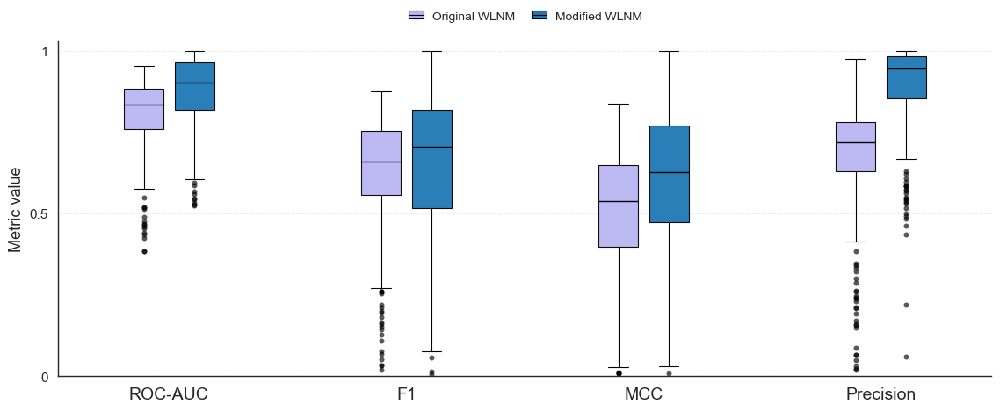

In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.legend_handler import HandlerBase


sns.set_theme(
    context="paper",
    style="white",
    font_scale=1.1,
)




# ============================================================
# Raw predictive inputs (no Tukey filtering)
# ============================================================

import re


def _raw_foodweb_name(path):
    return re.sub(
        r"_tax_mass_results_random_wlnm_.*$",
        "",
        path.stem,
        flags=re.I,
    )


def load_raw_predictive_compat(
    result_root,
    expected_version,
    metric_specs,
    expected_runs,
    minimum_retained_runs,
    *,
    train_ratios=None,
    cvk_values=None,
    k_target=10,
    threshold=0.50,
    kfold=False,
    scenario=None,
):
    """Return raw web-level means in the legacy plotting schema.

    The legacy column names are retained only so that the original plotting,
    layout, scale, colour and export code remains byte-for-byte unchanged.
    MeanAfterTukey below is a compatibility alias for the arithmetic mean of
    every complete raw run unit; no Tukey fences or outlier exclusions occur.
    """
    metrics = [metric for metric, _ in metric_specs]
    labels = dict(metric_specs)
    files = sorted((result_root / "prediction_scores_logs").glob("*.csv"))
    if not files:
        raise FileNotFoundError(result_root / "prediction_scores_logs")

    required = {
        "Version",
        "TrainRatio",
        "ExperimentID",
        "Seed",
        "Threshold",
        "K",
        "CvK",
        "FoldID",
        "EmpiricalConnectance",
        *metrics,
    }
    frames = []
    for path in files:
        frame = pd.read_csv(
            path,
            usecols=lambda column: column in required,
        )
        missing = required.difference(frame.columns)
        if missing:
            raise ValueError(
                f"{path.name}: missing raw columns {sorted(missing)}"
            )
        frame["Foodweb"] = _raw_foodweb_name(path)
        frames.append(frame)

    raw = pd.concat(frames, ignore_index=True)
    for column in required.difference({"Version"}):
        raw[column] = pd.to_numeric(raw[column], errors="coerce")
    raw["TrainRatio"] = np.where(
        raw["TrainRatio"].abs().le(1.0),
        raw["TrainRatio"] * 100.0,
        raw["TrainRatio"],
    )
    raw = raw.loc[
        raw["Version"].eq(expected_version)
        & np.isclose(raw["Threshold"], threshold, atol=1e-9)
        & np.isclose(raw["K"], k_target, atol=1e-9)
    ].copy()
    if train_ratios is not None:
        requested = np.asarray(list(train_ratios), dtype=float)
        raw = raw.loc[
            raw["TrainRatio"].map(
                lambda value: np.isclose(
                    value,
                    requested,
                    atol=1e-8,
                ).any()
            )
        ].copy()
    if cvk_values is not None:
        raw = raw.loc[raw["CvK"].isin(cvk_values)].copy()
    if raw.empty:
        raise ValueError(f"No raw observations selected from {result_root}")

    metric_values = raw[metrics].to_numpy(float)
    if not np.isfinite(metric_values).all():
        raise ValueError(f"Non-finite raw predictive values in {result_root}")
    probability_metrics = [
        metric for metric in metrics if metric not in {"TestMCC", "TestTSS"}
    ]
    signed_metrics = [
        metric for metric in metrics if metric in {"TestMCC", "TestTSS"}
    ]
    if probability_metrics:
        values = raw[probability_metrics].to_numpy(float)
        if ((values < 0) | (values > 1)).any():
            raise ValueError("Raw probability metrics must be within [0, 1]")
    if signed_metrics:
        values = raw[signed_metrics].to_numpy(float)
        if ((values < -1) | (values > 1)).any():
            raise ValueError("Raw MCC/TSS values must be within [-1, 1]")

    group_columns = [
        "Foodweb",
        "Version",
        "TrainRatio",
        "Threshold",
        "K",
        "CvK",
    ]
    if kfold:
        experiment_columns = [*group_columns, "ExperimentID"]
        fold_check = (
            raw.groupby(experiment_columns, dropna=False)
            .agg(
                FoldRows=("FoldID", "size"),
                UniqueFolds=("FoldID", "nunique"),
            )
            .reset_index()
        )
        incomplete = fold_check.loc[
            ~fold_check["FoldRows"].eq(fold_check["CvK"])
            | ~fold_check["UniqueFolds"].eq(fold_check["CvK"])
        ]
        if not incomplete.empty:
            raise ValueError(
                "Incomplete repeated-CV experiments found:\n"
                + incomplete.head(10).to_string(index=False)
            )
        run_units = (
            raw.groupby(
                experiment_columns,
                dropna=False,
                as_index=False,
            )
            .agg(
                **{
                    metric: (metric, "mean")
                    for metric in metrics
                },
                EmpiricalConnectance=(
                    "EmpiricalConnectance",
                    "first",
                ),
            )
        )
    else:
        experiment_columns = [*group_columns, "ExperimentID"]
        if raw.duplicated(experiment_columns).any():
            raise ValueError(f"Duplicate raw ExperimentID rows in {result_root}")
        run_units = raw

    counts = run_units.groupby(group_columns, dropna=False).size()
    if not counts.eq(expected_runs).all():
        raise ValueError(
            f"{result_root.name}: expected {expected_runs} complete raw "
            "run units per group; observed "
            f"{counts.value_counts().to_dict()}"
        )

    wide = (
        run_units.groupby(
            group_columns,
            dropna=False,
            as_index=False,
        )
        .agg(
            **{
                metric: (metric, "mean")
                for metric in metrics
            },
            EmpiricalConnectance=(
                "EmpiricalConnectance",
                "first",
            ),
            RawRunUnits=("ExperimentID", "size"),
        )
    )
    long = wide.melt(
        id_vars=[
            *group_columns,
            "EmpiricalConnectance",
            "RawRunUnits",
        ],
        value_vars=metrics,
        var_name="Metric",
        value_name="MeanAfterTukey",
    )
    long["Scenario"] = scenario or result_root.name
    long["MetricLabel"] = long["Metric"].map(labels)
    long["MetricFamily"] = "predictive"
    long["SourceColumn"] = long["Metric"]
    long["ReferenceColumn"] = ""
    long["MeanBeforeTukey"] = long["MeanAfterTukey"]
    long["TotalRunUnits"] = long["RawRunUnits"]
    long["ValidRunsBeforeTukey"] = long["RawRunUnits"]
    long["InvalidRunsBeforeTukey"] = 0
    long["OutlierRunsExcluded"] = 0
    long["RetainedRunsAfterTukey"] = long["RawRunUnits"]
    long["ExpectedRuns"] = expected_runs
    long["MinimumRetainedRuns"] = minimum_retained_runs
    long["MeetsMinimumRetainedRuns"] = 1
    long["ReferenceValue"] = long["EmpiricalConnectance"]
    return long

# ============================================================
# Locate repository root
# ============================================================

def find_repo_root(start=Path.cwd()):
    start = Path(start).resolve()

    candidates = [start, *start.parents]

    # Fallback for notebooks launched outside the repository.
    fallback = Path(
        "/Users/acw792/Developer/qmul-phd-framework"
    )

    if fallback not in candidates:
        candidates.append(fallback)

    for candidate in candidates:
        if (
            (candidate / "src/matlab").is_dir()
            and (candidate / "docs").is_dir()
        ):
            return candidate

    raise RuntimeError(
        "Could not locate the qmul-phd-framework repository."
    )


REPO_ROOT = find_repo_root()


# ============================================================
# Final configuration
# ============================================================

TRAIN_RATIO_TARGET = 90
CLASSIFICATION_THRESHOLD = 0.50
NODES_THRESHOLD = 0

# Tukey is applied across 50 runs.
# At least 50% must remain: ceil(50 × 0.5) = 25 runs.
EXPECTED_RUNS = 50
MINIMUM_RETAINED_FRACTION = 1.00
MINIMUM_RETAINED_RUNS = 50

ELIGIBILITY_MODE = "role_only"
MASS_ELIGIBILITY_ENABLED = False
CHECK_CONNECTIVITY = False
ADAPTIVE_CONNECTIVITY = False

PROTOCOL_NAME = (
    "tukey_iqr_1p5_min50pct_threshold0p50_v1"
)

assert MINIMUM_RETAINED_RUNS == int(
    np.ceil(
        EXPECTED_RUNS
        * MINIMUM_RETAINED_FRACTION
    )
)


# ============================================================
# Result roots
# ============================================================

ORIGINAL_ROOT = (
    REPO_ROOT
    / "src/matlab/data"
    / (
        "result_wlnm_original_50x290_train90_thresh0p50_"
        "legacy_uppertriangular_checkconnfalse_adaptivefalse_Apocrita"
    )
)

DIR_NEG_ROOT = (
    REPO_ROOT
    / "src/matlab/data"
    / (
        "result_wlnm_dir_neg_sweep_train_ratios_"
        "10-90_pseudo_properties_Apocrita_neg_const"
    )
)


# ============================================================
# Raw prediction inputs
# ============================================================

ORIGINAL_INPUT = ORIGINAL_ROOT
DIR_NEG_INPUT = DIR_NEG_ROOT

FOODWEB_CSV = (
    REPO_ROOT
    / "src/matlab/data/foodwebs_mat"
    / "foodweb_metrics_ecosystem.csv"
)

# ============================================================
# Publication output
# ============================================================

OUT_DIR = DIR_NEG_ROOT / "figures_raw_unfiltered"

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

OUTPUT_STEM = "figure_3_original_vs_extended_wlnm_four_metrics_train90_raw_unfiltered"

PNG_PATH = OUT_DIR / f"{OUTPUT_STEM}.png"
SVG_PATH = OUT_DIR / f"{OUTPUT_STEM}.svg"
PDF_PATH = OUT_DIR / f"{OUTPUT_STEM}.pdf"

SUMMARY_PATH = (
    OUT_DIR
    / f"{OUTPUT_STEM}_summary.csv"
)

RETENTION_PATH = (
    OUT_DIR
    / f"{OUTPUT_STEM}_raw_run_counts.csv"
)


# ============================================================
# Metrics
# ============================================================

METRIC_SPECS = [
    ("ROC_AUC", "ROC-AUC"),
    ("F1Score", "F1"),
    ("TestMCC", "MCC"),
    ("Precision", "Precision"),
]

METRIC_ORDER = [
    metric
    for metric, _ in METRIC_SPECS
]

METRIC_LABELS = dict(METRIC_SPECS)

VERSION_ORDER = [
    "original",
    "dir_neg",
]

VERSION_LABELS = {
    "original": "Original WLNM",
    "dir_neg": "Modified WLNM",
}

VERSION_PALETTE = {
    "original": "#BAB6F2",
    "dir_neg": "#1F78B4",
}

SHOW_WEB_LEVEL_FLIERS = True


# ============================================================
# Validate required raw inputs
# ============================================================

required_inputs = {
    "Original WLNM raw result root": ORIGINAL_INPUT,
    "Directed-negative WLNM raw result root": DIR_NEG_INPUT,
    "Food-web metadata": FOODWEB_CSV,
}

missing_inputs = [
    f"{label}:\n  {path}"
    for label, path in required_inputs.items()
    if not (
        path.is_file()
        if path == FOODWEB_CSV
        else (path / "prediction_scores_logs").is_dir()
    )
]
if missing_inputs:
    raise FileNotFoundError("\n\n".join(missing_inputs))

print(f"[INFO] Repository: {REPO_ROOT}")
print("[INFO] Using raw prediction inputs; no Tukey filtering.")

# ============================================================
# Helpers
# ============================================================

def normalize_fw_label(name):
    name = str(name).strip()

    for suffix in [
        ".mat",
        ".csv",
    ]:
        if name.endswith(suffix):
            name = name[: -len(suffix)]

    name = name.replace(" ", "_")

    for token in [
        "_results_",
        "_result_",
        "_results",
        "_random",
        "_tax_mass",
        "_tax",
        "_mass",
    ]:
        name = name.replace(token, "_")

    return "_".join(
        part
        for part in name.split("_")
        if part
    ).lower()


def load_raw_figure_input(path, version):
    expected_version = {
        "original": "WLNM_original",
        "dir_neg": "WLNM_dir_neg",
    }[version]
    df = load_raw_predictive_compat(
        path,
        expected_version,
        METRIC_SPECS,
        EXPECTED_RUNS,
        EXPECTED_RUNS,
        train_ratios=[TRAIN_RATIO_TARGET],
    )
    df["Version"] = version
    df["Value"] = df["MeanAfterTukey"]
    df["FW_KEY"] = df["Foodweb"].apply(normalize_fw_label)
    if df.duplicated(["FW_KEY", "Version", "Metric"]).any():
        raise ValueError(f"Duplicated raw foodweb-metric rows in {path}")
    print(
        f"[INFO] {version}: all "
        f"{int(df['RetainedRunsAfterTukey'].min())} raw run units used."
    )
    return df

# ============================================================
# Load raw unfiltered values
# ============================================================

original_df = load_raw_figure_input(
    ORIGINAL_INPUT,
    version="original",
)

dir_neg_df = load_raw_figure_input(
    DIR_NEG_INPUT,
    version="dir_neg",
)

combined_df = pd.concat(
    [
        original_df,
        dir_neg_df,
    ],
    ignore_index=True,
)


# ============================================================
# Apply node-count filter
# ============================================================

metadata_df = pd.read_csv(
    FOODWEB_CSV
)

metadata_df.columns = [
    column.strip()
    for column in metadata_df.columns
]

foodweb_column = next(
    (
        column
        for column in metadata_df.columns
        if column.lower() == "foodweb"
    ),
    None,
)

nodes_column = next(
    (
        column
        for column in metadata_df.columns
        if column.lower() in {
            "nodes",
            "n_nodes",
            "num_nodes",
            "nodecount",
            "s",
        }
    ),
    None,
)

if (
    foodweb_column is None
    or nodes_column is None
):
    raise ValueError(
        "Could not identify Foodweb and Nodes "
        "columns in the metadata file."
    )

metadata_df[nodes_column] = pd.to_numeric(
    metadata_df[nodes_column],
    errors="coerce",
)

metadata_df["FW_KEY"] = (
    metadata_df[foodweb_column]
    .apply(normalize_fw_label)
)

metadata_df = (
    metadata_df[
        [
            "FW_KEY",
            foodweb_column,
            nodes_column,
        ]
    ]
    .drop_duplicates(
        subset=["FW_KEY"]
    )
)

allowed_fw_keys = set(
    metadata_df.loc[
        metadata_df[nodes_column]
        >= NODES_THRESHOLD,
        "FW_KEY",
    ]
)

print(
    f"[INFO] Food webs satisfying "
    f"Nodes >= {NODES_THRESHOLD}: "
    f"{len(allowed_fw_keys)}"
)

combined_df = combined_df[
    combined_df["FW_KEY"]
    .isin(allowed_fw_keys)
].copy()

if combined_df.empty:
    raise RuntimeError(
        "No retained food-web metrics remain "
        "after the node-count filter."
    )


# ============================================================
# Enforce paired food webs separately per metric
# ============================================================

paired_frames = []
pairing_rows = []

for metric in METRIC_ORDER:
    metric_df = combined_df[
        combined_df["Metric"].eq(metric)
    ].copy()

    original_keys = set(
        metric_df.loc[
            metric_df["Version"].eq("original"),
            "FW_KEY",
        ]
    )

    dir_neg_keys = set(
        metric_df.loc[
            metric_df["Version"].eq("dir_neg"),
            "FW_KEY",
        ]
    )

    common_keys = (
        original_keys
        .intersection(dir_neg_keys)
    )

    pairing_rows.append(
        {
            "Metric": METRIC_LABELS[metric],
            "Original retained food webs": len(
                original_keys
            ),
            "Directed-negative retained food webs": len(
                dir_neg_keys
            ),
            "Paired food webs": len(
                common_keys
            ),
            "Original-only food webs": len(
                original_keys
                - dir_neg_keys
            ),
            "Directed-negative-only food webs": len(
                dir_neg_keys
                - original_keys
            ),
        }
    )

    paired_metric_df = metric_df[
        metric_df["FW_KEY"].isin(
            common_keys
        )
    ].copy()

    paired_frames.append(
        paired_metric_df
    )

plot_df = pd.concat(
    paired_frames,
    ignore_index=True,
)

if plot_df.empty:
    raise RuntimeError(
        "No paired food webs remain for plotting."
    )

pairing_table = pd.DataFrame(
    pairing_rows
)

print(
    "\n=== Retained and paired food webs "
    "by metric ==="
)

display(pairing_table)


# ============================================================
# Retention details
# ============================================================

retention_table = (
    plot_df
    .groupby(
        [
            "Version",
            "Metric",
        ],
        as_index=False,
    )
    .agg(
        FoodWebs=(
            "FW_KEY",
            "nunique",
        ),
        MinimumRetainedRuns=(
            "RetainedRunsAfterTukey",
            "min",
        ),
        MedianRetainedRuns=(
            "RetainedRunsAfterTukey",
            "median",
        ),
        MaximumRetainedRuns=(
            "RetainedRunsAfterTukey",
            "max",
        ),
    )
)

retention_table["Version"] = (
    retention_table["Version"]
    .map(VERSION_LABELS)
)

retention_table["Metric"] = (
    retention_table["Metric"]
    .map(METRIC_LABELS)
)

retention_table = retention_table[
    [
        "Version",
        "Metric",
        "FoodWebs",
        "MinimumRetainedRuns",
        "MedianRetainedRuns",
        "MaximumRetainedRuns",
    ]
]

print(
    "\n=== Raw run-count details "
    "for paired food webs ==="
)

display(retention_table)


# ============================================================
# Web-level summary
# ============================================================

summary_table = (
    plot_df
    .groupby(
        [
            "Version",
            "Metric",
        ],
        as_index=False,
    )
    .agg(
        FoodWebs=(
            "FW_KEY",
            "nunique",
        ),
        Mean=(
            "Value",
            "mean",
        ),
        Median=(
            "Value",
            "median",
        ),
        SD=(
            "Value",
            "std",
        ),
        Variance=(
            "Value",
            "var",
        ),
    )
)

summary_table["Version"] = (
    summary_table["Version"]
    .map(VERSION_LABELS)
)

summary_table["Metric"] = (
    summary_table["Metric"]
    .map(METRIC_LABELS)
)

for column in [
    "Mean",
    "Median",
    "SD",
    "Variance",
]:
    summary_table[column] = (
        summary_table[column]
        .round(4)
    )

print(
    "\n=== Raw-unfiltered web-level "
    "predictive metric summary ==="
)

display(summary_table)


# ============================================================
# Custom miniature boxplot legend
# ============================================================

class HandlerMiniBoxplot(HandlerBase):
    def create_artists(
        self,
        legend,
        orig_handle,
        xdescent,
        ydescent,
        width,
        height,
        fontsize,
        trans,
    ):
        facecolor = orig_handle["facecolor"]

        edgecolor = orig_handle.get(
            "edgecolor",
            "black",
        )

        linewidth = orig_handle.get(
            "linewidth",
            0.6,
        )

        center_x = (
            xdescent
            + 0.5 * width
        )

        center_y = (
            ydescent
            + 0.44 * height
        )

        box_width = (
            0.8 * width
        )

        box_height = (
            0.8 * height
        )

        box_x = (
            center_x
            - box_width / 2
        )

        box_y = (
            center_y
            - box_height / 2
        )

        whisker_top_y = (
            box_y
            + box_height
            + 0.18 * height
        )

        whisker_bottom_y = (
            box_y
            - 0.18 * height
        )

        box = Rectangle(
            (
                box_x,
                box_y,
            ),
            box_width,
            box_height,
            facecolor=facecolor,
            edgecolor=edgecolor,
            linewidth=linewidth,
            transform=trans,
        )

        median = Line2D(
            [
                box_x,
                box_x + box_width,
            ],
            [
                center_y,
                center_y,
            ],
            color=edgecolor,
            linewidth=linewidth,
            transform=trans,
        )

        upper_whisker = Line2D(
            [
                center_x,
                center_x,
            ],
            [
                box_y + box_height,
                whisker_top_y,
            ],
            color=edgecolor,
            linewidth=linewidth,
            transform=trans,
        )

        lower_whisker = Line2D(
            [
                center_x,
                center_x,
            ],
            [
                whisker_bottom_y,
                box_y,
            ],
            color=edgecolor,
            linewidth=linewidth,
            transform=trans,
        )

        return [
            box,
            median,
            upper_whisker,
            lower_whisker,
        ]


# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(
    figsize=(11.5, 4.8)
)

group_gap = 1.5

group_centers = (
    1.0
    + np.arange(
        len(METRIC_SPECS)
    )
    * group_gap
)

offsets = {
    "original": -0.16,
    "dir_neg": 0.16,
}

box_width = 0.25

for version in VERSION_ORDER:
    version_data = []
    version_positions = []

    for metric_index, (
        metric,
        metric_label,
    ) in enumerate(METRIC_SPECS):
        values = (
            plot_df.loc[
                (
                    plot_df["Version"].eq(
                        version
                    )
                )
                & (
                    plot_df["Metric"].eq(
                        metric
                    )
                ),
                "Value",
            ]
            .dropna()
            .to_numpy()
        )

        if len(values) == 0:
            continue

        version_data.append(
            values
        )

        version_positions.append(
            group_centers[metric_index]
            + offsets[version]
        )

    if not version_data:
        raise RuntimeError(
            f"No plotting values found for version: {version}"
        )

    ax.boxplot(
        version_data,
        positions=version_positions,
        widths=box_width,
        patch_artist=True,
        manage_ticks=False,
        showfliers=SHOW_WEB_LEVEL_FLIERS,
        boxprops={
            "facecolor": VERSION_PALETTE[version],
            "edgecolor": "black",
            "linewidth": 0.8,
            "alpha": 0.95,
        },
        medianprops={
            "color": "black",
            "linewidth": 1.0,
        },
        whiskerprops={
            "color": "black",
            "linewidth": 0.8,
        },
        capprops={
            "color": "black",
            "linewidth": 0.8,
        },
        flierprops={
            "marker": "o",
            "markersize": 4,
            "markerfacecolor": "black",
            "markeredgecolor": "black",
            "markeredgewidth": 0.2,
            "alpha": 0.65,
        },
    )


# ============================================================
# Axes and legend
# ============================================================

legend_handles = [
    {
        "facecolor": VERSION_PALETTE[version],
        "edgecolor": "black",
        "linewidth": 0.8,
    }
    for version in VERSION_ORDER
]

ax.set_xlim(
    group_centers[0] - 0.7,
    group_centers[-1] + 0.7,
)

ax.set_ylim(
    0,
    1.03,
)

ax.set_xticks(
    group_centers,
    labels=[
        metric_label
        for _, metric_label in METRIC_SPECS
    ],
)

plt.setp(
    ax.get_xticklabels(),
    rotation=0,
    fontsize=14,
)

ax.set_ylabel(
    "Metric value",
    fontsize=13,
)

ax.set_xlabel("")

ax.set_yticks(
    [
        0,
        0.5,
        1.0,
    ]
)

ax.set_yticklabels(
    [
        "0",
        "0.5",
        "1",
    ]
)

ax.tick_params(
    axis="y",
    labelsize=11,
)

ax.grid(
    True,
    axis="y",
    linestyle="--",
    alpha=0.35,
)

ax.legend(
    handles=legend_handles,
    labels=[
        VERSION_LABELS[version]
        for version in VERSION_ORDER
    ],
    handler_map={
        dict: HandlerMiniBoxplot()
    },
    loc="lower center",
    bbox_to_anchor=(
        0.5,
        1.03,
    ),
    ncol=len(VERSION_ORDER),
    frameon=False,
    fontsize=10,
    handlelength=1.5,
    handleheight=0.9,
    handletextpad=0.6,
    borderpad=0.2,
    labelspacing=0.45,
    columnspacing=1.2,
)

sns.despine(
    ax=ax
)

plt.tight_layout()


# ============================================================
# Export
# ============================================================

fig.savefig(
    PNG_PATH,
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    SVG_PATH,
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    PDF_PATH,
    bbox_inches="tight",
    facecolor="white",
)

summary_table.to_csv(
    SUMMARY_PATH,
    index=False,
)

retention_table.to_csv(
    RETENTION_PATH,
    index=False,
)

print(
    "\n[INFO] Saved publication-ready outputs:"
)

print(f"  PNG: {PNG_PATH}")
print(f"  SVG: {SVG_PATH}")
print(f"  PDF: {PDF_PATH}")
print(f"  Summary: {SUMMARY_PATH}")
print(f"  Raw run counts: {RETENTION_PATH}")

print(
    "\n[INFO] Final directed configuration:"
)

print(
    f"  check_connectivity={CHECK_CONNECTIVITY}"
)

print(
    f"  adaptive_connectivity={ADAPTIVE_CONNECTIVITY}"
)

print(
    f"  classification_threshold="
    f"{CLASSIFICATION_THRESHOLD}"
)

print(
    "  aggregation=all raw runs; no Tukey filtering"
)

print(
    f"  minimum_retained_runs="
    f"{MINIMUM_RETAINED_RUNS}/{EXPECTED_RUNS}"
)

plt.show()

[INFO] Repository: /Users/acw792/Developer/qmul-phd-framework
[INFO] Using raw prediction inputs; no Tukey filtering.
[INFO] original: all 100 raw run units used.
[INFO] dir_neg: all 100 raw run units used.
[INFO] Food webs satisfying Nodes >= 0: 290

=== Retained and paired food webs by metric ===


,Metric,Original retained food webs,Directed-negative retained food webs,Paired food webs,Original-only food webs,Directed-negative-only food webs
0,ROC-AUC,290,290,290,0,0
1,F1,290,290,290,0,0
2,MCC,290,290,290,0,0
3,Precision,290,290,290,0,0


[INFO] Validated unique FW_KEY × Version × Metric observations.

=== Raw run-count details for paired food webs ===


,Version,Metric,FoodWebs,MinimumRetainedRuns,MedianRetainedRuns,MaximumRetainedRuns
0,Modified WLNM,F1,290,100,100.0,100
1,Modified WLNM,Precision,290,100,100.0,100
2,Modified WLNM,ROC-AUC,290,100,100.0,100
3,Modified WLNM,MCC,290,100,100.0,100
4,Original WLNM,F1,290,100,100.0,100
5,Original WLNM,Precision,290,100,100.0,100
6,Original WLNM,ROC-AUC,290,100,100.0,100
7,Original WLNM,MCC,290,100,100.0,100



=== Raw-unfiltered web-level predictive metric summary ===


,Version,Metric,FoodWebs,Mean,Median,SD,Variance
0,Modified WLNM,F1,290,0.6686,0.7201,0.2211,0.0489
1,Modified WLNM,Precision,290,0.9233,0.9507,0.1071,0.0115
2,Modified WLNM,ROC-AUC,290,0.8893,0.9102,0.0977,0.0095
3,Modified WLNM,MCC,290,0.6381,0.6620,0.2044,0.0418
4,Original WLNM,F1,290,0.6203,0.6591,0.1733,0.0300
5,Original WLNM,Precision,290,0.6708,0.7180,0.1775,0.0315
6,Original WLNM,ROC-AUC,290,0.8031,0.8306,0.1086,0.0118
7,Original WLNM,MCC,290,0.4961,0.5378,0.1901,0.0361


[INFO] Ecosystem metadata validated: 290 unique FW_KEY values.

[INFO] Precision observations before ecosystem merge:
  Original WLNM: 290 paired food webs
  Modified WLNM: 290 paired food webs
[INFO] Precision pairing validated within every ecosystem.

=== Precision by ecosystem and version ===


,Ecosystem,Version,FoodWebs,Median,Q1,Q3,Minimum,Maximum
0,Lakes,Original WLNM,55,0.7272,0.6820,0.7596,0.2183,0.8976
1,Lakes,Modified WLNM,55,0.9852,0.9507,0.9936,0.5450,1.0000
2,Streams,Original WLNM,28,0.6691,0.6309,0.7024,0.4941,0.8075
3,Streams,Modified WLNM,28,0.9852,0.9711,0.9910,0.0700,1.0000
4,Marine,Original WLNM,134,0.7006,0.6236,0.7742,0.0150,0.9580
5,Marine,Modified WLNM,134,0.9507,0.9097,0.9759,0.4850,1.0000
6,Terrestrial aboveground,Original WLNM,21,0.5672,0.2653,0.5922,0.0383,0.6121
7,Terrestrial aboveground,Modified WLNM,21,0.9193,0.8519,0.9906,0.7743,0.9972
8,Terrestrial belowground,Original WLNM,52,0.7844,0.7659,0.7965,0.6695,0.8424
9,Terrestrial belowground,Modified WLNM,52,0.9227,0.9154,0.9330,0.8957,0.9841



[INFO] Saved publication-ready outputs:
  PNG: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/figures_raw_unfiltered/figure_3_original_vs_modified_wlnm_four_metrics_and_precision_by_ecosystem_raw_unfiltered.png
  SVG: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/figures_raw_unfiltered/figure_3_original_vs_modified_wlnm_four_metrics_and_precision_by_ecosystem_raw_unfiltered.svg
  PDF: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/figures_raw_unfiltered/figure_3_original_vs_modified_wlnm_four_metrics_and_precision_by_ecosystem_raw_unfiltered.pdf
  Summary: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/figures_

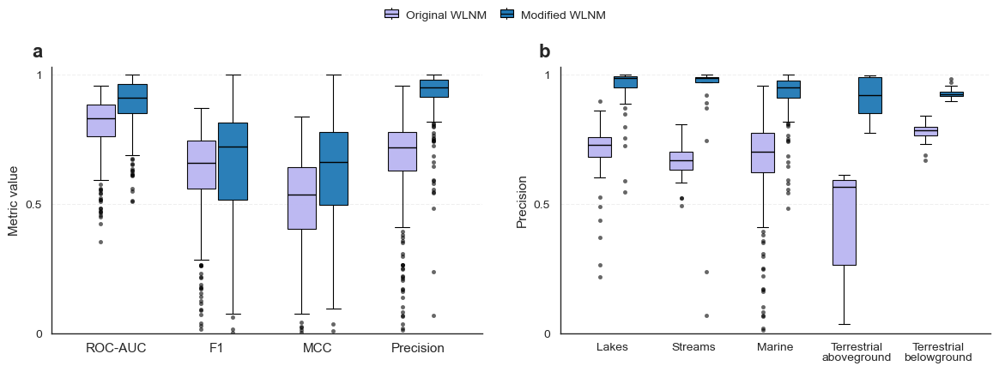

In [5]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.legend_handler import HandlerBase


sns.set_theme(
    context="paper",
    style="white",
    font_scale=1.1,
)




# ============================================================
# Raw predictive inputs (no Tukey filtering)
# ============================================================

import re


def _raw_foodweb_name(path):
    return re.sub(
        r"_tax_mass_results_random_wlnm_.*$",
        "",
        path.stem,
        flags=re.I,
    )


def load_raw_predictive_compat(
    result_root,
    expected_version,
    metric_specs,
    expected_runs,
    minimum_retained_runs,
    *,
    train_ratios=None,
    cvk_values=None,
    k_target=10,
    threshold=0.50,
    kfold=False,
    scenario=None,
):
    """Return raw web-level means in the legacy plotting schema.

    The legacy column names are retained only so that the original plotting,
    layout, scale, colour and export code remains byte-for-byte unchanged.
    MeanAfterTukey below is a compatibility alias for the arithmetic mean of
    every complete raw run unit; no Tukey fences or outlier exclusions occur.
    """
    metrics = [metric for metric, _ in metric_specs]
    labels = dict(metric_specs)
    files = sorted((result_root / "prediction_scores_logs").glob("*.csv"))
    if not files:
        raise FileNotFoundError(result_root / "prediction_scores_logs")

    required = {
        "Version",
        "TrainRatio",
        "ExperimentID",
        "Seed",
        "Threshold",
        "K",
        "CvK",
        "FoldID",
        "EmpiricalConnectance",
        *metrics,
    }
    frames = []
    for path in files:
        frame = pd.read_csv(
            path,
            usecols=lambda column: column in required,
        )
        missing = required.difference(frame.columns)
        if missing:
            raise ValueError(
                f"{path.name}: missing raw columns {sorted(missing)}"
            )
        frame["Foodweb"] = _raw_foodweb_name(path)
        frames.append(frame)

    raw = pd.concat(frames, ignore_index=True)
    for column in required.difference({"Version"}):
        raw[column] = pd.to_numeric(raw[column], errors="coerce")
    raw["TrainRatio"] = np.where(
        raw["TrainRatio"].abs().le(1.0),
        raw["TrainRatio"] * 100.0,
        raw["TrainRatio"],
    )
    raw = raw.loc[
        raw["Version"].eq(expected_version)
        & np.isclose(raw["Threshold"], threshold, atol=1e-9)
        & np.isclose(raw["K"], k_target, atol=1e-9)
    ].copy()
    if train_ratios is not None:
        requested = np.asarray(list(train_ratios), dtype=float)
        raw = raw.loc[
            raw["TrainRatio"].map(
                lambda value: np.isclose(
                    value,
                    requested,
                    atol=1e-8,
                ).any()
            )
        ].copy()
    if cvk_values is not None:
        raw = raw.loc[raw["CvK"].isin(cvk_values)].copy()
    if raw.empty:
        raise ValueError(f"No raw observations selected from {result_root}")

    metric_values = raw[metrics].to_numpy(float)
    if not np.isfinite(metric_values).all():
        raise ValueError(f"Non-finite raw predictive values in {result_root}")
    probability_metrics = [
        metric for metric in metrics if metric not in {"TestMCC", "TestTSS"}
    ]
    signed_metrics = [
        metric for metric in metrics if metric in {"TestMCC", "TestTSS"}
    ]
    if probability_metrics:
        values = raw[probability_metrics].to_numpy(float)
        if ((values < 0) | (values > 1)).any():
            raise ValueError("Raw probability metrics must be within [0, 1]")
    if signed_metrics:
        values = raw[signed_metrics].to_numpy(float)
        if ((values < -1) | (values > 1)).any():
            raise ValueError("Raw MCC/TSS values must be within [-1, 1]")

    group_columns = [
        "Foodweb",
        "Version",
        "TrainRatio",
        "Threshold",
        "K",
        "CvK",
    ]
    if kfold:
        experiment_columns = [*group_columns, "ExperimentID"]
        fold_check = (
            raw.groupby(experiment_columns, dropna=False)
            .agg(
                FoldRows=("FoldID", "size"),
                UniqueFolds=("FoldID", "nunique"),
            )
            .reset_index()
        )
        incomplete = fold_check.loc[
            ~fold_check["FoldRows"].eq(fold_check["CvK"])
            | ~fold_check["UniqueFolds"].eq(fold_check["CvK"])
        ]
        if not incomplete.empty:
            raise ValueError(
                "Incomplete repeated-CV experiments found:\n"
                + incomplete.head(10).to_string(index=False)
            )
        run_units = (
            raw.groupby(
                experiment_columns,
                dropna=False,
                as_index=False,
            )
            .agg(
                **{
                    metric: (metric, "mean")
                    for metric in metrics
                },
                EmpiricalConnectance=(
                    "EmpiricalConnectance",
                    "first",
                ),
            )
        )
    else:
        experiment_columns = [*group_columns, "ExperimentID"]
        if raw.duplicated(experiment_columns).any():
            raise ValueError(f"Duplicate raw ExperimentID rows in {result_root}")
        run_units = raw

    counts = run_units.groupby(group_columns, dropna=False).size()
    if not counts.eq(expected_runs).all():
        raise ValueError(
            f"{result_root.name}: expected {expected_runs} complete raw "
            "run units per group; observed "
            f"{counts.value_counts().to_dict()}"
        )

    wide = (
        run_units.groupby(
            group_columns,
            dropna=False,
            as_index=False,
        )
        .agg(
            **{
                metric: (metric, "mean")
                for metric in metrics
            },
            EmpiricalConnectance=(
                "EmpiricalConnectance",
                "first",
            ),
            RawRunUnits=("ExperimentID", "size"),
        )
    )
    long = wide.melt(
        id_vars=[
            *group_columns,
            "EmpiricalConnectance",
            "RawRunUnits",
        ],
        value_vars=metrics,
        var_name="Metric",
        value_name="MeanAfterTukey",
    )
    long["Scenario"] = scenario or result_root.name
    long["MetricLabel"] = long["Metric"].map(labels)
    long["MetricFamily"] = "predictive"
    long["SourceColumn"] = long["Metric"]
    long["ReferenceColumn"] = ""
    long["MeanBeforeTukey"] = long["MeanAfterTukey"]
    long["TotalRunUnits"] = long["RawRunUnits"]
    long["ValidRunsBeforeTukey"] = long["RawRunUnits"]
    long["InvalidRunsBeforeTukey"] = 0
    long["OutlierRunsExcluded"] = 0
    long["RetainedRunsAfterTukey"] = long["RawRunUnits"]
    long["ExpectedRuns"] = expected_runs
    long["MinimumRetainedRuns"] = minimum_retained_runs
    long["MeetsMinimumRetainedRuns"] = 1
    long["ReferenceValue"] = long["EmpiricalConnectance"]
    return long

# ============================================================
# Locate repository root
# ============================================================

def find_repo_root(start=Path.cwd()):
    start = Path(start).resolve()

    candidates = [
        start,
        *start.parents,
    ]

    # Fallback for notebooks launched outside the repository.
    fallback = Path(
        "/Users/acw792/Developer/qmul-phd-framework"
    )

    if fallback not in candidates:
        candidates.append(fallback)

    for candidate in candidates:
        if (
            (candidate / "src/matlab").is_dir()
            and (candidate / "docs").is_dir()
        ):
            return candidate

    raise RuntimeError(
        "Could not locate the qmul-phd-framework repository."
    )


REPO_ROOT = find_repo_root()


# ============================================================
# Final configuration
# ============================================================

TRAIN_RATIO_TARGET = 90
CLASSIFICATION_THRESHOLD = 0.50
NODES_THRESHOLD = 0

# Tukey is applied across 100 runs.
# At least 25% must remain: ceil(100 × 0.25) = 25 runs.
EXPECTED_RUNS = 100
MINIMUM_RETAINED_FRACTION = 1.00
MINIMUM_RETAINED_RUNS = 100

ELIGIBILITY_MODE = "role_only"
MASS_ELIGIBILITY_ENABLED = False
CHECK_CONNECTIVITY = False
ADAPTIVE_CONNECTIVITY = False

PROTOCOL_NAME = (
    "tukey_iqr_1p5_min25runs_threshold0p50_v1"
)

assert MINIMUM_RETAINED_RUNS == int(
    np.ceil(
        EXPECTED_RUNS
        * MINIMUM_RETAINED_FRACTION
    )
)


# ============================================================
# Result roots
# ============================================================

ORIGINAL_ROOT = (
    REPO_ROOT
    / "src/matlab/data"
    / (
        "result_wlnm_original_100x290_train10-90_thresh0p50_"
        "Apocrita_20260916_221905"
    )
)

DIR_NEG_ROOT = (
    REPO_ROOT
    / "src/matlab/data"
    / (
        "result_wlnm_dir_neg_roleonly_trophicv2_"
        "100x290_train10-90_Apocrita_20260910_011848"
    )
)


# ============================================================
# Raw prediction inputs
# ============================================================

ORIGINAL_INPUT = ORIGINAL_ROOT
DIR_NEG_INPUT = DIR_NEG_ROOT

FOODWEB_CSV = (
    REPO_ROOT
    / "src/matlab/data/foodwebs_mat"
    / "foodweb_metrics_ecosystem.csv"
)

# ============================================================
# Publication output
# ============================================================

OUT_DIR = DIR_NEG_ROOT / "figures_raw_unfiltered"

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

OUTPUT_STEM = "figure_3_original_vs_modified_wlnm_four_metrics_and_precision_by_ecosystem_raw_unfiltered"

PNG_PATH = OUT_DIR / f"{OUTPUT_STEM}.png"
SVG_PATH = OUT_DIR / f"{OUTPUT_STEM}.svg"
PDF_PATH = OUT_DIR / f"{OUTPUT_STEM}.pdf"

SUMMARY_PATH = (
    OUT_DIR
    / f"{OUTPUT_STEM}_summary.csv"
)

RETENTION_PATH = (
    OUT_DIR
    / f"{OUTPUT_STEM}_raw_run_counts.csv"
)


# ============================================================
# Metrics
# ============================================================

METRIC_SPECS = [
    ("ROC_AUC", "ROC-AUC"),
    ("F1Score", "F1"),
    ("TestMCC", "MCC"),
    ("Precision", "Precision"),
]

METRIC_ORDER = [
    metric
    for metric, _ in METRIC_SPECS
]

METRIC_LABELS = dict(
    METRIC_SPECS
)

VERSION_ORDER = [
    "original",
    "dir_neg",
]

VERSION_LABELS = {
    "original": "Original WLNM",
    "dir_neg": "Modified WLNM",
}

VERSION_PALETTE = {
    "original": "#BAB6F2",
    "dir_neg": "#1F78B4",
}

SHOW_WEB_LEVEL_FLIERS = True


# ============================================================
# Ecosystem configuration for panel (b)
# ============================================================

ECOSYSTEM_ORDER = [
    "lakes",
    "streams",
    "marine",
    "terrestrial aboveground",
    "terrestrial belowground",
]

ECOSYSTEM_LABELS = {
    "lakes": "Lakes",
    "streams": "Streams",
    "marine": "Marine",
    "terrestrial aboveground": "Terrestrial\naboveground",
    "terrestrial belowground": "Terrestrial\nbelowground",
}


# ============================================================
# Validate required raw inputs
# ============================================================

required_inputs = {
    "Original WLNM raw result root": ORIGINAL_INPUT,
    "Directed-negative WLNM raw result root": DIR_NEG_INPUT,
    "Food-web metadata": FOODWEB_CSV,
}

missing_inputs = [
    f"{label}:\n  {path}"
    for label, path in required_inputs.items()
    if not (
        path.is_file()
        if path == FOODWEB_CSV
        else (path / "prediction_scores_logs").is_dir()
    )
]
if missing_inputs:
    raise FileNotFoundError("\n\n".join(missing_inputs))

print(f"[INFO] Repository: {REPO_ROOT}")
print("[INFO] Using raw prediction inputs; no Tukey filtering.")

# ============================================================
# Helpers used by original comparison
# ============================================================

def normalize_fw_label(name):
    name = str(name).strip()

    for suffix in [
        ".mat",
        ".csv",
    ]:
        if name.endswith(suffix):
            name = name[:-len(suffix)]

    name = name.replace(
        " ",
        "_",
    )

    for token in [
        "_results_",
        "_result_",
        "_results",
        "_random",
        "_tax_mass",
        "_tax",
        "_mass",
    ]:
        name = name.replace(
            token,
            "_",
        )

    return "_".join(
        part
        for part in name.split("_")
        if part
    ).lower()


# ============================================================
# Ecosystem metadata helpers
# ============================================================

def normalize_colname(value):
    return (
        str(value)
        .strip()
        .lower()
        .replace(" ", "")
        .replace(".", "")
        .replace("-", "")
        .replace("_", "")
    )


def normalize_foodweb(value):
    value = Path(
        str(value).strip()
    ).name

    for extension in (
        ".mat",
        ".csv",
    ):
        if value.lower().endswith(
            extension
        ):
            value = value[
                :-len(extension)
            ].rstrip()

    for suffix in (
        "_tax_mass",
        "_taxmass",
    ):
        if value.lower().endswith(
            suffix
        ):
            value = value[
                :-len(suffix)
            ].rstrip()

    return " ".join(
        value.casefold().split()
    )


def normalize_ecosystem(value):
    return " ".join(
        str(value)
        .strip()
        .casefold()
        .split()
    )


def load_raw_figure_input(path, version):
    expected_version = {
        "original": "WLNM_original",
        "dir_neg": "WLNM_dir_neg",
    }[version]
    df = load_raw_predictive_compat(
        path,
        expected_version,
        METRIC_SPECS,
        EXPECTED_RUNS,
        EXPECTED_RUNS,
        train_ratios=[TRAIN_RATIO_TARGET],
    )
    df["Version"] = version
    df["Value"] = df["MeanAfterTukey"]
    df["FW_KEY"] = df["Foodweb"].apply(normalize_fw_label)
    if df.duplicated(["FW_KEY", "Version", "Metric"]).any():
        raise ValueError(f"Duplicated raw foodweb-metric rows in {path}")
    print(
        f"[INFO] {version}: all "
        f"{int(df['RetainedRunsAfterTukey'].min())} raw run units used."
    )
    return df

# ============================================================
# Load raw unfiltered values
# ============================================================

original_df = load_raw_figure_input(
    ORIGINAL_INPUT,
    version="original",
)

dir_neg_df = load_raw_figure_input(
    DIR_NEG_INPUT,
    version="dir_neg",
)

combined_df = pd.concat(
    [
        original_df,
        dir_neg_df,
    ],
    ignore_index=True,
)


# ============================================================
# Apply node-count filter
# ============================================================

metadata_df = pd.read_csv(
    FOODWEB_CSV
)

metadata_df.columns = [
    column.strip()
    for column in metadata_df.columns
]

foodweb_column = next(
    (
        column
        for column in metadata_df.columns
        if column.lower() == "foodweb"
    ),
    None,
)

nodes_column = next(
    (
        column
        for column in metadata_df.columns
        if column.lower() in {
            "nodes",
            "n_nodes",
            "num_nodes",
            "nodecount",
            "s",
        }
    ),
    None,
)

if (
    foodweb_column is None
    or nodes_column is None
):
    raise ValueError(
        "Could not identify Foodweb and Nodes "
        "columns in the metadata file."
    )

metadata_df[
    nodes_column
] = pd.to_numeric(
    metadata_df[
        nodes_column
    ],
    errors="coerce",
)

metadata_df["FW_KEY"] = (
    metadata_df[
        foodweb_column
    ]
    .apply(
        normalize_fw_label
    )
)

metadata_df = (
    metadata_df[
        [
            "FW_KEY",
            foodweb_column,
            nodes_column,
        ]
    ]
    .drop_duplicates(
        subset=[
            "FW_KEY"
        ]
    )
)

allowed_fw_keys = set(
    metadata_df.loc[
        metadata_df[
            nodes_column
        ] >= NODES_THRESHOLD,
        "FW_KEY",
    ]
)

print(
    f"[INFO] Food webs satisfying "
    f"Nodes >= {NODES_THRESHOLD}: "
    f"{len(allowed_fw_keys)}"
)

combined_df = combined_df[
    combined_df[
        "FW_KEY"
    ].isin(
        allowed_fw_keys
    )
].copy()

if combined_df.empty:
    raise RuntimeError(
        "No retained food-web metrics remain "
        "after the node-count filter."
    )


# ============================================================
# Enforce paired food webs separately per metric
# ============================================================

paired_frames = []
pairing_rows = []

for metric in METRIC_ORDER:
    metric_df = combined_df[
        combined_df[
            "Metric"
        ].eq(
            metric
        )
    ].copy()

    original_keys = set(
        metric_df.loc[
            metric_df[
                "Version"
            ].eq(
                "original"
            ),
            "FW_KEY",
        ]
    )

    dir_neg_keys = set(
        metric_df.loc[
            metric_df[
                "Version"
            ].eq(
                "dir_neg"
            ),
            "FW_KEY",
        ]
    )

    common_keys = (
        original_keys
        .intersection(
            dir_neg_keys
        )
    )

    pairing_rows.append(
        {
            "Metric":
                METRIC_LABELS[
                    metric
                ],
            "Original retained food webs":
                len(
                    original_keys
                ),
            "Directed-negative retained food webs":
                len(
                    dir_neg_keys
                ),
            "Paired food webs":
                len(
                    common_keys
                ),
            "Original-only food webs":
                len(
                    original_keys
                    - dir_neg_keys
                ),
            "Directed-negative-only food webs":
                len(
                    dir_neg_keys
                    - original_keys
                ),
        }
    )

    paired_metric_df = metric_df[
        metric_df[
            "FW_KEY"
        ].isin(
            common_keys
        )
    ].copy()

    paired_frames.append(
        paired_metric_df
    )

plot_df = pd.concat(
    paired_frames,
    ignore_index=True,
)

if plot_df.empty:
    raise RuntimeError(
        "No paired food webs remain for plotting."
    )

pairing_table = pd.DataFrame(
    pairing_rows
)

print(
    "\n=== Retained and paired food webs "
    "by metric ==="
)

display(
    pairing_table
)


# ============================================================
# Explicit duplicate validation for final plot_df
# ============================================================

plot_duplicate_mask = plot_df.duplicated(
    subset=[
        "FW_KEY",
        "Version",
        "Metric",
    ],
    keep=False,
)

if plot_duplicate_mask.any():
    duplicated_plot_rows = (
        plot_df.loc[
            plot_duplicate_mask,
            [
                "Foodweb",
                "FW_KEY",
                "Version",
                "Metric",
                "Value",
            ],
        ]
        .sort_values(
            [
                "Metric",
                "Version",
                "Foodweb",
            ]
        )
    )

    display(
        duplicated_plot_rows
    )

    raise ValueError(
        "Duplicated FW_KEY × Version × Metric "
        "combinations were found in plot_df."
    )

print(
    "[INFO] Validated unique "
    "FW_KEY × Version × Metric observations."
)


# ============================================================
# Retention details
# ============================================================

retention_table = (
    plot_df
    .groupby(
        [
            "Version",
            "Metric",
        ],
        as_index=False,
    )
    .agg(
        FoodWebs=(
            "FW_KEY",
            "nunique",
        ),
        MinimumRetainedRuns=(
            "RetainedRunsAfterTukey",
            "min",
        ),
        MedianRetainedRuns=(
            "RetainedRunsAfterTukey",
            "median",
        ),
        MaximumRetainedRuns=(
            "RetainedRunsAfterTukey",
            "max",
        ),
    )
)

retention_table[
    "Version"
] = (
    retention_table[
        "Version"
    ]
    .map(
        VERSION_LABELS
    )
)

retention_table[
    "Metric"
] = (
    retention_table[
        "Metric"
    ]
    .map(
        METRIC_LABELS
    )
)

retention_table = retention_table[
    [
        "Version",
        "Metric",
        "FoodWebs",
        "MinimumRetainedRuns",
        "MedianRetainedRuns",
        "MaximumRetainedRuns",
    ]
]

print(
    "\n=== Raw run-count details "
    "for paired food webs ==="
)

display(
    retention_table
)


# ============================================================
# Web-level summary
# ============================================================

summary_table = (
    plot_df
    .groupby(
        [
            "Version",
            "Metric",
        ],
        as_index=False,
    )
    .agg(
        FoodWebs=(
            "FW_KEY",
            "nunique",
        ),
        Mean=(
            "Value",
            "mean",
        ),
        Median=(
            "Value",
            "median",
        ),
        SD=(
            "Value",
            "std",
        ),
        Variance=(
            "Value",
            "var",
        ),
    )
)

summary_table[
    "Version"
] = (
    summary_table[
        "Version"
    ]
    .map(
        VERSION_LABELS
    )
)

summary_table[
    "Metric"
] = (
    summary_table[
        "Metric"
    ]
    .map(
        METRIC_LABELS
    )
)

for column in [
    "Mean",
    "Median",
    "SD",
    "Variance",
]:
    summary_table[
        column
    ] = (
        summary_table[
            column
        ]
        .round(4)
    )

print(
    "\n=== Raw-unfiltered web-level "
    "predictive metric summary ==="
)

display(
    summary_table
)


# ============================================================
# Load and validate ecosystem metadata for panel (b)
# ============================================================

ecosystem_metadata_raw = pd.read_csv(
    FOODWEB_CSV
)

ecosystem_metadata_raw.columns = [
    str(column).strip()
    for column
    in ecosystem_metadata_raw.columns
]

ecosystem_norm_map = {
    normalize_colname(
        column
    ): column
    for column
    in ecosystem_metadata_raw.columns
}

foodweb_meta_col = ecosystem_norm_map.get(
    "foodweb"
)

ecosystem_meta_col = ecosystem_norm_map.get(
    "ecosystemtype"
)

node_candidates = {
    "nnodes",
    "numnodes",
    "nodes",
    "nodecount",
    "n",
    "s",
    "species",
    "numspecies",
    "numberofspecies",
    "speciescount",
}

node_meta_col = next(
    (
        ecosystem_norm_map[
            candidate
        ]
        for candidate
        in node_candidates
        if candidate
        in ecosystem_norm_map
    ),
    None,
)

if (
    foodweb_meta_col is None
    or ecosystem_meta_col is None
    or node_meta_col is None
):
    raise RuntimeError(
        "Could not identify all required metadata columns.\n"
        f"  Foodweb column: {foodweb_meta_col}\n"
        f"  EcosystemType column: {ecosystem_meta_col}\n"
        f"  Node-count column: {node_meta_col}\n"
        f"  Available columns: "
        f"{list(ecosystem_metadata_raw.columns)}"
    )

ecosystem_metadata_raw[
    node_meta_col
] = pd.to_numeric(
    ecosystem_metadata_raw[
        node_meta_col
    ],
    errors="coerce",
)

ecosystem_metadata_raw[
    "FW_KEY"
] = (
    ecosystem_metadata_raw[
        foodweb_meta_col
    ]
    .apply(
        normalize_foodweb
    )
)

if (
    ecosystem_metadata_raw[
        "FW_KEY"
    ]
    .eq("")
    .any()
):
    raise ValueError(
        "At least one ecosystem metadata row "
        "produced an empty FW_KEY."
    )


# ============================================================
# Validate duplicate / contradictory ecosystem metadata
# ============================================================

duplicated_metadata = (
    ecosystem_metadata_raw.duplicated(
        subset=[
            "FW_KEY"
        ],
        keep=False,
    )
)

if duplicated_metadata.any():
    inconsistent_metadata = (
        ecosystem_metadata_raw.loc[
            duplicated_metadata,
            [
                "FW_KEY",
                ecosystem_meta_col,
                node_meta_col,
            ],
        ]
        .groupby(
            "FW_KEY"
        )
        .nunique(
            dropna=False
        )
    )

    inconsistent_metadata = (
        inconsistent_metadata[
            (
                inconsistent_metadata[
                    ecosystem_meta_col
                ] > 1
            )
            | (
                inconsistent_metadata[
                    node_meta_col
                ] > 1
            )
        ]
    )

    if not inconsistent_metadata.empty:
        print(
            "\n[ERROR] Conflicting metadata:"
        )

        display(
            inconsistent_metadata
        )

        raise ValueError(
            "Conflicting EcosystemType or node-count "
            "metadata were found for one or more "
            "normalised food-web names."
        )

ecosystem_metadata = (
    ecosystem_metadata_raw[
        [
            "FW_KEY",
            foodweb_meta_col,
            ecosystem_meta_col,
            node_meta_col,
        ]
    ]
    .drop_duplicates(
        subset=[
            "FW_KEY"
        ],
        keep="first",
    )
    .rename(
        columns={
            foodweb_meta_col:
                "MetadataFoodweb",
            ecosystem_meta_col:
                "EcosystemType",
            node_meta_col:
                "MetadataNodes",
        }
    )
)

print(
    "[INFO] Ecosystem metadata validated: "
    f"{len(ecosystem_metadata)} unique FW_KEY values."
)


# ============================================================
# Prepare panel (b) exclusively from plot_df Precision rows
# ============================================================

precision_df = plot_df.loc[
    plot_df[
        "Metric"
    ].eq(
        "Precision"
    )
].copy()

if precision_df.empty:
    raise RuntimeError(
        "plot_df contains no Precision observations."
    )


# ============================================================
# Validate Precision exists for both versions
# ============================================================

precision_version_counts = (
    precision_df
    .groupby(
        "Version"
    )[
        "FW_KEY"
    ]
    .nunique()
)

missing_precision_versions = [
    version
    for version
    in VERSION_ORDER
    if precision_version_counts.get(
        version,
        0,
    ) == 0
]

if missing_precision_versions:
    raise ValueError(
        "Precision observations are missing for: "
        + ", ".join(
            VERSION_LABELS[
                version
            ]
            for version
            in missing_precision_versions
        )
    )

print(
    "\n[INFO] Precision observations before "
    "ecosystem merge:"
)

for version in VERSION_ORDER:
    print(
        f"  {VERSION_LABELS[version]}: "
        f"{precision_version_counts.get(version, 0)} "
        "paired food webs"
    )


# ============================================================
# Create ecosystem-compatible FW_KEY without modifying plot_df
# ============================================================

precision_df[
    "PAIRING_FW_KEY"
] = precision_df[
    "FW_KEY"
]

precision_df[
    "FW_KEY"
] = (
    precision_df[
        "Foodweb"
    ]
    .apply(
        normalize_foodweb
    )
)

if (
    precision_df[
        "FW_KEY"
    ]
    .eq("")
    .any()
):
    raise ValueError(
        "At least one Precision observation "
        "produced an empty FW_KEY."
    )


# ============================================================
# Re-check uniqueness after ecosystem-name normalisation
# ============================================================

precision_duplicate_mask = (
    precision_df.duplicated(
        subset=[
            "FW_KEY",
            "Version",
            "Metric",
        ],
        keep=False,
    )
)

if precision_duplicate_mask.any():
    duplicated_precision = (
        precision_df.loc[
            precision_duplicate_mask,
            [
                "Foodweb",
                "FW_KEY",
                "Version",
                "Metric",
                "Value",
            ],
        ]
        .sort_values(
            [
                "Version",
                "Foodweb",
            ]
        )
    )

    display(
        duplicated_precision
    )

    raise ValueError(
        "Duplicated FW_KEY × Version × Metric "
        "combinations appeared after ecosystem "
        "food-web normalisation."
    )


# ============================================================
# Merge Precision observations with ecosystem metadata
# ============================================================

precision_df = precision_df.merge(
    ecosystem_metadata[
        [
            "FW_KEY",
            "EcosystemType",
            "MetadataNodes",
        ]
    ],
    on="FW_KEY",
    how="left",
    validate="many_to_one",
)


# ============================================================
# Validate every paired Precision food web has an ecosystem
# ============================================================

missing_ecosystem_mask = (
    precision_df[
        "EcosystemType"
    ].isna()
)

if missing_ecosystem_mask.any():
    missing_foodwebs = (
        precision_df.loc[
            missing_ecosystem_mask,
            [
                "Foodweb",
                "FW_KEY",
            ],
        ]
        .drop_duplicates()
        .sort_values(
            "Foodweb"
        )
    )

    print(
        "\n[ERROR] Precision food webs without "
        "EcosystemType:"
    )

    display(
        missing_foodwebs
    )

    raise ValueError(
        "EcosystemType is missing for one or more "
        "paired Precision food webs."
    )

precision_df[
    "EcosystemKey"
] = (
    precision_df[
        "EcosystemType"
    ]
    .apply(
        normalize_ecosystem
    )
)


# ============================================================
# Validate ecosystem labels
# ============================================================

unexpected_ecosystems = sorted(
    set(
        precision_df[
            "EcosystemKey"
        ].dropna()
    )
    - set(
        ECOSYSTEM_ORDER
    )
)

if unexpected_ecosystems:
    raise ValueError(
        "Unexpected ecosystem classifications were found "
        "among paired Precision food webs:\n  "
        + "\n  ".join(
            unexpected_ecosystems
        )
    )


# ============================================================
# Validate paired Precision food webs within every ecosystem
# ============================================================

ecosystem_pairing_errors = []

for ecosystem in ECOSYSTEM_ORDER:
    eco_df = precision_df.loc[
        precision_df[
            "EcosystemKey"
        ].eq(
            ecosystem
        )
    ]

    original_keys = set(
        eco_df.loc[
            eco_df[
                "Version"
            ].eq(
                "original"
            ),
            "FW_KEY",
        ]
    )

    modified_keys = set(
        eco_df.loc[
            eco_df[
                "Version"
            ].eq(
                "dir_neg"
            ),
            "FW_KEY",
        ]
    )

    original_only = (
        original_keys
        - modified_keys
    )

    modified_only = (
        modified_keys
        - original_keys
    )

    if (
        original_only
        or modified_only
    ):
        original_names = (
            eco_df.loc[
                eco_df[
                    "FW_KEY"
                ].isin(
                    original_only
                ),
                [
                    "FW_KEY",
                    "Foodweb",
                ],
            ]
            .drop_duplicates()
        )

        modified_names = (
            eco_df.loc[
                eco_df[
                    "FW_KEY"
                ].isin(
                    modified_only
                ),
                [
                    "FW_KEY",
                    "Foodweb",
                ],
            ]
            .drop_duplicates()
        )

        for _, row in original_names.iterrows():
            ecosystem_pairing_errors.append(
                {
                    "Ecosystem":
                        ECOSYSTEM_LABELS[
                            ecosystem
                        ].replace(
                            "\n",
                            " ",
                        ),
                    "Only in version":
                        "Original WLNM",
                    "FW_KEY":
                        row[
                            "FW_KEY"
                        ],
                    "Foodweb":
                        row[
                            "Foodweb"
                        ],
                }
            )

        for _, row in modified_names.iterrows():
            ecosystem_pairing_errors.append(
                {
                    "Ecosystem":
                        ECOSYSTEM_LABELS[
                            ecosystem
                        ].replace(
                            "\n",
                            " ",
                        ),
                    "Only in version":
                        "Modified WLNM",
                    "FW_KEY":
                        row[
                            "FW_KEY"
                        ],
                    "Foodweb":
                        row[
                            "Foodweb"
                        ],
                }
            )

if ecosystem_pairing_errors:
    ecosystem_pairing_error_df = pd.DataFrame(
        ecosystem_pairing_errors
    )

    print(
        "\n[ERROR] Precision pairing differs "
        "within one or more ecosystems:"
    )

    display(
        ecosystem_pairing_error_df
    )

    raise ValueError(
        "Original WLNM and Modified WLNM do not "
        "contain exactly the same Precision food webs "
        "within every ecosystem."
    )

print(
    "[INFO] Precision pairing validated within "
    "every ecosystem."
)


# ============================================================
# Compact Precision summary by ecosystem and version
# ============================================================

precision_ecosystem_summary = (
    precision_df
    .groupby(
        [
            "EcosystemKey",
            "Version",
        ],
        as_index=False,
        observed=True,
    )
    .agg(
        FoodWebs=(
            "FW_KEY",
            "nunique",
        ),
        Median=(
            "Value",
            "median",
        ),
        Q1=(
            "Value",
            lambda values:
                values.quantile(
                    0.25
                ),
        ),
        Q3=(
            "Value",
            lambda values:
                values.quantile(
                    0.75
                ),
        ),
        Minimum=(
            "Value",
            "min",
        ),
        Maximum=(
            "Value",
            "max",
        ),
    )
)

precision_ecosystem_summary[
    "EcosystemOrder"
] = (
    precision_ecosystem_summary[
        "EcosystemKey"
    ]
    .map(
        {
            ecosystem: index
            for index, ecosystem
            in enumerate(
                ECOSYSTEM_ORDER
            )
        }
    )
)

precision_ecosystem_summary[
    "VersionOrder"
] = (
    precision_ecosystem_summary[
        "Version"
    ]
    .map(
        {
            version: index
            for index, version
            in enumerate(
                VERSION_ORDER
            )
        }
    )
)

precision_ecosystem_summary[
    "Ecosystem"
] = (
    precision_ecosystem_summary[
        "EcosystemKey"
    ]
    .map(
        {
            key:
                label.replace(
                    "\n",
                    " ",
                )
            for key, label
            in ECOSYSTEM_LABELS.items()
        }
    )
)

precision_ecosystem_summary[
    "VersionLabel"
] = (
    precision_ecosystem_summary[
        "Version"
    ]
    .map(
        VERSION_LABELS
    )
)

precision_ecosystem_summary = (
    precision_ecosystem_summary
    .sort_values(
        [
            "EcosystemOrder",
            "VersionOrder",
        ]
    )
    .reset_index(
        drop=True
    )
)

for column in [
    "Median",
    "Q1",
    "Q3",
    "Minimum",
    "Maximum",
]:
    precision_ecosystem_summary[
        column
    ] = (
        precision_ecosystem_summary[
            column
        ]
        .round(4)
    )

print(
    "\n=== Precision by ecosystem and version ==="
)

display(
    precision_ecosystem_summary[
        [
            "Ecosystem",
            "VersionLabel",
            "FoodWebs",
            "Median",
            "Q1",
            "Q3",
            "Minimum",
            "Maximum",
        ]
    ]
    .rename(
        columns={
            "VersionLabel":
                "Version",
        }
    )
)


# ============================================================
# Custom miniature boxplot legend
# ============================================================

class HandlerMiniBoxplot(HandlerBase):
    def create_artists(
        self,
        legend,
        orig_handle,
        xdescent,
        ydescent,
        width,
        height,
        fontsize,
        trans,
    ):
        facecolor = orig_handle[
            "facecolor"
        ]

        edgecolor = orig_handle.get(
            "edgecolor",
            "black",
        )

        linewidth = orig_handle.get(
            "linewidth",
            0.6,
        )

        center_x = (
            xdescent
            + 0.5 * width
        )

        center_y = (
            ydescent
            + 0.44 * height
        )

        box_width = (
            0.8 * width
        )

        box_height = (
            0.8 * height
        )

        box_x = (
            center_x
            - box_width / 2
        )

        box_y = (
            center_y
            - box_height / 2
        )

        whisker_top_y = (
            box_y
            + box_height
            + 0.18 * height
        )

        whisker_bottom_y = (
            box_y
            - 0.18 * height
        )

        box = Rectangle(
            (
                box_x,
                box_y,
            ),
            box_width,
            box_height,
            facecolor=facecolor,
            edgecolor=edgecolor,
            linewidth=linewidth,
            transform=trans,
        )

        median = Line2D(
            [
                box_x,
                box_x + box_width,
            ],
            [
                center_y,
                center_y,
            ],
            color=edgecolor,
            linewidth=linewidth,
            transform=trans,
        )

        upper_whisker = Line2D(
            [
                center_x,
                center_x,
            ],
            [
                box_y + box_height,
                whisker_top_y,
            ],
            color=edgecolor,
            linewidth=linewidth,
            transform=trans,
        )

        lower_whisker = Line2D(
            [
                center_x,
                center_x,
            ],
            [
                whisker_bottom_y,
                box_y,
            ],
            color=edgecolor,
            linewidth=linewidth,
            transform=trans,
        )

        return [
            box,
            median,
            upper_whisker,
            lower_whisker,
        ]


# ============================================================
# Publication figure: 1 row × 2 columns
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(
        12.0,
        4.6,
    ),
    gridspec_kw={
        "width_ratios": [
            1,
            1,
        ],
    },
)

ax_a = axes[0]
ax_b = axes[1]


# ============================================================
# Shared boxplot geometry / style
# Compact geometry requested for side-by-side layout
# ============================================================

group_gap = 0.7

offsets = {
    "original": -0.11,
    "dir_neg": 0.11,
}

box_width = 0.20

boxprops_by_version = {
    version: {
        "facecolor":
            VERSION_PALETTE[
                version
            ],
        "edgecolor":
            "black",
        "linewidth":
            0.8,
        "alpha":
            0.95,
    }
    for version in VERSION_ORDER
}

medianprops = {
    "color": "black",
    "linewidth": 1.0,
}

whiskerprops = {
    "color": "black",
    "linewidth": 0.8,
}

capprops = {
    "color": "black",
    "linewidth": 0.8,
}

flierprops = {
    "marker": "o",
    "markersize": 3.3,
    "markerfacecolor": "black",
    "markeredgecolor": "black",
    "markeredgewidth": 0.2,
    "alpha": 0.60,
}


# ============================================================
# Panel (a)
# Original vs Modified WLNM across four predictive metrics
# ============================================================

metric_group_centers = (
    1.0
    + np.arange(
        len(
            METRIC_SPECS
        )
    )
    * group_gap
)

for version in VERSION_ORDER:
    version_data = []
    version_positions = []

    for metric_index, (
        metric,
        metric_label,
    ) in enumerate(
        METRIC_SPECS
    ):
        values = (
            plot_df.loc[
                (
                    plot_df[
                        "Version"
                    ].eq(
                        version
                    )
                )
                & (
                    plot_df[
                        "Metric"
                    ].eq(
                        metric
                    )
                ),
                "Value",
            ]
            .dropna()
            .to_numpy()
        )

        if len(
            values
        ) == 0:
            continue

        version_data.append(
            values
        )

        version_positions.append(
            metric_group_centers[
                metric_index
            ]
            + offsets[
                version
            ]
        )

    if not version_data:
        raise RuntimeError(
            f"No plotting values found "
            f"for version: {version}"
        )

    ax_a.boxplot(
        version_data,
        positions=version_positions,
        widths=box_width,
        patch_artist=True,
        manage_ticks=False,
        showfliers=SHOW_WEB_LEVEL_FLIERS,
        boxprops=(
            boxprops_by_version[
                version
            ]
        ),
        medianprops=medianprops,
        whiskerprops=whiskerprops,
        capprops=capprops,
        flierprops=flierprops,
    )


# ============================================================
# Shared legend
# ============================================================

legend_handles = [
    {
        "facecolor":
            VERSION_PALETTE[
                version
            ],
        "edgecolor":
            "black",
        "linewidth":
            0.8,
    }
    for version in VERSION_ORDER
]


# ============================================================
# Panel (a) axes
# ============================================================

ax_a.set_xlim(
    metric_group_centers[0] - 0.45,
    metric_group_centers[-1] + 0.45,
)

ax_a.set_ylim(
    0,
    1.03,
)

ax_a.set_xticks(
    metric_group_centers,
    labels=[
        metric_label
        for _, metric_label
        in METRIC_SPECS
    ],
)

plt.setp(
    ax_a.get_xticklabels(),
    rotation=0,
    fontsize=11,
)

ax_a.set_ylabel(
    "Metric value",
    fontsize=11,
)

ax_a.set_xlabel(
    ""
)

ax_a.set_yticks(
    [
        0,
        0.5,
        1.0,
    ]
)

ax_a.set_yticklabels(
    [
        "0",
        "0.5",
        "1",
    ]
)

ax_a.tick_params(
    axis="y",
    labelsize=10,
)

ax_a.tick_params(
    axis="x",
    pad=3,
)

ax_a.grid(
    True,
    axis="y",
    linestyle="--",
    alpha=0.30,
)

ax_a.grid(
    False,
    axis="x",
)

sns.despine(
    ax=ax_a
)

ax_a.annotate(
    "a",
    xy=(
        0,
        1,
    ),
    xycoords="axes fraction",
    xytext=(
        -8,
        5,
    ),
    textcoords="offset points",
    ha="right",
    va="bottom",
    fontsize=16,
    fontweight="bold",
    annotation_clip=False,
)


# ============================================================
# Panel (b)
# Precision by ecosystem
# ============================================================

ecosystem_group_centers = (
    1.0
    + np.arange(
        len(
            ECOSYSTEM_ORDER
        )
    )
    * group_gap
)

for version in VERSION_ORDER:
    version_data = []
    version_positions = []

    for ecosystem_index, ecosystem in enumerate(
        ECOSYSTEM_ORDER
    ):
        values = (
            precision_df.loc[
                (
                    precision_df[
                        "Version"
                    ].eq(
                        version
                    )
                )
                & (
                    precision_df[
                        "EcosystemKey"
                    ].eq(
                        ecosystem
                    )
                ),
                "Value",
            ]
            .dropna()
            .to_numpy()
        )

        if len(
            values
        ) == 0:
            continue

        version_data.append(
            values
        )

        version_positions.append(
            ecosystem_group_centers[
                ecosystem_index
            ]
            + offsets[
                version
            ]
        )

    if not version_data:
        raise RuntimeError(
            "No Precision plotting values found "
            f"for version: {version}"
        )

    ax_b.boxplot(
        version_data,
        positions=version_positions,
        widths=box_width,
        patch_artist=True,
        manage_ticks=False,
        showfliers=SHOW_WEB_LEVEL_FLIERS,
        boxprops=(
            boxprops_by_version[
                version
            ]
        ),
        medianprops=medianprops,
        whiskerprops=whiskerprops,
        capprops=capprops,
        flierprops=flierprops,
    )


# ============================================================
# Panel (b) axes
# ============================================================

ax_b.set_xlim(
    ecosystem_group_centers[0] - 0.45,
    ecosystem_group_centers[-1] + 0.45,
)

ax_b.set_ylim(
    0,
    1.03,
)

ax_b.set_xticks(
    ecosystem_group_centers,
    labels=[
        ECOSYSTEM_LABELS[
            ecosystem
        ]
        for ecosystem
        in ECOSYSTEM_ORDER
    ],
)

plt.setp(
    ax_b.get_xticklabels(),
    rotation=0,
    fontsize=10,
    ha="center",
    linespacing=1.0,
)

ax_b.set_ylabel(
    "Precision",
    fontsize=11,
)

ax_b.set_xlabel(
    ""
)

ax_b.set_yticks(
    [
        0,
        0.5,
        1.0,
    ]
)

ax_b.set_yticklabels(
    [
        "0",
        "0.5",
        "1",
    ]
)

ax_b.tick_params(
    axis="y",
    labelsize=10,
)

ax_b.tick_params(
    axis="x",
    pad=3,
)

ax_b.grid(
    True,
    axis="y",
    linestyle="--",
    alpha=0.30,
)

ax_b.grid(
    False,
    axis="x",
)

sns.despine(
    ax=ax_b
)

ax_b.annotate(
    "b",
    xy=(
        0,
        1,
    ),
    xycoords="axes fraction",
    xytext=(
        -8,
        5,
    ),
    textcoords="offset points",
    ha="right",
    va="bottom",
    fontsize=16,
    fontweight="bold",
    annotation_clip=False,
)


# ============================================================
# Single common legend above both panels
# ============================================================

fig.legend(
    handles=legend_handles,
    labels=[
        VERSION_LABELS[
            version
        ]
        for version
        in VERSION_ORDER
    ],
    handler_map={
        dict:
            HandlerMiniBoxplot()
    },
    loc="upper center",
    bbox_to_anchor=(
        0.5,
        0.97,
    ),
    ncol=len(
        VERSION_ORDER
    ),
    frameon=False,
    fontsize=10,
    handlelength=1.4,
    handleheight=0.9,
    handletextpad=0.5,
    borderpad=0.1,
    labelspacing=0.3,
    columnspacing=1.0,
)


# ============================================================
# Final compact layout
# ============================================================

fig.tight_layout(
    rect=[
        0.015,
        0.02,
        0.995,
        0.90,
    ],
)

fig.subplots_adjust(
    wspace=0.18,
)


# ============================================================
# Export publication figure
# ============================================================

fig.savefig(
    PNG_PATH,
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.03,
    facecolor="white",
)

fig.savefig(
    SVG_PATH,
    bbox_inches="tight",
    pad_inches=0.03,
    facecolor="white",
)

fig.savefig(
    PDF_PATH,
    bbox_inches="tight",
    pad_inches=0.03,
    facecolor="white",
)


# ============================================================
# Preserve original summary / retention exports
# ============================================================

summary_table.to_csv(
    SUMMARY_PATH,
    index=False,
)

retention_table.to_csv(
    RETENTION_PATH,
    index=False,
)


# ============================================================
# Final reporting
# ============================================================

print(
    "\n[INFO] Saved publication-ready outputs:"
)

print(
    f"  PNG: {PNG_PATH}"
)

print(
    f"  SVG: {SVG_PATH}"
)

print(
    f"  PDF: {PDF_PATH}"
)

print(
    f"  Summary: {SUMMARY_PATH}"
)

print(
    f"  Raw run counts: {RETENTION_PATH}"
)

print(
    "\n[INFO] Final directed configuration:"
)

print(
    f"  check_connectivity="
    f"{CHECK_CONNECTIVITY}"
)

print(
    f"  adaptive_connectivity="
    f"{ADAPTIVE_CONNECTIVITY}"
)

print(
    f"  classification_threshold="
    f"{CLASSIFICATION_THRESHOLD}"
)

print(
    f"  retention_protocol="
    f"{PROTOCOL_NAME}"
)

print(
    f"  minimum_retained_runs="
    f"{MINIMUM_RETAINED_RUNS}/{EXPECTED_RUNS}"
)

plt.show()

[INFO] Repository: /Users/acw792/Developer/qmul-phd-framework
[INFO] Result root: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848
[INFO] Raw prediction input; no Tukey filtering.
[INFO] Raw run completeness validated: at least 100 of 100 runs per food web and metric.
[INFO] Actual retained-run range: 100–100
[INFO] Food webs after node filter: 290
[INFO] Training ratios: [10, 20, 30, 40, 50, 60, 70, 80, 90]
[INFO] Ecosystems: ['lakes', 'marine', 'streams', 'terrestrial aboveground', 'terrestrial belowground']

=== Raw run counts by training ratio and metric ===


,TRAINRATIO,Metric,MetricLabel,FoodWebs,MinimumRetainedRuns,MedianRetainedRuns,MaximumRetainedRuns
0,10,F1Score,F1,290,100,100.0,100
1,10,Precision,Precision,290,100,100.0,100
2,10,ROC_AUC,ROC-AUC,290,100,100.0,100
3,10,TestMCC,MCC,290,100,100.0,100
4,20,F1Score,F1,290,100,100.0,100
5,20,Precision,Precision,290,100,100.0,100
6,20,ROC_AUC,ROC-AUC,290,100,100.0,100
7,20,TestMCC,MCC,290,100,100.0,100
8,30,F1Score,F1,290,100,100.0,100
9,30,Precision,Precision,290,100,100.0,100


[INFO] Food webs represented: 290

[INFO] Saved publication-ready outputs:
  PNG: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/figures_raw_unfiltered/figure_4_predictive_four_metrics_by_train_ratio_raw_unfiltered.png
  SVG: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/figures_raw_unfiltered/figure_4_predictive_four_metrics_by_train_ratio_raw_unfiltered.svg
  PDF: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/figures_raw_unfiltered/figure_4_predictive_four_metrics_by_train_ratio_raw_unfiltered.pdf
  Summary: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/figures_raw_unfiltered/figure_4_predictive_four_metrics

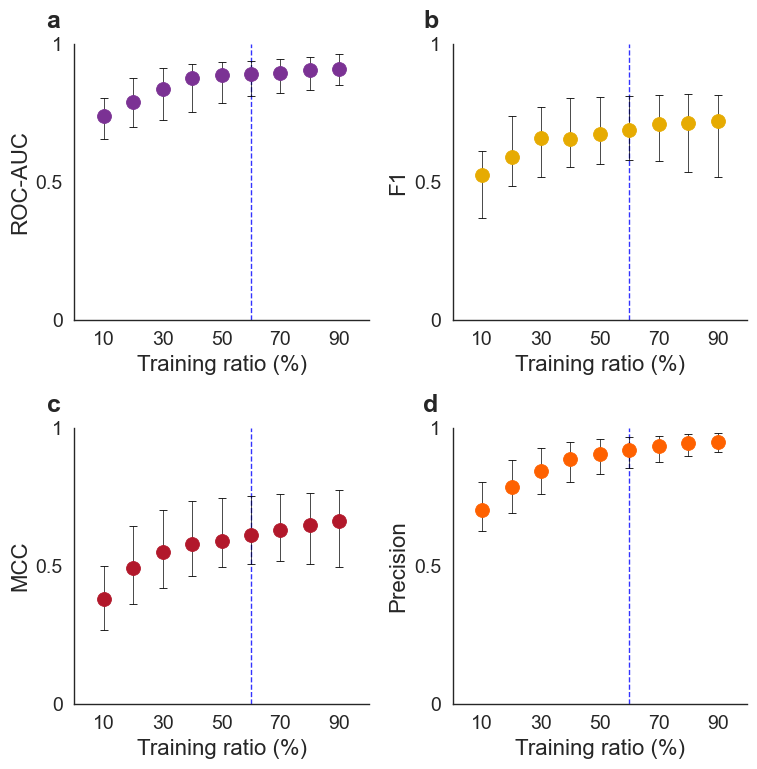

In [6]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from IPython.display import display


sns.set_context(
    "paper",
    font_scale=1.35,
)

sns.set_style("white")




# ============================================================
# Raw predictive inputs (no Tukey filtering)
# ============================================================

import re


def _raw_foodweb_name(path):
    return re.sub(
        r"_tax_mass_results_random_wlnm_.*$",
        "",
        path.stem,
        flags=re.I,
    )


def load_raw_predictive_compat(
    result_root,
    expected_version,
    metric_specs,
    expected_runs,
    minimum_retained_runs,
    *,
    train_ratios=None,
    cvk_values=None,
    k_target=10,
    threshold=0.50,
    kfold=False,
    scenario=None,
):
    """Return raw web-level means in the legacy plotting schema.

    The legacy column names are retained only so that the original plotting,
    layout, scale, colour and export code remains byte-for-byte unchanged.
    MeanAfterTukey below is a compatibility alias for the arithmetic mean of
    every complete raw run unit; no Tukey fences or outlier exclusions occur.
    """
    metrics = [metric for metric, _ in metric_specs]
    labels = dict(metric_specs)
    files = sorted((result_root / "prediction_scores_logs").glob("*.csv"))
    if not files:
        raise FileNotFoundError(result_root / "prediction_scores_logs")

    required = {
        "Version",
        "TrainRatio",
        "ExperimentID",
        "Seed",
        "Threshold",
        "K",
        "CvK",
        "FoldID",
        "EmpiricalConnectance",
        *metrics,
    }
    frames = []
    for path in files:
        frame = pd.read_csv(
            path,
            usecols=lambda column: column in required,
        )
        missing = required.difference(frame.columns)
        if missing:
            raise ValueError(
                f"{path.name}: missing raw columns {sorted(missing)}"
            )
        frame["Foodweb"] = _raw_foodweb_name(path)
        frames.append(frame)

    raw = pd.concat(frames, ignore_index=True)
    for column in required.difference({"Version"}):
        raw[column] = pd.to_numeric(raw[column], errors="coerce")
    raw["TrainRatio"] = np.where(
        raw["TrainRatio"].abs().le(1.0),
        raw["TrainRatio"] * 100.0,
        raw["TrainRatio"],
    )
    raw = raw.loc[
        raw["Version"].eq(expected_version)
        & np.isclose(raw["Threshold"], threshold, atol=1e-9)
        & np.isclose(raw["K"], k_target, atol=1e-9)
    ].copy()
    if train_ratios is not None:
        requested = np.asarray(list(train_ratios), dtype=float)
        raw = raw.loc[
            raw["TrainRatio"].map(
                lambda value: np.isclose(
                    value,
                    requested,
                    atol=1e-8,
                ).any()
            )
        ].copy()
    if cvk_values is not None:
        raw = raw.loc[raw["CvK"].isin(cvk_values)].copy()
    if raw.empty:
        raise ValueError(f"No raw observations selected from {result_root}")

    metric_values = raw[metrics].to_numpy(float)
    if not np.isfinite(metric_values).all():
        raise ValueError(f"Non-finite raw predictive values in {result_root}")
    probability_metrics = [
        metric for metric in metrics if metric not in {"TestMCC", "TestTSS"}
    ]
    signed_metrics = [
        metric for metric in metrics if metric in {"TestMCC", "TestTSS"}
    ]
    if probability_metrics:
        values = raw[probability_metrics].to_numpy(float)
        if ((values < 0) | (values > 1)).any():
            raise ValueError("Raw probability metrics must be within [0, 1]")
    if signed_metrics:
        values = raw[signed_metrics].to_numpy(float)
        if ((values < -1) | (values > 1)).any():
            raise ValueError("Raw MCC/TSS values must be within [-1, 1]")

    group_columns = [
        "Foodweb",
        "Version",
        "TrainRatio",
        "Threshold",
        "K",
        "CvK",
    ]
    if kfold:
        experiment_columns = [*group_columns, "ExperimentID"]
        fold_check = (
            raw.groupby(experiment_columns, dropna=False)
            .agg(
                FoldRows=("FoldID", "size"),
                UniqueFolds=("FoldID", "nunique"),
            )
            .reset_index()
        )
        incomplete = fold_check.loc[
            ~fold_check["FoldRows"].eq(fold_check["CvK"])
            | ~fold_check["UniqueFolds"].eq(fold_check["CvK"])
        ]
        if not incomplete.empty:
            raise ValueError(
                "Incomplete repeated-CV experiments found:\n"
                + incomplete.head(10).to_string(index=False)
            )
        run_units = (
            raw.groupby(
                experiment_columns,
                dropna=False,
                as_index=False,
            )
            .agg(
                **{
                    metric: (metric, "mean")
                    for metric in metrics
                },
                EmpiricalConnectance=(
                    "EmpiricalConnectance",
                    "first",
                ),
            )
        )
    else:
        experiment_columns = [*group_columns, "ExperimentID"]
        if raw.duplicated(experiment_columns).any():
            raise ValueError(f"Duplicate raw ExperimentID rows in {result_root}")
        run_units = raw

    counts = run_units.groupby(group_columns, dropna=False).size()
    if not counts.eq(expected_runs).all():
        raise ValueError(
            f"{result_root.name}: expected {expected_runs} complete raw "
            "run units per group; observed "
            f"{counts.value_counts().to_dict()}"
        )

    wide = (
        run_units.groupby(
            group_columns,
            dropna=False,
            as_index=False,
        )
        .agg(
            **{
                metric: (metric, "mean")
                for metric in metrics
            },
            EmpiricalConnectance=(
                "EmpiricalConnectance",
                "first",
            ),
            RawRunUnits=("ExperimentID", "size"),
        )
    )
    long = wide.melt(
        id_vars=[
            *group_columns,
            "EmpiricalConnectance",
            "RawRunUnits",
        ],
        value_vars=metrics,
        var_name="Metric",
        value_name="MeanAfterTukey",
    )
    long["Scenario"] = scenario or result_root.name
    long["MetricLabel"] = long["Metric"].map(labels)
    long["MetricFamily"] = "predictive"
    long["SourceColumn"] = long["Metric"]
    long["ReferenceColumn"] = ""
    long["MeanBeforeTukey"] = long["MeanAfterTukey"]
    long["TotalRunUnits"] = long["RawRunUnits"]
    long["ValidRunsBeforeTukey"] = long["RawRunUnits"]
    long["InvalidRunsBeforeTukey"] = 0
    long["OutlierRunsExcluded"] = 0
    long["RetainedRunsAfterTukey"] = long["RawRunUnits"]
    long["ExpectedRuns"] = expected_runs
    long["MinimumRetainedRuns"] = minimum_retained_runs
    long["MeetsMinimumRetainedRuns"] = 1
    long["ReferenceValue"] = long["EmpiricalConnectance"]
    return long

# ============================================================
# Locate repository root
# ============================================================

def find_repo_root(start=Path.cwd()):
    start = Path(start).resolve()

    candidates = [start, *start.parents]

    fallback = Path(
        "/Users/acw792/Developer/qmul-phd-framework"
    )

    if fallback not in candidates:
        candidates.append(fallback)

    for candidate in candidates:
        if (
            (candidate / "src/matlab").is_dir()
            and (candidate / "docs").is_dir()
        ):
            return candidate

    raise RuntimeError(
        "Could not locate the qmul-phd-framework repository."
    )


REPO_ROOT = find_repo_root()


# ============================================================
# Final role-only experimental configuration: 100 runs
# ============================================================

CHECK_CONNECTIVITY = False
ADAPTIVE_CONNECTIVITY = False
CLASSIFICATION_THRESHOLD = 0.50

NODES_THRESHOLD = 0

# Tukey is applied independently across 100 runs for each
# Foodweb × TrainRatio × Metric group.
#
# Keep the previously agreed absolute minimum of 25 runs.
EXPECTED_RUNS = 100
MINIMUM_RETAINED_FRACTION = 1.00
MINIMUM_RETAINED_RUNS = 100

PROTOCOL_NAME = (
    "tukey_iqr_1p5_min25runs_threshold0p50_v1"
)

EXPECTED_SCENARIO = (
    "result_wlnm_dir_neg_roleonly_trophicv2_"
    "100x290_train10-90_Apocrita_20260910_011848"
)

calculated_minimum_runs = int(
    np.ceil(
        EXPECTED_RUNS
        * MINIMUM_RETAINED_FRACTION
    )
)

assert calculated_minimum_runs == MINIMUM_RETAINED_RUNS, (
    "The configured minimum retained runs is inconsistent "
    "with the expected number of runs and retained fraction."
)


# ============================================================
# Final role-only result root
# ============================================================

RESULT_ROOT = (
    REPO_ROOT
    / "src/matlab/data"
    / (
        "result_wlnm_dir_neg_roleonly_trophicv2_"
        "100x290_train10-90_Apocrita_20260910_011848"
    )
)

RETENTION_ROOT = (
    RESULT_ROOT
    / "retention_protocol"
    / PROTOCOL_NAME
)

RETENTION_MANIFEST_PATH = (
    RETENTION_ROOT
    / "retention_manifest.json"
)

RESULTS_FILE = RESULT_ROOT

FOODWEB_CSV = (
    REPO_ROOT
    / "src/matlab/data/foodwebs_mat"
    / "foodweb_metrics_ecosystem.csv"
)

# ============================================================
# Output paths
# ============================================================

OUT_DIR = RESULT_ROOT / "figures_raw_unfiltered"

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

OUTPUT_STEM = "figure_4_predictive_four_metrics_by_train_ratio_raw_unfiltered"

PNG_PATH = OUT_DIR / f"{OUTPUT_STEM}.png"
SVG_PATH = OUT_DIR / f"{OUTPUT_STEM}.svg"
PDF_PATH = OUT_DIR / f"{OUTPUT_STEM}.pdf"

SUMMARY_PATH = (
    OUT_DIR
    / f"{OUTPUT_STEM}_summary.csv"
)

RETENTION_PATH = (
    OUT_DIR
    / f"{OUTPUT_STEM}_raw_run_counts.csv"
)


# ============================================================
# Metrics
# ============================================================

METRICS = [
    "ROC_AUC",
    "F1Score",
    "TestMCC",
    "Precision",
]

METRIC_LABELS = {
    "ROC_AUC": "ROC-AUC",
    "PR_AUC": "PR-AUC",
    "F1Score": "F1",
    "TestMCC": "MCC",
    "Precision": "Precision",
    "Recall": "Recall",
    "TestTSS": "TSS",
}

METRIC_PALETTE = {
    "ROC-AUC": "#7B3294",
    "PR-AUC": "#C51B7D",
    "F1": "#E6AB02",
    "MCC": "#B2182B",
    "Precision": "#FE6100",
    "Recall": "#CAB2D6",
    "TSS": "#666666",
}

SHOW_GRID = False

Y_MIN = 0.0
Y_MAX = 1.0

INDEPENDENT_Y = False
Y_PADDING = 0.02

REFERENCE_TRAIN_RATIO = 60


# ============================================================
# Validate raw inputs
# ============================================================

if not (RESULT_ROOT / "prediction_scores_logs").is_dir():
    raise FileNotFoundError(RESULT_ROOT / "prediction_scores_logs")
if not FOODWEB_CSV.is_file():
    raise FileNotFoundError(FOODWEB_CSV)

print(f"[INFO] Repository: {REPO_ROOT}")
print(f"[INFO] Result root: {RESULT_ROOT}")
print("[INFO] Raw prediction input; no Tukey filtering.")

# ============================================================
# Food-web name normalisation
# ============================================================

def normalize_fw_label(name):
    name = str(name).strip()

    for suffix in [
        ".mat",
        ".csv",
    ]:
        if name.endswith(suffix):
            name = name[: -len(suffix)]

    name = name.replace(
        " ",
        "_",
    )

    for token in [
        "_results_",
        "_result_",
        "_results",
        "_random",
        "_tax_mass",
        "_tax",
        "_mass",
    ]:
        name = name.replace(
            token,
            "_",
        )

    return "_".join(
        part
        for part in name.split("_")
        if part
    ).lower()


# ============================================================
# Load raw unfiltered web-level results
# ============================================================

df = load_raw_predictive_compat(
    RESULT_ROOT,
    "WLNM_dir_neg",
        [(metric, METRIC_LABELS[metric]) for metric in METRICS],
        EXPECTED_RUNS,
        EXPECTED_RUNS,
    train_ratios=range(10, 100, 10),
    scenario=EXPECTED_SCENARIO,
)

# ============================================================
# Select the final role-only configuration
# ============================================================

target_df = df[
    df["Scenario"].eq(
        EXPECTED_SCENARIO
    )
    & df["Version"].eq(
        "WLNM_dir_neg"
    )
    & df["MetricFamily"].eq(
        "predictive"
    )
    & df["Metric"].isin(
        METRICS
    )
    & np.isclose(
        df["Threshold"],
        CLASSIFICATION_THRESHOLD,
        atol=1e-9,
        equal_nan=False,
    )
].copy()

if target_df.empty:
    raise RuntimeError(
        "No predictive results match the final "
        "role-only configuration."
    )


# ============================================================
# Validate minimum 25 retained runs
# ============================================================

observed_minimums = set(
    target_df["MinimumRetainedRuns"]
    .dropna()
    .astype(int)
    .unique()
)

if observed_minimums != {
    MINIMUM_RETAINED_RUNS
}:
    raise ValueError(
        "The Tukey figure input was not processed with "
        f"the expected minimum of "
        f"{MINIMUM_RETAINED_RUNS} retained runs.\n"
        f"Observed values: {sorted(observed_minimums)}"
    )

incorrect_retention = target_df[
    target_df["MeetsMinimumRetainedRuns"].eq(1)
    & target_df["RetainedRunsAfterTukey"].lt(
        MINIMUM_RETAINED_RUNS
    )
]

if not incorrect_retention.empty:
    display(
        incorrect_retention[
            [
                "Foodweb",
                "TrainRatio",
                "Metric",
                "RetainedRunsAfterTukey",
                "MinimumRetainedRuns",
                "MeetsMinimumRetainedRuns",
            ]
        ]
    )

    raise ValueError(
        "At least one group is marked as retained despite "
        f"having fewer than {MINIMUM_RETAINED_RUNS} runs."
    )

below_minimum = target_df[
    target_df["RetainedRunsAfterTukey"].lt(
        MINIMUM_RETAINED_RUNS
    )
]

if not below_minimum.empty:
    print(
        "[INFO] Groups excluded because fewer than "
        f"{MINIMUM_RETAINED_RUNS} runs remained: "
        f"{len(below_minimum):,}"
    )


# ============================================================
# Keep valid Tukey-filtered groups
# ============================================================

df = target_df[
    target_df["MinimumRetainedRuns"].eq(
        MINIMUM_RETAINED_RUNS
    )
    & target_df["RetainedRunsAfterTukey"].ge(
        MINIMUM_RETAINED_RUNS
    )
    & target_df["MeetsMinimumRetainedRuns"].eq(1)
    & target_df["MeanAfterTukey"].notna()
].copy()

if df.empty:
    raise RuntimeError(
        "No retained predictive results remain after "
        "validating the Tukey minimum."
    )

print(
    "[INFO] Raw run completeness validated: "
    f"at least {MINIMUM_RETAINED_RUNS} of "
    f"{EXPECTED_RUNS} runs per food web and metric."
)

print(
    "[INFO] Actual retained-run range: "
    f"{int(df['RetainedRunsAfterTukey'].min())}–"
    f"{int(df['RetainedRunsAfterTukey'].max())}"
)


# ============================================================
# Prepare plotting variables
# ============================================================

df["TRAINRATIO"] = (
    df["TrainRatio"]
    .round()
    .astype(int)
)

df["Value"] = (
    df["MeanAfterTukey"]
)

df["FW_KEY"] = (
    df["Foodweb"]
    .apply(normalize_fw_label)
)


# ============================================================
# Validate expected training ratios
# ============================================================

expected_train_ratios = list(
    range(
        10,
        100,
        10,
    )
)

observed_train_ratios = sorted(
    df["TRAINRATIO"]
    .dropna()
    .unique()
    .tolist()
)

if observed_train_ratios != expected_train_ratios:
    raise ValueError(
        "Unexpected training-ratio coverage:\n"
        f"  expected: {expected_train_ratios}\n"
        f"  observed: {observed_train_ratios}"
    )


# ============================================================
# Validate unique web-level observations
# ============================================================

duplicate_mask = df.duplicated(
    subset=[
        "FW_KEY",
        "TRAINRATIO",
        "Metric",
    ],
    keep=False,
)

if duplicate_mask.any():
    duplicated = (
        df.loc[
            duplicate_mask,
            [
                "Foodweb",
                "TRAINRATIO",
                "Metric",
            ],
        ]
        .sort_values(
            [
                "Metric",
                "TRAINRATIO",
                "Foodweb",
            ]
        )
    )

    display(duplicated)

    raise ValueError(
        "Duplicated Foodweb × TrainRatio × Metric "
        "rows were found."
    )


# ============================================================
# Load food-web metadata
# ============================================================

metadata = pd.read_csv(
    FOODWEB_CSV
)

metadata.columns = [
    column.strip()
    for column in metadata.columns
]

foodweb_column = next(
    (
        column
        for column in metadata.columns
        if column.lower() == "foodweb"
    ),
    None,
)

nodes_column = next(
    (
        column
        for column in metadata.columns
        if column.lower() in {
            "nodes",
            "n_nodes",
            "num_nodes",
            "nodecount",
            "s",
        }
    ),
    None,
)

ecosystem_column = next(
    (
        column
        for column in metadata.columns
        if column.lower() in {
            "ecosystem",
            "ecosystemtype",
            "ecosystem_type",
        }
    ),
    None,
)

if (
    foodweb_column is None
    or nodes_column is None
    or ecosystem_column is None
):
    raise ValueError(
        "Could not identify Foodweb, Nodes, and "
        "Ecosystem columns in the metadata."
    )

metadata[nodes_column] = pd.to_numeric(
    metadata[nodes_column],
    errors="coerce",
)

metadata["FW_KEY"] = (
    metadata[foodweb_column]
    .apply(normalize_fw_label)
)

duplicate_metadata = metadata.duplicated(
    subset=["FW_KEY"],
    keep=False,
)

if duplicate_metadata.any():
    inconsistent_metadata = (
        metadata.loc[
            duplicate_metadata,
            [
                "FW_KEY",
                nodes_column,
                ecosystem_column,
            ],
        ]
        .groupby("FW_KEY")
        .nunique(
            dropna=False
        )
    )

    inconsistent_metadata = inconsistent_metadata[
        (
            inconsistent_metadata[nodes_column] > 1
        )
        | (
            inconsistent_metadata[
                ecosystem_column
            ] > 1
        )
    ]

    if not inconsistent_metadata.empty:
        display(
            inconsistent_metadata
        )

        raise ValueError(
            "Conflicting metadata were found for one or "
            "more normalised food-web names."
        )

metadata = (
    metadata[
        [
            "FW_KEY",
            nodes_column,
            ecosystem_column,
        ]
    ]
    .drop_duplicates(
        subset=["FW_KEY"]
    )
    .rename(
        columns={
            nodes_column: "Nodes",
            ecosystem_column: "Ecosystem",
        }
    )
)


# ============================================================
# Merge metadata and apply node filter
# ============================================================

df = df.merge(
    metadata,
    on="FW_KEY",
    how="left",
    validate="many_to_one",
)

missing_metadata = (
    df.loc[
        (
            df["Nodes"].isna()
            | df["Ecosystem"].isna()
        ),
        "Foodweb",
    ]
    .drop_duplicates()
    .sort_values()
)

if not missing_metadata.empty:
    display(
        missing_metadata.to_frame(
            name="Foodweb"
        )
    )

    raise ValueError(
        "Food-web metadata could not be matched for "
        f"{len(missing_metadata)} food webs."
    )

df = df[
    df["Nodes"] >= NODES_THRESHOLD
].copy()

if df.empty:
    raise RuntimeError(
        f"No food webs remain after applying "
        f"Nodes >= {NODES_THRESHOLD}."
    )

print(
    f"[INFO] Food webs after node filter: "
    f"{df['FW_KEY'].nunique()}"
)

print(
    "[INFO] Training ratios: "
    f"{sorted(df['TRAINRATIO'].unique().tolist())}"
)

print(
    "[INFO] Ecosystems: "
    f"{sorted(df['Ecosystem'].dropna().unique().tolist())}"
)


# ============================================================
# Retention report
# ============================================================

retention_table = (
    df
    .groupby(
        [
            "TRAINRATIO",
            "Metric",
        ],
        as_index=False,
    )
    .agg(
        FoodWebs=(
            "FW_KEY",
            "nunique",
        ),
        MinimumRetainedRuns=(
            "RetainedRunsAfterTukey",
            "min",
        ),
        MedianRetainedRuns=(
            "RetainedRunsAfterTukey",
            "median",
        ),
        MaximumRetainedRuns=(
            "RetainedRunsAfterTukey",
            "max",
        ),
    )
)

retention_table["MetricLabel"] = (
    retention_table["Metric"]
    .map(METRIC_LABELS)
)

retention_table = retention_table[
    [
        "TRAINRATIO",
        "Metric",
        "MetricLabel",
        "FoodWebs",
        "MinimumRetainedRuns",
        "MedianRetainedRuns",
        "MaximumRetainedRuns",
    ]
]

print(
    "\n=== Raw run counts by training ratio "
    "and metric ==="
)

display(
    retention_table
)


# ============================================================
# Across-food-web summary
# ============================================================

summary = (
    df
    .groupby(
        [
            "TRAINRATIO",
            "Metric",
        ],
        as_index=False,
    )
    .agg(
        median=(
            "Value",
            "median",
        ),
        q25=(
            "Value",
            lambda values: values.quantile(
                0.25
            ),
        ),
        q75=(
            "Value",
            lambda values: values.quantile(
                0.75
            ),
        ),
        mean=(
            "Value",
            "mean",
        ),
        sd=(
            "Value",
            "std",
        ),
        n_webs=(
            "FW_KEY",
            "nunique",
        ),
    )
)

summary["MetricLabel"] = (
    summary["Metric"]
    .map(METRIC_LABELS)
)

train_ratios = sorted(
    summary["TRAINRATIO"]
    .unique()
    .tolist()
)

print(
    f"[INFO] Food webs represented: "
    f"{df['FW_KEY'].nunique()}"
)


# ============================================================
# Consistent metric colours
# ============================================================

metric_colors = {
    metric: METRIC_PALETTE[
        METRIC_LABELS[metric]
    ]
    for metric in METRICS
}


# ============================================================
# Final plot
# ============================================================

number_of_metrics = len(
    METRICS
)

number_of_rows = 2

number_of_columns = int(
    np.ceil(
        number_of_metrics
        / number_of_rows
    )
)

fig, axes = plt.subplots(
    number_of_rows,
    number_of_columns,
    figsize=(
        4 * number_of_columns,
        8.0,
    ),
    sharex=False,
    sharey=False,
)

axes = np.asarray(
    axes
).reshape(
    number_of_rows,
    number_of_columns,
)

axes_flat = axes.flatten()

panel_letters = list(
    "abcdefghijklmnopqrstuvwxyz"
)

for index, metric in enumerate(
    METRICS
):
    ax = axes_flat[index]

    panel_df = (
        summary[
            summary["Metric"].eq(
                metric
            )
        ]
        .sort_values(
            "TRAINRATIO"
        )
    )

    if panel_df.empty:
        ax.set_axis_off()
        continue

    x_values = (
        panel_df["TRAINRATIO"]
        .to_numpy()
    )

    median_values = (
        panel_df["median"]
        .to_numpy()
    )

    error_values = np.vstack(
        [
            (
                panel_df["median"]
                - panel_df["q25"]
            ).to_numpy(),
            (
                panel_df["q75"]
                - panel_df["median"]
            ).to_numpy(),
        ]
    )

    color = metric_colors[
        metric
    ]

    ax.errorbar(
        x_values,
        median_values,
        yerr=error_values,
        fmt="o",
        linestyle="none",
        color=color,
        ecolor="black",
        markersize=10,
        linewidth=1.2,
        elinewidth=0.5,
        capsize=3,
        capthick=0.8,
        markerfacecolor=color,
        markeredgecolor=color,
        markeredgewidth=0.6,
    )

    ax.axvline(
        x=REFERENCE_TRAIN_RATIO,
        color="blue",
        linestyle="--",
        linewidth=1.0,
        alpha=0.8,
        zorder=0,
    )

    if INDEPENDENT_Y:
        local_minimum = max(
            Y_MIN,
            panel_df["q25"].min()
            - Y_PADDING,
        )

        local_maximum = min(
            Y_MAX,
            panel_df["q75"].max()
            + Y_PADDING,
        )

        if np.isclose(
            local_minimum,
            local_maximum,
        ):
            local_minimum = max(
                Y_MIN,
                local_minimum
                - 0.02,
            )

            local_maximum = min(
                Y_MAX,
                local_maximum
                + 0.02,
            )

        ax.set_ylim(
            local_minimum,
            local_maximum,
        )

    else:
        ax.set_ylim(
            Y_MIN,
            Y_MAX,
        )

        ax.set_yticks(
            [
                0,
                0.5,
                1.0,
            ]
        )

        ax.set_yticklabels(
            [
                "0",
                "0.5",
                "1",
            ]
        )

    if SHOW_GRID:
        ax.grid(
            True,
            axis="y",
            linestyle="--",
            alpha=0.30,
        )
    else:
        ax.grid(
            False
        )

    visible_ticks = [
        ratio
        for ratio in [
            10,
            30,
            50,
            70,
            90,
        ]
        if ratio in train_ratios
    ]

    ax.set_xticks(
        visible_ticks
    )

    ax.set_xticklabels(
        [
            str(ratio)
            for ratio in visible_ticks
        ]
    )

    ax.set_xlim(
        min(train_ratios) - 10,
        max(train_ratios) + 10,
    )

    ax.set_xlabel(
        "Training ratio (%)",
        fontsize=16,
    )

    ax.set_ylabel(
        METRIC_LABELS[metric],
        fontsize=16,
    )

    ax.set_title("")

    if index < len(
        panel_letters
    ):
        ax.annotate(
            panel_letters[index],
            xy=(0, 1),
            xycoords="axes fraction",
            xytext=(-10, 8),
            textcoords="offset points",
            ha="right",
            va="bottom",
            fontsize=18,
            fontweight="bold",
            annotation_clip=False,
        )

    ax.tick_params(
        axis="both",
        labelsize=14,
    )

    sns.despine(
        ax=ax
    )


# ============================================================
# Hide unused panels
# ============================================================

for index in range(
    number_of_metrics,
    len(axes_flat),
):
    axes_flat[index].set_axis_off()


# ============================================================
# Layout and export
# ============================================================

fig.tight_layout(
    rect=[
        0.03,
        0,
        1,
        0.985,
    ]
)

fig.savefig(
    PNG_PATH,
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    SVG_PATH,
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    PDF_PATH,
    bbox_inches="tight",
    facecolor="white",
)

summary.to_csv(
    SUMMARY_PATH,
    index=False,
)

retention_table.to_csv(
    RETENTION_PATH,
    index=False,
)

print(
    "\n[INFO] Saved publication-ready outputs:"
)

print(f"  PNG: {PNG_PATH}")
print(f"  SVG: {SVG_PATH}")
print(f"  PDF: {PDF_PATH}")
print(f"  Summary: {SUMMARY_PATH}")
print(f"  Raw run counts: {RETENTION_PATH}")

print(
    "\n[INFO] Final raw-input configuration:"
)

print(
    f"  expected_runs="
    f"{EXPECTED_RUNS}"
)

print(
    f"  minimum_retained_fraction="
    f"{MINIMUM_RETAINED_FRACTION:.2f}"
)

print(
    f"  minimum_retained_runs="
    f"{MINIMUM_RETAINED_RUNS}/{EXPECTED_RUNS}"
)

plt.show()

[INFO] Repository: /Users/acw792/Developer/qmul-phd-framework
[INFO] Result root: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848
[INFO] Raw input directory: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/prediction_scores_logs
[INFO] TrainRatio=60, threshold=0.50, expected raw runs=100.
[INFO] Tukey filtering is not applied.
[INFO] Raw run completeness validated: at least 1 of 100 runs per food web and metric.
[INFO] Actual valid raw-run range: 51–100

=== Paired Wilcoxon signed-rank tests by ecological metric ===


,MetricLabel,NPairs,NNonzeroDifferences,MedianDifference,WilcoxonStatistic,RankBiserialCorrelation,PValueRaw,PValueHolm,RejectH0Holm
0,Connectance,290,290,-0.015976,0.0,-1.000000,2.630560e-49,1.052224e-48,True
1,Mean trophic height,290,290,0.123878,3312.0,0.843015,1.519480e-35,1.519480e-35,True
2,Mean generality,290,290,-0.800218,1603.0,-0.924019,2.345926e-42,7.037779e-42,True
3,Mean vulnerability,290,290,-0.489259,1789.0,-0.915203,1.385408e-41,2.770815e-41,True


[INFO] Raw-data Wilcoxon outputs were not written; the figure uses raw means.
[NOTE] A non-significant Wilcoxon result does not demonstrate equivalence or similarity.
[INFO] Raw source directory: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/prediction_scores_logs
[INFO] Loaded raw web-level rows: 1,160
[INFO] Food webs represented: 290
[INFO] Plotting rows after empirical/mean-pseudo expansion: 2,320
[INFO] Each food web contributes one empirical value and one arithmetic mean across raw valid pseudo runs.
[INFO] No Tukey fences or Tukey outlier exclusions are applied.
[INFO] MeanTrophicHeight excludes only diagnostically invalid raw NetworkX values.
[INFO] Configuration: eligibility=role_only, mass_constraint=False, random_topup=True, negative_positive_ratio=2:1, check_connectivity=False, adaptive_connectivity=False, classification_threshold=0.50.


,Metric,FoodWebs,MinRawRuns,MedianRawRuns,MaxRawRuns
0,Connectance,290,100,100.0,100
1,MeanNormalizedGeneralityConsumersOnly,290,100,100.0,100
2,MeanNormalizedVulnerabilityResourcesOnly,290,100,100.0,100
3,MeanTrophicHeight,290,51,96.0,100


[INFO] Saved figure: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/figures_raw_unfiltered/fig5_wlnm_dir_neg_train60_athen_normalized_gv_roleonly_trophicv2_100runs_threshold0p50_raw_unfiltered.png
[INFO] Final raw configuration:
  expected_runs=100
  tukey_filtering=False
  aggregation=arithmetic mean across all diagnostically valid raw runs


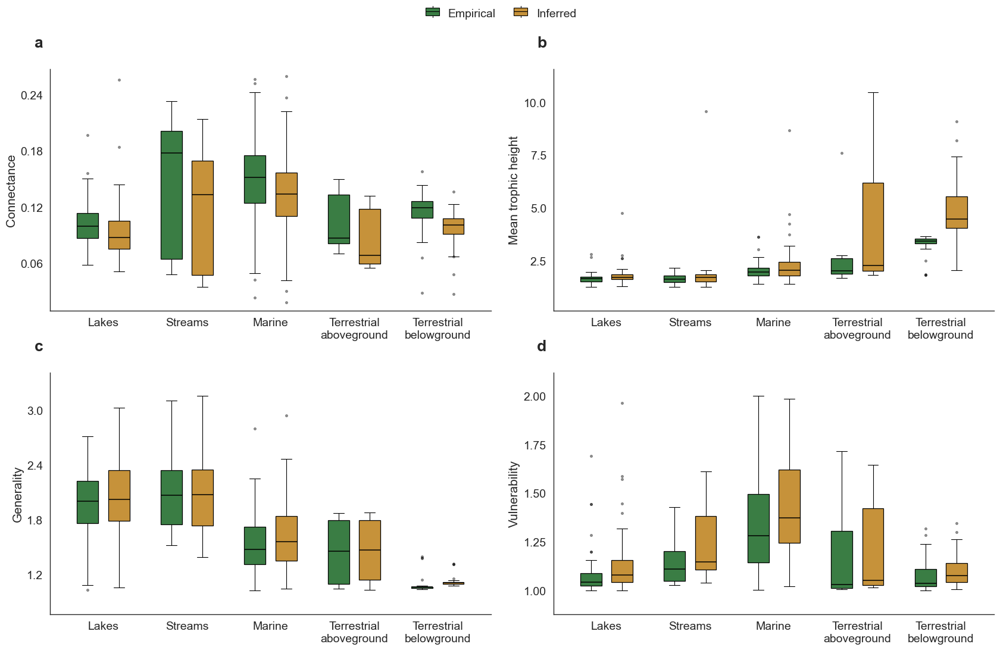

In [32]:
import json
import math

import numpy as np
import pandas as pd
import scipy
import seaborn as sns

from pathlib import Path
from IPython.display import display

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.legend_handler import HandlerBase
from matplotlib.ticker import MaxNLocator
from scipy.stats import rankdata, wilcoxon


sns.set_theme(
    context="paper",
    style="white",
    font_scale=1.15,
)


# ============================================================
# Locate repository root
# ============================================================

def find_repo_root(start=Path.cwd()):
    start = Path(start).resolve()

    candidates = [start, *start.parents]

    fallback = Path(
        "/Users/acw792/Developer/qmul-phd-framework"
    )

    if fallback not in candidates:
        candidates.append(fallback)

    for path in candidates:
        if (
            (path / "src/matlab").is_dir()
            and (path / "docs").is_dir()
        ):
            return path

    raise RuntimeError(
        "Could not locate the qmul-phd-framework repository."
    )


REPO_ROOT = find_repo_root()


# ============================================================
# Raw role-only data configuration: 100 runs, no Tukey filtering
# ============================================================

TRAIN_RATIO = 60
CLASSIFICATION_THRESHOLD = 0.50
EXPECTED_K = 10
EXPECTED_RUNS = 100
MINIMUM_RETAINED_RUNS = 1

CHECK_CONNECTIVITY = False
ADAPTIVE_CONNECTIVITY = False

PROTOCOL_NAME = "raw_unfiltered_no_tukey"
EXPECTED_SCENARIO = (
    "result_wlnm_dir_neg_roleonly_trophicv2_"
    "100x290_train10-90_Apocrita_20260910_011848"
)

RESULT_ROOT = (
    REPO_ROOT
    / "src/matlab/data"
    / EXPECTED_SCENARIO
)
RAW_RESULTS_DIR = RESULT_ROOT / "prediction_scores_logs"
FOODWEB_METADATA = (
    REPO_ROOT
    / "src/matlab/data/foodwebs_mat"
    / "foodweb_metrics_ecosystem.csv"
)

OUT_DIR = RESULT_ROOT / "figures_raw_unfiltered"
OUT_DIR.mkdir(parents=True, exist_ok=True)
OUT_PATH = (
    OUT_DIR
    / (
        f"fig5_wlnm_dir_neg_train{TRAIN_RATIO}_"
        "athen_normalized_gv_roleonly_trophicv2_100runs_"
        "threshold0p50_raw_unfiltered.png"
    )
)

STATISTICAL_TESTS_DIR = RESULT_ROOT / "statistical_tests_raw_unfiltered"
WILCOXON_OUTPUT_STEM = (
    f"figure_5_wilcoxon_train{TRAIN_RATIO}_"
    "roleonly_trophicv2_100runs_threshold0p50_raw_unfiltered"
)
WILCOXON_RESULTS_PATH = (
    STATISTICAL_TESTS_DIR / f"{WILCOXON_OUTPUT_STEM}_results.csv"
)
WILCOXON_PAIRS_PATH = (
    STATISTICAL_TESTS_DIR / f"{WILCOXON_OUTPUT_STEM}_pairs.csv"
)

required_inputs = {
    "Raw prediction-score directory": RAW_RESULTS_DIR,
    "Food-web metadata": FOODWEB_METADATA,
}
missing_inputs = [
    f"{label}: {path}"
    for label, path in required_inputs.items()
    if not path.exists()
]
if missing_inputs:
    raise FileNotFoundError(
        "Missing required raw inputs:\n" + "\n".join(missing_inputs)
    )

print(f"[INFO] Repository: {REPO_ROOT}")
print(f"[INFO] Result root: {RESULT_ROOT}")
print(f"[INFO] Raw input directory: {RAW_RESULTS_DIR}")
print(
    f"[INFO] TrainRatio={TRAIN_RATIO}, threshold="
    f"{CLASSIFICATION_THRESHOLD:.2f}, expected raw runs={EXPECTED_RUNS}."
)
print("[INFO] Tukey filtering is not applied.")


# ============================================================
# Figure configuration
# ============================================================

BOX_WIDTH = 0.30
TYPE_OFFSET = 0.22
GROUP_SPACING = 1.18

# These are web-level boxplot fliers. Raw pseudo runs are not
# filtered with Tukey before calculating each food-web mean.
SHOW_WEB_LEVEL_FLIERS = True

base_ecosystem_order = [
    "lakes",
    "streams",
    "marine",
    "terrestrial aboveground",
    "terrestrial belowground",
]

ecosystem_labels = {
    "lakes": "Lakes",
    "streams": "Streams",
    "marine": "Marine",
    "terrestrial aboveground": (
        "Terrestrial\naboveground"
    ),
    "terrestrial belowground": (
        "Terrestrial\nbelowground"
    ),
}

wilcoxon_metric_order = [
    "Connectance",
    "MeanTrophicHeight",
    "MeanGenerality",
    "MeanVulnerability",
]

metric_order = [
    "Connectance",
    "MeanTrophicHeight",
    "MeanNormalizedGeneralityConsumersOnly",
    "MeanNormalizedVulnerabilityResourcesOnly",
]

metric_labels = {
    "Connectance": "Connectance",
    "MeanTrophicHeight": "Mean trophic height",
    "MeanGenerality": "Mean generality",
    "MeanVulnerability": "Mean vulnerability",
    "MeanNormalizedGeneralityConsumersOnly": (
        "Generality"
    ),
    "MeanNormalizedVulnerabilityResourcesOnly": (
        "Vulnerability"
    ),
}

panel_letters = list(
    "abcdefghijklmnopqrstuvwxyz"
)

type_palette = {
    "Empirical": "#3A7D44",
    "Pseudo": "#C6923A",
}

# Paired Wilcoxon configuration. The food web is the unit
# of analysis; the 100 repeated runs are not treated as
# independent observations.
WILCOXON_ALPHA = 0.05
WILCOXON_ALTERNATIVE = "two-sided"
WILCOXON_ZERO_METHOD = "wilcox"
WILCOXON_METHOD = "auto"
WILCOXON_CORRECTION = False
DIFFERENCE_DECIMALS = 12
WRITE_WILCOXON_OUTPUTS = False


# ============================================================
# Figure helpers
# ============================================================

def format_ecosystem_label(eco: str) -> str:
    eco_clean = str(
        eco
    ).strip().lower()

    return ecosystem_labels.get(
        eco_clean,
        str(eco).strip().capitalize(),
    )


def draw_box(
    ax,
    values,
    position,
    facecolor,
    showfliers=False,
):
    ax.boxplot(
        values,
        positions=[position],
        widths=BOX_WIDTH,
        patch_artist=True,
        manage_ticks=False,
        showfliers=showfliers,
        boxprops={
            "facecolor": facecolor,
            "edgecolor": "black",
            "linewidth": 0.9,
        },
        medianprops={
            "color": "black",
            "linewidth": 1.1,
        },
        whiskerprops={
            "color": "black",
            "linewidth": 0.8,
        },
        capprops={
            "color": "black",
            "linewidth": 0.8,
        },
        flierprops={
            "marker": "o",
            "markersize": 3.0,
            "markerfacecolor": "black",
            "markeredgecolor": "black",
            "markeredgewidth": 0.4,
            "linestyle": "none",
            "alpha": 0.45,
        },
    )


def get_boxplot_visible_ylim(
    grouped_values,
    lower_bound=0.0,
    pad_fraction=0.12,
):
    visible_lows = []
    visible_highs = []

    for values in grouped_values:
        values = np.asarray(
            values,
            dtype=float,
        )

        values = values[
            np.isfinite(values)
        ]

        if values.size == 0:
            continue

        q1, q3 = np.nanpercentile(
            values,
            [25, 75],
        )

        iqr = q3 - q1

        if np.isclose(
            iqr,
            0,
        ):
            lower_whisker = np.nanmin(
                values
            )

            upper_whisker = np.nanmax(
                values
            )

        else:
            lower_fence = (
                q1 - 1.5 * iqr
            )

            upper_fence = (
                q3 + 1.5 * iqr
            )

            non_fliers = values[
                (values >= lower_fence)
                & (values <= upper_fence)
            ]

            if non_fliers.size == 0:
                non_fliers = values

            lower_whisker = np.nanmin(
                non_fliers
            )

            upper_whisker = np.nanmax(
                non_fliers
            )

        visible_lows.extend(
            [
                lower_whisker,
                q1,
            ]
        )

        visible_highs.extend(
            [
                upper_whisker,
                q3,
            ]
        )

    if (
        not visible_lows
        or not visible_highs
    ):
        return None

    local_min = np.nanmin(
        visible_lows
    )

    local_max = np.nanmax(
        visible_highs
    )

    data_range = (
        local_max - local_min
        if local_max > local_min
        else 0.05
    )

    local_min = max(
        lower_bound,
        local_min
        - pad_fraction * data_range,
    )

    local_max = (
        local_max
        + pad_fraction * data_range
    )

    if np.isclose(
        local_min,
        local_max,
    ):
        local_min = max(
            lower_bound,
            local_min - 0.02,
        )

        local_max = (
            local_max + 0.02
        )

    return local_min, local_max


class HandlerMiniBoxplot(HandlerBase):
    def create_artists(
        self,
        legend,
        orig_handle,
        xdescent,
        ydescent,
        width,
        height,
        fontsize,
        trans,
    ):
        facecolor = orig_handle[
            "facecolor"
        ]

        edgecolor = orig_handle.get(
            "edgecolor",
            "black",
        )

        linewidth = orig_handle.get(
            "linewidth",
            0.8,
        )

        y_shift = -0.06 * height
        cx = xdescent + 0.5 * width
        cy = ydescent + 0.5 * height + y_shift

        box_w = 0.8 * width
        box_h = 0.8 * height
        box_x = cx - box_w / 2
        box_y = cy - box_h / 2

        whisk_top_y = (
            box_y
            + box_h
            + 0.18 * height
        )

        whisk_bot_y = (
            box_y
            - 0.18 * height
        )

        box = Rectangle(
            (box_x, box_y),
            box_w,
            box_h,
            facecolor=facecolor,
            edgecolor=edgecolor,
            linewidth=linewidth,
            transform=trans,
        )

        median = Line2D(
            [
                box_x,
                box_x + box_w,
            ],
            [
                cy,
                cy,
            ],
            color=edgecolor,
            linewidth=linewidth,
            transform=trans,
        )

        whisker_top = Line2D(
            [
                cx,
                cx,
            ],
            [
                box_y + box_h,
                whisk_top_y,
            ],
            color=edgecolor,
            linewidth=linewidth,
            transform=trans,
        )

        whisker_bottom = Line2D(
            [
                cx,
                cx,
            ],
            [
                whisk_bot_y,
                box_y,
            ],
            color=edgecolor,
            linewidth=linewidth,
            transform=trans,
        )

        return [
            box,
            median,
            whisker_top,
            whisker_bottom,
        ]


# ============================================================
# Paired Wilcoxon helpers
# ============================================================

def adjust_pvalues_holm(p_values):
    """Return Holm-adjusted p-values in original order."""
    p_values = np.asarray(
        p_values,
        dtype=float,
    )

    adjusted = np.full(
        p_values.shape,
        np.nan,
        dtype=float,
    )

    valid_indices = np.flatnonzero(
        np.isfinite(p_values)
    )

    if valid_indices.size == 0:
        return adjusted

    valid_p_values = p_values[
        valid_indices
    ]

    order = np.argsort(
        valid_p_values
    )

    ordered_p_values = valid_p_values[
        order
    ]

    number_of_tests = len(
        ordered_p_values
    )

    multipliers = (
        number_of_tests
        - np.arange(number_of_tests)
    )

    ordered_adjusted = np.maximum.accumulate(
        multipliers
        * ordered_p_values
    )

    ordered_adjusted = np.minimum(
        ordered_adjusted,
        1.0,
    )

    valid_adjusted = np.empty_like(
        ordered_adjusted
    )

    valid_adjusted[order] = (
        ordered_adjusted
    )

    adjusted[valid_indices] = (
        valid_adjusted
    )

    return adjusted


def calculate_signed_rank_effect(differences):
    """Return positive/negative rank sums and rank-biserial r."""
    differences = np.asarray(
        differences,
        dtype=float,
    )

    nonzero = differences[
        differences != 0.0
    ]

    if nonzero.size == 0:
        return 0.0, 0.0, 0.0

    ranks = rankdata(
        np.abs(nonzero),
        method="average",
    )

    positive_rank_sum = float(
        ranks[nonzero > 0.0].sum()
    )

    negative_rank_sum = float(
        ranks[nonzero < 0.0].sum()
    )

    total_rank_sum = (
        positive_rank_sum
        + negative_rank_sum
    )

    rank_biserial = (
        (
            positive_rank_sum
            - negative_rank_sum
        )
        / total_rank_sum
    )

    return (
        positive_rank_sum,
        negative_rank_sum,
        float(rank_biserial),
    )


def run_paired_wilcoxon_by_metric(
    pairs,
    metrics,
):
    """Run one paired two-sided test per ecological metric."""
    result_rows = []

    for metric in metrics:
        metric_pairs = (
            pairs.loc[
                pairs["Metric"].eq(metric)
            ]
            .sort_values("FW_KEY")
            .copy()
        )

        if metric_pairs.empty:
            raise ValueError(
                f"No paired values found for metric: {metric}"
            )

        differences = metric_pairs[
            "Difference"
        ].to_numpy(dtype=float)

        positive_rank_sum, negative_rank_sum, rank_biserial = (
            calculate_signed_rank_effect(
                differences
            )
        )

        number_of_nonzero_differences = int(
            np.count_nonzero(
                differences != 0.0
            )
        )

        if number_of_nonzero_differences == 0:
            statistic = 0.0
            p_value = 1.0
            status = "all_differences_zero"
        else:
            test = wilcoxon(
                differences,
                zero_method=WILCOXON_ZERO_METHOD,
                correction=WILCOXON_CORRECTION,
                alternative=WILCOXON_ALTERNATIVE,
                method=WILCOXON_METHOD,
            )

            statistic = float(
                test.statistic
            )

            p_value = float(
                test.pvalue
            )

            status = "ok"

        result_rows.append(
            {
                "Metric": metric,
                "MetricLabel": metric_labels[metric],
                "NPairs": len(metric_pairs),
                "NNonzeroDifferences": (
                    number_of_nonzero_differences
                ),
                "NPositiveDifferences": int(
                    np.count_nonzero(
                        differences > 0.0
                    )
                ),
                "NNegativeDifferences": int(
                    np.count_nonzero(
                        differences < 0.0
                    )
                ),
                "NZeroDifferences": int(
                    np.count_nonzero(
                        differences == 0.0
                    )
                ),
                "MedianEmpirical": float(
                    metric_pairs["EmpiricalValue"].median()
                ),
                "MedianPseudoRaw": float(
                    metric_pairs[
                        "MeanPseudoAfterFiltering"
                    ].median()
                ),
                "MeanDifference": float(
                    np.mean(differences)
                ),
                "MedianDifference": float(
                    np.median(differences)
                ),
                "WilcoxonStatistic": statistic,
                "PositiveRankSum": positive_rank_sum,
                "NegativeRankSum": negative_rank_sum,
                "RankBiserialCorrelation": rank_biserial,
                "PValueRaw": p_value,
                "Status": status,
            }
        )

    results = pd.DataFrame(
        result_rows
    )

    results["PValueHolm"] = (
        adjust_pvalues_holm(
            results["PValueRaw"].to_numpy()
        )
    )

    results["RejectH0Raw"] = (
        results["PValueRaw"]
        < WILCOXON_ALPHA
    )

    results["RejectH0Holm"] = (
        results["PValueHolm"]
        < WILCOXON_ALPHA
    )

    return results


# ============================================================
# Load raw role-only runs and build web-level arithmetic means
# ============================================================

def normalise_foodweb(value):
    value = Path(str(value).strip()).name
    for extension in (".mat", ".csv"):
        if value.lower().endswith(extension):
            value = value[:-len(extension)].rstrip()
    for suffix in ("_tax_mass", "_taxmass"):
        if value.lower().endswith(suffix):
            value = value[:-len(suffix)].rstrip()
    return " ".join(value.replace("_", " ").casefold().split())


def foodweb_from_result_filename(path):
    marker = "_tax_mass_results_random_wlnm_dir_neg"
    if marker not in path.name:
        raise ValueError(f"Unexpected raw-result filename: {path.name}")
    return path.name.split(marker, 1)[0]


raw_columns = [
    "Version",
    "K",
    "TrainRatio",
    "ExperimentID",
    "Seed",
    "Threshold",
    "EmpiricalNumSpecies",
    "EmpiricalLinks",
    "EmpiricalConnectance",
    "EmpiricalMeanGenerality",
    "EmpiricalMeanVulnerability",
    "EmpiricalNetworkXMeanTrophicLevel",
    "EmpiricalNetworkXTrophicLevelStatusCode",
    "EmpiricalNetworkXTrophicLevelNumSpeciesWithLevel",
    "PseudoNumSpecies",
    "PseudoLinks",
    "PseudoConnectance",
    "PseudoMeanGenerality",
    "PseudoMeanVulnerability",
    "PseudoNetworkXMeanTrophicLevel",
    "PseudoNetworkXTrophicLevelStatusCode",
    "PseudoNetworkXTrophicLevelNumSpeciesWithLevel",
]
numeric_raw_columns = [column for column in raw_columns if column != "Version"]


def summarize_raw_metric(context, pseudo_values, empirical_values, valid, require_all):
    pseudo_values = pd.to_numeric(pseudo_values, errors="coerce")
    empirical_values = pd.to_numeric(empirical_values, errors="coerce")
    valid = (
        valid
        & np.isfinite(pseudo_values)
        & np.isfinite(empirical_values)
    )
    valid_count = int(valid.sum())
    if valid_count == 0:
        raise RuntimeError(f"{context}: no valid raw runs.")
    if require_all and valid_count != EXPECTED_RUNS:
        raise RuntimeError(
            f"{context}: expected {EXPECTED_RUNS} raw runs, "
            f"found {valid_count}."
        )
    reference_values = empirical_values.loc[valid].to_numpy(dtype=float)
    if np.ptp(reference_values) > 1e-12:
        raise RuntimeError(
            f"{context}: empirical reference varies across raw runs."
        )
    return {
        "EmpiricalValue": float(reference_values[0]),
        "MeanPseudoRaw": float(pseudo_values.loc[valid].mean()),
        "ValidRawRuns": valid_count,
    }


metadata_for_raw = pd.read_csv(FOODWEB_METADATA)
required_metadata_columns = {"Foodweb", "EcosystemType"}
missing_metadata_columns = (
    required_metadata_columns - set(metadata_for_raw.columns)
)
if missing_metadata_columns:
    raise ValueError(
        "Food-web metadata is missing columns: "
        f"{sorted(missing_metadata_columns)}"
    )
metadata_for_raw["FW_KEY"] = (
    metadata_for_raw["Foodweb"].map(normalise_foodweb)
)
if metadata_for_raw["FW_KEY"].duplicated().any():
    raise RuntimeError("Duplicated normalized food-web keys in metadata.")
metadata_for_raw = metadata_for_raw.set_index("FW_KEY")

raw_files = sorted(RAW_RESULTS_DIR.glob("*.csv"))
if len(raw_files) != 290:
    raise RuntimeError(
        f"Expected 290 raw result files, found {len(raw_files)}."
    )

ecological_rows = []
figure_rows = []

for raw_path in raw_files:
    raw = pd.read_csv(raw_path, usecols=raw_columns)
    for column in numeric_raw_columns:
        raw[column] = pd.to_numeric(raw[column], errors="coerce")

    selected = raw.loc[
        raw["Version"].eq("WLNM_dir_neg")
        & raw["TrainRatio"].eq(TRAIN_RATIO)
        & np.isclose(raw["Threshold"], CLASSIFICATION_THRESHOLD)
        & raw["K"].eq(EXPECTED_K)
    ].copy()
    if len(selected) != EXPECTED_RUNS:
        raise RuntimeError(
            f"{raw_path.name}: expected {EXPECTED_RUNS} raw runs at "
            f"TrainRatio={TRAIN_RATIO}, found {len(selected)}."
        )
    if selected.duplicated(["ExperimentID", "Seed"]).any():
        raise RuntimeError(f"{raw_path.name}: duplicated raw runs.")

    fw_key = normalise_foodweb(foodweb_from_result_filename(raw_path))
    if fw_key not in metadata_for_raw.index:
        raise RuntimeError(f"Missing ecosystem metadata for {raw_path.name}.")
    metadata_row = metadata_for_raw.loc[fw_key]
    foodweb = str(metadata_row["Foodweb"])
    ecosystem = str(metadata_row["EcosystemType"])
    all_runs = pd.Series(True, index=selected.index)
    trophic_valid = (
        selected["PseudoNetworkXTrophicLevelStatusCode"].eq(0)
        & selected["PseudoNetworkXTrophicLevelNumSpeciesWithLevel"].ge(2)
        & selected["EmpiricalNetworkXTrophicLevelStatusCode"].eq(0)
        & selected["EmpiricalNetworkXTrophicLevelNumSpeciesWithLevel"].ge(2)
    )
    pseudo_scale = selected["PseudoLinks"] / selected["PseudoNumSpecies"]
    empirical_scale = (
        selected["EmpiricalLinks"] / selected["EmpiricalNumSpecies"]
    )
    normalized_valid = pseudo_scale.gt(0) & empirical_scale.gt(0)

    summaries = {
        "PseudoConnectance": summarize_raw_metric(
            f"{foodweb}, Connectance",
            selected["PseudoConnectance"],
            selected["EmpiricalConnectance"],
            all_runs,
            True,
        ),
        "PseudoMeanTrophicHeight": summarize_raw_metric(
            f"{foodweb}, MeanTrophicHeight",
            selected["PseudoNetworkXMeanTrophicLevel"],
            selected["EmpiricalNetworkXMeanTrophicLevel"],
            trophic_valid,
            False,
        ),
        "PseudoMeanGenerality": summarize_raw_metric(
            f"{foodweb}, MeanGenerality",
            selected["PseudoMeanGenerality"],
            selected["EmpiricalMeanGenerality"],
            all_runs,
            True,
        ),
        "PseudoMeanVulnerability": summarize_raw_metric(
            f"{foodweb}, MeanVulnerability",
            selected["PseudoMeanVulnerability"],
            selected["EmpiricalMeanVulnerability"],
            all_runs,
            True,
        ),
        "MeanNormalizedGeneralityConsumersOnly": summarize_raw_metric(
            f"{foodweb}, normalized generality",
            selected["PseudoMeanGenerality"] / pseudo_scale,
            selected["EmpiricalMeanGenerality"] / empirical_scale,
            normalized_valid,
            True,
        ),
        "MeanNormalizedVulnerabilityResourcesOnly": summarize_raw_metric(
            f"{foodweb}, normalized vulnerability",
            selected["PseudoMeanVulnerability"] / pseudo_scale,
            selected["EmpiricalMeanVulnerability"] / empirical_scale,
            normalized_valid,
            True,
        ),
    }

    for metric in (
        "PseudoConnectance",
        "PseudoMeanTrophicHeight",
        "PseudoMeanGenerality",
        "PseudoMeanVulnerability",
    ):
        summary = summaries[metric]
        ecological_rows.append(
            {
                "Scenario": EXPECTED_SCENARIO,
                "Foodweb": foodweb,
                "Version": "WLNM_dir_neg",
                "TrainRatio": TRAIN_RATIO,
                "Threshold": CLASSIFICATION_THRESHOLD,
                "Metric": metric,
                "MetricFamily": "pseudo_ecological",
                # Legacy names below are compatibility aliases only.
                "MeanAfterTukey": summary["MeanPseudoRaw"],
                "ReferenceValue": summary["EmpiricalValue"],
                "RetainedRunsAfterTukey": summary["ValidRawRuns"],
                "MinimumRetainedRuns": MINIMUM_RETAINED_RUNS,
                "OutlierRunsExcluded": 0,
                "MeetsMinimumRetainedRuns": 1,
            }
        )

    figure_metric_map = {
        "Connectance": summaries["PseudoConnectance"],
        "MeanTrophicHeight": summaries["PseudoMeanTrophicHeight"],
        "MeanNormalizedGeneralityConsumersOnly": summaries[
            "MeanNormalizedGeneralityConsumersOnly"
        ],
        "MeanNormalizedVulnerabilityResourcesOnly": summaries[
            "MeanNormalizedVulnerabilityResourcesOnly"
        ],
    }
    for metric, summary in figure_metric_map.items():
        figure_rows.append(
            {
                "Scenario": EXPECTED_SCENARIO,
                "Version": "WLNM_dir_neg",
                "TrainRatio": TRAIN_RATIO,
                "FoodWeb": foodweb,
                "Ecosystem": ecosystem,
                "Metric": metric,
                "EmpiricalValue": summary["EmpiricalValue"],
                # Compatibility alias used by the unchanged plot block.
                "MeanPseudoAfterFiltering": summary["MeanPseudoRaw"],
                "ValidRunsAfterFiltering": summary["ValidRawRuns"],
                "OutlierRunsRemoved": 0,
            }
        )

raw_results = pd.DataFrame(ecological_rows)
raw_figure_input = pd.DataFrame(figure_rows)


new_to_original_metrics = {
    "PseudoConnectance": "Connectance",
    "PseudoMeanTrophicHeight": (
        "MeanTrophicHeight"
    ),
    "PseudoMeanGenerality": (
        "MeanGenerality"
    ),
    "PseudoMeanVulnerability": (
        "MeanVulnerability"
    ),
}


# ============================================================
# Select final ecological results
# ============================================================

athen = raw_results.loc[
    raw_results["Scenario"].eq(
        EXPECTED_SCENARIO
    )
    & raw_results["Version"].eq(
        "WLNM_dir_neg"
    )
    & (
        raw_results["MetricFamily"]
        .astype(str)
        .str.casefold()
        .eq("pseudo_ecological")
    )
    & raw_results["Metric"].isin(
        new_to_original_metrics
    )
    & np.isclose(
        raw_results["TrainRatio"],
        TRAIN_RATIO,
        atol=1e-9,
        equal_nan=False,
    )
    & np.isclose(
        raw_results["Threshold"],
        CLASSIFICATION_THRESHOLD,
        atol=1e-9,
        equal_nan=False,
    )
].copy()

if athen.empty:
    raise ValueError(
        "No final role-only ecological results were found for "
        f"train_ratio={TRAIN_RATIO} and "
        f"classification_threshold="
        f"{CLASSIFICATION_THRESHOLD:.2f}."
    )


# ============================================================
# Validate raw-run completeness
# ============================================================

observed_minimums = set(
    athen["MinimumRetainedRuns"]
    .dropna()
    .astype(int)
    .unique()
)

if observed_minimums != {
    MINIMUM_RETAINED_RUNS
}:
    raise ValueError(
        "The raw compatibility input does not use "
        f"the expected minimum of "
        f"{MINIMUM_RETAINED_RUNS} retained runs.\n"
        f"Observed values: {sorted(observed_minimums)}"
    )

incorrect_retention = athen[
    athen["MeetsMinimumRetainedRuns"].eq(1)
    & athen["RetainedRunsAfterTukey"].lt(
        MINIMUM_RETAINED_RUNS
    )
]

if not incorrect_retention.empty:
    display(
        incorrect_retention[
            [
                "Foodweb",
                "Metric",
                "RetainedRunsAfterTukey",
                "MinimumRetainedRuns",
                "MeetsMinimumRetainedRuns",
            ]
        ]
    )

    raise ValueError(
        "At least one ecological food-web metric is marked "
        "as retained despite having fewer than "
        f"{MINIMUM_RETAINED_RUNS} runs."
    )

athen = athen[
    athen["MinimumRetainedRuns"].eq(
        MINIMUM_RETAINED_RUNS
    )
    & athen["RetainedRunsAfterTukey"].ge(
        MINIMUM_RETAINED_RUNS
    )
    & athen["MeetsMinimumRetainedRuns"].eq(1)
    & athen["MeanAfterTukey"].notna()
    & athen["ReferenceValue"].notna()
].copy()

if athen.empty:
    raise ValueError(
        "No ecological results remain after validating "
        f"the minimum of {MINIMUM_RETAINED_RUNS} runs."
    )

print(
    "[INFO] Raw run completeness validated: "
    f"at least {MINIMUM_RETAINED_RUNS} of "
    f"{EXPECTED_RUNS} runs per food web and metric."
)

print(
    "[INFO] Actual valid raw-run range: "
    f"{int(athen['RetainedRunsAfterTukey'].min())}–"
    f"{int(athen['RetainedRunsAfterTukey'].max())}"
)


# ============================================================
# Prepare food-web and metric identifiers
# ============================================================

athen["FW_KEY"] = (
    athen["Foodweb"]
    .apply(normalise_foodweb)
)

athen["Metric"] = (
    athen["Metric"]
    .map(new_to_original_metrics)
)


# ============================================================
# Validate unique food-web × metric observations
# ============================================================

duplicate_mask = athen.duplicated(
    subset=[
        "FW_KEY",
        "Metric",
    ],
    keep=False,
)

if duplicate_mask.any():
    duplicated = (
        athen.loc[
            duplicate_mask,
            [
                "Foodweb",
                "Metric",
                "TrainRatio",
                "Threshold",
            ],
        ]
        .sort_values(
            [
                "Metric",
                "Foodweb",
            ]
        )
    )

    display(duplicated)

    raise ValueError(
        "Duplicated Foodweb × Metric rows were found "
        "in the selected role-only input."
    )


# ============================================================
# Add ecosystem metadata
# ============================================================

metadata = pd.read_csv(
    FOODWEB_METADATA
)

if (
    "Foodweb" not in metadata.columns
    or "EcosystemType" not in metadata.columns
):
    raise ValueError(
        "foodweb_metrics_ecosystem.csv must contain "
        "Foodweb and EcosystemType."
    )

metadata["FW_KEY"] = (
    metadata["Foodweb"]
    .apply(normalise_foodweb)
)

duplicate_metadata = metadata.duplicated(
    subset=["FW_KEY"],
    keep=False,
)

if duplicate_metadata.any():
    inconsistent_metadata = (
        metadata.loc[
            duplicate_metadata,
            [
                "FW_KEY",
                "EcosystemType",
            ],
        ]
        .groupby("FW_KEY")
        .nunique(
            dropna=False
        )
    )

    inconsistent_metadata = (
        inconsistent_metadata[
            inconsistent_metadata[
                "EcosystemType"
            ] > 1
        ]
    )

    if not inconsistent_metadata.empty:
        display(
            inconsistent_metadata
        )

        raise ValueError(
            "Conflicting ecosystem metadata were found "
            "for one or more food webs."
        )

metadata = (
    metadata[
        [
            "FW_KEY",
            "EcosystemType",
        ]
    ]
    .drop_duplicates(
        subset=["FW_KEY"],
        keep="first",
    )
)

athen = athen.merge(
    metadata,
    on="FW_KEY",
    how="left",
    validate="many_to_one",
)

missing_ecosystems = (
    athen["EcosystemType"].isna()
)

if missing_ecosystems.any():
    missing_names = sorted(
        athen.loc[
            missing_ecosystems,
            "Foodweb",
        ]
        .astype(str)
        .unique()
    )

    raise ValueError(
        "Ecosystem metadata could not be matched for "
        f"{len(missing_names)} food webs:\n  "
        + "\n  ".join(
            missing_names[:30]
        )
    )


# ============================================================
# Adapt new columns to original figure schema
# ============================================================

athen = athen.rename(
    columns={
        "Foodweb": "FoodWeb",
        "ReferenceValue": "EmpiricalValue",
        "MeanAfterTukey": (
            "MeanPseudoAfterFiltering"
        ),
        "MeetsMinimumRetainedRuns": (
            "IncludedAfterFiltering"
        ),
        "OutlierRunsExcluded": (
            "OutlierRunsRemoved"
        ),
        "RetainedRunsAfterTukey": (
            "ValidRunsAfterFiltering"
        ),
        "MinimumRetainedRuns": (
            "RequiredMinimumRuns"
        ),
    }
)


# ============================================================
# Original figure preparation
# ============================================================

athen["TrainRatio"] = pd.to_numeric(
    athen["TrainRatio"],
    errors="coerce",
)

athen["EmpiricalValue"] = pd.to_numeric(
    athen["EmpiricalValue"],
    errors="coerce",
)

athen["MeanPseudoAfterFiltering"] = pd.to_numeric(
    athen["MeanPseudoAfterFiltering"],
    errors="coerce",
)

athen["IncludedAfterFiltering"] = (
    pd.to_numeric(
        athen["IncludedAfterFiltering"],
        errors="coerce",
    )
    .fillna(0)
    .astype(int)
)

athen["OutlierRunsRemoved"] = (
    pd.to_numeric(
        athen["OutlierRunsRemoved"],
        errors="coerce",
    )
    .fillna(0)
    .astype(int)
)

athen["ValidRunsAfterFiltering"] = (
    pd.to_numeric(
        athen["ValidRunsAfterFiltering"],
        errors="coerce",
    )
    .fillna(0)
    .astype(int)
)

athen["RequiredMinimumRuns"] = (
    pd.to_numeric(
        athen["RequiredMinimumRuns"],
        errors="coerce",
    )
    .fillna(0)
    .astype(int)
)

plot_source = (
    athen[
        (athen["TrainRatio"] == TRAIN_RATIO)
        & athen["Metric"].isin(
            wilcoxon_metric_order
        )
        & (
            athen["IncludedAfterFiltering"]
            == 1
        )
        & (
            athen["RequiredMinimumRuns"]
            == MINIMUM_RETAINED_RUNS
        )
        & (
            athen["ValidRunsAfterFiltering"]
            >= MINIMUM_RETAINED_RUNS
        )
    ]
    .copy()
)

if plot_source.empty:
    raise ValueError(
        "No food webs remain after applying the raw-data "
        "validity criteria."
    )

empirical_values_missing = (
    plot_source["EmpiricalValue"].isna()
)

if empirical_values_missing.any():
    missing_rows = (
        plot_source.loc[
            empirical_values_missing,
            [
                "FoodWeb",
                "Metric",
            ],
        ]
        .drop_duplicates()
    )

    display(missing_rows)

    raise ValueError(
        "Empirical reference values are missing for "
        "one or more food-web metrics."
    )

plot_source["ecosystem"] = (
    plot_source["EcosystemType"]
    .astype(str)
    .str.strip()
    .str.lower()
)


# ============================================================
# Paired Wilcoxon signed-rank tests
# ============================================================

# One row is retained per food web and metric. The paired
# difference is the raw pseudo mean minus the
# corresponding empirical reference value.
wilcoxon_pairs = (
    plot_source[
        [
            "Scenario",
            "Version",
            "FoodWeb",
            "FW_KEY",
            "ecosystem",
            "Metric",
            "EmpiricalValue",
            "MeanPseudoAfterFiltering",
            "ValidRunsAfterFiltering",
            "OutlierRunsRemoved",
        ]
    ]
    .copy()
)

wilcoxon_pairs = wilcoxon_pairs.rename(
    columns={
        "ecosystem": "Ecosystem",
    }
)

wilcoxon_pairs["Difference"] = np.round(
    (
        wilcoxon_pairs["MeanPseudoAfterFiltering"]
        - wilcoxon_pairs["EmpiricalValue"]
    ),
    decimals=DIFFERENCE_DECIMALS,
)

if wilcoxon_pairs["Difference"].isna().any():
    raise ValueError(
        "Missing paired differences were found before "
        "the Wilcoxon analysis."
    )

if wilcoxon_pairs.duplicated(
    subset=[
        "FW_KEY",
        "Metric",
    ],
    keep=False,
).any():
    raise ValueError(
        "The Wilcoxon input contains duplicated "
        "food-web and metric pairs."
    )

wilcoxon_pairs["DifferenceDirection"] = np.select(
    [
        wilcoxon_pairs["Difference"] > 0.0,
        wilcoxon_pairs["Difference"] < 0.0,
    ],
    [
        "Pseudo > empirical",
        "Pseudo < empirical",
    ],
    default="Equal",
)

wilcoxon_results = run_paired_wilcoxon_by_metric(
    wilcoxon_pairs,
    wilcoxon_metric_order,
)

wilcoxon_results.insert(
    0,
    "Analysis",
    "paired_wilcoxon_signed_rank_by_foodweb",
)

wilcoxon_results["TrainRatio"] = TRAIN_RATIO
wilcoxon_results["Threshold"] = (
    CLASSIFICATION_THRESHOLD
)

wilcoxon_results["DifferenceDefinition"] = (
    "MeanPseudoRaw - EmpiricalValue"
)

wilcoxon_results["Alternative"] = (
    WILCOXON_ALTERNATIVE
)

wilcoxon_results["ZeroMethod"] = (
    WILCOXON_ZERO_METHOD
)

wilcoxon_results["MethodRequested"] = (
    WILCOXON_METHOD
)

wilcoxon_results["ContinuityCorrection"] = (
    WILCOXON_CORRECTION
)

wilcoxon_results["PValueAdjustment"] = (
    "Holm across the four ecological metrics"
)

wilcoxon_results["Alpha"] = WILCOXON_ALPHA
wilcoxon_results["DifferenceDecimals"] = (
    DIFFERENCE_DECIMALS
)

wilcoxon_results["RetentionProtocol"] = (
    PROTOCOL_NAME
)

wilcoxon_results["Scenario"] = EXPECTED_SCENARIO
wilcoxon_results["SciPyVersion"] = scipy.__version__
wilcoxon_results["SourceFile"] = str(
    RAW_RESULTS_DIR
)

wilcoxon_pairs = wilcoxon_pairs.sort_values(
    [
        "Metric",
        "Ecosystem",
        "FoodWeb",
    ]
)

if WRITE_WILCOXON_OUTPUTS:
    wilcoxon_results.to_csv(
        WILCOXON_RESULTS_PATH,
        index=False,
    )

    wilcoxon_pairs.to_csv(
        WILCOXON_PAIRS_PATH,
        index=False,
    )

print(
    "\n=== Paired Wilcoxon signed-rank tests "
    "by ecological metric ==="
)

display(
    wilcoxon_results[
        [
            "MetricLabel",
            "NPairs",
            "NNonzeroDifferences",
            "MedianDifference",
            "WilcoxonStatistic",
            "RankBiserialCorrelation",
            "PValueRaw",
            "PValueHolm",
            "RejectH0Holm",
        ]
    ]
)

if WRITE_WILCOXON_OUTPUTS:
    print(
        "[INFO] Wilcoxon results saved to: "
        f"{WILCOXON_RESULTS_PATH}"
    )

    print(
        "[INFO] Wilcoxon pairs saved to: "
        f"{WILCOXON_PAIRS_PATH}"
    )
else:
    print(
        "[INFO] Raw-data Wilcoxon outputs were not written; "
        "the figure uses raw means."
    )

print(
    "[NOTE] A non-significant Wilcoxon result does not "
    "demonstrate equivalence or similarity."
)

# Use raw web-level means for the figure. Wilcoxon/Holm above remains
# restricted to the original ecological metrics, also using raw means.
figure_plot_source = raw_figure_input.copy()

required_figure_columns = {
    "Scenario", "Version", "TrainRatio", "FoodWeb",
    "Ecosystem", "Metric",
    "EmpiricalValue", "MeanPseudoAfterFiltering",
    "ValidRunsAfterFiltering", "OutlierRunsRemoved",
}
missing_figure_columns = sorted(
    required_figure_columns - set(figure_plot_source.columns)
)
if missing_figure_columns:
    raise ValueError(
        f"Normalized G/V figure input is missing columns: "
        f"{missing_figure_columns}"
    )

figure_plot_source["TrainRatio"] = pd.to_numeric(
    figure_plot_source["TrainRatio"],
    errors="coerce",
)

figure_plot_source = figure_plot_source.loc[
    figure_plot_source["Scenario"].eq(EXPECTED_SCENARIO)
    & figure_plot_source["Version"].eq("WLNM_dir_neg")
    & np.isclose(
        figure_plot_source["TrainRatio"],
        TRAIN_RATIO,
        atol=1e-9,
        equal_nan=False,
    )
    & figure_plot_source["Metric"].isin(metric_order)
].copy()
figure_plot_source = figure_plot_source.rename(
    columns={"Ecosystem": "ecosystem"}
)
figure_plot_source["ecosystem"] = (
    figure_plot_source["ecosystem"].astype(str).str.strip().str.casefold()
)
for column in [
    "EmpiricalValue", "MeanPseudoAfterFiltering",
    "ValidRunsAfterFiltering", "OutlierRunsRemoved",
]:
    figure_plot_source[column] = pd.to_numeric(
        figure_plot_source[column], errors="coerce"
    )
figure_plot_source["RequiredMinimumRuns"] = MINIMUM_RETAINED_RUNS

if figure_plot_source.duplicated(["FoodWeb", "Metric"]).any():
    raise ValueError("Duplicated food-web and metric rows in figure input.")
if figure_plot_source[[
    "EmpiricalValue", "MeanPseudoAfterFiltering",
]].isna().any().any():
    raise ValueError("Missing empirical or inferred values in figure input.")
figure_metric_counts = (
    figure_plot_source.groupby("Metric")["FoodWeb"].nunique()
    .reindex(metric_order)
)
if len(figure_plot_source) != 1160 or not figure_metric_counts.eq(290).all():
    raise ValueError(
        "Expected 1,160 rows and 290 food webs for each of four metrics."
    )

empirical_df = (
    figure_plot_source[
        [
            "FoodWeb",
            "ecosystem",
            "Metric",
            "EmpiricalValue",
        ]
    ]
    .rename(
        columns={
            "EmpiricalValue": "value"
        }
    )
)

empirical_df["Web type"] = (
    "Empirical"
)

pseudo_df = (
    figure_plot_source[
        [
            "FoodWeb",
            "ecosystem",
            "Metric",
            "MeanPseudoAfterFiltering",
        ]
    ]
    .rename(
        columns={
            "MeanPseudoAfterFiltering": "value"
        }
    )
)

pseudo_df["Web type"] = (
    "Pseudo"
)

plot_df = pd.concat(
    [
        empirical_df,
        pseudo_df,
    ],
    ignore_index=True,
)

plot_df["value"] = pd.to_numeric(
    plot_df["value"],
    errors="coerce",
)

plot_df = plot_df.dropna(
    subset=[
        "value",
        "ecosystem",
        "Metric",
        "Web type",
    ]
)


# ============================================================
# Report loaded raw data
# ============================================================

print(f"[INFO] Raw source directory: {RAW_RESULTS_DIR}")
print(
    f"[INFO] Loaded raw web-level rows: {len(figure_plot_source):,}"
)
print(
    f"[INFO] Food webs represented: "
    f"{figure_plot_source['FoodWeb'].nunique():,}"
)
print(
    f"[INFO] Plotting rows after empirical/mean-pseudo expansion: "
    f"{len(plot_df):,}"
)
print(
    "[INFO] Each food web contributes one empirical value and one "
    "arithmetic mean across raw valid pseudo runs."
)
print("[INFO] No Tukey fences or Tukey outlier exclusions are applied.")
print(
    "[INFO] MeanTrophicHeight excludes only diagnostically invalid raw "
    "NetworkX values."
)
print(
    "[INFO] Configuration: eligibility=role_only, mass_constraint=False, "
    "random_topup=True, negative_positive_ratio=2:1, "
    "check_connectivity=False, adaptive_connectivity=False, "
    "classification_threshold=0.50."
)

raw_run_summary = (
    figure_plot_source
    .groupby("Metric", as_index=False)
    .agg(
        FoodWebs=("FoodWeb", "nunique"),
        MinRawRuns=("ValidRunsAfterFiltering", "min"),
        MedianRawRuns=("ValidRunsAfterFiltering", "median"),
        MaxRawRuns=("ValidRunsAfterFiltering", "max"),
    )
)
display(raw_run_summary)


# ============================================================
# Plot
# ============================================================

n_panels = len(
    metric_order
)

n_cols = 2

n_rows = math.ceil(
    n_panels / n_cols
)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(17, 10.6),
    sharey=False,
)

axes = np.array(
    axes
).reshape(-1)

legend_handles = [
    {
        "facecolor": type_palette["Empirical"],
        "edgecolor": "black",
        "linewidth": 0.8,
    },
    {
        "facecolor": type_palette["Pseudo"],
        "edgecolor": "black",
        "linewidth": 0.8,
    },
]

legend_labels = [
    "Empirical",
    "Inferred",
]

for idx, (
    ax,
    metric,
) in enumerate(
    zip(
        axes,
        metric_order,
    )
):
    panel_df = plot_df[
        plot_df["Metric"] == metric
    ].copy()

    if panel_df.empty:
        ax.set_visible(
            False
        )
        continue

    present_ecosystems = [
        ecosystem
        for ecosystem in base_ecosystem_order
        if ecosystem
        in panel_df["ecosystem"].unique()
    ]

    extra_ecosystems = [
        ecosystem
        for ecosystem
        in panel_df["ecosystem"].unique()
        if ecosystem
        not in base_ecosystem_order
    ]

    eco_order = (
        present_ecosystems
        + extra_ecosystems
    )

    base_positions = (
        np.arange(
            len(eco_order)
        )
        * GROUP_SPACING
    )

    boxplot_groups = []

    for ecosystem, base_x in zip(
        eco_order,
        base_positions,
    ):
        ecosystem_df = panel_df[
            panel_df["ecosystem"]
            == ecosystem
        ]

        empirical_values = (
            ecosystem_df[
                ecosystem_df["Web type"]
                == "Empirical"
            ]["value"]
            .dropna()
            .values
        )

        pseudo_values = (
            ecosystem_df[
                ecosystem_df["Web type"]
                == "Pseudo"
            ]["value"]
            .dropna()
            .values
        )

        if len(empirical_values):
            draw_box(
                ax=ax,
                values=empirical_values,
                position=(
                    base_x
                    - TYPE_OFFSET
                ),
                facecolor=type_palette[
                    "Empirical"
                ],
                showfliers=(
                    SHOW_WEB_LEVEL_FLIERS
                ),
            )

            boxplot_groups.append(
                empirical_values
            )

        if len(pseudo_values):
            draw_box(
                ax=ax,
                values=pseudo_values,
                position=(
                    base_x
                    + TYPE_OFFSET
                ),
                facecolor=type_palette[
                    "Pseudo"
                ],
                showfliers=(
                    SHOW_WEB_LEVEL_FLIERS
                ),
            )

            boxplot_groups.append(
                pseudo_values
            )

    ax.set_title("")

    ax.set_ylabel(
        metric_labels[metric],
        fontsize=15,
    )

    ax.set_xlabel("")

    ax.tick_params(
        axis="both",
        labelsize=14,
    )

    ylim = get_boxplot_visible_ylim(
        boxplot_groups,
        lower_bound=0.0,
        pad_fraction=0.12,
    )

    if ylim is not None:
        ax.set_ylim(
            *ylim
        )

        ax.yaxis.set_major_locator(
            MaxNLocator(5)
        )

    ax.set_xlim(
        base_positions[0] - 0.75,
        base_positions[-1] + 0.75,
    )

    ax.set_xticks(
        base_positions,
        labels=[
            format_ecosystem_label(
                ecosystem
            )
            for ecosystem in eco_order
        ],
    )

    plt.setp(
        ax.get_xticklabels(),
        rotation=0,
        fontsize=14,
    )

    ax.grid(
        False,
        axis="x",
    )

    ax.grid(
        False,
        axis="y",
    )

    sns.despine(
        ax=ax
    )

    ax.annotate(
        panel_letters[idx],
        xy=(0, 1.05),
        xycoords="axes fraction",
        xytext=(-8, 8),
        textcoords="offset points",
        ha="right",
        va="bottom",
        fontsize=19,
        fontweight="bold",
        annotation_clip=False,
    )

for panel_index in range(
    len(metric_order),
    len(axes),
):
    axes[
        panel_index
    ].set_visible(
        False
    )


# ============================================================
# Global legend
# ============================================================

fig.legend(
    handles=legend_handles,
    labels=legend_labels,
    handler_map={
        dict: HandlerMiniBoxplot()
    },
    loc="upper center",
    bbox_to_anchor=(
        0.5,
        1.04,
    ),
    ncol=2,
    frameon=False,
    fontsize=14,
    handlelength=1.5,
    handleheight=0.9,
    handletextpad=0.6,
    columnspacing=1.4,
    borderpad=0.2,
    labelspacing=0.45,
)

fig.tight_layout(
    pad=1.3,
    w_pad=2.0,
    h_pad=0,
)

fig.savefig(
    OUT_PATH,
    dpi=300,
    bbox_inches="tight",
)

print(
    f"[INFO] Saved figure: "
    f"{OUT_PATH}"
)

print("[INFO] Final raw configuration:")
print(f"  expected_runs={EXPECTED_RUNS}")
print("  tukey_filtering=False")
print(
    "  aggregation=arithmetic mean across all diagnostically valid raw runs"
)

plt.show()

[INFO] Raw k-fold inputs validated; no Tukey filtering.

[INFO] Raw-unfiltered metric-level shape:
(6090, 26)

[INFO] Web-level shape:
(870, 11)

[INFO] Food-web count per CvK:
CvK
3     290
5     290
10    290
Name: Foodweb, dtype: int64

[INFO] Raw run-count summary:


,CvK,FoodWebs,Metrics,TrainRatio,Threshold,ExpectedExperiments,RequiredMinimumExperiments,MinimumRetainedExperiments,MedianRetainedExperiments,MaximumRetainedExperiments
0,3,290,7,66.666667,0.5,20,20,20,20.0,20
1,5,290,7,80.000000,0.5,20,20,20,20.0,20
2,10,290,7,90.000000,0.5,20,20,20,20.0,20



=== Web-level k-fold predictive metric summary from all raw runs at threshold 0.5 ===


,CvK,Label,Metric,N food webs,Mean,Median,SD,Variance
0,3,3-fold (66.7% train),ROC-AUC,290,0.8748,0.8942,0.0952,0.0091
1,3,3-fold (66.7% train),PR-AUC,290,0.5300,0.5707,0.1681,0.0282
2,3,3-fold (66.7% train),F1,290,0.6675,0.6940,0.2027,0.0411
3,3,3-fold (66.7% train),MCC,290,0.6196,0.6228,0.1927,0.0371
4,3,3-fold (66.7% train),Precision,290,0.9035,0.9316,0.1027,0.0106
5,3,3-fold (66.7% train),Recall,290,0.5700,0.5868,0.2243,0.0503
6,3,3-fold (66.7% train),TSS,290,0.5412,0.5391,0.2241,0.0502
7,5,5-fold (80% train),ROC-AUC,290,0.8806,0.9010,0.0960,0.0092
8,5,5-fold (80% train),PR-AUC,290,0.5355,0.5732,0.1718,0.0295
9,5,5-fold (80% train),F1,290,0.6687,0.7148,0.2131,0.0454



[INFO] Final raw k-fold configuration:
  expected_repeated_cv_experiments=20
  minimum_retained_fraction=1.00
  minimum_retained_experiments=20/20
[INFO] Saved figure: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_kfold_20x290_cvK3-5-10_roleonly_thresh0p50_trophicv2_Apocrita/figures_raw_unfiltered/predictive_metrics_wlnm_dir_neg_kfold_20runs_raw_unfiltered.png


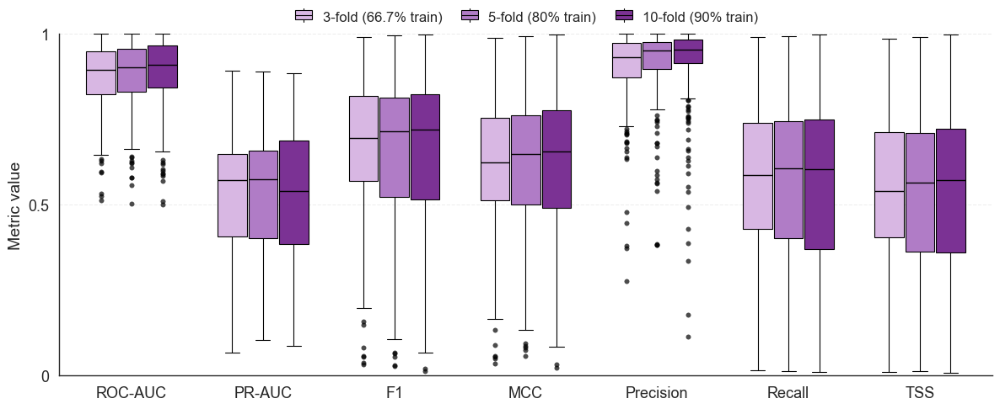

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.legend_handler import HandlerBase


sns.set_context(
    "paper",
    font_scale=1.15,
)

sns.set_style("white")




# ============================================================
# Raw predictive inputs (no Tukey filtering)
# ============================================================

import re


def _raw_foodweb_name(path):
    return re.sub(
        r"_tax_mass_results_random_wlnm_.*$",
        "",
        path.stem,
        flags=re.I,
    )


def load_raw_predictive_compat(
    result_root,
    expected_version,
    metric_specs,
    expected_runs,
    minimum_retained_runs,
    *,
    train_ratios=None,
    cvk_values=None,
    k_target=10,
    threshold=0.50,
    kfold=False,
    scenario=None,
):
    """Return raw web-level means in the legacy plotting schema.

    The legacy column names are retained only so that the original plotting,
    layout, scale, colour and export code remains byte-for-byte unchanged.
    MeanAfterTukey below is a compatibility alias for the arithmetic mean of
    every complete raw run unit; no Tukey fences or outlier exclusions occur.
    """
    metrics = [metric for metric, _ in metric_specs]
    labels = dict(metric_specs)
    files = sorted((result_root / "prediction_scores_logs").glob("*.csv"))
    if not files:
        raise FileNotFoundError(result_root / "prediction_scores_logs")

    required = {
        "Version",
        "TrainRatio",
        "ExperimentID",
        "Seed",
        "Threshold",
        "K",
        "CvK",
        "FoldID",
        "EmpiricalConnectance",
        *metrics,
    }
    frames = []
    for path in files:
        frame = pd.read_csv(
            path,
            usecols=lambda column: column in required,
        )
        missing = required.difference(frame.columns)
        if missing:
            raise ValueError(
                f"{path.name}: missing raw columns {sorted(missing)}"
            )
        frame["Foodweb"] = _raw_foodweb_name(path)
        frames.append(frame)

    raw = pd.concat(frames, ignore_index=True)
    for column in required.difference({"Version"}):
        raw[column] = pd.to_numeric(raw[column], errors="coerce")
    raw["TrainRatio"] = np.where(
        raw["TrainRatio"].abs().le(1.0),
        raw["TrainRatio"] * 100.0,
        raw["TrainRatio"],
    )
    raw = raw.loc[
        raw["Version"].eq(expected_version)
        & np.isclose(raw["Threshold"], threshold, atol=1e-9)
        & np.isclose(raw["K"], k_target, atol=1e-9)
    ].copy()
    if train_ratios is not None:
        requested = np.asarray(list(train_ratios), dtype=float)
        raw = raw.loc[
            raw["TrainRatio"].map(
                lambda value: np.isclose(
                    value,
                    requested,
                    atol=1e-8,
                ).any()
            )
        ].copy()
    if cvk_values is not None:
        raw = raw.loc[raw["CvK"].isin(cvk_values)].copy()
    if raw.empty:
        raise ValueError(f"No raw observations selected from {result_root}")

    metric_values = raw[metrics].to_numpy(float)
    if not np.isfinite(metric_values).all():
        raise ValueError(f"Non-finite raw predictive values in {result_root}")
    probability_metrics = [
        metric for metric in metrics if metric not in {"TestMCC", "TestTSS"}
    ]
    signed_metrics = [
        metric for metric in metrics if metric in {"TestMCC", "TestTSS"}
    ]
    if probability_metrics:
        values = raw[probability_metrics].to_numpy(float)
        if ((values < 0) | (values > 1)).any():
            raise ValueError("Raw probability metrics must be within [0, 1]")
    if signed_metrics:
        values = raw[signed_metrics].to_numpy(float)
        if ((values < -1) | (values > 1)).any():
            raise ValueError("Raw MCC/TSS values must be within [-1, 1]")

    group_columns = [
        "Foodweb",
        "Version",
        "TrainRatio",
        "Threshold",
        "K",
        "CvK",
    ]
    if kfold:
        experiment_columns = [*group_columns, "ExperimentID"]
        fold_check = (
            raw.groupby(experiment_columns, dropna=False)
            .agg(
                FoldRows=("FoldID", "size"),
                UniqueFolds=("FoldID", "nunique"),
            )
            .reset_index()
        )
        incomplete = fold_check.loc[
            ~fold_check["FoldRows"].eq(fold_check["CvK"])
            | ~fold_check["UniqueFolds"].eq(fold_check["CvK"])
        ]
        if not incomplete.empty:
            raise ValueError(
                "Incomplete repeated-CV experiments found:\n"
                + incomplete.head(10).to_string(index=False)
            )
        run_units = (
            raw.groupby(
                experiment_columns,
                dropna=False,
                as_index=False,
            )
            .agg(
                **{
                    metric: (metric, "mean")
                    for metric in metrics
                },
                EmpiricalConnectance=(
                    "EmpiricalConnectance",
                    "first",
                ),
            )
        )
    else:
        experiment_columns = [*group_columns, "ExperimentID"]
        if raw.duplicated(experiment_columns).any():
            raise ValueError(f"Duplicate raw ExperimentID rows in {result_root}")
        run_units = raw

    counts = run_units.groupby(group_columns, dropna=False).size()
    if not counts.eq(expected_runs).all():
        raise ValueError(
            f"{result_root.name}: expected {expected_runs} complete raw "
            "run units per group; observed "
            f"{counts.value_counts().to_dict()}"
        )

    wide = (
        run_units.groupby(
            group_columns,
            dropna=False,
            as_index=False,
        )
        .agg(
            **{
                metric: (metric, "mean")
                for metric in metrics
            },
            EmpiricalConnectance=(
                "EmpiricalConnectance",
                "first",
            ),
            RawRunUnits=("ExperimentID", "size"),
        )
    )
    long = wide.melt(
        id_vars=[
            *group_columns,
            "EmpiricalConnectance",
            "RawRunUnits",
        ],
        value_vars=metrics,
        var_name="Metric",
        value_name="MeanAfterTukey",
    )
    long["Scenario"] = scenario or result_root.name
    long["MetricLabel"] = long["Metric"].map(labels)
    long["MetricFamily"] = "predictive"
    long["SourceColumn"] = long["Metric"]
    long["ReferenceColumn"] = ""
    long["MeanBeforeTukey"] = long["MeanAfterTukey"]
    long["TotalRunUnits"] = long["RawRunUnits"]
    long["ValidRunsBeforeTukey"] = long["RawRunUnits"]
    long["InvalidRunsBeforeTukey"] = 0
    long["OutlierRunsExcluded"] = 0
    long["RetainedRunsAfterTukey"] = long["RawRunUnits"]
    long["ExpectedRuns"] = expected_runs
    long["MinimumRetainedRuns"] = minimum_retained_runs
    long["MeetsMinimumRetainedRuns"] = 1
    long["ReferenceValue"] = long["EmpiricalConnectance"]
    return long

# ============================================================
# Locate repository root
# ============================================================

def find_repo_root(start=Path.cwd()):
    start = Path(start).resolve()

    candidates = [
        start,
        *start.parents,
    ]

    fallback = Path(
        "/Users/acw792/Developer/qmul-phd-framework"
    )

    if fallback not in candidates:
        candidates.append(fallback)

    for path in candidates:
        if (
            (path / "src/matlab").is_dir()
            and (path / "docs").is_dir()
        ):
            return path

    raise RuntimeError(
        "Could not locate the qmul-phd-framework repository."
    )


REPO_ROOT = find_repo_root()


# ============================================================
# Input configuration
# ============================================================

PROTOCOL_NAME = (
    "tukey_iqr_1p5_min50pct_threshold0p50_v1"
)

RESULT_DIR = (
    REPO_ROOT
    / "src/matlab/data"
    / (
        "result_wlnm_dir_neg_kfold_20x290_"
        "cvK3-5-10_roleonly_thresh0p50_"
        "trophicv2_Apocrita"
    )
)

RETENTION_DIR = (
    RESULT_DIR
    / "retention_protocol"
    / PROTOCOL_NAME
)

INPUT_PATH = RESULT_DIR

MANIFEST_PATH = RESULT_DIR / "RUN_MANIFEST.txt"

OUT_DIR = RESULT_DIR / "figures_raw_unfiltered"

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

OUT_PATH = OUT_DIR / "predictive_metrics_wlnm_dir_neg_kfold_20runs_raw_unfiltered.png"


# ============================================================
# Experimental configuration
# ============================================================

THRESHOLD_TARGET = 0.50
K_TARGET = 10

EXPECTED_FOOD_WEBS = 290

# This is repeated k-fold CV, not the standard 50-run setup.
# Each K has 20 repeated-CV experiments and at least 50%
# must remain from all raw runs.
EXPECTED_REPEATED_CV_EXPERIMENTS = 20
MINIMUM_RETAINED_FRACTION = 1.00
MINIMUM_RETAINED_EXPERIMENTS = 20

CVK_ORDER = [
    3,
    5,
    10,
]

EXPECTED_SCENARIO = (
    "kfold_cvK3-5-10_roleonly_"
    "thresh0p50_trophicv2"
)

calculated_minimum = int(
    np.ceil(
        EXPECTED_REPEATED_CV_EXPERIMENTS
        * MINIMUM_RETAINED_FRACTION
    )
)

assert calculated_minimum == MINIMUM_RETAINED_EXPERIMENTS, (
    "The repeated-CV Tukey minimum is inconsistent."
)

SHOW_WEB_LEVEL_FLIERS = True

METRICS = [
    "ROC_AUC",
    "PR_AUC",
    "F1Score",
    "TestMCC",
    "Precision",
    "Recall",
    "TestTSS",
]

PLOT_METRICS = [
    ("ROC_AUC", "ROC-AUC"),
    ("PR_AUC", "PR-AUC"),
    ("F1Score", "F1"),
    ("TestMCC", "MCC"),
    ("Precision", "Precision"),
    ("Recall", "Recall"),
    ("TestTSS", "TSS"),
]


# ============================================================
# Helpers
# ============================================================

def cvk_label(k: int) -> str:
    train_ratio_map = {
        3: "66.7%",
        5: "80%",
        10: "90%",
    }

    if k in train_ratio_map:
        return (
            f"{k}-fold "
            f"({train_ratio_map[k]} train)"
        )

    return f"{k}-fold"


def validate_retention_manifest(manifest_path: Path) -> dict:
    if not (RESULT_DIR / "prediction_scores_logs").is_dir():
        raise FileNotFoundError(RESULT_DIR / "prediction_scores_logs")
    print("[INFO] Raw k-fold inputs validated; no Tukey filtering.")
    return {"source": str(RESULT_DIR)}

def load_tukey_web_level_metrics(input_path: Path):
    df = load_raw_predictive_compat(
        input_path,
        "WLNM_dir_neg_kfold",
        PLOT_METRICS,
        EXPECTED_REPEATED_CV_EXPERIMENTS,
        EXPECTED_REPEATED_CV_EXPERIMENTS,
        cvk_values=CVK_ORDER,
        k_target=K_TARGET,
        threshold=THRESHOLD_TARGET,
        kfold=True,
        scenario=EXPECTED_SCENARIO,
    )
    df["FW_KEY"] = df["Foodweb"].map(
        lambda value: " ".join(
            re.sub(r"[^a-z0-9]+", " ", str(value).casefold()).split()
        )
    )
    metric_values = (
        df.pivot(
            index=["Foodweb", "FW_KEY", "CvK"],
            columns="Metric",
            values="MeanAfterTukey",
        )
        .reset_index()
    )
    metric_values.columns.name = None
    metric_values["CvK_label"] = metric_values["CvK"].map(cvk_label)
    if metric_values.shape[0] != EXPECTED_FOOD_WEBS * len(CVK_ORDER):
        raise ValueError("Unexpected raw k-fold web-level shape")
    return df, metric_values

# ============================================================
# Custom legend
# ============================================================

class HandlerMiniBoxplot(HandlerBase):
    def create_artists(
        self,
        legend,
        orig_handle,
        xdescent,
        ydescent,
        width,
        height,
        fontsize,
        trans,
    ):
        facecolor = orig_handle[
            "facecolor"
        ]

        edgecolor = orig_handle.get(
            "edgecolor",
            "black",
        )

        linewidth = orig_handle.get(
            "linewidth",
            0.6,
        )

        y_shift = -0.06 * height
        cx = xdescent + 0.5 * width
        cy = ydescent + 0.5 * height + y_shift

        box_w = 0.8 * width
        box_h = 0.8 * height
        box_x = cx - box_w / 2
        box_y = cy - box_h / 2

        whisk_top_y = (
            box_y
            + box_h
            + 0.18 * height
        )

        whisk_bot_y = (
            box_y
            - 0.18 * height
        )

        box = Rectangle(
            (
                box_x,
                box_y,
            ),
            box_w,
            box_h,
            facecolor=facecolor,
            edgecolor=edgecolor,
            linewidth=linewidth,
            transform=trans,
        )

        median = Line2D(
            [
                box_x,
                box_x + box_w,
            ],
            [
                cy,
                cy,
            ],
            color=edgecolor,
            linewidth=linewidth,
            transform=trans,
        )

        whisker_top = Line2D(
            [
                cx,
                cx,
            ],
            [
                box_y + box_h,
                whisk_top_y,
            ],
            color=edgecolor,
            linewidth=linewidth,
            transform=trans,
        )

        whisker_bottom = Line2D(
            [
                cx,
                cx,
            ],
            [
                whisk_bot_y,
                box_y,
            ],
            color=edgecolor,
            linewidth=linewidth,
            transform=trans,
        )

        return [
            box,
            median,
            whisker_top,
            whisker_bottom,
        ]


# ============================================================
# Plot
# ============================================================

def plot_kfold_web_level_metrics(
    df_web: pd.DataFrame,
) -> None:
    if df_web.empty:
        raise ValueError(
            "No data are available to plot."
        )

    present_cvks = [
        k
        for k in CVK_ORDER
        if (
            df_web["CvK"] == k
        ).any()
    ]

    if len(present_cvks) < 2:
        raise ValueError(
            "Not enough CV regimes are present to plot."
        )

    cvk_palette = {
        3: "#D8B7E3",
        5: "#B07CC6",
        10: "#7B3294",
    }

    label_map = {
        k: cvk_label(k)
        for k in present_cvks
    }

    fig, ax = plt.subplots(
        figsize=(
            12,
            5,
        )
    )

    group_gap = 1.45

    group_centers = (
        1.0
        + np.arange(
            len(PLOT_METRICS)
        )
        * group_gap
    )

    offsets = np.linspace(
        -0.34,
        0.34,
        len(present_cvks),
    )

    box_width = 0.32

    for j, cvk in enumerate(
        present_cvks
    ):
        data_for_cvk = []
        positions_for_cvk = []

        for i, (
            metric,
            _,
        ) in enumerate(
            PLOT_METRICS
        ):
            values = (
                df_web.loc[
                    df_web["CvK"] == cvk,
                    metric,
                ]
                .dropna()
                .values
            )

            if len(values) == 0:
                continue

            data_for_cvk.append(
                values
            )

            positions_for_cvk.append(
                group_centers[i]
                + offsets[j]
            )

        if not data_for_cvk:
            continue

        boxplot = ax.boxplot(
            data_for_cvk,
            positions=positions_for_cvk,
            widths=box_width,
            patch_artist=True,
            manage_ticks=False,
            showfliers=SHOW_WEB_LEVEL_FLIERS,
            boxprops={
                "edgecolor": "black",
                "linewidth": 0.8,
            },
            medianprops={
                "color": "black",
                "linewidth": 1.0,
            },
            whiskerprops={
                "color": "black",
                "linewidth": 0.8,
            },
            capprops={
                "color": "black",
                "linewidth": 0.8,
            },
            flierprops={
                "marker": "o",
                "markersize": 4,
                "markerfacecolor": "black",
                "markeredgecolor": "black",
                "markeredgewidth": 0.2,
                "alpha": 0.7,
            },
        )

        for box in boxplot["boxes"]:
            box.set_facecolor(
                cvk_palette[
                    cvk
                ]
            )

    legend_handles = [
        {
            "facecolor": cvk_palette[k],
            "edgecolor": "black",
            "linewidth": 0.8,
        }
        for k in present_cvks
    ]

    ax.set_xlim(
        group_centers[0] - 0.8,
        group_centers[-1] + 0.8,
    )

    ax.set_ylim(
        0,
        1.0,
    )

    ax.set_xticks(
        group_centers
    )

    ax.set_xticklabels(
        [
            label
            for _, label in PLOT_METRICS
        ],
        ha="center",
        fontsize=13,
    )

    ax.set_ylabel(
        "Metric value",
        fontsize=14,
    )

    ax.set_xlabel("")

    ax.tick_params(
        axis="y",
        labelsize=13,
    )

    ax.set_yticks(
        [
            0,
            0.5,
            1.0,
        ]
    )

    ax.set_yticklabels(
        [
            "0",
            "0.5",
            "1",
        ]
    )

    ax.grid(
        True,
        axis="y",
        linestyle="--",
        alpha=0.35,
    )

    sns.despine(
        ax=ax
    )

    ax.legend(
        handles=legend_handles,
        labels=[
            label_map[k]
            for k in present_cvks
        ],
        handler_map={
            dict: HandlerMiniBoxplot()
        },
        loc="lower center",
        bbox_to_anchor=(
            0.5,
            1,
        ),
        ncol=len(
            present_cvks
        ),
        frameon=False,
        fontsize=12,
        handlelength=1.5,
        handleheight=0.9,
        handletextpad=0.6,
        borderpad=0.2,
        labelspacing=0.45,
        columnspacing=1.2,
    )

    plt.tight_layout()

    fig.savefig(
        OUT_PATH,
        dpi=300,
        bbox_inches="tight",
    )

    print(
        f"[INFO] Saved figure: "
        f"{OUT_PATH}"
    )

    plt.show()


# ============================================================
# Run
# ============================================================

retention_manifest = validate_retention_manifest(
    MANIFEST_PATH
)

df_retained, df_web = (
    load_tukey_web_level_metrics(
        INPUT_PATH
    )
)

print(
    "\n[INFO] Raw-unfiltered metric-level shape:"
)

print(
    df_retained.shape
)

print(
    "\n[INFO] Web-level shape:"
)

print(
    df_web.shape
)

print(
    "\n[INFO] Food-web count per CvK:"
)

print(
    df_web
    .groupby(
        "CvK"
    )["Foodweb"]
    .nunique()
)

retention_summary = (
    df_retained
    .groupby(
        "CvK"
    )
    .agg(
        FoodWebs=(
            "Foodweb",
            "nunique",
        ),
        Metrics=(
            "Metric",
            "nunique",
        ),
        TrainRatio=(
            "TrainRatio",
            "median",
        ),
        Threshold=(
            "Threshold",
            "median",
        ),
        ExpectedExperiments=(
            "ExpectedRuns",
            "min",
        ),
        RequiredMinimumExperiments=(
            "MinimumRetainedRuns",
            "min",
        ),
        MinimumRetainedExperiments=(
            "RetainedRunsAfterTukey",
            "min",
        ),
        MedianRetainedExperiments=(
            "RetainedRunsAfterTukey",
            "median",
        ),
        MaximumRetainedExperiments=(
            "RetainedRunsAfterTukey",
            "max",
        ),
    )
    .reset_index()
)

print(
    "\n[INFO] Raw run-count summary:"
)

display(
    retention_summary
)

summary_rows = []

for cvk in CVK_ORDER:
    for metric, metric_label in PLOT_METRICS:
        values = (
            df_web.loc[
                df_web["CvK"] == cvk,
                metric,
            ]
            .dropna()
        )

        if values.empty:
            continue

        summary_rows.append(
            {
                "CvK": cvk,
                "Label": cvk_label(
                    cvk
                ),
                "Metric": metric_label,
                "N food webs": int(
                    values.shape[0]
                ),
                "Mean": values.mean(),
                "Median": values.median(),
                "SD": values.std(
                    ddof=1
                ),
                "Variance": values.var(
                    ddof=1
                ),
            }
        )

summary_table = pd.DataFrame(
    summary_rows
)

for column in [
    "Mean",
    "Median",
    "SD",
    "Variance",
]:
    summary_table[column] = (
        summary_table[column]
        .round(4)
    )

print(
    "\n=== Web-level k-fold predictive metric summary "
    "from all raw runs at threshold 0.5 ==="
)

display(
    summary_table
)

print(
    "\n[INFO] Final raw k-fold configuration:"
)

print(
    f"  expected_repeated_cv_experiments="
    f"{EXPECTED_REPEATED_CV_EXPERIMENTS}"
)

print(
    f"  minimum_retained_fraction="
    f"{MINIMUM_RETAINED_FRACTION:.2f}"
)

print(
    f"  minimum_retained_experiments="
    f"{MINIMUM_RETAINED_EXPERIMENTS}/"
    f"{EXPECTED_REPEATED_CV_EXPERIMENTS}"
)

plot_kfold_web_level_metrics(
    df_web
)

[INFO] Raw role-only input validated; no Tukey filtering.
[INFO] Raw run completeness validated: at least 100 of 100 runs per food web and metric.
[INFO] Actual retained-run range: 100–100
[INFO] Filtered food webs by size: kept 290 / 290 (>= 0 nodes).

[INFO] Retained metric-food-web observations:
Total rows: 2,030
Rows per ecosystem:
EcosystemType
lakes                      385
marine                     938
streams                    196
terrestrial aboveground    147
terrestrial belowground    364
dtype: int64

[INFO] Web-level observations after Tukey filtering:
Total web-level rows: 290


,EcosystemType,FoodWebs,ExpectedRuns,RequiredMinimumRuns,MinRunsAveraged,MedianRunsAveraged,MaxRunsAveraged
0,lakes,55,100,100,100,100.0,100
1,marine,134,100,100,100,100.0,100
2,streams,28,100,100,100,100.0,100
3,terrestrial aboveground,21,100,100,100,100.0,100
4,terrestrial belowground,52,100,100,100,100.0,100



=== Web-level precision median and variance by ecosystem ===


,EcosystemType,n_foodwebs,Precision_Median,Precision_Variance
0,lakes,55,0.9852,0.009073
1,marine,134,0.9507,0.010029
2,streams,28,0.9852,0.048684
3,terrestrial aboveground,21,0.9193,0.005577
4,terrestrial belowground,52,0.9227,0.000295



=== Ecosystems with lowest/highest median precision and variance ===
Lowest median precision:  terrestrial aboveground (median = 0.9193, variance = 0.005577, n_foodwebs = 21)
Highest median precision: lakes (median = 0.9852, variance = 0.009073, n_foodwebs = 55)
Lowest variance:          terrestrial belowground (variance = 0.000295, median = 0.9227, n_foodwebs = 52)
Highest variance:         streams (variance = 0.048684, median = 0.9852, n_foodwebs = 28)
[INFO] Saved figure: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/figures_raw_unfiltered/predictive_metrics_wlnm_dir_neg_train90_by_ecosystem_raw_unfiltered.png
[INFO] Configuration: eligibility=role_only, mass_constraint=False, random_topup=True, negative_positive_ratio=2:1, check_connectivity=False, adaptive_connectivity=False, classification_threshold=0.50, train_ratio=90.
[INFO] Final raw-input configuration:
  expected_runs=100
  mini

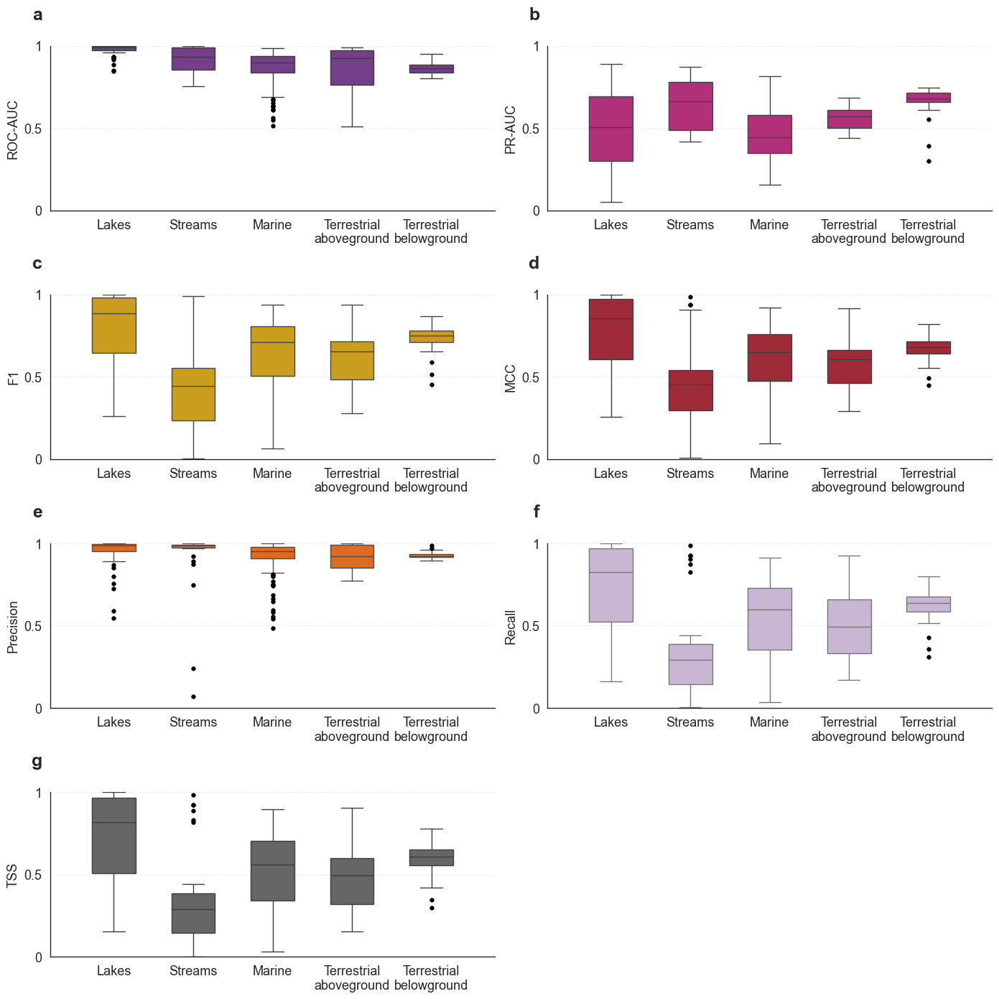

In [9]:
import json
import math

from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from IPython.display import display


sns.set_context(
    "paper"
)

sns.set_style(
    "white"
)




# ============================================================
# Raw predictive inputs (no Tukey filtering)
# ============================================================

import re


def _raw_foodweb_name(path):
    return re.sub(
        r"_tax_mass_results_random_wlnm_.*$",
        "",
        path.stem,
        flags=re.I,
    )


def load_raw_predictive_compat(
    result_root,
    expected_version,
    metric_specs,
    expected_runs,
    minimum_retained_runs,
    *,
    train_ratios=None,
    cvk_values=None,
    k_target=10,
    threshold=0.50,
    kfold=False,
    scenario=None,
):
    """Return raw web-level means in the legacy plotting schema.

    The legacy column names are retained only so that the original plotting,
    layout, scale, colour and export code remains byte-for-byte unchanged.
    MeanAfterTukey below is a compatibility alias for the arithmetic mean of
    every complete raw run unit; no Tukey fences or outlier exclusions occur.
    """
    metrics = [metric for metric, _ in metric_specs]
    labels = dict(metric_specs)
    files = sorted((result_root / "prediction_scores_logs").glob("*.csv"))
    if not files:
        raise FileNotFoundError(result_root / "prediction_scores_logs")

    required = {
        "Version",
        "TrainRatio",
        "ExperimentID",
        "Seed",
        "Threshold",
        "K",
        "CvK",
        "FoldID",
        "EmpiricalConnectance",
        *metrics,
    }
    frames = []
    for path in files:
        frame = pd.read_csv(
            path,
            usecols=lambda column: column in required,
        )
        missing = required.difference(frame.columns)
        if missing:
            raise ValueError(
                f"{path.name}: missing raw columns {sorted(missing)}"
            )
        frame["Foodweb"] = _raw_foodweb_name(path)
        frames.append(frame)

    raw = pd.concat(frames, ignore_index=True)
    for column in required.difference({"Version"}):
        raw[column] = pd.to_numeric(raw[column], errors="coerce")
    raw["TrainRatio"] = np.where(
        raw["TrainRatio"].abs().le(1.0),
        raw["TrainRatio"] * 100.0,
        raw["TrainRatio"],
    )
    raw = raw.loc[
        raw["Version"].eq(expected_version)
        & np.isclose(raw["Threshold"], threshold, atol=1e-9)
        & np.isclose(raw["K"], k_target, atol=1e-9)
    ].copy()
    if train_ratios is not None:
        requested = np.asarray(list(train_ratios), dtype=float)
        raw = raw.loc[
            raw["TrainRatio"].map(
                lambda value: np.isclose(
                    value,
                    requested,
                    atol=1e-8,
                ).any()
            )
        ].copy()
    if cvk_values is not None:
        raw = raw.loc[raw["CvK"].isin(cvk_values)].copy()
    if raw.empty:
        raise ValueError(f"No raw observations selected from {result_root}")

    metric_values = raw[metrics].to_numpy(float)
    if not np.isfinite(metric_values).all():
        raise ValueError(f"Non-finite raw predictive values in {result_root}")
    probability_metrics = [
        metric for metric in metrics if metric not in {"TestMCC", "TestTSS"}
    ]
    signed_metrics = [
        metric for metric in metrics if metric in {"TestMCC", "TestTSS"}
    ]
    if probability_metrics:
        values = raw[probability_metrics].to_numpy(float)
        if ((values < 0) | (values > 1)).any():
            raise ValueError("Raw probability metrics must be within [0, 1]")
    if signed_metrics:
        values = raw[signed_metrics].to_numpy(float)
        if ((values < -1) | (values > 1)).any():
            raise ValueError("Raw MCC/TSS values must be within [-1, 1]")

    group_columns = [
        "Foodweb",
        "Version",
        "TrainRatio",
        "Threshold",
        "K",
        "CvK",
    ]
    if kfold:
        experiment_columns = [*group_columns, "ExperimentID"]
        fold_check = (
            raw.groupby(experiment_columns, dropna=False)
            .agg(
                FoldRows=("FoldID", "size"),
                UniqueFolds=("FoldID", "nunique"),
            )
            .reset_index()
        )
        incomplete = fold_check.loc[
            ~fold_check["FoldRows"].eq(fold_check["CvK"])
            | ~fold_check["UniqueFolds"].eq(fold_check["CvK"])
        ]
        if not incomplete.empty:
            raise ValueError(
                "Incomplete repeated-CV experiments found:\n"
                + incomplete.head(10).to_string(index=False)
            )
        run_units = (
            raw.groupby(
                experiment_columns,
                dropna=False,
                as_index=False,
            )
            .agg(
                **{
                    metric: (metric, "mean")
                    for metric in metrics
                },
                EmpiricalConnectance=(
                    "EmpiricalConnectance",
                    "first",
                ),
            )
        )
    else:
        experiment_columns = [*group_columns, "ExperimentID"]
        if raw.duplicated(experiment_columns).any():
            raise ValueError(f"Duplicate raw ExperimentID rows in {result_root}")
        run_units = raw

    counts = run_units.groupby(group_columns, dropna=False).size()
    if not counts.eq(expected_runs).all():
        raise ValueError(
            f"{result_root.name}: expected {expected_runs} complete raw "
            "run units per group; observed "
            f"{counts.value_counts().to_dict()}"
        )

    wide = (
        run_units.groupby(
            group_columns,
            dropna=False,
            as_index=False,
        )
        .agg(
            **{
                metric: (metric, "mean")
                for metric in metrics
            },
            EmpiricalConnectance=(
                "EmpiricalConnectance",
                "first",
            ),
            RawRunUnits=("ExperimentID", "size"),
        )
    )
    long = wide.melt(
        id_vars=[
            *group_columns,
            "EmpiricalConnectance",
            "RawRunUnits",
        ],
        value_vars=metrics,
        var_name="Metric",
        value_name="MeanAfterTukey",
    )
    long["Scenario"] = scenario or result_root.name
    long["MetricLabel"] = long["Metric"].map(labels)
    long["MetricFamily"] = "predictive"
    long["SourceColumn"] = long["Metric"]
    long["ReferenceColumn"] = ""
    long["MeanBeforeTukey"] = long["MeanAfterTukey"]
    long["TotalRunUnits"] = long["RawRunUnits"]
    long["ValidRunsBeforeTukey"] = long["RawRunUnits"]
    long["InvalidRunsBeforeTukey"] = 0
    long["OutlierRunsExcluded"] = 0
    long["RetainedRunsAfterTukey"] = long["RawRunUnits"]
    long["ExpectedRuns"] = expected_runs
    long["MinimumRetainedRuns"] = minimum_retained_runs
    long["MeetsMinimumRetainedRuns"] = 1
    long["ReferenceValue"] = long["EmpiricalConnectance"]
    return long

# ============================================================
# Locate repository root
# ============================================================

def find_repo_root(start=Path.cwd()):
    start = Path(start).resolve()

    candidates = [
        start,
        *start.parents,
    ]

    fallback = Path(
        "/Users/acw792/Developer/qmul-phd-framework"
    )

    if fallback not in candidates:
        candidates.append(fallback)

    for path in candidates:
        if (
            (path / "src/matlab").is_dir()
            and (path / "docs").is_dir()
        ):
            return path

    raise RuntimeError(
        "Could not locate the qmul-phd-framework repository."
    )


REPO_ROOT = find_repo_root()


# ============================================================
# Final role-only configuration
# ============================================================

CHECK_CONNECTIVITY = False
ADAPTIVE_CONNECTIVITY = False
CLASSIFICATION_THRESHOLD = 0.50

MIN_NODES = 0
TRAIN_RATIO_TARGET = 90

SHOW_WEB_LEVEL_FLIERS = True

# Tukey is applied independently across 100 runs for each
# food-web × metric group.
#
# Keep the agreed absolute minimum of 25 retained runs.
EXPECTED_RUNS = 100
MINIMUM_RETAINED_FRACTION = 1.00
MINIMUM_RETAINED_RUNS = 100

PROTOCOL_NAME = (
    "tukey_iqr_1p5_min25runs_threshold0p50_v1"
)

EXPECTED_SCENARIO = (
    "result_wlnm_dir_neg_roleonly_trophicv2_"
    "100x290_train10-90_Apocrita_20260910_011848"
)

calculated_minimum = math.ceil(
    EXPECTED_RUNS
    * MINIMUM_RETAINED_FRACTION
)

assert calculated_minimum == MINIMUM_RETAINED_RUNS, (
    "The standard Tukey minimum is inconsistent."
)


# ============================================================
# Final role-only input data
# ============================================================

RESULT_ROOT = (
    REPO_ROOT
    / "src/matlab/data"
    / (
        "result_wlnm_dir_neg_roleonly_trophicv2_"
        "100x290_train10-90_Apocrita_20260910_011848"
    )
)

RETENTION_ROOT = (
    RESULT_ROOT
    / "retention_protocol"
    / PROTOCOL_NAME
)

PREDICTIVE_INPUT = RESULT_ROOT

RETENTION_MANIFEST = (
    RETENTION_ROOT
    / "retention_manifest.json"
)

ECOSYSTEM_FILE = (
    REPO_ROOT
    / "src/matlab/data/foodwebs_mat"
    / "foodweb_metrics_ecosystem.csv"
)

OUT_DIR = RESULT_ROOT / "figures_raw_unfiltered"

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

OUT_PATH = OUT_DIR / "predictive_metrics_wlnm_dir_neg_train90_by_ecosystem_raw_unfiltered.png"


# ============================================================
# Metrics
# ============================================================

METRIC_ORDER = [
    "ROC_AUC",
    "PR_AUC",
    "F1Score",
    "TestMCC",
    "Precision",
    "Recall",
    "TestTSS",
]

metric_palette = {
    "ROC_AUC": "#7B3294",
    "PR_AUC": "#C51B7D",
    "Precision": "#FE6100",
    "Recall": "#CAB2D6",
    "F1Score": "#E6AB02",
    "TestMCC": "#B2182B",
    "TestTSS": "#666666",
}

metric_label_map = {
    "ROC_AUC": "ROC-AUC",
    "PR_AUC": "PR-AUC",
    "F1Score": "F1",
    "TestMCC": "MCC",
    "Precision": "Precision",
    "Recall": "Recall",
    "TestTSS": "TSS",
}


# ============================================================
# Validate raw inputs
# ============================================================

if not (RESULT_ROOT / "prediction_scores_logs").is_dir():
    raise FileNotFoundError(RESULT_ROOT / "prediction_scores_logs")
if not ECOSYSTEM_FILE.is_file():
    raise FileNotFoundError(ECOSYSTEM_FILE)
print("[INFO] Raw role-only input validated; no Tukey filtering.")

# ============================================================
# Normalisation helpers
# ============================================================

def normalize_colname(value):
    return (
        str(value)
        .strip()
        .lower()
        .replace(" ", "")
        .replace(".", "")
        .replace("-", "")
        .replace("_", "")
    )


def normalize_foodweb(value):
    value = Path(
        str(value).strip()
    ).name

    for extension in (
        ".mat",
        ".csv",
    ):
        if value.lower().endswith(
            extension
        ):
            value = value[
                :-len(extension)
            ].rstrip()

    for suffix in (
        "_tax_mass",
        "_taxmass",
    ):
        if value.lower().endswith(
            suffix
        ):
            value = value[
                :-len(suffix)
            ].rstrip()

    return " ".join(
        value.casefold().split()
    )


# ============================================================
# Load ecosystem metadata
# ============================================================

df_ecosystem = pd.read_csv(
    ECOSYSTEM_FILE
)

node_candidates = {
    "nnodes",
    "numnodes",
    "nodes",
    "nodecount",
    "n",
    "s",
}

norm_map = {
    normalize_colname(column): column
    for column in df_ecosystem.columns
}

node_col = next(
    (
        norm_map[candidate]
        for candidate in node_candidates
        if candidate in norm_map
    ),
    None,
)

if node_col is None:
    raise RuntimeError(
        "Could not find a node-count column in "
        "ecosystem metadata."
    )

if (
    "Foodweb" not in df_ecosystem.columns
    or "EcosystemType"
    not in df_ecosystem.columns
):
    raise RuntimeError(
        "The ecosystem metadata must contain "
        "Foodweb and EcosystemType."
    )

df_ecosystem[
    node_col
] = pd.to_numeric(
    df_ecosystem[node_col],
    errors="coerce",
)

df_ecosystem["FW_KEY"] = (
    df_ecosystem["Foodweb"]
    .apply(
        normalize_foodweb
    )
)

duplicated_metadata = (
    df_ecosystem.duplicated(
        subset=["FW_KEY"],
        keep=False,
    )
)

if duplicated_metadata.any():
    inconsistent_metadata = (
        df_ecosystem.loc[
            duplicated_metadata,
            [
                "FW_KEY",
                "EcosystemType",
                node_col,
            ],
        ]
        .groupby(
            "FW_KEY"
        )
        .nunique(
            dropna=False
        )
    )

    inconsistent_metadata = (
        inconsistent_metadata[
            (
                inconsistent_metadata[
                    "EcosystemType"
                ] > 1
            )
            | (
                inconsistent_metadata[
                    node_col
                ] > 1
            )
        ]
    )

    if not inconsistent_metadata.empty:
        display(
            inconsistent_metadata
        )

        raise ValueError(
            "Conflicting metadata were found for one "
            "or more normalised food-web names."
        )

metadata_for_merge = (
    df_ecosystem[
        [
            "FW_KEY",
            "EcosystemType",
            node_col,
        ]
    ]
    .drop_duplicates(
        subset=["FW_KEY"],
        keep="first",
    )
)


# ============================================================
# Load final role-only Tukey-filtered predictive data
# ============================================================

predictive_raw = load_raw_predictive_compat(
    RESULT_ROOT,
    "WLNM_dir_neg",
    [(metric, metric_label_map[metric]) for metric in METRIC_ORDER],
    EXPECTED_RUNS,
    EXPECTED_RUNS,
    train_ratios=[TRAIN_RATIO_TARGET],
    scenario=EXPECTED_SCENARIO,
)

required_columns = {
    "Scenario",
    "Foodweb",
    "Version",
    "TrainRatio",
    "Threshold",
    "Metric",
    "MetricFamily",
    "MeanAfterTukey",
    "RetainedRunsAfterTukey",
    "ExpectedRuns",
    "MinimumRetainedRuns",
    "OutlierRunsExcluded",
    "MeetsMinimumRetainedRuns",
}

missing_columns = sorted(
    required_columns.difference(
        predictive_raw.columns
    )
)

if missing_columns:
    raise ValueError(
        "The predictive Raw prediction input is missing columns:\n  "
        + "\n  ".join(
            missing_columns
        )
    )

numeric_columns = [
    "TrainRatio",
    "Threshold",
    "MeanAfterTukey",
    "RetainedRunsAfterTukey",
    "ExpectedRuns",
    "MinimumRetainedRuns",
    "OutlierRunsExcluded",
    "MeetsMinimumRetainedRuns",
]

for column in numeric_columns:
    predictive_raw[column] = pd.to_numeric(
        predictive_raw[column],
        errors="coerce",
    )


# ============================================================
# Select requested role-only configuration
# ============================================================

predictive_target = predictive_raw.loc[
    predictive_raw["Scenario"].eq(
        EXPECTED_SCENARIO
    )
    & predictive_raw["Version"].eq(
        "WLNM_dir_neg"
    )
    & (
        predictive_raw["MetricFamily"]
        .astype(str)
        .str.casefold()
        .eq("predictive")
    )
    & predictive_raw["Metric"].isin(
        METRIC_ORDER
    )
    & np.isclose(
        predictive_raw["TrainRatio"],
        TRAIN_RATIO_TARGET,
        atol=1e-9,
        equal_nan=False,
    )
    & np.isclose(
        predictive_raw["Threshold"],
        CLASSIFICATION_THRESHOLD,
        atol=1e-9,
        equal_nan=False,
    )
].copy()

if predictive_target.empty:
    raise RuntimeError(
        "No final role-only predictive results were found "
        f"for TrainRatio={TRAIN_RATIO_TARGET} and "
        f"Threshold={CLASSIFICATION_THRESHOLD:.2f}."
    )


# ============================================================
# Validate minimum 25 retained runs
# ============================================================

observed_expected_runs = set(
    predictive_target["ExpectedRuns"]
    .dropna()
    .astype(int)
    .unique()
)

if observed_expected_runs != {
    EXPECTED_RUNS
}:
    raise ValueError(
        "Unexpected number of runs in the Raw prediction input:\n"
        f"  expected: {EXPECTED_RUNS}\n"
        f"  observed: {sorted(observed_expected_runs)}"
    )

observed_minimums = set(
    predictive_target["MinimumRetainedRuns"]
    .dropna()
    .astype(int)
    .unique()
)

if observed_minimums != {
    MINIMUM_RETAINED_RUNS
}:
    raise ValueError(
        "Unexpected Tukey minimum in the predictive input:\n"
        f"  expected: {MINIMUM_RETAINED_RUNS}\n"
        f"  observed: {sorted(observed_minimums)}"
    )

incorrectly_retained = predictive_target[
    predictive_target[
        "MeetsMinimumRetainedRuns"
    ].eq(1)
    & predictive_target[
        "RetainedRunsAfterTukey"
    ].lt(
        MINIMUM_RETAINED_RUNS
    )
]

if not incorrectly_retained.empty:
    display(
        incorrectly_retained[
            [
                "Foodweb",
                "Metric",
                "ExpectedRuns",
                "RetainedRunsAfterTukey",
                "MinimumRetainedRuns",
                "MeetsMinimumRetainedRuns",
            ]
        ]
    )

    raise ValueError(
        "At least one food-web metric is marked as retained "
        f"despite having fewer than "
        f"{MINIMUM_RETAINED_RUNS} runs."
    )

predictive = predictive_target.loc[
    predictive_target["ExpectedRuns"].eq(
        EXPECTED_RUNS
    )
    & predictive_target[
        "MinimumRetainedRuns"
    ].eq(
        MINIMUM_RETAINED_RUNS
    )
    & predictive_target[
        "RetainedRunsAfterTukey"
    ].ge(
        MINIMUM_RETAINED_RUNS
    )
    & predictive_target[
        "MeetsMinimumRetainedRuns"
    ].eq(1)
    & predictive_target[
        "MeanAfterTukey"
    ].notna()
].copy()

if predictive.empty:
    raise RuntimeError(
        "No predictive results remain after validating "
        f"the minimum of {MINIMUM_RETAINED_RUNS} runs."
    )

print(
    "[INFO] Raw run completeness validated: "
    f"at least {MINIMUM_RETAINED_RUNS} of "
    f"{EXPECTED_RUNS} runs per food web and metric."
)

print(
    "[INFO] Actual retained-run range: "
    f"{int(predictive['RetainedRunsAfterTukey'].min())}–"
    f"{int(predictive['RetainedRunsAfterTukey'].max())}"
)


# ============================================================
# Validate unique food-web × metric observations
# ============================================================

predictive["FW_KEY"] = (
    predictive["Foodweb"]
    .apply(
        normalize_foodweb
    )
)

duplicated_rows = predictive.duplicated(
    subset=[
        "FW_KEY",
        "Metric",
    ],
    keep=False,
)

if duplicated_rows.any():
    duplicated = (
        predictive.loc[
            duplicated_rows,
            [
                "Foodweb",
                "Metric",
                "TrainRatio",
                "Threshold",
            ],
        ]
        .sort_values(
            [
                "Metric",
                "Foodweb",
            ]
        )
    )

    display(
        duplicated
    )

    raise ValueError(
        "More than one retained row was found per "
        "food web and metric."
    )


# ============================================================
# Merge with ecosystem metadata
# ============================================================

predictive = predictive.merge(
    metadata_for_merge,
    on="FW_KEY",
    how="left",
    validate="many_to_one",
)

missing_ecosystem = (
    predictive["EcosystemType"]
    .isna()
)

if missing_ecosystem.any():
    missing_foodwebs = sorted(
        predictive.loc[
            missing_ecosystem,
            "Foodweb",
        ]
        .astype(str)
        .unique()
    )

    raise ValueError(
        "Ecosystem metadata could not be matched for "
        f"{len(missing_foodwebs)} food webs:\n  "
        + "\n  ".join(
            missing_foodwebs[:30]
        )
    )


# ============================================================
# Apply node-count filter
# ============================================================

before_n = (
    predictive["FW_KEY"]
    .nunique()
)

predictive = predictive.loc[
    predictive[node_col].ge(
        MIN_NODES
    )
].copy()

after_n = (
    predictive["FW_KEY"]
    .nunique()
)

print(
    f"[INFO] Filtered food webs by size: "
    f"kept {after_n} / {before_n} "
    f"(>= {MIN_NODES} nodes)."
)

if predictive.empty:
    raise ValueError(
        f"No food webs remain after filtering "
        f"Nodes >= {MIN_NODES}."
    )

print(
    "\n[INFO] Retained metric-food-web observations:"
)

print(
    f"Total rows: "
    f"{len(predictive):,}"
)

print(
    "Rows per ecosystem:"
)

print(
    predictive
    .groupby(
        "EcosystemType"
    )
    .size()
)


# ============================================================
# Adapt input to web-level structure
# ============================================================

metric_values = (
    predictive
    .pivot(
        index=[
            "Foodweb",
            "FW_KEY",
            "EcosystemType",
            node_col,
        ],
        columns="Metric",
        values="MeanAfterTukey",
    )
    .reset_index()
)

metric_values.columns.name = None

missing_metrics = [
    metric
    for metric in METRIC_ORDER
    if metric not in metric_values.columns
]

if missing_metrics:
    raise ValueError(
        "The following predictive metrics are missing "
        "after pivoting:\n  "
        + "\n  ".join(
            missing_metrics
        )
    )

retention_by_web = (
    predictive
    .groupby(
        [
            "Foodweb",
            "FW_KEY",
        ],
        as_index=False,
    )
    .agg(
        ExpectedRuns=(
            "ExpectedRuns",
            "min",
        ),
        RequiredMinimumRuns=(
            "MinimumRetainedRuns",
            "min",
        ),
        RunsAveraged=(
            "RetainedRunsAfterTukey",
            "min",
        ),
        MaximumRunsAveraged=(
            "RetainedRunsAfterTukey",
            "max",
        ),
        TotalOutlierRunsExcluded=(
            "OutlierRunsExcluded",
            "sum",
        ),
    )
)

df_web = metric_values.merge(
    retention_by_web,
    on=[
        "Foodweb",
        "FW_KEY",
    ],
    how="left",
    validate="one_to_one",
)

print(
    "\n[INFO] Web-level observations after "
    "Tukey filtering:"
)

print(
    f"Total web-level rows: "
    f"{len(df_web):,}"
)

display(
    df_web
    .groupby(
        "EcosystemType"
    )
    .agg(
        FoodWebs=(
            "Foodweb",
            "nunique",
        ),
        ExpectedRuns=(
            "ExpectedRuns",
            "min",
        ),
        RequiredMinimumRuns=(
            "RequiredMinimumRuns",
            "min",
        ),
        MinRunsAveraged=(
            "RunsAveraged",
            "min",
        ),
        MedianRunsAveraged=(
            "RunsAveraged",
            "median",
        ),
        MaxRunsAveraged=(
            "MaximumRunsAveraged",
            "max",
        ),
    )
    .reset_index()
)


# ============================================================
# Precision summary by ecosystem
# ============================================================

precision_summary = (
    df_web
    .dropna(
        subset=[
            "EcosystemType",
            "Precision",
        ]
    )
    .groupby(
        "EcosystemType",
        as_index=False,
    )
    .agg(
        n_foodwebs=(
            "Foodweb",
            "nunique",
        ),
        Precision_Median=(
            "Precision",
            "median",
        ),
        Precision_Variance=(
            "Precision",
            lambda values: values.var(
                ddof=1
            ),
        ),
    )
)

precision_summary[
    "Precision_Median"
] = (
    precision_summary[
        "Precision_Median"
    ]
    .round(4)
)

precision_summary[
    "Precision_Variance"
] = (
    precision_summary[
        "Precision_Variance"
    ]
    .round(6)
)

print(
    "\n=== Web-level precision median and "
    "variance by ecosystem ==="
)

display(
    precision_summary
)

if precision_summary.empty:
    raise ValueError(
        "The precision summary is empty."
    )

lowest_precision = precision_summary.loc[
    precision_summary[
        "Precision_Median"
    ].idxmin()
]

highest_precision = precision_summary.loc[
    precision_summary[
        "Precision_Median"
    ].idxmax()
]

valid_variance = precision_summary.dropna(
    subset=[
        "Precision_Variance"
    ]
)

if valid_variance.empty:
    raise ValueError(
        "Precision variance could not be calculated "
        "for any ecosystem."
    )

lowest_variance = valid_variance.loc[
    valid_variance[
        "Precision_Variance"
    ].idxmin()
]

highest_variance = valid_variance.loc[
    valid_variance[
        "Precision_Variance"
    ].idxmax()
]

print(
    "\n=== Ecosystems with lowest/highest "
    "median precision and variance ==="
)

print(
    f"Lowest median precision:  "
    f"{lowest_precision['EcosystemType']} "
    f"(median = "
    f"{lowest_precision['Precision_Median']}, "
    f"variance = "
    f"{lowest_precision['Precision_Variance']}, "
    f"n_foodwebs = "
    f"{lowest_precision['n_foodwebs']})"
)

print(
    f"Highest median precision: "
    f"{highest_precision['EcosystemType']} "
    f"(median = "
    f"{highest_precision['Precision_Median']}, "
    f"variance = "
    f"{highest_precision['Precision_Variance']}, "
    f"n_foodwebs = "
    f"{highest_precision['n_foodwebs']})"
)

print(
    f"Lowest variance:          "
    f"{lowest_variance['EcosystemType']} "
    f"(variance = "
    f"{lowest_variance['Precision_Variance']}, "
    f"median = "
    f"{lowest_variance['Precision_Median']}, "
    f"n_foodwebs = "
    f"{lowest_variance['n_foodwebs']})"
)

print(
    f"Highest variance:         "
    f"{highest_variance['EcosystemType']} "
    f"(variance = "
    f"{highest_variance['Precision_Variance']}, "
    f"median = "
    f"{highest_variance['Precision_Median']}, "
    f"n_foodwebs = "
    f"{highest_variance['n_foodwebs']})"
)


# ============================================================
# Prepare long-format web-level data
# ============================================================

df_plot = df_web.melt(
    id_vars=[
        "Foodweb",
        "EcosystemType",
        "RunsAveraged",
    ],
    value_vars=METRIC_ORDER,
    var_name="Metric",
    value_name="Value",
)


# ============================================================
# Preferred ecosystem order
# ============================================================

preferred_ecosystem_order = [
    "lakes",
    "streams",
    "marine",
    "terrestrial aboveground",
    "terrestrial belowground",
]

ecosystems_present = (
    df_web["EcosystemType"]
    .dropna()
    .astype(str)
    .str.strip()
    .drop_duplicates()
    .tolist()
)

eco_lookup = {
    ecosystem.lower(): ecosystem
    for ecosystem in ecosystems_present
}

ecosystem_order = [
    eco_lookup[ecosystem]
    for ecosystem
    in preferred_ecosystem_order
    if ecosystem in eco_lookup
]

ecosystem_order += [
    ecosystem
    for ecosystem in ecosystems_present
    if ecosystem.lower()
    not in set(
        preferred_ecosystem_order
    )
]


# ============================================================
# Ecosystem labels
# ============================================================

labels_map = (
    df_web[
        [
            "Foodweb",
            "EcosystemType",
        ]
    ]
    .drop_duplicates()
    .groupby(
        "EcosystemType"
    )["Foodweb"]
    .nunique()
    .to_dict()
)


def format_ecosystem_label(
    ecosystem,
    number_foodwebs,
):
    ecosystem_clean = str(
        ecosystem
    ).strip()

    ecosystem_lower = (
        ecosystem_clean.lower()
    )

    label_replacements = {
        "lakes": "Lakes",
        "streams": "Streams",
        "marine": "Marine",
        "terrestrial aboveground": (
            "Terrestrial\naboveground"
        ),
        "terrestrial belowground": (
            "Terrestrial\nbelowground"
        ),
    }

    return label_replacements.get(
        ecosystem_lower,
        ecosystem_clean.capitalize(),
    )


labels_map = {
    ecosystem: format_ecosystem_label(
        ecosystem,
        number_foodwebs,
    )
    for ecosystem, number_foodwebs
    in labels_map.items()
}

subset = df_plot.copy()

subset["Metric"] = pd.Categorical(
    subset["Metric"],
    categories=METRIC_ORDER,
    ordered=True,
)


# ============================================================
# Plot
# ============================================================

n_panels = len(
    METRIC_ORDER
)

n_cols = 2

n_rows = math.ceil(
    n_panels / n_cols
)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(
        14,
        14,
    ),
    sharey=False,
)

axes = np.array(
    axes
).reshape(-1)

panel_letters = list(
    "abcdefghijklmnopqrstuvwxyz"
)

for index, metric in enumerate(
    METRIC_ORDER
):
    ax = axes[
        index
    ]

    sub = subset[
        subset["Metric"] == metric
    ].copy()

    if sub.empty:
        ax.set_axis_off()
        continue

    sns.boxplot(
        data=sub,
        x="EcosystemType",
        y="Value",
        order=ecosystem_order,
        color=metric_palette.get(
            metric,
            "#7B3294",
        ),
        width=0.55,
        showfliers=(
            SHOW_WEB_LEVEL_FLIERS
        ),
        flierprops={
            "marker": "o",
            "markersize": 4,
            "markerfacecolor": "black",
            "markeredgecolor": "black",
            "markeredgewidth": 0.5,
            "linestyle": "none",
        },
        ax=ax,
    )

    legend = ax.get_legend()

    if legend is not None:
        legend.remove()

    ax.set_xlabel("")

    ax.set_xticks(
        range(
            len(ecosystem_order)
        )
    )

    ax.set_xticklabels(
        [
            labels_map.get(
                ecosystem,
                ecosystem,
            )
            for ecosystem
            in ecosystem_order
        ],
        rotation=0,
        ha="center",
        fontsize=13,
        linespacing=1.1,
    )

    ax.set_ylabel(
        metric_label_map.get(
            metric,
            metric,
        ),
        fontsize=13,
    )

    ax.tick_params(
        axis="y",
        labelsize=13,
    )

    ax.set_yticks(
        [
            0,
            0.5,
            1.0,
        ]
    )

    ax.set_yticklabels(
        [
            "0",
            "0.5",
            "1",
        ]
    )

    ax.grid(
        True,
        axis="y",
        linestyle="--",
        alpha=0.35,
    )

    ax.set_xlim(
        -0.8,
        len(ecosystem_order)
        - 1
        + 0.8,
    )

    ax.set_ylim(
        0,
        1.0,
    )

    ax.grid(
        False,
        axis="x",
    )

    sns.despine(
        ax=ax
    )

    ax.annotate(
        panel_letters[index],
        xy=(
            0,
            1.1,
        ),
        xycoords="axes fraction",
        xytext=(
            -8,
            6,
        ),
        textcoords="offset points",
        ha="right",
        va="bottom",
        fontsize=18,
        fontweight="bold",
        annotation_clip=False,
    )

for panel_index in range(
    n_panels,
    len(axes),
):
    axes[
        panel_index
    ].set_axis_off()

fig.tight_layout(
    rect=[
        0,
        0,
        1,
        1,
    ],
    w_pad=1,
    h_pad=1,
)

fig.savefig(
    OUT_PATH,
    dpi=300,
    bbox_inches="tight",
)

print(
    f"[INFO] Saved figure: "
    f"{OUT_PATH}"
)

print(
    "[INFO] Configuration: "
    "eligibility=role_only, "
    "mass_constraint=False, "
    "random_topup=True, "
    "negative_positive_ratio=2:1, "
    "check_connectivity=False, "
    "adaptive_connectivity=False, "
    "classification_threshold=0.50, "
    f"train_ratio={TRAIN_RATIO_TARGET}."
)

print(
    "[INFO] Final raw-input configuration:"
)

print(
    f"  expected_runs="
    f"{EXPECTED_RUNS}"
)

print(
    f"  minimum_retained_fraction="
    f"{MINIMUM_RETAINED_FRACTION:.2f}"
)

print(
    f"  minimum_retained_runs="
    f"{MINIMUM_RETAINED_RUNS}/{EXPECTED_RUNS}"
)

plt.show()

[INFO] Raw role-only input validated; no Tukey filtering.
[INFO] Raw run completeness validated: at least 100 of 100 runs per food web and metric.
[INFO] Actual retained-run range: 100–100

=== Raw run counts by predictive metric ===
   Metric  FoodWebs  ExpectedRuns  RequiredMinimumRuns  MinimumRetainedRuns  MedianRetainedRuns  MaximumRetainedRuns  TotalOutliersExcluded
  F1Score       290           100                  100                  100               100.0                  100                      0
   PR_AUC       290           100                  100                  100               100.0                  100                      0
Precision       290           100                  100                  100               100.0                  100                      0
  ROC_AUC       290           100                  100                  100               100.0                  100                      0
   Recall       290           100                  100            

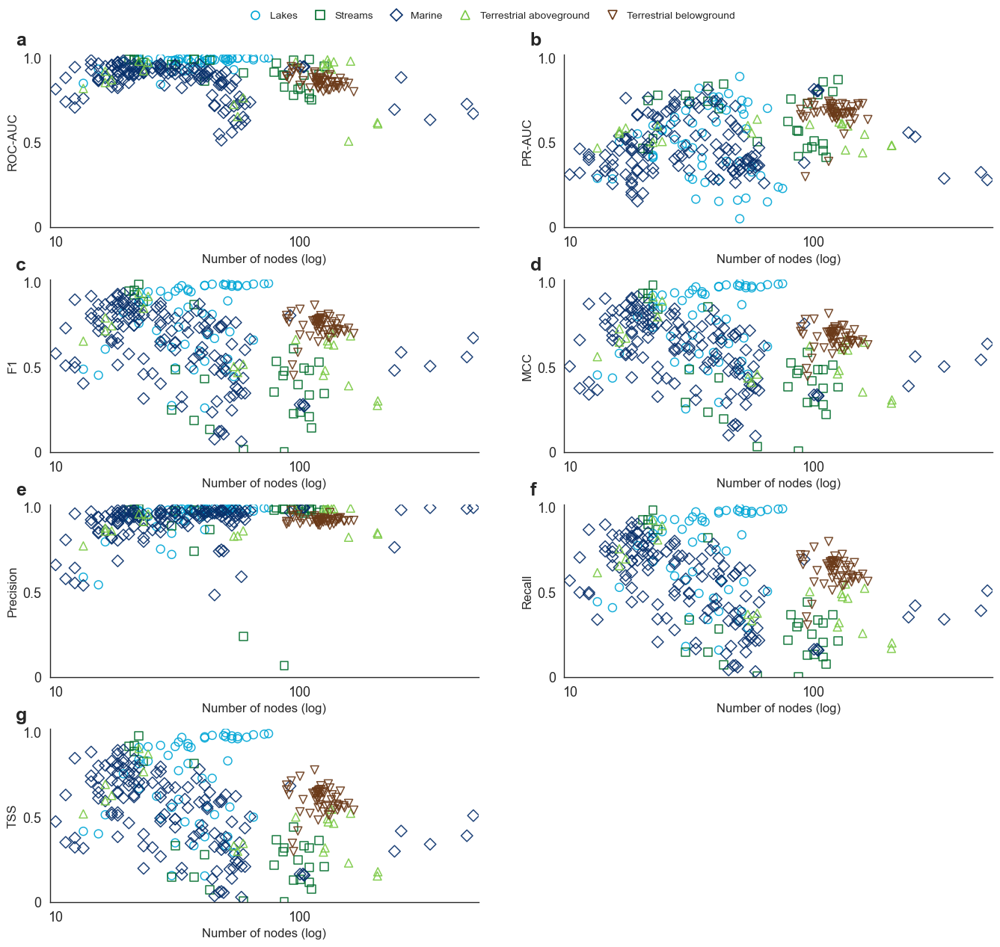

In [10]:
import os
import json
import math
import tempfile

from pathlib import Path

os.environ.setdefault(
    "MPLCONFIGDIR",
    str(
        Path(tempfile.gettempdir())
        / "qmul_phd_framework_mplconfig"
    ),
)

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm

from matplotlib.lines import Line2D
from matplotlib.ticker import ScalarFormatter


sns.set_theme(
    style="white",
    context="paper",
    font_scale=1.2,
)




# ============================================================
# Raw predictive inputs (no Tukey filtering)
# ============================================================

import re


def _raw_foodweb_name(path):
    return re.sub(
        r"_tax_mass_results_random_wlnm_.*$",
        "",
        path.stem,
        flags=re.I,
    )


def load_raw_predictive_compat(
    result_root,
    expected_version,
    metric_specs,
    expected_runs,
    minimum_retained_runs,
    *,
    train_ratios=None,
    cvk_values=None,
    k_target=10,
    threshold=0.50,
    kfold=False,
    scenario=None,
):
    """Return raw web-level means in the legacy plotting schema.

    The legacy column names are retained only so that the original plotting,
    layout, scale, colour and export code remains byte-for-byte unchanged.
    MeanAfterTukey below is a compatibility alias for the arithmetic mean of
    every complete raw run unit; no Tukey fences or outlier exclusions occur.
    """
    metrics = [metric for metric, _ in metric_specs]
    labels = dict(metric_specs)
    files = sorted((result_root / "prediction_scores_logs").glob("*.csv"))
    if not files:
        raise FileNotFoundError(result_root / "prediction_scores_logs")

    required = {
        "Version",
        "TrainRatio",
        "ExperimentID",
        "Seed",
        "Threshold",
        "K",
        "CvK",
        "FoldID",
        "EmpiricalConnectance",
        *metrics,
    }
    frames = []
    for path in files:
        frame = pd.read_csv(
            path,
            usecols=lambda column: column in required,
        )
        missing = required.difference(frame.columns)
        if missing:
            raise ValueError(
                f"{path.name}: missing raw columns {sorted(missing)}"
            )
        frame["Foodweb"] = _raw_foodweb_name(path)
        frames.append(frame)

    raw = pd.concat(frames, ignore_index=True)
    for column in required.difference({"Version"}):
        raw[column] = pd.to_numeric(raw[column], errors="coerce")
    raw["TrainRatio"] = np.where(
        raw["TrainRatio"].abs().le(1.0),
        raw["TrainRatio"] * 100.0,
        raw["TrainRatio"],
    )
    raw = raw.loc[
        raw["Version"].eq(expected_version)
        & np.isclose(raw["Threshold"], threshold, atol=1e-9)
        & np.isclose(raw["K"], k_target, atol=1e-9)
    ].copy()
    if train_ratios is not None:
        requested = np.asarray(list(train_ratios), dtype=float)
        raw = raw.loc[
            raw["TrainRatio"].map(
                lambda value: np.isclose(
                    value,
                    requested,
                    atol=1e-8,
                ).any()
            )
        ].copy()
    if cvk_values is not None:
        raw = raw.loc[raw["CvK"].isin(cvk_values)].copy()
    if raw.empty:
        raise ValueError(f"No raw observations selected from {result_root}")

    metric_values = raw[metrics].to_numpy(float)
    if not np.isfinite(metric_values).all():
        raise ValueError(f"Non-finite raw predictive values in {result_root}")
    probability_metrics = [
        metric for metric in metrics if metric not in {"TestMCC", "TestTSS"}
    ]
    signed_metrics = [
        metric for metric in metrics if metric in {"TestMCC", "TestTSS"}
    ]
    if probability_metrics:
        values = raw[probability_metrics].to_numpy(float)
        if ((values < 0) | (values > 1)).any():
            raise ValueError("Raw probability metrics must be within [0, 1]")
    if signed_metrics:
        values = raw[signed_metrics].to_numpy(float)
        if ((values < -1) | (values > 1)).any():
            raise ValueError("Raw MCC/TSS values must be within [-1, 1]")

    group_columns = [
        "Foodweb",
        "Version",
        "TrainRatio",
        "Threshold",
        "K",
        "CvK",
    ]
    if kfold:
        experiment_columns = [*group_columns, "ExperimentID"]
        fold_check = (
            raw.groupby(experiment_columns, dropna=False)
            .agg(
                FoldRows=("FoldID", "size"),
                UniqueFolds=("FoldID", "nunique"),
            )
            .reset_index()
        )
        incomplete = fold_check.loc[
            ~fold_check["FoldRows"].eq(fold_check["CvK"])
            | ~fold_check["UniqueFolds"].eq(fold_check["CvK"])
        ]
        if not incomplete.empty:
            raise ValueError(
                "Incomplete repeated-CV experiments found:\n"
                + incomplete.head(10).to_string(index=False)
            )
        run_units = (
            raw.groupby(
                experiment_columns,
                dropna=False,
                as_index=False,
            )
            .agg(
                **{
                    metric: (metric, "mean")
                    for metric in metrics
                },
                EmpiricalConnectance=(
                    "EmpiricalConnectance",
                    "first",
                ),
            )
        )
    else:
        experiment_columns = [*group_columns, "ExperimentID"]
        if raw.duplicated(experiment_columns).any():
            raise ValueError(f"Duplicate raw ExperimentID rows in {result_root}")
        run_units = raw

    counts = run_units.groupby(group_columns, dropna=False).size()
    if not counts.eq(expected_runs).all():
        raise ValueError(
            f"{result_root.name}: expected {expected_runs} complete raw "
            "run units per group; observed "
            f"{counts.value_counts().to_dict()}"
        )

    wide = (
        run_units.groupby(
            group_columns,
            dropna=False,
            as_index=False,
        )
        .agg(
            **{
                metric: (metric, "mean")
                for metric in metrics
            },
            EmpiricalConnectance=(
                "EmpiricalConnectance",
                "first",
            ),
            RawRunUnits=("ExperimentID", "size"),
        )
    )
    long = wide.melt(
        id_vars=[
            *group_columns,
            "EmpiricalConnectance",
            "RawRunUnits",
        ],
        value_vars=metrics,
        var_name="Metric",
        value_name="MeanAfterTukey",
    )
    long["Scenario"] = scenario or result_root.name
    long["MetricLabel"] = long["Metric"].map(labels)
    long["MetricFamily"] = "predictive"
    long["SourceColumn"] = long["Metric"]
    long["ReferenceColumn"] = ""
    long["MeanBeforeTukey"] = long["MeanAfterTukey"]
    long["TotalRunUnits"] = long["RawRunUnits"]
    long["ValidRunsBeforeTukey"] = long["RawRunUnits"]
    long["InvalidRunsBeforeTukey"] = 0
    long["OutlierRunsExcluded"] = 0
    long["RetainedRunsAfterTukey"] = long["RawRunUnits"]
    long["ExpectedRuns"] = expected_runs
    long["MinimumRetainedRuns"] = minimum_retained_runs
    long["MeetsMinimumRetainedRuns"] = 1
    long["ReferenceValue"] = long["EmpiricalConnectance"]
    return long

# ============================================================
# Locate repository root
# ============================================================

def find_repo_root(start=Path.cwd()):
    start = Path(start).resolve()

    candidates = [
        start,
        *start.parents,
    ]

    fallback = Path(
        "/Users/acw792/Developer/qmul-phd-framework"
    )

    if fallback not in candidates:
        candidates.append(fallback)

    for candidate in candidates:
        if (
            (candidate / "src/matlab").is_dir()
            and (candidate / "docs").is_dir()
        ):
            return candidate

    raise RuntimeError(
        "Could not locate the qmul-phd-framework repository."
    )


REPO_ROOT = find_repo_root()


# ============================================================
# Final role-only configuration
# ============================================================

CHECK_CONNECTIVITY = False
ADAPTIVE_CONNECTIVITY = False
CLASSIFICATION_THRESHOLD = 0.50

TARGET_RATIO = 90.0
MIN_NODES = 0

# Tukey is applied across 100 runs independently for each
# food-web × metric group.
#
# Keep the agreed absolute minimum of 25 retained runs.
EXPECTED_RUNS = 100
MINIMUM_RETAINED_FRACTION = 1.00
MINIMUM_RETAINED_RUNS = 100

PROTOCOL_NAME = (
    "tukey_iqr_1p5_min25runs_threshold0p50_v1"
)

EXPECTED_SCENARIO = (
    "result_wlnm_dir_neg_roleonly_trophicv2_"
    "100x290_train10-90_Apocrita_20260910_011848"
)

calculated_minimum = math.ceil(
    EXPECTED_RUNS
    * MINIMUM_RETAINED_FRACTION
)

assert calculated_minimum == MINIMUM_RETAINED_RUNS, (
    "The Tukey minimum is inconsistent."
)

RESULT_ROOT = (
    REPO_ROOT
    / "src/matlab/data"
    / (
        "result_wlnm_dir_neg_roleonly_trophicv2_"
        "100x290_train10-90_Apocrita_20260910_011848"
    )
)

RETENTION_ROOT = (
    RESULT_ROOT
    / "retention_protocol"
    / PROTOCOL_NAME
)

PREDICTIVE_INPUT = RESULT_ROOT

RETENTION_MANIFEST = (
    RETENTION_ROOT
    / "retention_manifest.json"
)

ECOSYSTEM_FILE = (
    REPO_ROOT
    / "src/matlab/data/foodwebs_mat"
    / "foodweb_metrics_ecosystem.csv"
)


# ============================================================
# Figure configuration
# ============================================================

METRIC_SPECS = [
    ("ROC_AUC", "ROC-AUC"),
    ("PR_AUC", "PR-AUC"),
    ("F1Score", "F1"),
    ("TestMCC", "MCC"),
    ("Precision", "Precision"),
    ("Recall", "Recall"),
    ("TestTSS", "TSS"),
]

ecosystem_palette = {
    "Lakes": "#00A6D6",
    "Streams": "#006D2C",
    "Marine": "#08306B",
    "Terrestrial aboveground": "#7AC943",
    "Terrestrial belowground": "#6B3A19",
    "Unknown": "#999999",
}

ecosystem_markers = {
    "Lakes": "o",
    "Streams": "s",
    "Marine": "D",
    "Terrestrial aboveground": "^",
    "Terrestrial belowground": "v",
    "Unknown": "x",
}

ECOSYSTEM_ORDER = [
    "Lakes",
    "Streams",
    "Marine",
    "Terrestrial aboveground",
    "Terrestrial belowground",
]

Y_MIN = 0.0
Y_MAX = 1.0
Y_PAD_TOP = 0.02
X_MAX = 550
N_COLS = 2


# ============================================================
# Helpers
# ============================================================

def normalize_colname(value):
    return (
        str(value)
        .strip()
        .lower()
        .replace(" ", "")
        .replace(".", "")
        .replace("-", "")
        .replace("_", "")
    )


def normalize_foodweb_name(value):
    value = Path(
        str(value).strip()
    ).name

    for extension in (
        ".mat",
        ".csv",
    ):
        if value.lower().endswith(
            extension
        ):
            value = value[
                :-len(extension)
            ].rstrip()

    for suffix in (
        "_tax_mass",
        "_taxmass",
    ):
        if value.lower().endswith(
            suffix
        ):
            value = value[
                :-len(suffix)
            ].rstrip()

    return " ".join(
        value.casefold().split()
    )


def find_column(
    dataframe,
    candidates,
):
    norm_map = {
        normalize_colname(column): column
        for column in dataframe.columns
    }

    for candidate in candidates:
        normalized_candidate = normalize_colname(
            candidate
        )

        if normalized_candidate in norm_map:
            return norm_map[
                normalized_candidate
            ]

    raise KeyError(
        "Could not find any of these columns: "
        f"{candidates}"
    )


def normalize_train_ratio(series):
    values = pd.to_numeric(
        series,
        errors="coerce",
    )

    return np.where(
        values <= 1.0,
        values * 100.0,
        values,
    )


def format_ecosystem_label(name):
    name = str(
        name
    ).strip().lower()

    label_map = {
        "lakes": "Lakes",
        "streams": "Streams",
        "marine": "Marine",
        "terrestrial aboveground": (
            "Terrestrial aboveground"
        ),
        "terrestrial belowground": (
            "Terrestrial belowground"
        ),
        "unknown": "Unknown",
    }

    return label_map.get(
        name,
        str(name).strip().capitalize(),
    )


def format_p_value(p_value):
    if pd.isna(
        p_value
    ):
        return "P = NA"

    if p_value < 0.0001:
        return "P < 0.0001"

    return f"P = {p_value:.4f}"


def format_equation(
    intercept,
    slope,
):
    sign = (
        "+"
        if slope >= 0
        else "-"
    )

    return (
        f"y = {intercept:.6f} "
        f"{sign} {abs(slope):.6f}x"
    )


# ============================================================
# Regression helper
# ============================================================

def fit_linear_regression(
    data,
    x_col,
    y_col,
    n_points=100,
):
    """
    Fits an OLS linear regression:

        y_col ~ x_col

    For this figure:

        metric ~ Nodes
    """

    work = (
        data[
            [
                x_col,
                y_col,
            ]
        ]
        .dropna()
        .copy()
    )

    if work.empty:
        return None

    work[x_col] = (
        work[x_col]
        .astype(float)
    )

    work[y_col] = (
        work[y_col]
        .astype(float)
    )

    if (
        len(work) < 3
        or work[x_col].nunique() < 2
    ):
        return None

    x = work[
        [x_col]
    ]

    y = work[
        y_col
    ]

    x_model = sm.add_constant(
        x,
        has_constant="add",
    )

    model = sm.OLS(
        y,
        x_model,
    ).fit()

    intercept = model.params[
        "const"
    ]

    slope = model.params[
        x_col
    ]

    x_line = np.linspace(
        work[x_col].min(),
        work[x_col].max(),
        n_points,
    )

    x_line_model = pd.DataFrame(
        {
            x_col: x_line
        }
    )

    x_line_model = sm.add_constant(
        x_line_model,
        has_constant="add",
    )

    y_line = model.predict(
        x_line_model
    )

    return {
        "x_line": x_line,
        "y_line": y_line,
        "intercept": intercept,
        "slope": slope,
        "f_value": model.fvalue,
        "df_model": int(
            model.df_model
        ),
        "df_resid": int(
            model.df_resid
        ),
        "p_value": model.pvalues[
            x_col
        ],
        "r_squared": model.rsquared,
        "n": len(work),
        "model": model,
    }


# ============================================================
# Validate raw inputs
# ============================================================

if not (RESULT_ROOT / "prediction_scores_logs").is_dir():
    raise FileNotFoundError(RESULT_ROOT / "prediction_scores_logs")
if not ECOSYSTEM_FILE.is_file():
    raise FileNotFoundError(ECOSYSTEM_FILE)
print("[INFO] Raw role-only input validated; no Tukey filtering.")

# ============================================================
# Load ecosystem metadata
# ============================================================

df_ecosystem = pd.read_csv(
    ECOSYSTEM_FILE
).copy()

foodweb_col = find_column(
    df_ecosystem,
    [
        "foodweb",
    ],
)

ecosystem_col = find_column(
    df_ecosystem,
    [
        "ecosystemtype",
        "ecosystem",
        "ecosystem_type",
    ],
)

nodes_col = find_column(
    df_ecosystem,
    [
        "nodes",
        "n_nodes",
        "num_nodes",
        "nodecount",
        "s",
    ],
)

df_ecosystem = (
    df_ecosystem.rename(
        columns={
            foodweb_col: (
                "MetadataFoodweb"
            ),
            ecosystem_col: (
                "EcosystemType"
            ),
            nodes_col: (
                "Nodes"
            ),
        }
    )
)

df_ecosystem = (
    df_ecosystem[
        [
            "MetadataFoodweb",
            "EcosystemType",
            "Nodes",
        ]
    ]
    .copy()
)

df_ecosystem[
    "MetadataFoodweb"
] = (
    df_ecosystem[
        "MetadataFoodweb"
    ]
    .astype(str)
)

df_ecosystem[
    "FoodwebKey"
] = (
    df_ecosystem[
        "MetadataFoodweb"
    ]
    .apply(
        normalize_foodweb_name
    )
)

df_ecosystem[
    "EcosystemType"
] = (
    df_ecosystem[
        "EcosystemType"
    ]
    .astype(str)
    .str.strip()
)

df_ecosystem[
    "Nodes"
] = pd.to_numeric(
    df_ecosystem[
        "Nodes"
    ],
    errors="coerce",
)

duplicate_metadata = (
    df_ecosystem.duplicated(
        subset=[
            "FoodwebKey"
        ],
        keep=False,
    )
)

if duplicate_metadata.any():
    conflicting_metadata = (
        df_ecosystem.loc[
            duplicate_metadata,
            [
                "FoodwebKey",
                "EcosystemType",
                "Nodes",
            ],
        ]
        .groupby(
            "FoodwebKey"
        )
        .nunique(
            dropna=False
        )
    )

    conflicting_metadata = (
        conflicting_metadata[
            (
                conflicting_metadata[
                    "EcosystemType"
                ] > 1
            )
            | (
                conflicting_metadata[
                    "Nodes"
                ] > 1
            )
        ]
    )

    if not conflicting_metadata.empty:
        print(
            conflicting_metadata
        )

        raise ValueError(
            "Conflicting ecosystem or node metadata "
            "were found for one or more food webs."
        )

df_ecosystem = (
    df_ecosystem
    .drop_duplicates(
        subset=[
            "FoodwebKey",
        ],
        keep="first",
    )
    .copy()
)


# ============================================================
# Load final role-only Tukey-filtered results
# ============================================================

tukey_raw = load_raw_predictive_compat(
    RESULT_ROOT,
    "WLNM_dir_neg",
    METRIC_SPECS,
    EXPECTED_RUNS,
    EXPECTED_RUNS,
    train_ratios=[TARGET_RATIO],
    scenario=EXPECTED_SCENARIO,
).copy()

required_columns = {
    "Scenario",
    "Foodweb",
    "Version",
    "TrainRatio",
    "Threshold",
    "Metric",
    "MetricFamily",
    "MeanAfterTukey",
    "RetainedRunsAfterTukey",
    "ExpectedRuns",
    "MinimumRetainedRuns",
    "OutlierRunsExcluded",
    "MeetsMinimumRetainedRuns",
}

missing_columns = sorted(
    required_columns.difference(
        tukey_raw.columns
    )
)

if missing_columns:
    raise ValueError(
        "The Tukey-filtered input is missing columns:\n  "
        + "\n  ".join(
            missing_columns
        )
    )

numeric_columns = [
    "TrainRatio",
    "Threshold",
    "MeanAfterTukey",
    "RetainedRunsAfterTukey",
    "ExpectedRuns",
    "MinimumRetainedRuns",
    "OutlierRunsExcluded",
    "MeetsMinimumRetainedRuns",
]

for column in numeric_columns:
    tukey_raw[column] = pd.to_numeric(
        tukey_raw[column],
        errors="coerce",
    )

tukey_raw[
    "TrainRatio"
] = normalize_train_ratio(
    tukey_raw[
        "TrainRatio"
    ]
)

metric_columns = [
    metric_column
    for metric_column, _
    in METRIC_SPECS
]


# ============================================================
# Select requested role-only configuration
# ============================================================

tukey_target = tukey_raw.loc[
    tukey_raw["Scenario"].eq(
        EXPECTED_SCENARIO
    )
    & tukey_raw["Version"].eq(
        "WLNM_dir_neg"
    )
    & (
        tukey_raw["MetricFamily"]
        .astype(str)
        .str.casefold()
        .eq("predictive")
    )
    & tukey_raw["Metric"].isin(
        metric_columns
    )
    & np.isclose(
        tukey_raw["TrainRatio"],
        TARGET_RATIO,
        atol=1e-9,
        equal_nan=False,
    )
    & np.isclose(
        tukey_raw["Threshold"],
        CLASSIFICATION_THRESHOLD,
        atol=1e-9,
        equal_nan=False,
    )
].copy()

if tukey_target.empty:
    raise RuntimeError(
        "No final role-only results were found "
        f"for TrainRatio={TARGET_RATIO}, "
        f"Threshold={CLASSIFICATION_THRESHOLD:.2f}."
    )


# ============================================================
# Validate minimum 25 retained runs
# ============================================================

observed_expected_runs = set(
    tukey_target["ExpectedRuns"]
    .dropna()
    .astype(int)
    .unique()
)

if observed_expected_runs != {
    EXPECTED_RUNS
}:
    raise ValueError(
        "Unexpected number of runs in the Raw prediction input:\n"
        f"  expected: {EXPECTED_RUNS}\n"
        f"  observed: {sorted(observed_expected_runs)}"
    )

observed_minimums = set(
    tukey_target["MinimumRetainedRuns"]
    .dropna()
    .astype(int)
    .unique()
)

if observed_minimums != {
    MINIMUM_RETAINED_RUNS
}:
    raise ValueError(
        "Unexpected Tukey minimum in the input:\n"
        f"  expected: {MINIMUM_RETAINED_RUNS}\n"
        f"  observed: {sorted(observed_minimums)}"
    )

incorrectly_retained = tukey_target[
    tukey_target[
        "MeetsMinimumRetainedRuns"
    ].eq(1)
    & tukey_target[
        "RetainedRunsAfterTukey"
    ].lt(
        MINIMUM_RETAINED_RUNS
    )
]

if not incorrectly_retained.empty:
    print(
        incorrectly_retained[
            [
                "Foodweb",
                "Metric",
                "ExpectedRuns",
                "RetainedRunsAfterTukey",
                "MinimumRetainedRuns",
                "MeetsMinimumRetainedRuns",
            ]
        ]
    )

    raise ValueError(
        "At least one food-web metric is marked as retained "
        f"despite having fewer than "
        f"{MINIMUM_RETAINED_RUNS} runs."
    )

tukey_results = tukey_target.loc[
    tukey_target["ExpectedRuns"].eq(
        EXPECTED_RUNS
    )
    & tukey_target[
        "MinimumRetainedRuns"
    ].eq(
        MINIMUM_RETAINED_RUNS
    )
    & tukey_target[
        "RetainedRunsAfterTukey"
    ].ge(
        MINIMUM_RETAINED_RUNS
    )
    & tukey_target[
        "MeetsMinimumRetainedRuns"
    ].eq(1)
    & tukey_target[
        "MeanAfterTukey"
    ].notna()
].copy()

if tukey_results.empty:
    raise RuntimeError(
        "No results remain after validating the "
        f"minimum of {MINIMUM_RETAINED_RUNS} runs."
    )

print(
    "[INFO] Raw run completeness validated: "
    f"at least {MINIMUM_RETAINED_RUNS} of "
    f"{EXPECTED_RUNS} runs per food web and metric."
)

print(
    "[INFO] Actual retained-run range: "
    f"{int(tukey_results['RetainedRunsAfterTukey'].min())}–"
    f"{int(tukey_results['RetainedRunsAfterTukey'].max())}"
)


# ============================================================
# Validate unique food-web × metric rows
# ============================================================

tukey_results[
    "FoodwebKey"
] = (
    tukey_results[
        "Foodweb"
    ]
    .apply(
        normalize_foodweb_name
    )
)

duplicate_groups = (
    tukey_results
    .duplicated(
        subset=[
            "FoodwebKey",
            "Metric",
        ],
        keep=False,
    )
)

if duplicate_groups.any():
    duplicated = (
        tukey_results.loc[
            duplicate_groups,
            [
                "Foodweb",
                "Metric",
                "TrainRatio",
                "Threshold",
            ],
        ]
        .sort_values(
            [
                "Metric",
                "Foodweb",
            ]
        )
    )

    print(
        duplicated
    )

    raise ValueError(
        "More than one retained row was found per "
        "food web and metric."
    )


# ============================================================
# Retention summary
# ============================================================

retention_summary = (
    tukey_results
    .groupby(
        "Metric",
        as_index=False,
    )
    .agg(
        FoodWebs=(
            "FoodwebKey",
            "nunique",
        ),
        ExpectedRuns=(
            "ExpectedRuns",
            "min",
        ),
        RequiredMinimumRuns=(
            "MinimumRetainedRuns",
            "min",
        ),
        MinimumRetainedRuns=(
            "RetainedRunsAfterTukey",
            "min",
        ),
        MedianRetainedRuns=(
            "RetainedRunsAfterTukey",
            "median",
        ),
        MaximumRetainedRuns=(
            "RetainedRunsAfterTukey",
            "max",
        ),
        TotalOutliersExcluded=(
            "OutlierRunsExcluded",
            "sum",
        ),
    )
)

print(
    "\n=== Raw run counts by predictive metric ==="
)

print(
    retention_summary.to_string(
        index=False
    )
)


# ============================================================
# Convert metric rows to wide food-web format
# ============================================================

df_all = (
    tukey_results
    .pivot(
        index=[
            "Foodweb",
            "FoodwebKey",
        ],
        columns="Metric",
        values="MeanAfterTukey",
    )
    .reset_index()
    .copy()
)

df_all.columns.name = None


# ============================================================
# Merge metadata and apply node filter
# ============================================================

df_merged = (
    df_all.merge(
        df_ecosystem[
            [
                "FoodwebKey",
                "EcosystemType",
                "Nodes",
            ]
        ],
        on="FoodwebKey",
        how="left",
        validate="one_to_one",
    )
    .copy()
)

missing_metadata = (
    df_merged[
        "EcosystemType"
    ].isna()
    | df_merged[
        "Nodes"
    ].isna()
)

if missing_metadata.any():
    missing_foodwebs = sorted(
        df_merged.loc[
            missing_metadata,
            "Foodweb",
        ]
        .astype(str)
        .unique()
    )

    raise ValueError(
        "Ecosystem or node metadata could not be matched "
        f"for {len(missing_foodwebs)} food webs:\n  "
        + "\n  ".join(
            missing_foodwebs[:30]
        )
    )

df_merged[
    "Nodes"
] = pd.to_numeric(
    df_merged[
        "Nodes"
    ],
    errors="coerce",
)

df_merged[
    "EcosystemType"
] = (
    df_merged[
        "EcosystemType"
    ]
    .fillna(
        "Unknown"
    )
)

for metric_column in metric_columns:
    if metric_column not in df_merged.columns:
        raise RuntimeError(
            f"Required metric column "
            f"'{metric_column}' is missing."
        )

    df_merged[
        metric_column
    ] = pd.to_numeric(
        df_merged[
            metric_column
        ],
        errors="coerce",
    )

before_rows = len(
    df_merged
)

before_foodwebs = (
    df_merged[
        "Foodweb"
    ]
    .nunique()
)

df_tr = df_merged.loc[
    df_merged[
        "Nodes"
    ].ge(
        MIN_NODES
    )
].copy()

after_rows = len(
    df_tr
)

after_foodwebs = (
    df_tr[
        "Foodweb"
    ]
    .nunique()
)

print(
    f"Filtered data: TrainRatio = {TARGET_RATIO}, "
    f"Threshold = {CLASSIFICATION_THRESHOLD:.2f}, "
    f"Nodes >= {MIN_NODES}. "
    f"Rows kept: {after_rows} / {before_rows}. "
    f"Food webs kept: "
    f"{after_foodwebs} / {before_foodwebs}."
)

if df_tr.empty:
    raise RuntimeError(
        "No rows remain after applying the "
        "node-count filter."
    )


# ============================================================
# One observation per food web
# ============================================================

agg_dict = {
    metric_column: "mean"
    for metric_column, _
    in METRIC_SPECS
}

df_scatter = (
    df_tr
    .groupby(
        [
            "Foodweb",
            "EcosystemType",
            "Nodes",
        ],
        as_index=False,
    )
    .agg(
        agg_dict
    )
    .copy()
)

df_scatter = (
    df_scatter
    .dropna(
        subset=[
            "Nodes",
        ]
    )
    .copy()
)

if df_scatter.empty:
    raise RuntimeError(
        "No data remain after grouping by food web."
    )

x_min = max(
    1,
    df_scatter[
        "Nodes"
    ].min()
    * 0.95,
)

x_max = min(
    X_MAX,
    df_scatter[
        "Nodes"
    ].max()
    * 1.05,
)

print(
    "[INFO] Using final role-only Tukey-filtered "
    "food-web means."
)

print(
    "[INFO] Configuration: "
    "eligibility=role_only, "
    "mass_constraint=False, "
    "negative_sampling=uniform_without_replacement, "
    "negative_topup_policy=uniform_remaining_nonlinks, "
    "negative_positive_ratio=2:1, "
    "classification_threshold=0.50, "
    f"train_ratio={TARGET_RATIO:.0f}."
)

print(
    "[INFO] Raw run requirement: "
    f"at least {MINIMUM_RETAINED_RUNS} of "
    f"{EXPECTED_RUNS} runs per food web and metric."
)


# ============================================================
# Ecosystem order and palette
# ============================================================

available_ecosystems = (
    df_scatter[
        "EcosystemType"
    ]
    .dropna()
    .astype(str)
    .unique()
    .tolist()
)

available_by_label = {
    format_ecosystem_label(
        ecosystem
    ): ecosystem
    for ecosystem in available_ecosystems
}

eco_order = [
    available_by_label[label]
    for label in ECOSYSTEM_ORDER
    if label in available_by_label
]

eco_order += [
    ecosystem
    for ecosystem in available_ecosystems
    if ecosystem not in eco_order
]

df_scatter[
    "EcosystemType"
] = pd.Categorical(
    df_scatter[
        "EcosystemType"
    ],
    categories=eco_order,
    ordered=True,
)

eco_palette = {
    ecosystem: ecosystem_palette.get(
        format_ecosystem_label(
            ecosystem
        ),
        "#999999",
    )
    for ecosystem in eco_order
}

eco_markers = {
    ecosystem: ecosystem_markers.get(
        format_ecosystem_label(
            ecosystem
        ),
        "o",
    )
    for ecosystem in eco_order
}


# ============================================================
# Plot
# ============================================================

n_panels = len(
    METRIC_SPECS
)

n_rows = math.ceil(
    n_panels / N_COLS
)

fig, axes = plt.subplots(
    n_rows,
    N_COLS,
    figsize=(
        14,
        14,
    ),
    sharex=False,
    sharey=False,
)

axes = np.array(
    axes
).reshape(-1)

panel_letters = list(
    "abcdefghijklmnopqrstuvwxyz"
)

total_foodwebs = (
    df_scatter[
        "Foodweb"
    ]
    .nunique()
)

print(
    "\n=== OLS linear regression: "
    "metric ~ number of nodes ==="
)

for index, (
    (
        metric_column,
        metric_label,
    ),
    ax,
) in enumerate(
    zip(
        METRIC_SPECS,
        axes,
    )
):
    data = (
        df_scatter
        .dropna(
            subset=[
                "Nodes",
                metric_column,
            ]
        )
        .copy()
    )

    n_metric_foodwebs = (
        data[
            "Foodweb"
        ]
        .nunique()
    )

    for ecosystem in eco_order:
        ecosystem_data = data.loc[
            data[
                "EcosystemType"
            ]
            == ecosystem
        ]

        if ecosystem_data.empty:
            continue

        ax.scatter(
            ecosystem_data[
                "Nodes"
            ],
            ecosystem_data[
                metric_column
            ],
            marker=eco_markers[
                ecosystem
            ],
            facecolors="none",
            edgecolors=eco_palette[
                ecosystem
            ],
            linewidths=1.1,
            s=62,
            alpha=0.9,
            label=format_ecosystem_label(
                ecosystem
            ),
        )

    fit = fit_linear_regression(
        data,
        "Nodes",
        metric_column,
    )

    if fit is not None:
        # Regression line remains intentionally hidden.
        #
        # ax.plot(
        #     fit["x_line"],
        #     fit["y_line"],
        #     color="black",
        #     linewidth=2.0,
        #     linestyle="-",
        #     zorder=5,
        # )

        equation = format_equation(
            fit["intercept"],
            fit["slope"],
        )

        p_text = format_p_value(
            fit["p_value"]
        )

        print(
            f"{panel_letters[index]}) "
            f"{metric_label}: "
            f"{equation}; "
            f"F{fit['df_model']},"
            f"{fit['df_resid']} = "
            f"{fit['f_value']:.4f}; "
            f"R² = "
            f"{fit['r_squared']:.4f}; "
            f"{p_text}; "
            f"n = {fit['n']}"
        )

    else:
        print(
            f"{panel_letters[index]}) "
            f"{metric_label}: "
            "regression not fitted; "
            "insufficient data."
        )

    ax.set_ylabel(
        metric_label,
        fontsize=12,
    )

    ax.set_xlabel(
        "Number of nodes (log)",
        fontsize=12,
    )

    ax.tick_params(
        axis="x",
        labelbottom=True,
        labelsize=13,
    )

    ax.tick_params(
        axis="y",
        labelleft=True,
        labelsize=13,
    )

    ax.set_xscale(
        "log"
    )

    ax.set_xlim(
        x_min,
        x_max,
    )

    ax.xaxis.set_major_formatter(
        ScalarFormatter()
    )

    ax.ticklabel_format(
        axis="x",
        style="plain",
    )

    ax.set_ylim(
        Y_MIN,
        Y_MAX + Y_PAD_TOP,
    )

    ax.set_yticks(
        [
            0,
            0.5,
            1.0,
        ]
    )

    ax.set_yticklabels(
        [
            "0",
            "0.5",
            "1.0",
        ],
        fontsize=13,
    )

    sns.despine(
        ax=ax
    )

    ax.text(
        -0.08,
        1.03,
        panel_letters[index],
        transform=ax.transAxes,
        fontsize=18,
        fontweight="bold",
        va="bottom",
        ha="left",
        clip_on=False,
    )

for panel_index in range(
    n_panels,
    len(axes),
):
    axes[
        panel_index
    ].set_axis_off()


# ============================================================
# Figure-level legend
# ============================================================

legend_handles = [
    Line2D(
        [0],
        [0],
        marker=eco_markers[
            ecosystem
        ],
        linestyle="",
        markersize=8,
        markerfacecolor="none",
        markeredgecolor=eco_palette[
            ecosystem
        ],
        markeredgewidth=1.2,
        label=format_ecosystem_label(
            ecosystem
        ),
    )
    for ecosystem in eco_order
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(
        0.5,
        0.95,
    ),
    ncol=min(
        len(eco_order),
        5,
    ),
    frameon=False,
    columnspacing=1.2,
    handletextpad=0.4,
    fontsize=10,
)

fig.subplots_adjust(
    top=0.90,
    hspace=0.3,
    wspace=0.2,
    left=0.08,
    right=0.98,
    bottom=0.09,
)

print(
    "\n[INFO] Final raw-input configuration:"
)

print(
    f"  expected_runs="
    f"{EXPECTED_RUNS}"
)

print(
    f"  minimum_retained_fraction="
    f"{MINIMUM_RETAINED_FRACTION:.2f}"
)

print(
    f"  minimum_retained_runs="
    f"{MINIMUM_RETAINED_RUNS}/{EXPECTED_RUNS}"
)

print(
    f"  food_webs_used="
    f"{total_foodwebs}"
)

plt.show()

[INFO] Raw role-only input validated; no Tukey filtering.
[INFO] Raw runs used per food-web metric: 100
[INFO] Food webs in metadata file: 290
[CHECK] K = 10: 290 -> 290 food webs
[CHECK] TrainRatio = 90.0: 290 -> 290 food webs
[CHECK] Nodes >= 0: 290 -> 290 food webs
[CHECK] available connectance for x-axis: 290 -> 290 food webs
[FINAL] Food webs retained after structural filters: 290

=== OLS linear regression: metric ~ empirical connectance ===
a) ROC-AUC: y = 0.2694x + 0.8537; F1,288 = 4.9717; R² = 0.0170; P = 0.0265; n = 290
b) PR-AUC: y = 1.0622x + 0.3944; F1,288 = 25.7914; R² = 0.0822; P < 0.0001; n = 290
c) F1: y = 0.1673x + 0.6465; F1,288 = 0.3685; R² = 0.0013; P = 0.5443; n = 290
d) MCC: y = 0.0437x + 0.6324; F1,288 = 0.0293; R² = 0.0001; P = 0.8641; n = 290
e) Precision: y = -0.0191x + 0.9258; F1,288 = 0.0204; R² = 0.0001; P = 0.8866; n = 290
f) Recall: y = 0.1425x + 0.5554; F1,288 = 0.2161; R² = 0.0007; P = 0.6424; n = 290
g) TSS: y = 0.0502x + 0.5486; F1,288 = 0.0274; R² =

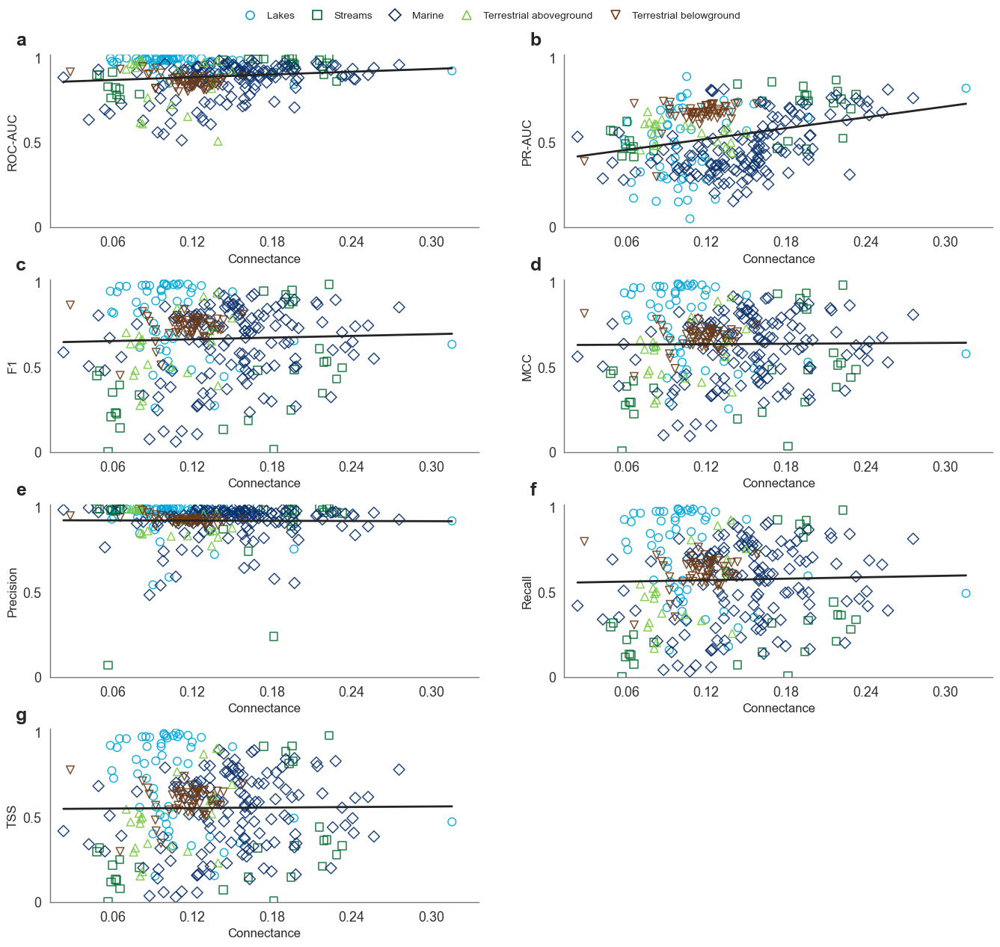

In [11]:
import os
import json
import math
import tempfile

from pathlib import Path

os.environ.setdefault(
    "MPLCONFIGDIR",
    str(
        Path(tempfile.gettempdir())
        / "qmul_phd_framework_mplconfig"
    ),
)

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm

from matplotlib.lines import Line2D


sns.set_theme(
    style="white",
    context="paper",
    font_scale=1.2,
)




# ============================================================
# Raw predictive inputs (no Tukey filtering)
# ============================================================

import re


def _raw_foodweb_name(path):
    return re.sub(
        r"_tax_mass_results_random_wlnm_.*$",
        "",
        path.stem,
        flags=re.I,
    )


def load_raw_predictive_compat(
    result_root,
    expected_version,
    metric_specs,
    expected_runs,
    minimum_retained_runs,
    *,
    train_ratios=None,
    cvk_values=None,
    k_target=10,
    threshold=0.50,
    kfold=False,
    scenario=None,
):
    """Return raw web-level means in the legacy plotting schema.

    The legacy column names are retained only so that the original plotting,
    layout, scale, colour and export code remains byte-for-byte unchanged.
    MeanAfterTukey below is a compatibility alias for the arithmetic mean of
    every complete raw run unit; no Tukey fences or outlier exclusions occur.
    """
    metrics = [metric for metric, _ in metric_specs]
    labels = dict(metric_specs)
    files = sorted((result_root / "prediction_scores_logs").glob("*.csv"))
    if not files:
        raise FileNotFoundError(result_root / "prediction_scores_logs")

    required = {
        "Version",
        "TrainRatio",
        "ExperimentID",
        "Seed",
        "Threshold",
        "K",
        "CvK",
        "FoldID",
        "EmpiricalConnectance",
        *metrics,
    }
    frames = []
    for path in files:
        frame = pd.read_csv(
            path,
            usecols=lambda column: column in required,
        )
        missing = required.difference(frame.columns)
        if missing:
            raise ValueError(
                f"{path.name}: missing raw columns {sorted(missing)}"
            )
        frame["Foodweb"] = _raw_foodweb_name(path)
        frames.append(frame)

    raw = pd.concat(frames, ignore_index=True)
    for column in required.difference({"Version"}):
        raw[column] = pd.to_numeric(raw[column], errors="coerce")
    raw["TrainRatio"] = np.where(
        raw["TrainRatio"].abs().le(1.0),
        raw["TrainRatio"] * 100.0,
        raw["TrainRatio"],
    )
    raw = raw.loc[
        raw["Version"].eq(expected_version)
        & np.isclose(raw["Threshold"], threshold, atol=1e-9)
        & np.isclose(raw["K"], k_target, atol=1e-9)
    ].copy()
    if train_ratios is not None:
        requested = np.asarray(list(train_ratios), dtype=float)
        raw = raw.loc[
            raw["TrainRatio"].map(
                lambda value: np.isclose(
                    value,
                    requested,
                    atol=1e-8,
                ).any()
            )
        ].copy()
    if cvk_values is not None:
        raw = raw.loc[raw["CvK"].isin(cvk_values)].copy()
    if raw.empty:
        raise ValueError(f"No raw observations selected from {result_root}")

    metric_values = raw[metrics].to_numpy(float)
    if not np.isfinite(metric_values).all():
        raise ValueError(f"Non-finite raw predictive values in {result_root}")
    probability_metrics = [
        metric for metric in metrics if metric not in {"TestMCC", "TestTSS"}
    ]
    signed_metrics = [
        metric for metric in metrics if metric in {"TestMCC", "TestTSS"}
    ]
    if probability_metrics:
        values = raw[probability_metrics].to_numpy(float)
        if ((values < 0) | (values > 1)).any():
            raise ValueError("Raw probability metrics must be within [0, 1]")
    if signed_metrics:
        values = raw[signed_metrics].to_numpy(float)
        if ((values < -1) | (values > 1)).any():
            raise ValueError("Raw MCC/TSS values must be within [-1, 1]")

    group_columns = [
        "Foodweb",
        "Version",
        "TrainRatio",
        "Threshold",
        "K",
        "CvK",
    ]
    if kfold:
        experiment_columns = [*group_columns, "ExperimentID"]
        fold_check = (
            raw.groupby(experiment_columns, dropna=False)
            .agg(
                FoldRows=("FoldID", "size"),
                UniqueFolds=("FoldID", "nunique"),
            )
            .reset_index()
        )
        incomplete = fold_check.loc[
            ~fold_check["FoldRows"].eq(fold_check["CvK"])
            | ~fold_check["UniqueFolds"].eq(fold_check["CvK"])
        ]
        if not incomplete.empty:
            raise ValueError(
                "Incomplete repeated-CV experiments found:\n"
                + incomplete.head(10).to_string(index=False)
            )
        run_units = (
            raw.groupby(
                experiment_columns,
                dropna=False,
                as_index=False,
            )
            .agg(
                **{
                    metric: (metric, "mean")
                    for metric in metrics
                },
                EmpiricalConnectance=(
                    "EmpiricalConnectance",
                    "first",
                ),
            )
        )
    else:
        experiment_columns = [*group_columns, "ExperimentID"]
        if raw.duplicated(experiment_columns).any():
            raise ValueError(f"Duplicate raw ExperimentID rows in {result_root}")
        run_units = raw

    counts = run_units.groupby(group_columns, dropna=False).size()
    if not counts.eq(expected_runs).all():
        raise ValueError(
            f"{result_root.name}: expected {expected_runs} complete raw "
            "run units per group; observed "
            f"{counts.value_counts().to_dict()}"
        )

    wide = (
        run_units.groupby(
            group_columns,
            dropna=False,
            as_index=False,
        )
        .agg(
            **{
                metric: (metric, "mean")
                for metric in metrics
            },
            EmpiricalConnectance=(
                "EmpiricalConnectance",
                "first",
            ),
            RawRunUnits=("ExperimentID", "size"),
        )
    )
    long = wide.melt(
        id_vars=[
            *group_columns,
            "EmpiricalConnectance",
            "RawRunUnits",
        ],
        value_vars=metrics,
        var_name="Metric",
        value_name="MeanAfterTukey",
    )
    long["Scenario"] = scenario or result_root.name
    long["MetricLabel"] = long["Metric"].map(labels)
    long["MetricFamily"] = "predictive"
    long["SourceColumn"] = long["Metric"]
    long["ReferenceColumn"] = ""
    long["MeanBeforeTukey"] = long["MeanAfterTukey"]
    long["TotalRunUnits"] = long["RawRunUnits"]
    long["ValidRunsBeforeTukey"] = long["RawRunUnits"]
    long["InvalidRunsBeforeTukey"] = 0
    long["OutlierRunsExcluded"] = 0
    long["RetainedRunsAfterTukey"] = long["RawRunUnits"]
    long["ExpectedRuns"] = expected_runs
    long["MinimumRetainedRuns"] = minimum_retained_runs
    long["MeetsMinimumRetainedRuns"] = 1
    long["ReferenceValue"] = long["EmpiricalConnectance"]
    return long

# ============================================================
# Locate project root
# ============================================================

def find_project_root(start=None):
    start = (
        Path.cwd().resolve()
        if start is None
        else Path(start).resolve()
    )

    candidates = [
        start,
        *start.parents,
    ]

    fallback = Path(
        "/Users/acw792/Developer/qmul-phd-framework"
    )

    if fallback not in candidates:
        candidates.append(fallback)

    for path in candidates:
        if (
            (path / "src/matlab").is_dir()
            and (path / "docs").is_dir()
        ):
            return path

    raise FileNotFoundError(
        "Could not locate the qmul-phd-framework repository."
    )


PROJECT_ROOT = find_project_root()


# ============================================================
# Final role-only input configuration
# ============================================================

CLASSIFICATION_THRESHOLD = 0.50

K_TARGET = 10
TARGET_RATIO = 90.0
MIN_NODES = 0
AGGREGATE_REPEATS = True

# Tukey is applied independently across 100 runs for each
# food-web × metric group.
#
# Keep the agreed absolute minimum of 25 retained runs.
EXPECTED_RUNS = 100
MINIMUM_RETAINED_FRACTION = 1.00
MINIMUM_RETAINED_RUNS = 100

PROTOCOL_NAME = (
    "tukey_iqr_1p5_min25runs_threshold0p50_v1"
)

EXPECTED_SCENARIO = (
    "result_wlnm_dir_neg_roleonly_trophicv2_"
    "100x290_train10-90_Apocrita_20260910_011848"
)

calculated_minimum = math.ceil(
    EXPECTED_RUNS
    * MINIMUM_RETAINED_FRACTION
)

assert calculated_minimum == MINIMUM_RETAINED_RUNS, (
    "The Tukey minimum is inconsistent."
)

RESULT_ROOT = (
    PROJECT_ROOT
    / "src/matlab/data"
    / (
        "result_wlnm_dir_neg_roleonly_trophicv2_"
        "100x290_train10-90_Apocrita_20260910_011848"
    )
)

RETENTION_ROOT = (
    RESULT_ROOT
    / "retention_protocol"
    / PROTOCOL_NAME
)

PREDICTIVE_INPUT = RESULT_ROOT

EMPIRICAL_CONNECTANCE_INPUT = RESULT_ROOT

RETENTION_MANIFEST = (
    RETENTION_ROOT
    / "retention_manifest.json"
)

ECOSYSTEM_FILE = (
    PROJECT_ROOT
    / "src/matlab/data/foodwebs_mat"
    / "foodweb_metrics_ecosystem.csv"
)


# ============================================================
# Figure configuration
# ============================================================

METRIC_SPECS = [
    ("ROC_AUC", "ROC-AUC"),
    ("PR_AUC", "PR-AUC"),
    ("F1Score", "F1"),
    ("TestMCC", "MCC"),
    ("Precision", "Precision"),
    ("Recall", "Recall"),
    ("TestTSS", "TSS"),
]

ecosystem_palette = {
    "Lakes": "#00A6D6",
    "Streams": "#006D2C",
    "Marine": "#08306B",
    "Terrestrial aboveground": "#7AC943",
    "Terrestrial belowground": "#6B3A19",
    "Unknown": "#999999",
}

ecosystem_markers = {
    "Lakes": "o",
    "Streams": "s",
    "Marine": "D",
    "Terrestrial aboveground": "^",
    "Terrestrial belowground": "v",
    "Unknown": "x",
}

ECOSYSTEM_ORDER = [
    "Lakes",
    "Streams",
    "Marine",
    "Terrestrial aboveground",
    "Terrestrial belowground",
]

Y_MIN = 0.0
Y_MAX = 1.0
Y_PAD_TOP = 0.02
N_COLS = 2


# ============================================================
# Helpers
# ============================================================

def normalize_colname(value):
    return (
        str(value)
        .strip()
        .lower()
        .replace(" ", "")
        .replace(".", "")
        .replace("-", "")
        .replace("_", "")
    )


def normalize_foodweb_name(value):
    value = Path(
        str(value).strip()
    ).name

    for extension in (
        ".mat",
        ".csv",
    ):
        if value.lower().endswith(
            extension
        ):
            value = value[
                :-len(extension)
            ].rstrip()

    for suffix in (
        "_tax_mass",
        "_taxmass",
    ):
        if value.lower().endswith(
            suffix
        ):
            value = value[
                :-len(suffix)
            ].rstrip()

    return " ".join(
        value.casefold().split()
    )


def find_column(
    dataframe,
    candidates,
):
    norm_map = {
        normalize_colname(column): column
        for column in dataframe.columns
    }

    for candidate in candidates:
        normalized_candidate = normalize_colname(
            candidate
        )

        if normalized_candidate in norm_map:
            return norm_map[
                normalized_candidate
            ]

    raise KeyError(
        "Could not find any of these columns: "
        f"{candidates}"
    )


def normalize_train_ratio(series):
    values = pd.to_numeric(
        series,
        errors="coerce",
    )

    return np.where(
        values <= 1.0,
        values * 100.0,
        values,
    )


def format_ecosystem_label(name):
    name = str(
        name
    ).strip().lower()

    label_map = {
        "lakes": "Lakes",
        "streams": "Streams",
        "marine": "Marine",
        "terrestrial aboveground": (
            "Terrestrial aboveground"
        ),
        "terrestrial belowground": (
            "Terrestrial belowground"
        ),
        "unknown": "Unknown",
    }

    return label_map.get(
        name,
        str(name).strip().capitalize(),
    )


def report_foodweb_count(
    stage_name,
    before,
    after,
):
    print(
        f"[CHECK] {stage_name}: "
        f"{len(before)} -> {len(after)} food webs"
    )


# ============================================================
# Validate raw inputs
# ============================================================

if not (RESULT_ROOT / "prediction_scores_logs").is_dir():
    raise FileNotFoundError(RESULT_ROOT / "prediction_scores_logs")
if not ECOSYSTEM_FILE.is_file():
    raise FileNotFoundError(ECOSYSTEM_FILE)
print("[INFO] Raw role-only input validated; no Tukey filtering.")

# ============================================================
# Load raw unfiltered results
# ============================================================

def load_results(path):
    results = load_raw_predictive_compat(
        path,
        "WLNM_dir_neg",
        METRIC_SPECS,
        EXPECTED_RUNS,
        EXPECTED_RUNS,
        train_ratios=[TARGET_RATIO],
        k_target=K_TARGET,
        scenario=EXPECTED_SCENARIO,
    )
    results["FoodwebKey"] = results["Foodweb"].map(
        normalize_foodweb_name
    )
    if results.duplicated(["FoodwebKey", "Metric"]).any():
        raise ValueError("Duplicate raw food-web/metric summaries")
    wide_results = (
        results.pivot(
            index=[
                "Foodweb",
                "FoodwebKey",
                "K",
                "TrainRatio",
            ],
            columns="Metric",
            values="MeanAfterTukey",
        )
        .reset_index()
        .copy()
    )
    wide_results.columns.name = None
    print(
        "[INFO] Raw runs used per food-web metric: "
        f"{int(results['RetainedRunsAfterTukey'].min())}"
    )
    return wide_results

# ============================================================
# Load empirical connectance from the raw WLNM run
# ============================================================

def load_empirical_connectance(path):
    raw_summary = load_raw_predictive_compat(
        path,
        "WLNM_dir_neg",
        [("ROC_AUC", "ROC-AUC")],
        EXPECTED_RUNS,
        EXPECTED_RUNS,
        train_ratios=[TARGET_RATIO],
        k_target=K_TARGET,
        scenario=EXPECTED_SCENARIO,
    )
    ecological = raw_summary.loc[
        raw_summary["Metric"].eq("ROC_AUC"),
        ["Foodweb", "EmpiricalConnectance"],
    ].copy()
    ecological["FoodwebKey"] = ecological["Foodweb"].map(
        normalize_foodweb_name
    )
    ecological = ecological.rename(
        columns={
            "EmpiricalConnectance": "EmpiricalConnectanceForPlot"
        }
    )
    if ecological["EmpiricalConnectanceForPlot"].isna().any():
        raise ValueError("Missing empirical connectance in raw inputs")
    return ecological[
        ["FoodwebKey", "EmpiricalConnectanceForPlot"]
    ].copy()

# ============================================================
# Load food-web metadata
# ============================================================

def load_foodweb_metadata(path):
    metadata = pd.read_csv(
        path
    ).copy()

    foodweb_col = find_column(
        metadata,
        [
            "foodweb",
        ],
    )

    ecosystem_col = find_column(
        metadata,
        [
            "ecosystemtype",
            "ecosystem",
            "ecosystem_type",
        ],
    )

    nodes_col = find_column(
        metadata,
        [
            "nodes",
            "n_nodes",
            "num_nodes",
            "nodecount",
            "s",
        ],
    )

    edges_col = find_column(
        metadata,
        [
            "edges",
            "n_edges",
            "num_edges",
            "edgecount",
            "l",
        ],
    )

    connectance_col = find_column(
        metadata,
        [
            "connectance",
            "c",
        ],
    )

    metadata = metadata.rename(
        columns={
            foodweb_col: (
                "MetadataFoodweb"
            ),
            ecosystem_col: (
                "EcosystemType"
            ),
            nodes_col: (
                "Nodes"
            ),
            edges_col: (
                "Edges"
            ),
            connectance_col: (
                "MetadataConnectance"
            ),
        }
    )

    metadata = metadata[
        [
            "MetadataFoodweb",
            "EcosystemType",
            "Nodes",
            "Edges",
            "MetadataConnectance",
        ]
    ].copy()

    metadata[
        "MetadataFoodweb"
    ] = (
        metadata[
            "MetadataFoodweb"
        ]
        .astype(str)
    )

    metadata[
        "FoodwebKey"
    ] = (
        metadata[
            "MetadataFoodweb"
        ]
        .apply(
            normalize_foodweb_name
        )
    )

    metadata[
        "EcosystemType"
    ] = (
        metadata[
            "EcosystemType"
        ]
        .astype(str)
        .str.strip()
    )

    metadata[
        "Nodes"
    ] = pd.to_numeric(
        metadata[
            "Nodes"
        ],
        errors="coerce",
    )

    metadata[
        "Edges"
    ] = pd.to_numeric(
        metadata[
            "Edges"
        ],
        errors="coerce",
    )

    metadata[
        "MetadataConnectance"
    ] = pd.to_numeric(
        metadata[
            "MetadataConnectance"
        ],
        errors="coerce",
    )

    duplicated_metadata = (
        metadata.duplicated(
            subset=[
                "FoodwebKey"
            ],
            keep=False,
        )
    )

    if duplicated_metadata.any():
        conflicting_metadata = (
            metadata.loc[
                duplicated_metadata,
                [
                    "FoodwebKey",
                    "EcosystemType",
                    "Nodes",
                    "Edges",
                    "MetadataConnectance",
                ],
            ]
            .groupby(
                "FoodwebKey"
            )
            .nunique(
                dropna=False
            )
        )

        conflicting_metadata = (
            conflicting_metadata[
                conflicting_metadata.max(
                    axis=1
                ) > 1
            ]
        )

        if not conflicting_metadata.empty:
            print(
                conflicting_metadata
            )

            raise ValueError(
                "Conflicting metadata were found for "
                "one or more food webs."
            )

    metadata = (
        metadata
        .drop_duplicates(
            subset=[
                "FoodwebKey",
            ],
            keep="first",
        )
        .copy()
    )

    print(
        "[INFO] Food webs in metadata file: "
        f"{metadata['FoodwebKey'].nunique()}"
    )

    return metadata


# ============================================================
# Data preparation
# ============================================================

def prepare_plot_data(
    results,
    metadata,
    empirical_connectance,
):
    dataframe = (
        results.merge(
            metadata,
            on="FoodwebKey",
            how="left",
            validate="one_to_one",
        )
        .merge(
            empirical_connectance,
            on="FoodwebKey",
            how="left",
            validate="one_to_one",
        )
        .copy()
    )

    missing_metadata = (
        dataframe[
            "EcosystemType"
        ].isna()
        | dataframe[
            "Nodes"
        ].isna()
        | dataframe[
            "EmpiricalConnectanceForPlot"
        ].isna()
    )

    if missing_metadata.any():
        missing_foodwebs = sorted(
            dataframe.loc[
                missing_metadata,
                "Foodweb",
            ]
            .astype(str)
            .unique()
        )

        raise ValueError(
            "Metadata or empirical connectance could "
            "not be matched for "
            f"{len(missing_foodwebs)} food webs:\n  "
            + "\n  ".join(
                missing_foodwebs[:30]
            )
        )

    numeric_columns = [
        "K",
        "TrainRatio",
        "ROC_AUC",
        "PR_AUC",
        "Precision",
        "Recall",
        "F1Score",
        "TestMCC",
        "TestTSS",
        "Nodes",
        "Edges",
        "MetadataConnectance",
        "EmpiricalConnectanceForPlot",
    ]

    existing_numeric_columns = [
        column
        for column in numeric_columns
        if column in dataframe.columns
    ]

    dataframe[
        existing_numeric_columns
    ] = dataframe[
        existing_numeric_columns
    ].apply(
        pd.to_numeric,
        errors="coerce",
    )

    invalid_connectance = (
        ~np.isfinite(
            dataframe[
                "EmpiricalConnectanceForPlot"
            ]
        )
        | (
            dataframe[
                "EmpiricalConnectanceForPlot"
            ] < 0.0
        )
        | (
            dataframe[
                "EmpiricalConnectanceForPlot"
            ] > 1.0
        )
    )

    if invalid_connectance.any():
        raise ValueError(
            "Invalid loop-free empirical connectance "
            "after merging the selected inputs."
        )

    dataframe[
        "EcosystemType"
    ] = (
        dataframe[
            "EcosystemType"
        ]
        .fillna(
            "Unknown"
        )
    )

    before = set(
        dataframe[
            "Foodweb"
        ]
        .dropna()
        .unique()
    )

    if K_TARGET is not None:
        dataframe = dataframe.loc[
            np.isclose(
                dataframe[
                    "K"
                ],
                K_TARGET,
                atol=1e-9,
                equal_nan=False,
            )
        ].copy()

        after = set(
            dataframe[
                "Foodweb"
            ]
            .dropna()
            .unique()
        )

        report_foodweb_count(
            f"K = {K_TARGET}",
            before,
            after,
        )

        before = after

    dataframe = dataframe.loc[
        np.isclose(
            dataframe[
                "TrainRatio"
            ],
            TARGET_RATIO,
            atol=1e-9,
            equal_nan=False,
        )
    ].copy()

    after = set(
        dataframe[
            "Foodweb"
        ]
        .dropna()
        .unique()
    )

    report_foodweb_count(
        f"TrainRatio = {TARGET_RATIO}",
        before,
        after,
    )

    before = after

    dataframe = dataframe.loc[
        dataframe[
            "Nodes"
        ].ge(
            MIN_NODES
        )
    ].copy()

    after = set(
        dataframe[
            "Foodweb"
        ]
        .dropna()
        .unique()
    )

    report_foodweb_count(
        f"Nodes >= {MIN_NODES}",
        before,
        after,
    )

    missing_metrics = [
        metric
        for metric, _
        in METRIC_SPECS
        if metric not in dataframe.columns
    ]

    if missing_metrics:
        raise RuntimeError(
            "Missing required metric columns: "
            f"{missing_metrics}"
        )

    if AGGREGATE_REPEATS:
        group_columns = [
            "Foodweb",
            "FoodwebKey",
            "K",
            "TrainRatio",
            "EmpiricalConnectanceForPlot",
            "Nodes",
            "Edges",
            "EcosystemType",
        ]

        mean_columns = [
            metric
            for metric, _
            in METRIC_SPECS
        ]

        dataframe = (
            dataframe
            .groupby(
                group_columns,
                dropna=False,
                as_index=False,
            )[
                mean_columns
            ]
            .mean()
            .copy()
        )

    before_connectance = set(
        dataframe[
            "Foodweb"
        ]
        .dropna()
        .unique()
    )

    dataframe = (
        dataframe
        .dropna(
            subset=[
                "EmpiricalConnectanceForPlot",
            ]
        )
        .copy()
    )

    after_connectance = set(
        dataframe[
            "Foodweb"
        ]
        .dropna()
        .unique()
    )

    report_foodweb_count(
        "available connectance for x-axis",
        before_connectance,
        after_connectance,
    )

    metric_columns = [
        metric
        for metric, _
        in METRIC_SPECS
    ]

    metric_availability = (
        dataframe[
            [
                "Foodweb",
                *metric_columns,
            ]
        ]
        .assign(
            HasAnySelectedMetric=lambda frame: (
                frame[
                    metric_columns
                ]
                .notna()
                .any(
                    axis=1
                )
            )
        )
        .copy()
    )

    foodwebs_without_metrics = (
        metric_availability.loc[
            ~metric_availability[
                "HasAnySelectedMetric"
            ],
            "Foodweb",
        ]
        .drop_duplicates()
        .sort_values()
        .tolist()
    )

    print(
        "[FINAL] Food webs retained after "
        "structural filters: "
        f"{dataframe['Foodweb'].nunique()}"
    )

    if foodwebs_without_metrics:
        print(
            "[INFO] Food webs retained but not plotted "
            "because all selected metrics are missing:"
        )

        for foodweb in foodwebs_without_metrics:
            print(
                f"  - {foodweb}"
            )

    return dataframe.copy()


# ============================================================
# Regression helpers
# ============================================================

def fit_linear_regression(
    data,
    metric,
    n_points=100,
):
    work = (
        data[
            [
                "EmpiricalConnectanceForPlot",
                metric,
            ]
        ]
        .dropna()
        .copy()
    )

    if work.empty:
        return None

    work[
        "EmpiricalConnectanceForPlot"
    ] = (
        work[
            "EmpiricalConnectanceForPlot"
        ]
        .astype(float)
    )

    work[
        metric
    ] = (
        work[
            metric
        ]
        .astype(float)
    )

    if (
        len(work) < 3
        or work[
            "EmpiricalConnectanceForPlot"
        ].nunique() < 2
    ):
        return None

    x = work[
        [
            "EmpiricalConnectanceForPlot",
        ]
    ]

    y = work[
        metric
    ]

    x_model = sm.add_constant(
        x,
        has_constant="add",
    )

    model = sm.OLS(
        y,
        x_model,
    ).fit()

    intercept = model.params[
        "const"
    ]

    slope = model.params[
        "EmpiricalConnectanceForPlot"
    ]

    x_line = np.linspace(
        work[
            "EmpiricalConnectanceForPlot"
        ].min(),
        work[
            "EmpiricalConnectanceForPlot"
        ].max(),
        n_points,
    )

    x_line_model = pd.DataFrame(
        {
            "EmpiricalConnectanceForPlot": (
                x_line
            )
        }
    )

    x_line_model = sm.add_constant(
        x_line_model,
        has_constant="add",
    )

    y_line = model.predict(
        x_line_model
    )

    return {
        "x_line": x_line,
        "y_line": y_line,
        "slope": slope,
        "intercept": intercept,
        "r_squared": model.rsquared,
        "p_value": model.pvalues[
            "EmpiricalConnectanceForPlot"
        ],
        "f_value": model.fvalue,
        "df_model": int(
            model.df_model
        ),
        "df_resid": int(
            model.df_resid
        ),
        "n": len(work),
        "model": model,
    }


def format_equation(
    slope,
    intercept,
):
    sign = (
        "+"
        if intercept >= 0
        else "-"
    )

    return (
        f"y = {slope:.4f}x "
        f"{sign} {abs(intercept):.4f}"
    )


def format_p_value(p_value):
    if pd.isna(
        p_value
    ):
        return "P = NA"

    if p_value < 0.0001:
        return "P < 0.0001"

    return (
        f"P = {p_value:.4f}"
    )


# ============================================================
# Plotting
# ============================================================

def style_axes(
    ax,
    ylabel,
):
    ax.set_ylabel(
        ylabel,
        fontsize=12,
    )

    ax.set_xlabel(
        "Connectance",
        fontsize=12,
    )

    ax.grid(
        False
    )

    ax.spines[
        "top"
    ].set_visible(
        False
    )

    ax.spines[
        "right"
    ].set_visible(
        False
    )

    ax.spines[
        "left"
    ].set_color(
        "#777777"
    )

    ax.spines[
        "bottom"
    ].set_color(
        "#777777"
    )

    ax.tick_params(
        axis="both",
        colors="#333333",
        labelsize=13,
    )


def plot_performance_vs_connectance(
    plot_dataframe,
):
    available_ecosystems = (
        plot_dataframe[
            "EcosystemType"
        ]
        .dropna()
        .astype(str)
        .unique()
        .tolist()
    )

    available_by_label = {
        format_ecosystem_label(
            ecosystem
        ): ecosystem
        for ecosystem in available_ecosystems
    }

    eco_order = [
        available_by_label[label]
        for label in ECOSYSTEM_ORDER
        if label in available_by_label
    ]

    eco_order += [
        ecosystem
        for ecosystem in available_ecosystems
        if ecosystem not in eco_order
    ]

    plot_dataframe = (
        plot_dataframe.copy()
    )

    plot_dataframe[
        "EcosystemType"
    ] = pd.Categorical(
        plot_dataframe[
            "EcosystemType"
        ],
        categories=eco_order,
        ordered=True,
    )

    eco_palette = {
        ecosystem: ecosystem_palette.get(
            format_ecosystem_label(
                ecosystem
            ),
            "#999999",
        )
        for ecosystem in eco_order
    }

    eco_markers = {
        ecosystem: ecosystem_markers.get(
            format_ecosystem_label(
                ecosystem
            ),
            "o",
        )
        for ecosystem in eco_order
    }

    n_panels = len(
        METRIC_SPECS
    )

    n_rows = math.ceil(
        n_panels / N_COLS
    )

    fig, axes = plt.subplots(
        n_rows,
        N_COLS,
        figsize=(
            14,
            14,
        ),
        sharex=False,
        sharey=False,
    )

    axes = np.array(
        axes
    ).reshape(-1)

    panel_letters = list(
        "abcdefghijklmnopqrstuvwxyz"
    )

    x_min = plot_dataframe[
        "EmpiricalConnectanceForPlot"
    ].min()

    x_max = plot_dataframe[
        "EmpiricalConnectanceForPlot"
    ].max()

    print(
        "\n=== OLS linear regression: "
        "metric ~ empirical connectance ==="
    )

    for index, (
        (
            metric,
            label,
        ),
        ax,
    ) in enumerate(
        zip(
            METRIC_SPECS,
            axes,
        )
    ):
        data = (
            plot_dataframe
            .dropna(
                subset=[
                    "EmpiricalConnectanceForPlot",
                    metric,
                ]
            )
            .copy()
        )

        for ecosystem in eco_order:
            ecosystem_data = data.loc[
                data[
                    "EcosystemType"
                ]
                == ecosystem
            ]

            if ecosystem_data.empty:
                continue

            ax.scatter(
                ecosystem_data[
                    "EmpiricalConnectanceForPlot"
                ],
                ecosystem_data[
                    metric
                ],
                marker=eco_markers[
                    ecosystem
                ],
                facecolors="none",
                edgecolors=eco_palette[
                    ecosystem
                ],
                linewidths=1.1,
                s=58,
                alpha=0.88,
                label=format_ecosystem_label(
                    ecosystem
                ),
            )

        fit = fit_linear_regression(
            data,
            metric,
        )

        if fit is not None:
            ax.plot(
                fit[
                    "x_line"
                ],
                fit[
                    "y_line"
                ],
                color="#232323",
                linewidth=2.0,
                linestyle="-",
                zorder=5,
            )

            equation = format_equation(
                fit[
                    "slope"
                ],
                fit[
                    "intercept"
                ],
            )

            p_text = format_p_value(
                fit[
                    "p_value"
                ]
            )

            print(
                f"{panel_letters[index]}) "
                f"{label}: "
                f"{equation}; "
                f"F{fit['df_model']},"
                f"{fit['df_resid']} = "
                f"{fit['f_value']:.4f}; "
                f"R² = "
                f"{fit['r_squared']:.4f}; "
                f"{p_text}; "
                f"n = {fit['n']}"
            )

        else:
            print(
                f"{panel_letters[index]}) "
                f"{label}: "
                "regression not fitted; "
                "insufficient data."
            )

        style_axes(
            ax,
            label,
        )

        ax.set_ylim(
            Y_MIN,
            Y_MAX + Y_PAD_TOP,
        )

        ax.set_xlim(
            max(
                0.0,
                x_min - 0.01,
            ),
            x_max + 0.02,
        )

        ax.set_yticks(
            [
                0,
                0.5,
                1.0,
            ]
        )

        ax.set_yticklabels(
            [
                "0",
                "0.5",
                "1",
            ]
        )

        ax.xaxis.set_major_locator(
            plt.MaxNLocator(6)
        )

        ax.text(
            -0.08,
            1.03,
            panel_letters[
                index
            ],
            transform=ax.transAxes,
            fontsize=18,
            fontweight="bold",
            va="bottom",
            ha="left",
            clip_on=False,
        )

    for panel_index in range(
        n_panels,
        len(axes),
    ):
        axes[
            panel_index
        ].set_axis_off()

    legend_handles = [
        Line2D(
            [0],
            [0],
            marker=eco_markers[
                ecosystem
            ],
            linestyle="",
            markersize=8,
            markerfacecolor="none",
            markeredgecolor=eco_palette[
                ecosystem
            ],
            markeredgewidth=1.2,
            label=format_ecosystem_label(
                ecosystem
            ),
        )
        for ecosystem in eco_order
    ]

    fig.legend(
        handles=legend_handles,
        loc="upper center",
        bbox_to_anchor=(
            0.5,
            0.95,
        ),
        ncol=min(
            len(eco_order),
            5,
        ),
        frameon=False,
        columnspacing=1.2,
        handletextpad=0.6,
        fontsize=10,
    )

    fig.subplots_adjust(
        top=0.90,
        hspace=0.3,
        wspace=0.2,
        left=0.08,
        right=0.98,
        bottom=0.09,
    )

    return fig


# ============================================================
# Run
# ============================================================

results = load_results(
    PREDICTIVE_INPUT
)

metadata = load_foodweb_metadata(
    ECOSYSTEM_FILE
)

empirical_connectance = load_empirical_connectance(
    EMPIRICAL_CONNECTANCE_INPUT
)

plot_df = prepare_plot_data(
    results,
    metadata,
    empirical_connectance,
)

fig = plot_performance_vs_connectance(
    plot_df
)

print(
    "\n[INFO] Final raw-input configuration:"
)

print(
    f"  expected_runs="
    f"{EXPECTED_RUNS}"
)

print(
    f"  minimum_retained_fraction="
    f"{MINIMUM_RETAINED_FRACTION:.2f}"
)

print(
    f"  minimum_retained_runs="
    f"{MINIMUM_RETAINED_RUNS}/{EXPECTED_RUNS}"
)

print(
    f"  food_webs_used="
    f"{plot_df['Foodweb'].nunique()}"
)

plt.show()

[INFO] Repository: /Users/acw792/Developer/qmul-phd-framework
[INFO] Using raw prediction inputs; no Tukey filtering.
[INFO] original: all 50 raw run units used.
[INFO] dir_neg: all 100 raw run units used.
[INFO] Food webs satisfying Nodes >= 0: 290

=== Retained and paired food webs by metric ===


,Metric,Original retained food webs,Directed-negative retained food webs,Paired food webs,Original-only food webs,Directed-negative-only food webs
0,ROC-AUC,290,290,290,0,0
1,PR-AUC,290,290,290,0,0
2,F1,290,290,290,0,0
3,MCC,290,290,290,0,0
4,Precision,290,290,290,0,0
5,Recall,290,290,290,0,0
6,TSS,290,290,290,0,0



=== Raw run-count details for paired food webs ===


,Version,Metric,FoodWebs,MinimumRetainedRuns,MedianRetainedRuns,MaximumRetainedRuns
0,Modified WLNM,F1,290,100,100.0,100
1,Modified WLNM,PR-AUC,290,100,100.0,100
2,Modified WLNM,Precision,290,100,100.0,100
3,Modified WLNM,ROC-AUC,290,100,100.0,100
4,Modified WLNM,Recall,290,100,100.0,100
5,Modified WLNM,MCC,290,100,100.0,100
6,Modified WLNM,TSS,290,100,100.0,100
7,Original WLNM,F1,290,50,50.0,50
8,Original WLNM,PR-AUC,290,50,50.0,50
9,Original WLNM,Precision,290,50,50.0,50



=== Raw-unfiltered web-level predictive metric summary ===


,Version,Metric,FoodWebs,Mean,Median,SD,Variance
0,Modified WLNM,F1,290,0.6686,0.7201,0.2211,0.0489
1,Modified WLNM,PR-AUC,290,0.5350,0.5475,0.1750,0.0306
2,Modified WLNM,Precision,290,0.9233,0.9507,0.1071,0.0115
3,Modified WLNM,ROC-AUC,290,0.8893,0.9102,0.0977,0.0095
4,Modified WLNM,Recall,290,0.5743,0.6079,0.2457,0.0604
5,Modified WLNM,MCC,290,0.6381,0.6620,0.2044,0.0418
6,Modified WLNM,TSS,290,0.5553,0.5758,0.2430,0.0590
7,Original WLNM,F1,290,0.6192,0.6609,0.1762,0.0311
8,Original WLNM,PR-AUC,290,0.5548,0.6030,0.1917,0.0367
9,Original WLNM,Precision,290,0.6697,0.7188,0.1812,0.0328



[INFO] Saved publication-ready outputs:
  PNG: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/figures_raw_unfiltered/figure_3_original50_vs_dir_neg100_train90_raw_unfiltered.png
  SVG: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/figures_raw_unfiltered/figure_3_original50_vs_dir_neg100_train90_raw_unfiltered.svg
  PDF: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/figures_raw_unfiltered/figure_3_original50_vs_dir_neg100_train90_raw_unfiltered.pdf
  Summary: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/figures_raw_unfiltered/figure_3_original50_vs_dir_neg100_train90_raw_unfiltered_summary.csv
  Raw run count

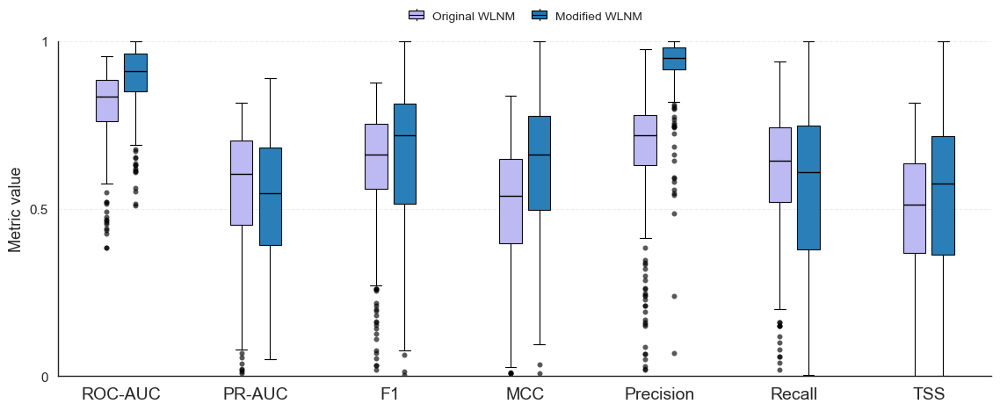

In [12]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.legend_handler import HandlerBase


sns.set_theme(
    context="paper",
    style="white",
    font_scale=1.1,
)




# ============================================================
# Raw predictive inputs (no Tukey filtering)
# ============================================================

import re


def _raw_foodweb_name(path):
    return re.sub(
        r"_tax_mass_results_random_wlnm_.*$",
        "",
        path.stem,
        flags=re.I,
    )


def load_raw_predictive_compat(
    result_root,
    expected_version,
    metric_specs,
    expected_runs,
    minimum_retained_runs,
    *,
    train_ratios=None,
    cvk_values=None,
    k_target=10,
    threshold=0.50,
    kfold=False,
    scenario=None,
):
    """Return raw web-level means in the legacy plotting schema.

    The legacy column names are retained only so that the original plotting,
    layout, scale, colour and export code remains byte-for-byte unchanged.
    MeanAfterTukey below is a compatibility alias for the arithmetic mean of
    every complete raw run unit; no Tukey fences or outlier exclusions occur.
    """
    metrics = [metric for metric, _ in metric_specs]
    labels = dict(metric_specs)
    files = sorted((result_root / "prediction_scores_logs").glob("*.csv"))
    if not files:
        raise FileNotFoundError(result_root / "prediction_scores_logs")

    required = {
        "Version",
        "TrainRatio",
        "ExperimentID",
        "Seed",
        "Threshold",
        "K",
        "CvK",
        "FoldID",
        "EmpiricalConnectance",
        *metrics,
    }
    frames = []
    for path in files:
        frame = pd.read_csv(
            path,
            usecols=lambda column: column in required,
        )
        missing = required.difference(frame.columns)
        if missing:
            raise ValueError(
                f"{path.name}: missing raw columns {sorted(missing)}"
            )
        frame["Foodweb"] = _raw_foodweb_name(path)
        frames.append(frame)

    raw = pd.concat(frames, ignore_index=True)
    for column in required.difference({"Version"}):
        raw[column] = pd.to_numeric(raw[column], errors="coerce")
    raw["TrainRatio"] = np.where(
        raw["TrainRatio"].abs().le(1.0),
        raw["TrainRatio"] * 100.0,
        raw["TrainRatio"],
    )
    raw = raw.loc[
        raw["Version"].eq(expected_version)
        & np.isclose(raw["Threshold"], threshold, atol=1e-9)
        & np.isclose(raw["K"], k_target, atol=1e-9)
    ].copy()
    if train_ratios is not None:
        requested = np.asarray(list(train_ratios), dtype=float)
        raw = raw.loc[
            raw["TrainRatio"].map(
                lambda value: np.isclose(
                    value,
                    requested,
                    atol=1e-8,
                ).any()
            )
        ].copy()
    if cvk_values is not None:
        raw = raw.loc[raw["CvK"].isin(cvk_values)].copy()
    if raw.empty:
        raise ValueError(f"No raw observations selected from {result_root}")

    metric_values = raw[metrics].to_numpy(float)
    if not np.isfinite(metric_values).all():
        raise ValueError(f"Non-finite raw predictive values in {result_root}")
    probability_metrics = [
        metric for metric in metrics if metric not in {"TestMCC", "TestTSS"}
    ]
    signed_metrics = [
        metric for metric in metrics if metric in {"TestMCC", "TestTSS"}
    ]
    if probability_metrics:
        values = raw[probability_metrics].to_numpy(float)
        if ((values < 0) | (values > 1)).any():
            raise ValueError("Raw probability metrics must be within [0, 1]")
    if signed_metrics:
        values = raw[signed_metrics].to_numpy(float)
        if ((values < -1) | (values > 1)).any():
            raise ValueError("Raw MCC/TSS values must be within [-1, 1]")

    group_columns = [
        "Foodweb",
        "Version",
        "TrainRatio",
        "Threshold",
        "K",
        "CvK",
    ]
    if kfold:
        experiment_columns = [*group_columns, "ExperimentID"]
        fold_check = (
            raw.groupby(experiment_columns, dropna=False)
            .agg(
                FoldRows=("FoldID", "size"),
                UniqueFolds=("FoldID", "nunique"),
            )
            .reset_index()
        )
        incomplete = fold_check.loc[
            ~fold_check["FoldRows"].eq(fold_check["CvK"])
            | ~fold_check["UniqueFolds"].eq(fold_check["CvK"])
        ]
        if not incomplete.empty:
            raise ValueError(
                "Incomplete repeated-CV experiments found:\n"
                + incomplete.head(10).to_string(index=False)
            )
        run_units = (
            raw.groupby(
                experiment_columns,
                dropna=False,
                as_index=False,
            )
            .agg(
                **{
                    metric: (metric, "mean")
                    for metric in metrics
                },
                EmpiricalConnectance=(
                    "EmpiricalConnectance",
                    "first",
                ),
            )
        )
    else:
        experiment_columns = [*group_columns, "ExperimentID"]
        if raw.duplicated(experiment_columns).any():
            raise ValueError(f"Duplicate raw ExperimentID rows in {result_root}")
        run_units = raw

    counts = run_units.groupby(group_columns, dropna=False).size()
    if not counts.eq(expected_runs).all():
        raise ValueError(
            f"{result_root.name}: expected {expected_runs} complete raw "
            "run units per group; observed "
            f"{counts.value_counts().to_dict()}"
        )

    wide = (
        run_units.groupby(
            group_columns,
            dropna=False,
            as_index=False,
        )
        .agg(
            **{
                metric: (metric, "mean")
                for metric in metrics
            },
            EmpiricalConnectance=(
                "EmpiricalConnectance",
                "first",
            ),
            RawRunUnits=("ExperimentID", "size"),
        )
    )
    long = wide.melt(
        id_vars=[
            *group_columns,
            "EmpiricalConnectance",
            "RawRunUnits",
        ],
        value_vars=metrics,
        var_name="Metric",
        value_name="MeanAfterTukey",
    )
    long["Scenario"] = scenario or result_root.name
    long["MetricLabel"] = long["Metric"].map(labels)
    long["MetricFamily"] = "predictive"
    long["SourceColumn"] = long["Metric"]
    long["ReferenceColumn"] = ""
    long["MeanBeforeTukey"] = long["MeanAfterTukey"]
    long["TotalRunUnits"] = long["RawRunUnits"]
    long["ValidRunsBeforeTukey"] = long["RawRunUnits"]
    long["InvalidRunsBeforeTukey"] = 0
    long["OutlierRunsExcluded"] = 0
    long["RetainedRunsAfterTukey"] = long["RawRunUnits"]
    long["ExpectedRuns"] = expected_runs
    long["MinimumRetainedRuns"] = minimum_retained_runs
    long["MeetsMinimumRetainedRuns"] = 1
    long["ReferenceValue"] = long["EmpiricalConnectance"]
    return long

# ============================================================
# Locate repository root
# ============================================================

def find_repo_root(start=Path.cwd()):
    start = Path(start).resolve()

    candidates = [start, *start.parents]

    # Fallback for notebooks launched outside the repository.
    fallback = Path(
        "/Users/acw792/Developer/qmul-phd-framework"
    )

    if fallback not in candidates:
        candidates.append(fallback)

    for candidate in candidates:
        if (
            (candidate / "src/matlab").is_dir()
            and (candidate / "docs").is_dir()
        ):
            return candidate

    raise RuntimeError(
        "Could not locate the qmul-phd-framework repository."
    )


REPO_ROOT = find_repo_root()


# ============================================================
# Final configuration
# ============================================================

TRAIN_RATIO_TARGET = 90
CLASSIFICATION_THRESHOLD = 0.50
NODES_THRESHOLD = 0

MINIMUM_RETAINED_RUNS = 25

# Existing Original results
ORIGINAL_EXPECTED_RUNS = 50
ORIGINAL_MINIMUM_RETAINED_FRACTION = 0.50
ORIGINAL_PROTOCOL_NAME = (
    "tukey_iqr_1p5_min50pct_threshold0p50_v1"
)

# New Directed-negative results
DIR_NEG_EXPECTED_RUNS = 100
DIR_NEG_MINIMUM_RETAINED_FRACTION = 0.25
DIR_NEG_PROTOCOL_NAME = (
    "tukey_iqr_1p5_min25runs_threshold0p50_v1"
)

assert MINIMUM_RETAINED_RUNS == int(
    np.ceil(
        ORIGINAL_EXPECTED_RUNS
        * ORIGINAL_MINIMUM_RETAINED_FRACTION
    )
)

assert MINIMUM_RETAINED_RUNS == int(
    np.ceil(
        DIR_NEG_EXPECTED_RUNS
        * DIR_NEG_MINIMUM_RETAINED_FRACTION
    )
)


# ============================================================
# Result roots
# ============================================================

ORIGINAL_ROOT = (
    REPO_ROOT
    / "src/matlab/data"
    / (
        "result_wlnm_original_50x290_train90_thresh0p50_"
        "legacy_uppertriangular_checkconnfalse_"
        "adaptivefalse_Apocrita"
    )
)

DIR_NEG_ROOT = (
    REPO_ROOT
    / "src/matlab/data"
    / (
        "result_wlnm_dir_neg_roleonly_trophicv2_"
        "100x290_train10-90_Apocrita_20260910_011848"
    )
)


# ============================================================
# Raw prediction inputs
# ============================================================

ORIGINAL_INPUT = ORIGINAL_ROOT
DIR_NEG_INPUT = DIR_NEG_ROOT

FOODWEB_CSV = (
    REPO_ROOT
    / "src/matlab/data/foodwebs_mat"
    / "foodweb_metrics_ecosystem.csv"
)

# ============================================================
# Publication output
# ============================================================

OUT_DIR = DIR_NEG_ROOT / "figures_raw_unfiltered"

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

OUTPUT_STEM = "figure_3_original50_vs_dir_neg100_train90_raw_unfiltered"

PNG_PATH = OUT_DIR / f"{OUTPUT_STEM}.png"
SVG_PATH = OUT_DIR / f"{OUTPUT_STEM}.svg"
PDF_PATH = OUT_DIR / f"{OUTPUT_STEM}.pdf"

SUMMARY_PATH = (
    OUT_DIR
    / f"{OUTPUT_STEM}_summary.csv"
)

RETENTION_PATH = (
    OUT_DIR
    / f"{OUTPUT_STEM}_raw_run_counts.csv"
)


# ============================================================
# Metrics
# ============================================================

METRIC_SPECS = [
    ("ROC_AUC", "ROC-AUC"),
    ("PR_AUC", "PR-AUC"),
    ("F1Score", "F1"),
    ("TestMCC", "MCC"),
    ("Precision", "Precision"),
    ("Recall", "Recall"),
    ("TestTSS", "TSS"),
]

METRIC_ORDER = [
    metric
    for metric, _ in METRIC_SPECS
]

METRIC_LABELS = dict(METRIC_SPECS)

VERSION_ORDER = [
    "original",
    "dir_neg",
]

VERSION_LABELS = {
    "original": "Original WLNM",
    "dir_neg": "Modified WLNM",
}

VERSION_PALETTE = {
    "original": "#BAB6F2",
    "dir_neg": "#1F78B4",
}

SHOW_WEB_LEVEL_FLIERS = True


# ============================================================
# Validate required raw inputs
# ============================================================

required_inputs = {
    "Original WLNM raw result root": ORIGINAL_INPUT,
    "Directed-negative WLNM raw result root": DIR_NEG_INPUT,
    "Food-web metadata": FOODWEB_CSV,
}

missing_inputs = [
    f"{label}:\n  {path}"
    for label, path in required_inputs.items()
    if not (
        path.is_file()
        if path == FOODWEB_CSV
        else (path / "prediction_scores_logs").is_dir()
    )
]
if missing_inputs:
    raise FileNotFoundError("\n\n".join(missing_inputs))

print(f"[INFO] Repository: {REPO_ROOT}")
print("[INFO] Using raw prediction inputs; no Tukey filtering.")

# ============================================================
# Helpers
# ============================================================

def normalize_fw_label(name):
    name = str(name).strip()

    for suffix in [
        ".mat",
        ".csv",
    ]:
        if name.endswith(suffix):
            name = name[: -len(suffix)]

    name = name.replace(" ", "_")

    for token in [
        "_results_",
        "_result_",
        "_results",
        "_random",
        "_tax_mass",
        "_tax",
        "_mass",
    ]:
        name = name.replace(token, "_")

    return "_".join(
        part
        for part in name.split("_")
        if part
    ).lower()


def load_raw_figure_input(
    path,
    version,
    expected_runs,
    minimum_retained_runs,
):
    expected_version = {
        "original": "WLNM_original",
        "dir_neg": "WLNM_dir_neg",
        "bodymass": "WLNM_dir_neg",
    }[version]
    df = load_raw_predictive_compat(
        path,
        expected_version,
        METRIC_SPECS,
        expected_runs,
        expected_runs,
        train_ratios=[TRAIN_RATIO_TARGET],
    )
    df["Version"] = version
    df["Value"] = df["MeanAfterTukey"]
    df["FW_KEY"] = df["Foodweb"].apply(normalize_fw_label)
    if df.duplicated(["FW_KEY", "Version", "Metric"]).any():
        raise ValueError(f"Duplicated raw foodweb-metric rows in {path}")
    print(
        f"[INFO] {version}: all "
        f"{int(df['RetainedRunsAfterTukey'].min())} raw run units used."
    )
    return df

# ============================================================
# Load raw unfiltered values
# ============================================================

original_df = load_raw_figure_input(
    ORIGINAL_INPUT,
    version="original",
    expected_runs=ORIGINAL_EXPECTED_RUNS,
    minimum_retained_runs=MINIMUM_RETAINED_RUNS,
)

dir_neg_df = load_raw_figure_input(
    DIR_NEG_INPUT,
    version="dir_neg",
    expected_runs=DIR_NEG_EXPECTED_RUNS,
    minimum_retained_runs=MINIMUM_RETAINED_RUNS,
)

combined_df = pd.concat(
    [
        original_df,
        dir_neg_df,
    ],
    ignore_index=True,
)


# ============================================================
# Apply node-count filter
# ============================================================

metadata_df = pd.read_csv(
    FOODWEB_CSV
)

metadata_df.columns = [
    column.strip()
    for column in metadata_df.columns
]

foodweb_column = next(
    (
        column
        for column in metadata_df.columns
        if column.lower() == "foodweb"
    ),
    None,
)

nodes_column = next(
    (
        column
        for column in metadata_df.columns
        if column.lower() in {
            "nodes",
            "n_nodes",
            "num_nodes",
            "nodecount",
            "s",
        }
    ),
    None,
)

if (
    foodweb_column is None
    or nodes_column is None
):
    raise ValueError(
        "Could not identify Foodweb and Nodes "
        "columns in the metadata file."
    )

metadata_df[nodes_column] = pd.to_numeric(
    metadata_df[nodes_column],
    errors="coerce",
)

metadata_df["FW_KEY"] = (
    metadata_df[foodweb_column]
    .apply(normalize_fw_label)
)

metadata_df = (
    metadata_df[
        [
            "FW_KEY",
            foodweb_column,
            nodes_column,
        ]
    ]
    .drop_duplicates(
        subset=["FW_KEY"]
    )
)

allowed_fw_keys = set(
    metadata_df.loc[
        metadata_df[nodes_column]
        >= NODES_THRESHOLD,
        "FW_KEY",
    ]
)

print(
    f"[INFO] Food webs satisfying "
    f"Nodes >= {NODES_THRESHOLD}: "
    f"{len(allowed_fw_keys)}"
)

combined_df = combined_df[
    combined_df["FW_KEY"]
    .isin(allowed_fw_keys)
].copy()

if combined_df.empty:
    raise RuntimeError(
        "No retained food-web metrics remain "
        "after the node-count filter."
    )


# ============================================================
# Enforce paired food webs separately per metric
# ============================================================

paired_frames = []
pairing_rows = []

for metric in METRIC_ORDER:
    metric_df = combined_df[
        combined_df["Metric"].eq(metric)
    ].copy()

    original_keys = set(
        metric_df.loc[
            metric_df["Version"].eq("original"),
            "FW_KEY",
        ]
    )

    dir_neg_keys = set(
        metric_df.loc[
            metric_df["Version"].eq("dir_neg"),
            "FW_KEY",
        ]
    )

    common_keys = (
        original_keys
        .intersection(dir_neg_keys)
    )

    pairing_rows.append(
        {
            "Metric": METRIC_LABELS[metric],
            "Original retained food webs": len(
                original_keys
            ),
            "Directed-negative retained food webs": len(
                dir_neg_keys
            ),
            "Paired food webs": len(
                common_keys
            ),
            "Original-only food webs": len(
                original_keys
                - dir_neg_keys
            ),
            "Directed-negative-only food webs": len(
                dir_neg_keys
                - original_keys
            ),
        }
    )

    paired_metric_df = metric_df[
        metric_df["FW_KEY"].isin(
            common_keys
        )
    ].copy()

    paired_frames.append(
        paired_metric_df
    )

plot_df = pd.concat(
    paired_frames,
    ignore_index=True,
)

if plot_df.empty:
    raise RuntimeError(
        "No paired food webs remain for plotting."
    )

pairing_table = pd.DataFrame(
    pairing_rows
)

print(
    "\n=== Retained and paired food webs "
    "by metric ==="
)

display(pairing_table)


# ============================================================
# Retention details
# ============================================================

retention_table = (
    plot_df
    .groupby(
        [
            "Version",
            "Metric",
        ],
        as_index=False,
    )
    .agg(
        FoodWebs=(
            "FW_KEY",
            "nunique",
        ),
        MinimumRetainedRuns=(
            "RetainedRunsAfterTukey",
            "min",
        ),
        MedianRetainedRuns=(
            "RetainedRunsAfterTukey",
            "median",
        ),
        MaximumRetainedRuns=(
            "RetainedRunsAfterTukey",
            "max",
        ),
    )
)

retention_table["Version"] = (
    retention_table["Version"]
    .map(VERSION_LABELS)
)

retention_table["Metric"] = (
    retention_table["Metric"]
    .map(METRIC_LABELS)
)

retention_table = retention_table[
    [
        "Version",
        "Metric",
        "FoodWebs",
        "MinimumRetainedRuns",
        "MedianRetainedRuns",
        "MaximumRetainedRuns",
    ]
]

print(
    "\n=== Raw run-count details "
    "for paired food webs ==="
)

display(retention_table)


# ============================================================
# Web-level summary
# ============================================================

summary_table = (
    plot_df
    .groupby(
        [
            "Version",
            "Metric",
        ],
        as_index=False,
    )
    .agg(
        FoodWebs=(
            "FW_KEY",
            "nunique",
        ),
        Mean=(
            "Value",
            "mean",
        ),
        Median=(
            "Value",
            "median",
        ),
        SD=(
            "Value",
            "std",
        ),
        Variance=(
            "Value",
            "var",
        ),
    )
)

summary_table["Version"] = (
    summary_table["Version"]
    .map(VERSION_LABELS)
)

summary_table["Metric"] = (
    summary_table["Metric"]
    .map(METRIC_LABELS)
)

for column in [
    "Mean",
    "Median",
    "SD",
    "Variance",
]:
    summary_table[column] = (
        summary_table[column]
        .round(4)
    )

print(
    "\n=== Raw-unfiltered web-level "
    "predictive metric summary ==="
)

display(summary_table)


# ============================================================
# Custom miniature boxplot legend
# ============================================================

class HandlerMiniBoxplot(HandlerBase):
    def create_artists(
        self,
        legend,
        orig_handle,
        xdescent,
        ydescent,
        width,
        height,
        fontsize,
        trans,
    ):
        facecolor = orig_handle["facecolor"]

        edgecolor = orig_handle.get(
            "edgecolor",
            "black",
        )

        linewidth = orig_handle.get(
            "linewidth",
            0.6,
        )

        center_x = (
            xdescent
            + 0.5 * width
        )

        center_y = (
            ydescent
            + 0.44 * height
        )

        box_width = (
            0.8 * width
        )

        box_height = (
            0.8 * height
        )

        box_x = (
            center_x
            - box_width / 2
        )

        box_y = (
            center_y
            - box_height / 2
        )

        whisker_top_y = (
            box_y
            + box_height
            + 0.18 * height
        )

        whisker_bottom_y = (
            box_y
            - 0.18 * height
        )

        box = Rectangle(
            (
                box_x,
                box_y,
            ),
            box_width,
            box_height,
            facecolor=facecolor,
            edgecolor=edgecolor,
            linewidth=linewidth,
            transform=trans,
        )

        median = Line2D(
            [
                box_x,
                box_x + box_width,
            ],
            [
                center_y,
                center_y,
            ],
            color=edgecolor,
            linewidth=linewidth,
            transform=trans,
        )

        upper_whisker = Line2D(
            [
                center_x,
                center_x,
            ],
            [
                box_y + box_height,
                whisker_top_y,
            ],
            color=edgecolor,
            linewidth=linewidth,
            transform=trans,
        )

        lower_whisker = Line2D(
            [
                center_x,
                center_x,
            ],
            [
                whisker_bottom_y,
                box_y,
            ],
            color=edgecolor,
            linewidth=linewidth,
            transform=trans,
        )

        return [
            box,
            median,
            upper_whisker,
            lower_whisker,
        ]


# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(
    figsize=(11.5, 4.8)
)

group_gap = 1.5

group_centers = (
    1.0
    + np.arange(
        len(METRIC_SPECS)
    )
    * group_gap
)

offsets = {
    "original": -0.16,
    "dir_neg": 0.16,
}

box_width = 0.25

for version in VERSION_ORDER:
    version_data = []
    version_positions = []

    for metric_index, (
        metric,
        metric_label,
    ) in enumerate(METRIC_SPECS):
        values = (
            plot_df.loc[
                (
                    plot_df["Version"].eq(
                        version
                    )
                )
                & (
                    plot_df["Metric"].eq(
                        metric
                    )
                ),
                "Value",
            ]
            .dropna()
            .to_numpy()
        )

        if len(values) == 0:
            continue

        version_data.append(
            values
        )

        version_positions.append(
            group_centers[metric_index]
            + offsets[version]
        )

    if not version_data:
        raise RuntimeError(
            f"No plotting values found for version: {version}"
        )

    ax.boxplot(
        version_data,
        positions=version_positions,
        widths=box_width,
        patch_artist=True,
        manage_ticks=False,
        showfliers=SHOW_WEB_LEVEL_FLIERS,
        boxprops={
            "facecolor": VERSION_PALETTE[version],
            "edgecolor": "black",
            "linewidth": 0.8,
            "alpha": 0.95,
        },
        medianprops={
            "color": "black",
            "linewidth": 1.0,
        },
        whiskerprops={
            "color": "black",
            "linewidth": 0.8,
        },
        capprops={
            "color": "black",
            "linewidth": 0.8,
        },
        flierprops={
            "marker": "o",
            "markersize": 4,
            "markerfacecolor": "black",
            "markeredgecolor": "black",
            "markeredgewidth": 0.2,
            "alpha": 0.65,
        },
    )


# ============================================================
# Axes and legend
# ============================================================

legend_handles = [
    {
        "facecolor": VERSION_PALETTE[version],
        "edgecolor": "black",
        "linewidth": 0.8,
    }
    for version in VERSION_ORDER
]

ax.set_xlim(
    group_centers[0] - 0.7,
    group_centers[-1] + 0.7,
)

ax.set_ylim(
    0,
    1.0,
)

ax.set_xticks(
    group_centers,
    labels=[
        metric_label
        for _, metric_label in METRIC_SPECS
    ],
)

plt.setp(
    ax.get_xticklabels(),
    rotation=0,
    fontsize=14,
)

ax.set_ylabel(
    "Metric value",
    fontsize=13,
)

ax.set_xlabel("")

ax.set_yticks(
    [
        0,
        0.5,
        1.0,
    ]
)

ax.set_yticklabels(
    [
        "0",
        "0.5",
        "1",
    ]
)

ax.tick_params(
    axis="y",
    labelsize=11,
)

ax.grid(
    True,
    axis="y",
    linestyle="--",
    alpha=0.35,
)

ax.legend(
    handles=legend_handles,
    labels=[
        VERSION_LABELS[version]
        for version in VERSION_ORDER
    ],
    handler_map={
        dict: HandlerMiniBoxplot()
    },
    loc="lower center",
    bbox_to_anchor=(
        0.5,
        1.03,
    ),
    ncol=len(VERSION_ORDER),
    frameon=False,
    fontsize=10,
    handlelength=1.5,
    handleheight=0.9,
    handletextpad=0.6,
    borderpad=0.2,
    labelspacing=0.45,
    columnspacing=1.2,
)

sns.despine(
    ax=ax
)

plt.tight_layout()


# ============================================================
# Export
# ============================================================

fig.savefig(
    PNG_PATH,
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    SVG_PATH,
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    PDF_PATH,
    bbox_inches="tight",
    facecolor="white",
)

summary_table.to_csv(
    SUMMARY_PATH,
    index=False,
)

retention_table.to_csv(
    RETENTION_PATH,
    index=False,
)

print(
    "\n[INFO] Saved publication-ready outputs:"
)

print(f"  PNG: {PNG_PATH}")
print(f"  SVG: {SVG_PATH}")
print(f"  PDF: {PDF_PATH}")
print(f"  Summary: {SUMMARY_PATH}")
print(f"  Raw run counts: {RETENTION_PATH}")

print(
    "\n[INFO] Final directed configuration:"
)

print(
    f"  classification_threshold="
    f"{CLASSIFICATION_THRESHOLD}"
)

print(
    "  aggregation=all raw runs; no Tukey filtering"
)

print(
    "\n[INFO] Final raw-run configurations:\n"
    f"  Original WLNM: all {ORIGINAL_EXPECTED_RUNS} raw runs\n"
    f"  Modified WLNM: all {DIR_NEG_EXPECTED_RUNS} raw runs"
)

plt.show()

[INFO] Repository: /Users/acw792/Developer/qmul-phd-framework
[INFO] Result root: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848
[INFO] Raw prediction input; no Tukey filtering.
[INFO] Raw run completeness validated: at least 100 of 100 runs per food web and metric.
[INFO] Actual retained-run range: 100–100
[INFO] Food webs after node filter: 290
[INFO] Training ratios: [10, 20, 30, 40, 50, 60, 70, 80, 90]
[INFO] Ecosystems: ['lakes', 'marine', 'streams', 'terrestrial aboveground', 'terrestrial belowground']

=== Raw run counts by training ratio and metric ===


,TRAINRATIO,Metric,MetricLabel,FoodWebs,MinimumRetainedRuns,MedianRetainedRuns,MaximumRetainedRuns
0,10,F1Score,F1,290,100,100.0,100
1,10,PR_AUC,PR-AUC,290,100,100.0,100
2,10,Precision,Precision,290,100,100.0,100
3,10,ROC_AUC,ROC-AUC,290,100,100.0,100
4,10,Recall,Recall,290,100,100.0,100
...,...,...,...,...,...,...,...
58,90,Precision,Precision,290,100,100.0,100
59,90,ROC_AUC,ROC-AUC,290,100,100.0,100
60,90,Recall,Recall,290,100,100.0,100
61,90,TestMCC,MCC,290,100,100.0,100


[INFO] Food webs represented: 290

[INFO] Saved publication-ready outputs:
  PNG: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/figures_raw_unfiltered/figure_4_predictive_metrics_by_train_ratio_raw_unfiltered.png
  SVG: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/figures_raw_unfiltered/figure_4_predictive_metrics_by_train_ratio_raw_unfiltered.svg
  PDF: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/figures_raw_unfiltered/figure_4_predictive_metrics_by_train_ratio_raw_unfiltered.pdf
  Summary: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/figures_raw_unfiltered/figure_4_predictive_metrics_by_train_ratio_raw_

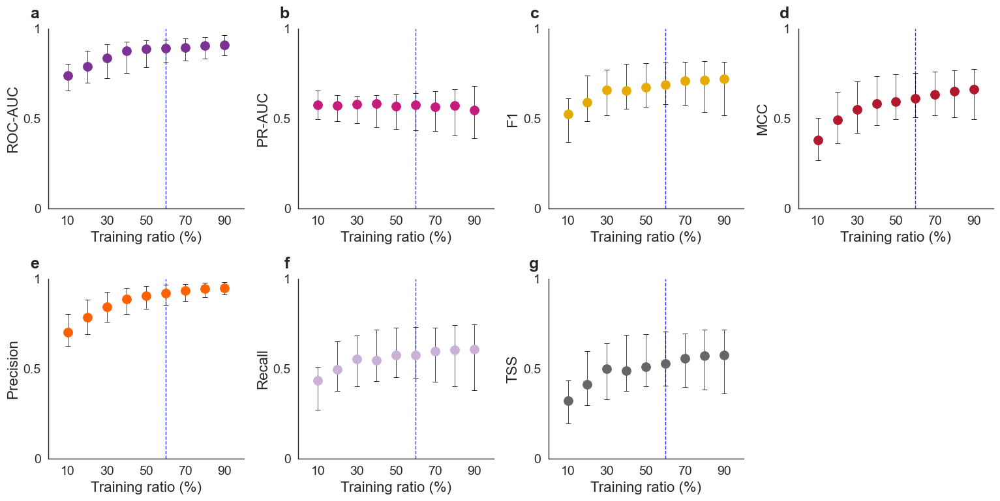

In [13]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from IPython.display import display


sns.set_context(
    "paper",
    font_scale=1.35,
)

sns.set_style("white")




# ============================================================
# Raw predictive inputs (no Tukey filtering)
# ============================================================

import re


def _raw_foodweb_name(path):
    return re.sub(
        r"_tax_mass_results_random_wlnm_.*$",
        "",
        path.stem,
        flags=re.I,
    )


def load_raw_predictive_compat(
    result_root,
    expected_version,
    metric_specs,
    expected_runs,
    minimum_retained_runs,
    *,
    train_ratios=None,
    cvk_values=None,
    k_target=10,
    threshold=0.50,
    kfold=False,
    scenario=None,
):
    """Return raw web-level means in the legacy plotting schema.

    The legacy column names are retained only so that the original plotting,
    layout, scale, colour and export code remains byte-for-byte unchanged.
    MeanAfterTukey below is a compatibility alias for the arithmetic mean of
    every complete raw run unit; no Tukey fences or outlier exclusions occur.
    """
    metrics = [metric for metric, _ in metric_specs]
    labels = dict(metric_specs)
    files = sorted((result_root / "prediction_scores_logs").glob("*.csv"))
    if not files:
        raise FileNotFoundError(result_root / "prediction_scores_logs")

    required = {
        "Version",
        "TrainRatio",
        "ExperimentID",
        "Seed",
        "Threshold",
        "K",
        "CvK",
        "FoldID",
        "EmpiricalConnectance",
        *metrics,
    }
    frames = []
    for path in files:
        frame = pd.read_csv(
            path,
            usecols=lambda column: column in required,
        )
        missing = required.difference(frame.columns)
        if missing:
            raise ValueError(
                f"{path.name}: missing raw columns {sorted(missing)}"
            )
        frame["Foodweb"] = _raw_foodweb_name(path)
        frames.append(frame)

    raw = pd.concat(frames, ignore_index=True)
    for column in required.difference({"Version"}):
        raw[column] = pd.to_numeric(raw[column], errors="coerce")
    raw["TrainRatio"] = np.where(
        raw["TrainRatio"].abs().le(1.0),
        raw["TrainRatio"] * 100.0,
        raw["TrainRatio"],
    )
    raw = raw.loc[
        raw["Version"].eq(expected_version)
        & np.isclose(raw["Threshold"], threshold, atol=1e-9)
        & np.isclose(raw["K"], k_target, atol=1e-9)
    ].copy()
    if train_ratios is not None:
        requested = np.asarray(list(train_ratios), dtype=float)
        raw = raw.loc[
            raw["TrainRatio"].map(
                lambda value: np.isclose(
                    value,
                    requested,
                    atol=1e-8,
                ).any()
            )
        ].copy()
    if cvk_values is not None:
        raw = raw.loc[raw["CvK"].isin(cvk_values)].copy()
    if raw.empty:
        raise ValueError(f"No raw observations selected from {result_root}")

    metric_values = raw[metrics].to_numpy(float)
    if not np.isfinite(metric_values).all():
        raise ValueError(f"Non-finite raw predictive values in {result_root}")
    probability_metrics = [
        metric for metric in metrics if metric not in {"TestMCC", "TestTSS"}
    ]
    signed_metrics = [
        metric for metric in metrics if metric in {"TestMCC", "TestTSS"}
    ]
    if probability_metrics:
        values = raw[probability_metrics].to_numpy(float)
        if ((values < 0) | (values > 1)).any():
            raise ValueError("Raw probability metrics must be within [0, 1]")
    if signed_metrics:
        values = raw[signed_metrics].to_numpy(float)
        if ((values < -1) | (values > 1)).any():
            raise ValueError("Raw MCC/TSS values must be within [-1, 1]")

    group_columns = [
        "Foodweb",
        "Version",
        "TrainRatio",
        "Threshold",
        "K",
        "CvK",
    ]
    if kfold:
        experiment_columns = [*group_columns, "ExperimentID"]
        fold_check = (
            raw.groupby(experiment_columns, dropna=False)
            .agg(
                FoldRows=("FoldID", "size"),
                UniqueFolds=("FoldID", "nunique"),
            )
            .reset_index()
        )
        incomplete = fold_check.loc[
            ~fold_check["FoldRows"].eq(fold_check["CvK"])
            | ~fold_check["UniqueFolds"].eq(fold_check["CvK"])
        ]
        if not incomplete.empty:
            raise ValueError(
                "Incomplete repeated-CV experiments found:\n"
                + incomplete.head(10).to_string(index=False)
            )
        run_units = (
            raw.groupby(
                experiment_columns,
                dropna=False,
                as_index=False,
            )
            .agg(
                **{
                    metric: (metric, "mean")
                    for metric in metrics
                },
                EmpiricalConnectance=(
                    "EmpiricalConnectance",
                    "first",
                ),
            )
        )
    else:
        experiment_columns = [*group_columns, "ExperimentID"]
        if raw.duplicated(experiment_columns).any():
            raise ValueError(f"Duplicate raw ExperimentID rows in {result_root}")
        run_units = raw

    counts = run_units.groupby(group_columns, dropna=False).size()
    if not counts.eq(expected_runs).all():
        raise ValueError(
            f"{result_root.name}: expected {expected_runs} complete raw "
            "run units per group; observed "
            f"{counts.value_counts().to_dict()}"
        )

    wide = (
        run_units.groupby(
            group_columns,
            dropna=False,
            as_index=False,
        )
        .agg(
            **{
                metric: (metric, "mean")
                for metric in metrics
            },
            EmpiricalConnectance=(
                "EmpiricalConnectance",
                "first",
            ),
            RawRunUnits=("ExperimentID", "size"),
        )
    )
    long = wide.melt(
        id_vars=[
            *group_columns,
            "EmpiricalConnectance",
            "RawRunUnits",
        ],
        value_vars=metrics,
        var_name="Metric",
        value_name="MeanAfterTukey",
    )
    long["Scenario"] = scenario or result_root.name
    long["MetricLabel"] = long["Metric"].map(labels)
    long["MetricFamily"] = "predictive"
    long["SourceColumn"] = long["Metric"]
    long["ReferenceColumn"] = ""
    long["MeanBeforeTukey"] = long["MeanAfterTukey"]
    long["TotalRunUnits"] = long["RawRunUnits"]
    long["ValidRunsBeforeTukey"] = long["RawRunUnits"]
    long["InvalidRunsBeforeTukey"] = 0
    long["OutlierRunsExcluded"] = 0
    long["RetainedRunsAfterTukey"] = long["RawRunUnits"]
    long["ExpectedRuns"] = expected_runs
    long["MinimumRetainedRuns"] = minimum_retained_runs
    long["MeetsMinimumRetainedRuns"] = 1
    long["ReferenceValue"] = long["EmpiricalConnectance"]
    return long

# ============================================================
# Locate repository root
# ============================================================

def find_repo_root(start=Path.cwd()):
    start = Path(start).resolve()

    candidates = [start, *start.parents]

    fallback = Path(
        "/Users/acw792/Developer/qmul-phd-framework"
    )

    if fallback not in candidates:
        candidates.append(fallback)

    for candidate in candidates:
        if (
            (candidate / "src/matlab").is_dir()
            and (candidate / "docs").is_dir()
        ):
            return candidate

    raise RuntimeError(
        "Could not locate the qmul-phd-framework repository."
    )


REPO_ROOT = find_repo_root()


# ============================================================
# Final role-only experimental configuration
# ============================================================

CLASSIFICATION_THRESHOLD = 0.50
NODES_THRESHOLD = 0

# Tukey is applied independently across 100 runs for each
# Foodweb × TrainRatio × Metric group.
#
# Keep the agreed absolute minimum of 25 retained runs.
EXPECTED_RUNS = 100
MINIMUM_RETAINED_FRACTION = 1.00
MINIMUM_RETAINED_RUNS = 100

PROTOCOL_NAME = (
    "tukey_iqr_1p5_min25runs_threshold0p50_v1"
)

EXPECTED_SCENARIO = (
    "result_wlnm_dir_neg_roleonly_trophicv2_"
    "100x290_train10-90_Apocrita_20260910_011848"
)

calculated_minimum_runs = int(
    np.ceil(
        EXPECTED_RUNS
        * MINIMUM_RETAINED_FRACTION
    )
)

assert calculated_minimum_runs == MINIMUM_RETAINED_RUNS, (
    "The configured minimum retained runs is inconsistent "
    "with the expected number of runs and retained fraction."
)


# ============================================================
# Final role-only result root
# ============================================================

RESULT_ROOT = (
    REPO_ROOT
    / "src/matlab/data"
    / (
        "result_wlnm_dir_neg_roleonly_trophicv2_"
        "100x290_train10-90_Apocrita_20260910_011848"
    )
)

RETENTION_ROOT = (
    RESULT_ROOT
    / "retention_protocol"
    / PROTOCOL_NAME
)

RETENTION_MANIFEST_PATH = (
    RETENTION_ROOT
    / "retention_manifest.json"
)

RESULTS_FILE = RESULT_ROOT

FOODWEB_CSV = (
    REPO_ROOT
    / "src/matlab/data/foodwebs_mat"
    / "foodweb_metrics_ecosystem.csv"
)


# ============================================================
# Output paths
# ============================================================

OUT_DIR = RESULT_ROOT / "figures_raw_unfiltered"

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

OUTPUT_STEM = "figure_4_predictive_metrics_by_train_ratio_raw_unfiltered"

PNG_PATH = OUT_DIR / f"{OUTPUT_STEM}.png"
SVG_PATH = OUT_DIR / f"{OUTPUT_STEM}.svg"
PDF_PATH = OUT_DIR / f"{OUTPUT_STEM}.pdf"

SUMMARY_PATH = (
    OUT_DIR
    / f"{OUTPUT_STEM}_summary.csv"
)

RETENTION_PATH = (
    OUT_DIR
    / f"{OUTPUT_STEM}_raw_run_counts.csv"
)


# ============================================================
# Metrics
# ============================================================

METRICS = [
    "ROC_AUC",
    "PR_AUC",
    "F1Score",
    "TestMCC",
    "Precision",
    "Recall",
    "TestTSS",
]

METRIC_LABELS = {
    "ROC_AUC": "ROC-AUC",
    "PR_AUC": "PR-AUC",
    "F1Score": "F1",
    "TestMCC": "MCC",
    "Precision": "Precision",
    "Recall": "Recall",
    "TestTSS": "TSS",
}

METRIC_PALETTE = {
    "ROC-AUC": "#7B3294",
    "PR-AUC": "#C51B7D",
    "F1": "#E6AB02",
    "MCC": "#B2182B",
    "Precision": "#FE6100",
    "Recall": "#CAB2D6",
    "TSS": "#666666",
}

SHOW_GRID = False

Y_MIN = 0.0
Y_MAX = 1.0

INDEPENDENT_Y = False
Y_PADDING = 0.02

REFERENCE_TRAIN_RATIO = 60


# ============================================================
# Validate raw inputs
# ============================================================

if not (RESULT_ROOT / "prediction_scores_logs").is_dir():
    raise FileNotFoundError(RESULT_ROOT / "prediction_scores_logs")
if not FOODWEB_CSV.is_file():
    raise FileNotFoundError(FOODWEB_CSV)

print(f"[INFO] Repository: {REPO_ROOT}")
print(f"[INFO] Result root: {RESULT_ROOT}")
print("[INFO] Raw prediction input; no Tukey filtering.")

# ============================================================
# Food-web name normalisation
# ============================================================

def normalize_fw_label(name):
    name = str(name).strip()

    for suffix in [
        ".mat",
        ".csv",
    ]:
        if name.endswith(suffix):
            name = name[: -len(suffix)]

    name = name.replace(
        " ",
        "_",
    )

    for token in [
        "_results_",
        "_result_",
        "_results",
        "_random",
        "_tax_mass",
        "_tax",
        "_mass",
    ]:
        name = name.replace(
            token,
            "_",
        )

    return "_".join(
        part
        for part in name.split("_")
        if part
    ).lower()


# ============================================================
# Load raw unfiltered web-level results
# ============================================================

df = load_raw_predictive_compat(
    RESULT_ROOT,
    "WLNM_dir_neg",
        [(metric, METRIC_LABELS[metric]) for metric in METRICS],
        EXPECTED_RUNS,
        EXPECTED_RUNS,
    train_ratios=range(10, 100, 10),
    scenario=EXPECTED_SCENARIO,
)

# ============================================================
# Select the final role-only configuration
# ============================================================

target_df = df[
    df["Scenario"].eq(
        EXPECTED_SCENARIO
    )
    & df["Version"].eq(
        "WLNM_dir_neg"
    )
    & df["MetricFamily"].eq(
        "predictive"
    )
    & df["Metric"].isin(
        METRICS
    )
    & np.isclose(
        df["Threshold"],
        CLASSIFICATION_THRESHOLD,
        atol=1e-9,
        equal_nan=False,
    )
].copy()

if target_df.empty:
    raise RuntimeError(
        "No predictive results match the final "
        "role-only configuration."
    )


# ============================================================
# Validate minimum 25 retained runs
# ============================================================

observed_minimums = set(
    target_df["MinimumRetainedRuns"]
    .dropna()
    .astype(int)
    .unique()
)

if observed_minimums != {
    MINIMUM_RETAINED_RUNS
}:
    raise ValueError(
        "The Tukey figure input was not processed with "
        f"the expected minimum of "
        f"{MINIMUM_RETAINED_RUNS} retained runs.\n"
        f"Observed values: {sorted(observed_minimums)}"
    )

incorrect_retention = target_df[
    target_df["MeetsMinimumRetainedRuns"].eq(1)
    & target_df["RetainedRunsAfterTukey"].lt(
        MINIMUM_RETAINED_RUNS
    )
]

if not incorrect_retention.empty:
    display(
        incorrect_retention[
            [
                "Foodweb",
                "TrainRatio",
                "Metric",
                "RetainedRunsAfterTukey",
                "MinimumRetainedRuns",
                "MeetsMinimumRetainedRuns",
            ]
        ]
    )

    raise ValueError(
        "At least one group is marked as retained despite "
        f"having fewer than {MINIMUM_RETAINED_RUNS} runs."
    )

below_minimum = target_df[
    target_df["RetainedRunsAfterTukey"].lt(
        MINIMUM_RETAINED_RUNS
    )
]

if not below_minimum.empty:
    print(
        "[INFO] Groups excluded because fewer than "
        f"{MINIMUM_RETAINED_RUNS} runs remained: "
        f"{len(below_minimum):,}"
    )


# ============================================================
# Keep valid Tukey-filtered groups
# ============================================================

df = target_df[
    target_df["MinimumRetainedRuns"].eq(
        MINIMUM_RETAINED_RUNS
    )
    & target_df["RetainedRunsAfterTukey"].ge(
        MINIMUM_RETAINED_RUNS
    )
    & target_df["MeetsMinimumRetainedRuns"].eq(1)
    & target_df["MeanAfterTukey"].notna()
].copy()

if df.empty:
    raise RuntimeError(
        "No retained predictive results remain after "
        "validating the Tukey minimum."
    )

print(
    "[INFO] Raw run completeness validated: "
    f"at least {MINIMUM_RETAINED_RUNS} of "
    f"{EXPECTED_RUNS} runs per food web and metric."
)

print(
    "[INFO] Actual retained-run range: "
    f"{int(df['RetainedRunsAfterTukey'].min())}–"
    f"{int(df['RetainedRunsAfterTukey'].max())}"
)


# ============================================================
# Prepare plotting variables
# ============================================================

df["TRAINRATIO"] = (
    df["TrainRatio"]
    .round()
    .astype(int)
)

df["Value"] = (
    df["MeanAfterTukey"]
)

df["FW_KEY"] = (
    df["Foodweb"]
    .apply(normalize_fw_label)
)


# ============================================================
# Validate expected training ratios
# ============================================================

expected_train_ratios = list(
    range(
        10,
        100,
        10,
    )
)

observed_train_ratios = sorted(
    df["TRAINRATIO"]
    .dropna()
    .unique()
    .tolist()
)

if observed_train_ratios != expected_train_ratios:
    raise ValueError(
        "Unexpected training-ratio coverage:\n"
        f"  expected: {expected_train_ratios}\n"
        f"  observed: {observed_train_ratios}"
    )


# ============================================================
# Validate unique web-level observations
# ============================================================

duplicate_mask = df.duplicated(
    subset=[
        "FW_KEY",
        "TRAINRATIO",
        "Metric",
    ],
    keep=False,
)

if duplicate_mask.any():
    duplicated = (
        df.loc[
            duplicate_mask,
            [
                "Foodweb",
                "TRAINRATIO",
                "Metric",
            ],
        ]
        .sort_values(
            [
                "Metric",
                "TRAINRATIO",
                "Foodweb",
            ]
        )
    )

    display(duplicated)

    raise ValueError(
        "Duplicated Foodweb × TrainRatio × Metric "
        "rows were found."
    )


# ============================================================
# Load food-web metadata
# ============================================================

metadata = pd.read_csv(
    FOODWEB_CSV
)

metadata.columns = [
    column.strip()
    for column in metadata.columns
]

foodweb_column = next(
    (
        column
        for column in metadata.columns
        if column.lower() == "foodweb"
    ),
    None,
)

nodes_column = next(
    (
        column
        for column in metadata.columns
        if column.lower() in {
            "nodes",
            "n_nodes",
            "num_nodes",
            "nodecount",
            "s",
        }
    ),
    None,
)

ecosystem_column = next(
    (
        column
        for column in metadata.columns
        if column.lower() in {
            "ecosystem",
            "ecosystemtype",
            "ecosystem_type",
        }
    ),
    None,
)

if (
    foodweb_column is None
    or nodes_column is None
    or ecosystem_column is None
):
    raise ValueError(
        "Could not identify Foodweb, Nodes, and "
        "Ecosystem columns in the metadata."
    )

metadata[nodes_column] = pd.to_numeric(
    metadata[nodes_column],
    errors="coerce",
)

metadata["FW_KEY"] = (
    metadata[foodweb_column]
    .apply(normalize_fw_label)
)

duplicate_metadata = metadata.duplicated(
    subset=["FW_KEY"],
    keep=False,
)

if duplicate_metadata.any():
    inconsistent_metadata = (
        metadata.loc[
            duplicate_metadata,
            [
                "FW_KEY",
                nodes_column,
                ecosystem_column,
            ],
        ]
        .groupby("FW_KEY")
        .nunique(
            dropna=False
        )
    )

    inconsistent_metadata = inconsistent_metadata[
        (
            inconsistent_metadata[nodes_column] > 1
        )
        | (
            inconsistent_metadata[
                ecosystem_column
            ] > 1
        )
    ]

    if not inconsistent_metadata.empty:
        display(
            inconsistent_metadata
        )

        raise ValueError(
            "Conflicting metadata were found for one or "
            "more normalised food-web names."
        )

metadata = (
    metadata[
        [
            "FW_KEY",
            nodes_column,
            ecosystem_column,
        ]
    ]
    .drop_duplicates(
        subset=["FW_KEY"]
    )
    .rename(
        columns={
            nodes_column: "Nodes",
            ecosystem_column: "Ecosystem",
        }
    )
)


# ============================================================
# Merge metadata and apply node filter
# ============================================================

df = df.merge(
    metadata,
    on="FW_KEY",
    how="left",
    validate="many_to_one",
)

missing_metadata = (
    df.loc[
        (
            df["Nodes"].isna()
            | df["Ecosystem"].isna()
        ),
        "Foodweb",
    ]
    .drop_duplicates()
    .sort_values()
)

if not missing_metadata.empty:
    display(
        missing_metadata.to_frame(
            name="Foodweb"
        )
    )

    raise ValueError(
        "Food-web metadata could not be matched for "
        f"{len(missing_metadata)} food webs."
    )

df = df[
    df["Nodes"] >= NODES_THRESHOLD
].copy()

if df.empty:
    raise RuntimeError(
        f"No food webs remain after applying "
        f"Nodes >= {NODES_THRESHOLD}."
    )

print(
    f"[INFO] Food webs after node filter: "
    f"{df['FW_KEY'].nunique()}"
)

print(
    "[INFO] Training ratios: "
    f"{sorted(df['TRAINRATIO'].unique().tolist())}"
)

print(
    "[INFO] Ecosystems: "
    f"{sorted(df['Ecosystem'].dropna().unique().tolist())}"
)


# ============================================================
# Retention report
# ============================================================

retention_table = (
    df
    .groupby(
        [
            "TRAINRATIO",
            "Metric",
        ],
        as_index=False,
    )
    .agg(
        FoodWebs=(
            "FW_KEY",
            "nunique",
        ),
        MinimumRetainedRuns=(
            "RetainedRunsAfterTukey",
            "min",
        ),
        MedianRetainedRuns=(
            "RetainedRunsAfterTukey",
            "median",
        ),
        MaximumRetainedRuns=(
            "RetainedRunsAfterTukey",
            "max",
        ),
    )
)

retention_table["MetricLabel"] = (
    retention_table["Metric"]
    .map(METRIC_LABELS)
)

retention_table = retention_table[
    [
        "TRAINRATIO",
        "Metric",
        "MetricLabel",
        "FoodWebs",
        "MinimumRetainedRuns",
        "MedianRetainedRuns",
        "MaximumRetainedRuns",
    ]
]

print(
    "\n=== Raw run counts by training ratio "
    "and metric ==="
)

display(
    retention_table
)


# ============================================================
# Across-food-web summary
# ============================================================

summary = (
    df
    .groupby(
        [
            "TRAINRATIO",
            "Metric",
        ],
        as_index=False,
    )
    .agg(
        median=(
            "Value",
            "median",
        ),
        q25=(
            "Value",
            lambda values: values.quantile(
                0.25
            ),
        ),
        q75=(
            "Value",
            lambda values: values.quantile(
                0.75
            ),
        ),
        mean=(
            "Value",
            "mean",
        ),
        sd=(
            "Value",
            "std",
        ),
        n_webs=(
            "FW_KEY",
            "nunique",
        ),
    )
)

summary["MetricLabel"] = (
    summary["Metric"]
    .map(METRIC_LABELS)
)

train_ratios = sorted(
    summary["TRAINRATIO"]
    .unique()
    .tolist()
)

print(
    f"[INFO] Food webs represented: "
    f"{df['FW_KEY'].nunique()}"
)


# ============================================================
# Consistent metric colours
# ============================================================

metric_colors = {
    metric: METRIC_PALETTE[
        METRIC_LABELS[metric]
    ]
    for metric in METRICS
}


# ============================================================
# Final plot
# ============================================================

number_of_metrics = len(
    METRICS
)

number_of_rows = 2

number_of_columns = int(
    np.ceil(
        number_of_metrics
        / number_of_rows
    )
)

fig, axes = plt.subplots(
    number_of_rows,
    number_of_columns,
    figsize=(
        4 * number_of_columns,
        8.0,
    ),
    sharex=False,
    sharey=False,
)

axes = np.asarray(
    axes
).reshape(
    number_of_rows,
    number_of_columns,
)

axes_flat = axes.flatten()

panel_letters = list(
    "abcdefghijklmnopqrstuvwxyz"
)

for index, metric in enumerate(
    METRICS
):
    ax = axes_flat[index]

    panel_df = (
        summary[
            summary["Metric"].eq(
                metric
            )
        ]
        .sort_values(
            "TRAINRATIO"
        )
    )

    if panel_df.empty:
        ax.set_axis_off()
        continue

    x_values = (
        panel_df["TRAINRATIO"]
        .to_numpy()
    )

    median_values = (
        panel_df["median"]
        .to_numpy()
    )

    error_values = np.vstack(
        [
            (
                panel_df["median"]
                - panel_df["q25"]
            ).to_numpy(),
            (
                panel_df["q75"]
                - panel_df["median"]
            ).to_numpy(),
        ]
    )

    color = metric_colors[
        metric
    ]

    ax.errorbar(
        x_values,
        median_values,
        yerr=error_values,
        fmt="o",
        linestyle="none",
        color=color,
        ecolor="black",
        markersize=10,
        linewidth=1.2,
        elinewidth=0.5,
        capsize=3,
        capthick=0.8,
        markerfacecolor=color,
        markeredgecolor=color,
        markeredgewidth=0.6,
    )

    ax.axvline(
        x=REFERENCE_TRAIN_RATIO,
        color="blue",
        linestyle="--",
        linewidth=1.0,
        alpha=0.8,
        zorder=0,
    )

    if INDEPENDENT_Y:
        local_minimum = max(
            Y_MIN,
            panel_df["q25"].min()
            - Y_PADDING,
        )

        local_maximum = min(
            Y_MAX,
            panel_df["q75"].max()
            + Y_PADDING,
        )

        if np.isclose(
            local_minimum,
            local_maximum,
        ):
            local_minimum = max(
                Y_MIN,
                local_minimum
                - 0.02,
            )

            local_maximum = min(
                Y_MAX,
                local_maximum
                + 0.02,
            )

        ax.set_ylim(
            local_minimum,
            local_maximum,
        )

    else:
        ax.set_ylim(
            Y_MIN,
            Y_MAX,
        )

        ax.set_yticks(
            [
                0,
                0.5,
                1.0,
            ]
        )

        ax.set_yticklabels(
            [
                "0",
                "0.5",
                "1",
            ]
        )

    if SHOW_GRID:
        ax.grid(
            True,
            axis="y",
            linestyle="--",
            alpha=0.30,
        )
    else:
        ax.grid(
            False
        )

    visible_ticks = [
        ratio
        for ratio in [
            10,
            30,
            50,
            70,
            90,
        ]
        if ratio in train_ratios
    ]

    ax.set_xticks(
        visible_ticks
    )

    ax.set_xticklabels(
        [
            str(ratio)
            for ratio in visible_ticks
        ]
    )

    ax.set_xlim(
        min(train_ratios) - 10,
        max(train_ratios) + 10,
    )

    ax.set_xlabel(
        "Training ratio (%)",
        fontsize=16,
    )

    ax.set_ylabel(
        METRIC_LABELS[metric],
        fontsize=16,
    )

    ax.set_title("")

    if index < len(
        panel_letters
    ):
        ax.annotate(
            panel_letters[index],
            xy=(0, 1),
            xycoords="axes fraction",
            xytext=(-10, 8),
            textcoords="offset points",
            ha="right",
            va="bottom",
            fontsize=18,
            fontweight="bold",
            annotation_clip=False,
        )

    ax.tick_params(
        axis="both",
        labelsize=14,
    )

    sns.despine(
        ax=ax
    )


# ============================================================
# Hide unused panels
# ============================================================

for index in range(
    number_of_metrics,
    len(axes_flat),
):
    axes_flat[index].set_axis_off()


# ============================================================
# Layout and export
# ============================================================

fig.tight_layout(
    rect=[
        0.03,
        0,
        1,
        0.985,
    ]
)

fig.savefig(
    PNG_PATH,
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    SVG_PATH,
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    PDF_PATH,
    bbox_inches="tight",
    facecolor="white",
)

summary.to_csv(
    SUMMARY_PATH,
    index=False,
)

retention_table.to_csv(
    RETENTION_PATH,
    index=False,
)

print(
    "\n[INFO] Saved publication-ready outputs:"
)

print(f"  PNG: {PNG_PATH}")
print(f"  SVG: {SVG_PATH}")
print(f"  PDF: {PDF_PATH}")
print(f"  Summary: {SUMMARY_PATH}")
print(f"  Raw run counts: {RETENTION_PATH}")

print(
    "\n[INFO] Final raw-input configuration:"
)

print(
    f"  expected_runs="
    f"{EXPECTED_RUNS}"
)

print(
    f"  minimum_retained_fraction="
    f"{MINIMUM_RETAINED_FRACTION:.2f}"
)

print(
    f"  minimum_retained_runs="
    f"{MINIMUM_RETAINED_RUNS}/{EXPECTED_RUNS}"
)

plt.show()

[INFO] Food-web metadata rows: 290

[INFO] TrainRatio = 40; Threshold = 0.5
[INFO] Source file: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/retention_protocol/tukey_iqr_1p5_min25runs_threshold0p50_v1/figure_inputs/ecological_train40_after_tukey.csv
[INFO] Loaded Tukey-filtered ecological rows: 2,320
[INFO] Training graph web-level rows: 1,160
[INFO] Plotting rows after empirical/train/pseudo expansion: 3,480
[INFO] Pseudo and training values use Tukey 1.5 x IQR filtering with at least 25/100 runs.


,Metric,FoodWebs,TotalPseudoRunOutliersRemoved,MinRetainedRuns,MedianRetainedRuns
0,Connectance,290,433,85,99.0
1,MeanNormalizedGeneralityConsumersOnly,290,495,75,100.0
2,MeanNormalizedVulnerabilityResourcesOnly,290,725,81,99.0
3,MeanTrophicHeight,290,2224,44,87.0


,Metric,Web type,FoodWebs,Rows
0,Connectance,Empirical,290,290
1,Connectance,Training (40%),290,290
2,Connectance,Pseudo,290,290
3,MeanNormalizedGeneralityConsumersOnly,Empirical,290,290
4,MeanNormalizedGeneralityConsumersOnly,Training (40%),290,290
5,MeanNormalizedGeneralityConsumersOnly,Pseudo,290,290
6,MeanNormalizedVulnerabilityResourcesOnly,Empirical,290,290
7,MeanNormalizedVulnerabilityResourcesOnly,Training (40%),290,290
8,MeanNormalizedVulnerabilityResourcesOnly,Pseudo,290,290
9,MeanTrophicHeight,Empirical,290,290


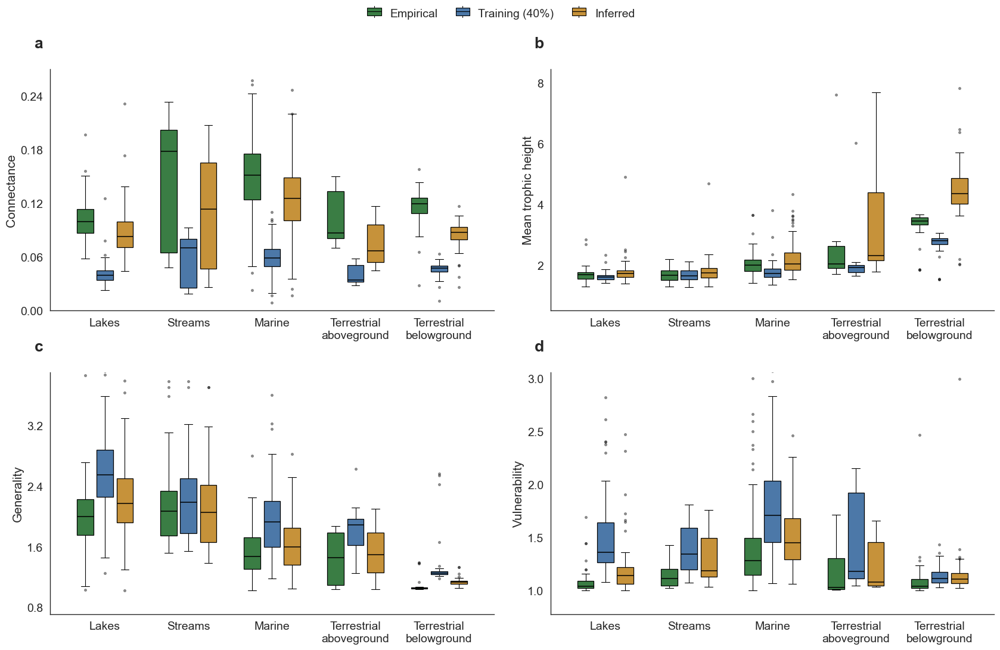


[INFO] TrainRatio = 50; Threshold = 0.5
[INFO] Source file: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/retention_protocol/tukey_iqr_1p5_min25runs_threshold0p50_v1/figure_inputs/ecological_train50_after_tukey.csv
[INFO] Loaded Tukey-filtered ecological rows: 2,320
[INFO] Training graph web-level rows: 1,160
[INFO] Plotting rows after empirical/train/pseudo expansion: 3,480
[INFO] Pseudo and training values use Tukey 1.5 x IQR filtering with at least 25/100 runs.


,Metric,FoodWebs,TotalPseudoRunOutliersRemoved,MinRetainedRuns,MedianRetainedRuns
0,Connectance,290,469,84,99.0
1,MeanNormalizedGeneralityConsumersOnly,290,674,64,99.0
2,MeanNormalizedVulnerabilityResourcesOnly,290,703,79,99.0
3,MeanTrophicHeight,290,2216,39,87.0


,Metric,Web type,FoodWebs,Rows
0,Connectance,Empirical,290,290
1,Connectance,Training (50%),290,290
2,Connectance,Pseudo,290,290
3,MeanNormalizedGeneralityConsumersOnly,Empirical,290,290
4,MeanNormalizedGeneralityConsumersOnly,Training (50%),290,290
5,MeanNormalizedGeneralityConsumersOnly,Pseudo,290,290
6,MeanNormalizedVulnerabilityResourcesOnly,Empirical,290,290
7,MeanNormalizedVulnerabilityResourcesOnly,Training (50%),290,290
8,MeanNormalizedVulnerabilityResourcesOnly,Pseudo,290,290
9,MeanTrophicHeight,Empirical,290,290


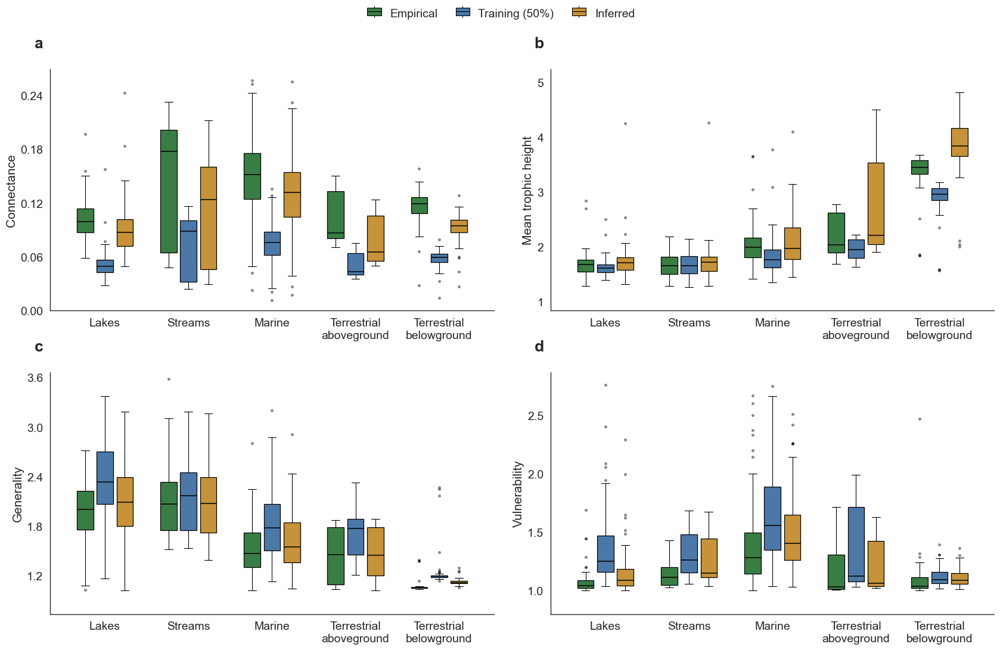


[INFO] TrainRatio = 60; Threshold = 0.5
[INFO] Source file: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/retention_protocol/tukey_iqr_1p5_min25runs_threshold0p50_v1/figure_inputs/ecological_train60_after_tukey.csv
[INFO] Loaded Tukey-filtered ecological rows: 2,320
[INFO] Training graph web-level rows: 1,160
[INFO] Plotting rows after empirical/train/pseudo expansion: 3,480
[INFO] Pseudo and training values use Tukey 1.5 x IQR filtering with at least 25/100 runs.


,Metric,FoodWebs,TotalPseudoRunOutliersRemoved,MinRetainedRuns,MedianRetainedRuns
0,Connectance,290,471,83,99.0
1,MeanNormalizedGeneralityConsumersOnly,290,948,55,99.0
2,MeanNormalizedVulnerabilityResourcesOnly,290,906,75,99.0
3,MeanTrophicHeight,290,2275,42,88.0


,Metric,Web type,FoodWebs,Rows
0,Connectance,Empirical,290,290
1,Connectance,Training (60%),290,290
2,Connectance,Pseudo,290,290
3,MeanNormalizedGeneralityConsumersOnly,Empirical,290,290
4,MeanNormalizedGeneralityConsumersOnly,Training (60%),290,290
5,MeanNormalizedGeneralityConsumersOnly,Pseudo,290,290
6,MeanNormalizedVulnerabilityResourcesOnly,Empirical,290,290
7,MeanNormalizedVulnerabilityResourcesOnly,Training (60%),290,290
8,MeanNormalizedVulnerabilityResourcesOnly,Pseudo,290,290
9,MeanTrophicHeight,Empirical,290,290


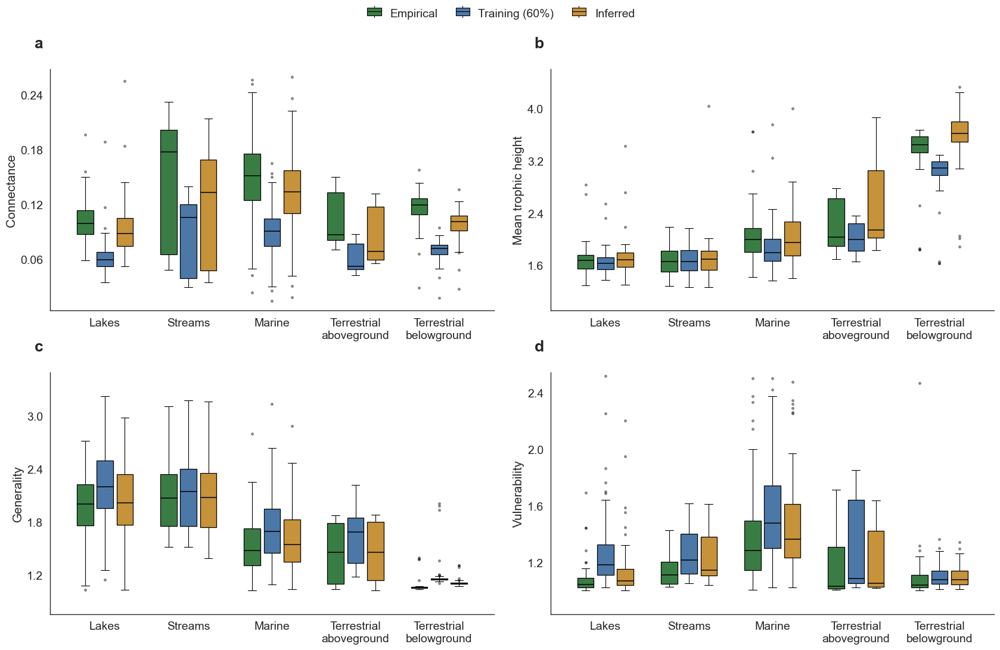

In [14]:
import math
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.legend_handler import HandlerBase
from matplotlib.ticker import MaxNLocator

sns.set_theme(context="paper", style="white", font_scale=1.2)

# ============================================================
# Locate repo root
# ============================================================
def find_repo_root(start=Path.cwd()):
    start = Path(start).resolve()
    for p in [start, *start.parents]:
        if (p / "src/matlab").exists() and (p / "docs").exists():
            return p
    raise RuntimeError(f"Could not locate repo root from {start}")


REPO_ROOT = find_repo_root()
TRAIN_RATIOS = [40, 50, 60]
THRESHOLD = 0.5
EXPECTED_RUNS = 100
MINIMUM_RETAINED_RUNS = 25

RESULT_DIR = (
    REPO_ROOT
    / "src/matlab/data"
    / (
        "result_wlnm_dir_neg_roleonly_trophicv2_"
        "100x290_train10-90_Apocrita_20260910_011848"
    )
)

PROTOCOL_NAME = "tukey_iqr_1p5_min25runs_threshold0p50_v1"

FIGURE_INPUT_DIR = (
    RESULT_DIR
    / "retention_protocol"
    / PROTOCOL_NAME
    / "figure_inputs"
)

PSEUDO_NORMALIZED_GV_INPUT = (
    RESULT_DIR
    / "retention_protocol"
    / "normalized_gv_athen_tukey_iqr_1p5_min25runs_threshold0p50_v1"
    / "figure_inputs/normalized_gv_metric_means_after_tukey.csv"
)

TRAINING_NORMALIZED_GV_INPUT = (
    RESULT_DIR
    / "retention_protocol"
    / "training_normalized_gv_athen_tukey_iqr_1p5_min25runs_threshold0p50_v1"
    / "figure_inputs/training_normalized_gv_metric_means_after_tukey.csv"
)

FOODWEB_METADATA = (
    REPO_ROOT
    / "src/matlab/data/foodwebs_mat/foodweb_metrics_ecosystem.csv"
)

# ============================================================
# CONFIG
# ============================================================
BOX_WIDTH = 0.24
TYPE_OFFSET = 0.29
GROUP_SPACING = 1.22
SHOW_WEB_LEVEL_FLIERS = True

base_ecosystem_order = [
    "lakes",
    "streams",
    "marine",
    "terrestrial aboveground",
    "terrestrial belowground",
]

ecosystem_labels = {
    "lakes": "Lakes",
    "streams": "Streams",
    "marine": "Marine",
    "terrestrial aboveground": "Terrestrial\naboveground",
    "terrestrial belowground": "Terrestrial\nbelowground",
}

metric_order = [
    "Connectance",
    "MeanTrophicHeight",
    "MeanNormalizedGeneralityConsumersOnly",
    "MeanNormalizedVulnerabilityResourcesOnly",
]

metric_labels = {
    "Connectance": "Connectance",
    "MeanTrophicHeight": "Mean trophic height",
    "MeanNormalizedGeneralityConsumersOnly": "Generality",
    "MeanNormalizedVulnerabilityResourcesOnly": "Vulnerability",
}

PSEUDO_METRIC_MAP = {
    "PseudoConnectance": "Connectance",
    "PseudoMeanTrophicHeight": "MeanTrophicHeight",
    "PseudoMeanNormalizedGeneralityConsumersOnly": "MeanNormalizedGeneralityConsumersOnly",
    "PseudoMeanNormalizedVulnerabilityResourcesOnly": "MeanNormalizedVulnerabilityResourcesOnly",
}

TRAIN_METRIC_MAP = {
    "TrainConnectance": "Connectance",
    "TrainMeanTrophicHeight": "MeanTrophicHeight",
    "TrainMeanNormalizedGeneralityConsumersOnly": "MeanNormalizedGeneralityConsumersOnly",
    "TrainMeanNormalizedVulnerabilityResourcesOnly": "MeanNormalizedVulnerabilityResourcesOnly",
}

panel_letters = list("abcdefghijklmnopqrstuvwxyz")

# ============================================================
# HELPERS
# ============================================================
def format_ecosystem_label(eco: str) -> str:
    eco_clean = str(eco).strip().lower()
    return ecosystem_labels.get(eco_clean, str(eco).strip().capitalize())


def normalize_foodweb_key(value: str) -> str:
    value = Path(str(value).strip()).stem
    for suffix in ("_tax_mass", "_taxmass"):
        if value.lower().endswith(suffix):
            value = value[:-len(suffix)]
            break
    return " ".join(value.replace("_", " ").casefold().split())


def draw_box(ax, values, position, facecolor, showfliers=False):
    ax.boxplot(
        values,
        positions=[position],
        widths=BOX_WIDTH,
        patch_artist=True,
        manage_ticks=False,
        showfliers=showfliers,
        boxprops={"facecolor": facecolor, "edgecolor": "black", "linewidth": 0.9},
        medianprops={"color": "black", "linewidth": 1.1},
        whiskerprops={"color": "black", "linewidth": 0.8},
        capprops={"color": "black", "linewidth": 0.8},
        flierprops={
            "marker": "o",
            "markersize": 3.0,
            "markerfacecolor": "black",
            "markeredgecolor": "black",
            "markeredgewidth": 0.4,
            "linestyle": "none",
            "alpha": 0.45,
        },
    )


def get_boxplot_visible_ylim(grouped_values, lower_bound=0.0, pad_fraction=0.12):
    visible_lows = []
    visible_highs = []

    for values in grouped_values:
        values = np.asarray(values, dtype=float)
        values = values[np.isfinite(values)]

        if values.size == 0:
            continue

        q1, q3 = np.nanpercentile(values, [25, 75])
        iqr = q3 - q1

        if np.isclose(iqr, 0):
            lower_whisker = np.nanmin(values)
            upper_whisker = np.nanmax(values)
        else:
            lower_fence = q1 - 1.5 * iqr
            upper_fence = q3 + 1.5 * iqr
            non_fliers = values[(values >= lower_fence) & (values <= upper_fence)]

            if non_fliers.size == 0:
                non_fliers = values

            lower_whisker = np.nanmin(non_fliers)
            upper_whisker = np.nanmax(non_fliers)

        visible_lows.extend([lower_whisker, q1])
        visible_highs.extend([upper_whisker, q3])

    if not visible_lows or not visible_highs:
        return None

    local_min = np.nanmin(visible_lows)
    local_max = np.nanmax(visible_highs)
    data_range = local_max - local_min if local_max > local_min else 0.05

    local_min = max(lower_bound, local_min - pad_fraction * data_range)
    local_max = local_max + pad_fraction * data_range

    if np.isclose(local_min, local_max):
        local_min = max(lower_bound, local_min - 0.02)
        local_max = local_max + 0.02

    return local_min, local_max


class HandlerMiniBoxplot(HandlerBase):
    def create_artists(
        self, legend, orig_handle,
        xdescent, ydescent, width, height, fontsize, trans
    ):
        facecolor = orig_handle["facecolor"]
        edgecolor = orig_handle.get("edgecolor", "black")
        linewidth = orig_handle.get("linewidth", 0.8)

        y_shift = -0.06 * height
        cx = xdescent + 0.5 * width
        cy = ydescent + 0.5 * height + y_shift

        box_w = 0.8 * width
        box_h = 0.8 * height
        box_x = cx - box_w / 2
        box_y = cy - box_h / 2

        whisk_top_y = box_y + box_h + 0.18 * height
        whisk_bot_y = box_y - 0.18 * height

        box = Rectangle(
            (box_x, box_y),
            box_w,
            box_h,
            facecolor=facecolor,
            edgecolor=edgecolor,
            linewidth=linewidth,
            transform=trans,
        )

        median = Line2D(
            [box_x, box_x + box_w],
            [cy, cy],
            color=edgecolor,
            linewidth=linewidth,
            transform=trans,
        )

        whisker_top = Line2D(
            [cx, cx],
            [box_y + box_h, whisk_top_y],
            color=edgecolor,
            linewidth=linewidth,
            transform=trans,
        )

        whisker_bottom = Line2D(
            [cx, cx],
            [whisk_bot_y, box_y],
            color=edgecolor,
            linewidth=linewidth,
            transform=trans,
        )

        return [box, median, whisker_top, whisker_bottom]


# ============================================================
# LOAD FOOD-WEB ECOSYSTEM METADATA ONCE
# ============================================================
if not FOODWEB_METADATA.is_file():
    raise FileNotFoundError(f"Missing food-web metadata: {FOODWEB_METADATA}")

metadata_df = pd.read_csv(FOODWEB_METADATA)
required_metadata_columns = {"Foodweb", "EcosystemType"}
missing_metadata_columns = required_metadata_columns.difference(metadata_df.columns)
if missing_metadata_columns:
    raise KeyError(
        f"Metadata is missing columns: {sorted(missing_metadata_columns)}"
    )

metadata_df["FW_KEY"] = metadata_df["Foodweb"].map(normalize_foodweb_key)
metadata_df["ecosystem"] = (
    metadata_df["EcosystemType"].astype(str).str.strip().str.lower()
)

metadata_conflicts = (
    metadata_df.groupby("FW_KEY")["ecosystem"].nunique(dropna=True).gt(1)
)
if metadata_conflicts.any():
    raise RuntimeError(
        "Conflicting ecosystem labels for: "
        + ", ".join(metadata_conflicts[metadata_conflicts].index[:10])
    )

metadata_df = metadata_df[["FW_KEY", "ecosystem"]].drop_duplicates("FW_KEY")
print(f"[INFO] Food-web metadata rows: {len(metadata_df):,}")


# ============================================================
# PLOT FUNCTION
# ============================================================
def plot_fig5_for_train_ratio(train_ratio):
    ecological_input = (
        FIGURE_INPUT_DIR
        / f"ecological_train{train_ratio}_after_tukey.csv"
    )

    if not ecological_input.is_file():
        raise FileNotFoundError(f"Missing file: {ecological_input}")

    training_label = f"Training ({train_ratio}%)"

    web_type_order = [
        "Empirical",
        training_label,
        "Pseudo",
    ]

    type_offsets = {
        "Empirical": -TYPE_OFFSET,
        training_label: 0.0,
        "Pseudo": TYPE_OFFSET,
    }

    type_palette = {
        "Empirical": "#3A7D44",
        training_label: "#4C78A8",
        "Pseudo": "#C6923A",
    }

    # ========================================================
    # LOAD THE UNIFIED TUKEY-FILTERED WEB-LEVEL INPUT
    # ========================================================
    ecological = pd.read_csv(ecological_input)
    required_columns = {
        "Foodweb", "Metric", "MeanAfterTukey", "ReferenceValue",
        "OutlierRunsExcluded", "RetainedRunsAfterTukey", "ExpectedRuns",
        "MinimumRetainedRuns", "MeetsMinimumRetainedRuns", "TrainRatio",
        "Threshold",
    }
    missing_columns = required_columns.difference(ecological.columns)
    if missing_columns:
        raise KeyError(
            f"Tukey input is missing columns: {sorted(missing_columns)}"
        )

    normalized_metric_names = {
        "MeanNormalizedGeneralityConsumersOnly",
        "MeanNormalizedVulnerabilityResourcesOnly",
    }
    normalized_frames = []
    for normalized_input, metric_prefix in [
        (PSEUDO_NORMALIZED_GV_INPUT, "Pseudo"),
        (TRAINING_NORMALIZED_GV_INPUT, "Train"),
    ]:
        if not normalized_input.is_file():
            raise FileNotFoundError(f"Missing normalized metric file: {normalized_input}")
        normalized_frame = pd.read_csv(normalized_input)
        missing_normalized_columns = required_columns.difference(normalized_frame.columns)
        if missing_normalized_columns:
            raise KeyError(
                "Normalized metric input is missing columns: "
                f"{sorted(missing_normalized_columns)}"
            )
        normalized_frame = normalized_frame.loc[
            normalized_frame["Metric"].isin(normalized_metric_names)
        ].copy()
        normalized_frame["Metric"] = metric_prefix + normalized_frame["Metric"]
        normalized_frames.append(normalized_frame)

    ecological = pd.concat(
        [ecological, *normalized_frames],
        ignore_index=True,
        sort=False,
    )

    numeric_columns = [
        "MeanAfterTukey", "ReferenceValue", "OutlierRunsExcluded",
        "RetainedRunsAfterTukey", "ExpectedRuns", "MinimumRetainedRuns",
        "MeetsMinimumRetainedRuns", "TrainRatio", "Threshold",
    ]
    for column in numeric_columns:
        ecological[column] = pd.to_numeric(ecological[column], errors="coerce")

    requested_metrics = set(PSEUDO_METRIC_MAP) | set(TRAIN_METRIC_MAP)
    ecological = ecological[
        ecological["Metric"].isin(requested_metrics)
        & np.isclose(ecological["TrainRatio"], train_ratio)
        & np.isclose(ecological["Threshold"], THRESHOLD)
        & ecological["ExpectedRuns"].eq(EXPECTED_RUNS)
        & ecological["MinimumRetainedRuns"].eq(MINIMUM_RETAINED_RUNS)
        & ecological["RetainedRunsAfterTukey"].ge(MINIMUM_RETAINED_RUNS)
        & ecological["MeetsMinimumRetainedRuns"].eq(1)
    ].copy()

    ecological = ecological.dropna(subset=["MeanAfterTukey", "ReferenceValue"])
    ecological["FW_KEY"] = ecological["Foodweb"].map(normalize_foodweb_key)
    ecological = ecological.merge(
        metadata_df,
        on="FW_KEY",
        how="left",
        validate="many_to_one",
    )

    missing_ecosystem = ecological.loc[
        ecological["ecosystem"].isna(), "Foodweb"
    ].drop_duplicates()
    if not missing_ecosystem.empty:
        raise RuntimeError(
            "Missing ecosystem metadata for: "
            + ", ".join(missing_ecosystem.head(10))
        )

    ecological["BaseMetric"] = ecological["Metric"].map(
        {**PSEUDO_METRIC_MAP, **TRAIN_METRIC_MAP}
    )

    # ========================================================
    # BUILD EMPIRICAL AND PSEUDO WEB-LEVEL DATA
    # ========================================================
    empirical_source = ecological[
        ["Foodweb", "FW_KEY", "ecosystem", "BaseMetric", "ReferenceValue"]
    ].copy()

    reference_conflicts = (
        empirical_source
        .groupby(["FW_KEY", "BaseMetric"])["ReferenceValue"]
        .nunique(dropna=True)
        .gt(1)
    )
    if reference_conflicts.any():
        raise RuntimeError("Conflicting empirical reference values in Tukey input.")

    empirical_df = (
        empirical_source
        .groupby(
            ["Foodweb", "FW_KEY", "ecosystem", "BaseMetric"],
            as_index=False,
            observed=True,
        )["ReferenceValue"]
        .first()
        .rename(columns={"BaseMetric": "Metric", "ReferenceValue": "value"})
    )
    empirical_df = empirical_df.rename(columns={"Foodweb": "FoodWeb"})
    empirical_df["Web type"] = "Empirical"

    pseudo_df = ecological.loc[
        ecological["Metric"].isin(PSEUDO_METRIC_MAP),
        ["Foodweb", "FW_KEY", "ecosystem", "BaseMetric", "MeanAfterTukey"],
    ].rename(
        columns={
            "Foodweb": "FoodWeb",
            "BaseMetric": "Metric",
            "MeanAfterTukey": "value",
        }
    )
    pseudo_df["Web type"] = "Pseudo"

    # ========================================================
    # BUILD TRAINING-GRAPH WEB-LEVEL DATA
    # ========================================================
    train_df = ecological.loc[
        ecological["Metric"].isin(TRAIN_METRIC_MAP),
        ["Foodweb", "FW_KEY", "ecosystem", "BaseMetric", "MeanAfterTukey"],
    ].rename(
        columns={
            "Foodweb": "FoodWeb",
            "BaseMetric": "Metric",
            "MeanAfterTukey": "value",
        }
    )
    train_df["Web type"] = training_label

    # Keep only food-web/metric pairs represented in all three series.
    key_columns = ["FW_KEY", "Metric"]
    common_keys = set(map(tuple, empirical_df[key_columns].to_numpy()))
    common_keys &= set(map(tuple, train_df[key_columns].to_numpy()))
    common_keys &= set(map(tuple, pseudo_df[key_columns].to_numpy()))
    if not common_keys:
        raise RuntimeError("No complete empirical/training/pseudo pairs remain.")

    for frame in (empirical_df, train_df, pseudo_df):
        frame["PAIR_KEY"] = list(map(tuple, frame[key_columns].to_numpy()))
        frame.drop(frame.index[~frame["PAIR_KEY"].isin(common_keys)], inplace=True)
        frame.drop(columns="PAIR_KEY", inplace=True)

    # ========================================================
    # FINAL PLOTTING DATA
    # ========================================================
    plot_df = pd.concat(
        [empirical_df, train_df, pseudo_df],
        ignore_index=True,
    )

    plot_df["value"] = pd.to_numeric(plot_df["value"], errors="coerce")
    plot_df = plot_df.dropna(subset=["value", "ecosystem", "Metric", "Web type"])

    plot_df["Web type"] = pd.Categorical(
        plot_df["Web type"],
        categories=web_type_order,
        ordered=True,
    )

    print(f"\n[INFO] TrainRatio = {train_ratio}; Threshold = {THRESHOLD}")
    print(f"[INFO] Source file: {ecological_input}")
    print(f"[INFO] Loaded Tukey-filtered ecological rows: {len(ecological):,}")
    print(f"[INFO] Training graph web-level rows: {len(train_df):,}")
    print(f"[INFO] Plotting rows after empirical/train/pseudo expansion: {len(plot_df):,}")
    print(
        "[INFO] Pseudo and training values use Tukey 1.5 x IQR filtering "
        f"with at least {MINIMUM_RETAINED_RUNS}/{EXPECTED_RUNS} runs."
    )

    removed_summary = (
        ecological[ecological["Metric"].isin(PSEUDO_METRIC_MAP)]
        .assign(BaseMetric=lambda x: x["Metric"].map(PSEUDO_METRIC_MAP))
        .groupby("BaseMetric", as_index=False)
        .agg(
            FoodWebs=("Foodweb", "nunique"),
            TotalPseudoRunOutliersRemoved=("OutlierRunsExcluded", "sum"),
            MinRetainedRuns=("RetainedRunsAfterTukey", "min"),
            MedianRetainedRuns=("RetainedRunsAfterTukey", "median"),
        )
        .rename(columns={"BaseMetric": "Metric"})
    )

    display(removed_summary)

    web_type_counts = (
        plot_df
        .groupby(["Metric", "Web type"], observed=True)
        .agg(FoodWebs=("FoodWeb", "nunique"), Rows=("value", "size"))
        .reset_index()
    )

    display(web_type_counts)

    # ========================================================
    # PLOT
    # ========================================================
    n_panels = len(metric_order)
    n_cols = 2
    n_rows = math.ceil(n_panels / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(17, 10.6), sharey=False)
    axes = np.array(axes).reshape(-1)

    legend_handles = [
        {"facecolor": type_palette[web_type], "edgecolor": "black", "linewidth": 0.8}
        for web_type in web_type_order
    ]

    legend_labels = [
        "Empirical",
        training_label,
        "Inferred",
    ]

    for idx, (ax, metric) in enumerate(zip(axes, metric_order)):
        panel_df = plot_df[plot_df["Metric"] == metric].copy()

        if panel_df.empty:
            ax.set_visible(False)
            continue

        present_ecosystems = [
            eco for eco in base_ecosystem_order
            if eco in panel_df["ecosystem"].unique()
        ]
        extra_ecosystems = [
            eco for eco in panel_df["ecosystem"].unique()
            if eco not in base_ecosystem_order
        ]
        eco_order = present_ecosystems + extra_ecosystems

        base_positions = np.arange(len(eco_order)) * GROUP_SPACING
        boxplot_groups = []

        for eco, base_x in zip(eco_order, base_positions):
            eco_df = panel_df[panel_df["ecosystem"] == eco]

            for web_type in web_type_order:
                values = (
                    eco_df[eco_df["Web type"] == web_type]["value"]
                    .dropna()
                    .values
                )

                if len(values):
                    draw_box(
                        ax=ax,
                        values=values,
                        position=base_x + type_offsets[web_type],
                        facecolor=type_palette[web_type],
                        showfliers=SHOW_WEB_LEVEL_FLIERS,
                    )
                    boxplot_groups.append(values)

        ax.set_title("")
        ax.set_ylabel(metric_labels[metric], fontsize=15)
        ax.set_xlabel("")
        ax.tick_params(axis="both", labelsize=14)

        ylim = get_boxplot_visible_ylim(
            boxplot_groups,
            lower_bound=0.0,
            pad_fraction=0.12,
        )

        if ylim is not None:
            ax.set_ylim(*ylim)
            ax.yaxis.set_major_locator(MaxNLocator(5))

        ax.set_xlim(base_positions[0] - 0.80, base_positions[-1] + 0.80)

        ax.set_xticks(base_positions)
        ax.set_xticklabels(
            [format_ecosystem_label(eco) for eco in eco_order],
            rotation=0,
            fontsize=14,
        )

        ax.grid(False, axis="x")
        ax.grid(False, axis="y")
        sns.despine(ax=ax)

        ax.annotate(
            panel_letters[idx],
            xy=(0, 1.05),
            xycoords="axes fraction",
            xytext=(-8, 8),
            textcoords="offset points",
            ha="right",
            va="bottom",
            fontsize=19,
            fontweight="bold",
            annotation_clip=False,
        )

    for j in range(len(metric_order), len(axes)):
        axes[j].set_visible(False)

    # ========================================================
    # GLOBAL LEGEND
    # ========================================================
    fig.legend(
        handles=legend_handles,
        labels=legend_labels,
        handler_map={dict: HandlerMiniBoxplot()},
        loc="upper center",
        bbox_to_anchor=(0.5, 1.04),
        ncol=3,
        frameon=False,
        fontsize=14,
        handlelength=1.5,
        handleheight=0.9,
        handletextpad=0.6,
        columnspacing=1.4,
        borderpad=0.2,
        labelspacing=0.45,
    )

    fig.tight_layout(pad=1.3, w_pad=2.0, h_pad=0)

    plt.show()


# ============================================================
# PRINT FIGURES FOR THE AVAILABLE ECOLOGICAL INPUTS: 40%, 50%, AND 60%
# ============================================================
for train_ratio in TRAIN_RATIOS:
    plot_fig5_for_train_ratio(train_ratio)

[INFO] Repository: /Users/acw792/Developer/qmul-phd-framework
[INFO] Using raw prediction inputs; no Tukey filtering.
[INFO] original: all 100 raw run units used.
[INFO] dir_neg: all 100 raw run units used.
[INFO] bodymass: all 100 raw run units used.
[INFO] Food webs satisfying Nodes >= 0: 290

=== Retained and paired food webs by metric ===


,Metric,Original WLNM retained food webs,Modified WLNM retained food webs,Modified WLNM with bodymass ratio retained food webs,Three-way paired food webs,Original WLNM not shared by all versions,Modified WLNM not shared by all versions,Modified WLNM with bodymass ratio not shared by all versions
0,ROC-AUC,290,290,290,290,0,0,0
1,PR-AUC,290,290,290,290,0,0,0
2,F1,290,290,290,290,0,0,0
3,MCC,290,290,290,290,0,0,0
4,Precision,290,290,290,290,0,0,0
5,Recall,290,290,290,290,0,0,0
6,TSS,290,290,290,290,0,0,0



=== Raw run-count details for paired food webs ===


,Version,Metric,FoodWebs,MinimumRetainedRuns,MedianRetainedRuns,MaximumRetainedRuns
0,Modified WLNM with bodymass ratio,F1,290,100,100.0,100
1,Modified WLNM with bodymass ratio,PR-AUC,290,100,100.0,100
2,Modified WLNM with bodymass ratio,Precision,290,100,100.0,100
3,Modified WLNM with bodymass ratio,ROC-AUC,290,100,100.0,100
4,Modified WLNM with bodymass ratio,Recall,290,100,100.0,100
5,Modified WLNM with bodymass ratio,MCC,290,100,100.0,100
6,Modified WLNM with bodymass ratio,TSS,290,100,100.0,100
7,Modified WLNM,F1,290,100,100.0,100
8,Modified WLNM,PR-AUC,290,100,100.0,100
9,Modified WLNM,Precision,290,100,100.0,100



=== Raw-unfiltered web-level predictive metric summary ===


,Version,Metric,FoodWebs,Mean,Median,SD,Variance
0,Modified WLNM with bodymass ratio,F1,290,0.6094,0.6488,0.2062,0.0425
1,Modified WLNM with bodymass ratio,PR-AUC,290,0.5396,0.5449,0.1525,0.0232
2,Modified WLNM with bodymass ratio,Precision,290,0.9101,0.9437,0.1146,0.0131
3,Modified WLNM with bodymass ratio,ROC-AUC,290,0.8567,0.8873,0.1095,0.0120
4,Modified WLNM with bodymass ratio,Recall,290,0.5020,0.5419,0.2176,0.0473
5,Modified WLNM with bodymass ratio,MCC,290,0.5781,0.6056,0.1834,0.0337
6,Modified WLNM with bodymass ratio,TSS,290,0.4817,0.4950,0.2116,0.0448
7,Modified WLNM,F1,290,0.6686,0.7201,0.2211,0.0489
8,Modified WLNM,PR-AUC,290,0.5350,0.5475,0.1750,0.0306
9,Modified WLNM,Precision,290,0.9233,0.9507,0.1071,0.0115



[INFO] Saved publication-ready outputs:
  PNG: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleormass_trophicv2_100x290_train10-90_tau1p00_Apocrita_20260918_010757/figures_raw_unfiltered/figure_3_original100_vs_roleonly100_vs_roleormass100_train90_raw_unfiltered.png
  SVG: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleormass_trophicv2_100x290_train10-90_tau1p00_Apocrita_20260918_010757/figures_raw_unfiltered/figure_3_original100_vs_roleonly100_vs_roleormass100_train90_raw_unfiltered.svg
  PDF: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleormass_trophicv2_100x290_train10-90_tau1p00_Apocrita_20260918_010757/figures_raw_unfiltered/figure_3_original100_vs_roleonly100_vs_roleormass100_train90_raw_unfiltered.pdf
  Summary: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleormass_trophicv2_100x290_train10-90_tau1p00_Apocrita_20260918_010757/figures_ra

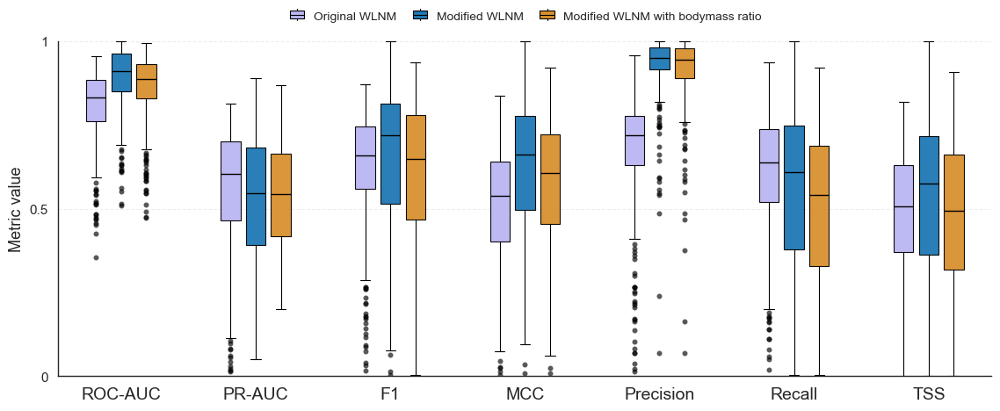

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.legend_handler import HandlerBase


sns.set_theme(
    context="paper",
    style="white",
    font_scale=1.1,
)




# ============================================================
# Raw predictive inputs (no Tukey filtering)
# ============================================================

import re


def _raw_foodweb_name(path):
    return re.sub(
        r"_tax_mass_results_random_wlnm_.*$",
        "",
        path.stem,
        flags=re.I,
    )


def load_raw_predictive_compat(
    result_root,
    expected_version,
    metric_specs,
    expected_runs,
    minimum_retained_runs,
    *,
    train_ratios=None,
    cvk_values=None,
    k_target=10,
    threshold=0.50,
    kfold=False,
    scenario=None,
):
    """Return raw web-level means in the legacy plotting schema.

    The legacy column names are retained only so that the original plotting,
    layout, scale, colour and export code remains byte-for-byte unchanged.
    MeanAfterTukey below is a compatibility alias for the arithmetic mean of
    every complete raw run unit; no Tukey fences or outlier exclusions occur.
    """
    metrics = [metric for metric, _ in metric_specs]
    labels = dict(metric_specs)
    files = sorted((result_root / "prediction_scores_logs").glob("*.csv"))
    if not files:
        raise FileNotFoundError(result_root / "prediction_scores_logs")

    required = {
        "Version",
        "TrainRatio",
        "ExperimentID",
        "Seed",
        "Threshold",
        "K",
        "CvK",
        "FoldID",
        "EmpiricalConnectance",
        *metrics,
    }
    frames = []
    for path in files:
        frame = pd.read_csv(
            path,
            usecols=lambda column: column in required,
        )
        missing = required.difference(frame.columns)
        if missing:
            raise ValueError(
                f"{path.name}: missing raw columns {sorted(missing)}"
            )
        frame["Foodweb"] = _raw_foodweb_name(path)
        frames.append(frame)

    raw = pd.concat(frames, ignore_index=True)
    for column in required.difference({"Version"}):
        raw[column] = pd.to_numeric(raw[column], errors="coerce")
    raw["TrainRatio"] = np.where(
        raw["TrainRatio"].abs().le(1.0),
        raw["TrainRatio"] * 100.0,
        raw["TrainRatio"],
    )
    raw = raw.loc[
        raw["Version"].eq(expected_version)
        & np.isclose(raw["Threshold"], threshold, atol=1e-9)
        & np.isclose(raw["K"], k_target, atol=1e-9)
    ].copy()
    if train_ratios is not None:
        requested = np.asarray(list(train_ratios), dtype=float)
        raw = raw.loc[
            raw["TrainRatio"].map(
                lambda value: np.isclose(
                    value,
                    requested,
                    atol=1e-8,
                ).any()
            )
        ].copy()
    if cvk_values is not None:
        raw = raw.loc[raw["CvK"].isin(cvk_values)].copy()
    if raw.empty:
        raise ValueError(f"No raw observations selected from {result_root}")

    metric_values = raw[metrics].to_numpy(float)
    if not np.isfinite(metric_values).all():
        raise ValueError(f"Non-finite raw predictive values in {result_root}")
    probability_metrics = [
        metric for metric in metrics if metric not in {"TestMCC", "TestTSS"}
    ]
    signed_metrics = [
        metric for metric in metrics if metric in {"TestMCC", "TestTSS"}
    ]
    if probability_metrics:
        values = raw[probability_metrics].to_numpy(float)
        if ((values < 0) | (values > 1)).any():
            raise ValueError("Raw probability metrics must be within [0, 1]")
    if signed_metrics:
        values = raw[signed_metrics].to_numpy(float)
        if ((values < -1) | (values > 1)).any():
            raise ValueError("Raw MCC/TSS values must be within [-1, 1]")

    group_columns = [
        "Foodweb",
        "Version",
        "TrainRatio",
        "Threshold",
        "K",
        "CvK",
    ]
    if kfold:
        experiment_columns = [*group_columns, "ExperimentID"]
        fold_check = (
            raw.groupby(experiment_columns, dropna=False)
            .agg(
                FoldRows=("FoldID", "size"),
                UniqueFolds=("FoldID", "nunique"),
            )
            .reset_index()
        )
        incomplete = fold_check.loc[
            ~fold_check["FoldRows"].eq(fold_check["CvK"])
            | ~fold_check["UniqueFolds"].eq(fold_check["CvK"])
        ]
        if not incomplete.empty:
            raise ValueError(
                "Incomplete repeated-CV experiments found:\n"
                + incomplete.head(10).to_string(index=False)
            )
        run_units = (
            raw.groupby(
                experiment_columns,
                dropna=False,
                as_index=False,
            )
            .agg(
                **{
                    metric: (metric, "mean")
                    for metric in metrics
                },
                EmpiricalConnectance=(
                    "EmpiricalConnectance",
                    "first",
                ),
            )
        )
    else:
        experiment_columns = [*group_columns, "ExperimentID"]
        if raw.duplicated(experiment_columns).any():
            raise ValueError(f"Duplicate raw ExperimentID rows in {result_root}")
        run_units = raw

    counts = run_units.groupby(group_columns, dropna=False).size()
    if not counts.eq(expected_runs).all():
        raise ValueError(
            f"{result_root.name}: expected {expected_runs} complete raw "
            "run units per group; observed "
            f"{counts.value_counts().to_dict()}"
        )

    wide = (
        run_units.groupby(
            group_columns,
            dropna=False,
            as_index=False,
        )
        .agg(
            **{
                metric: (metric, "mean")
                for metric in metrics
            },
            EmpiricalConnectance=(
                "EmpiricalConnectance",
                "first",
            ),
            RawRunUnits=("ExperimentID", "size"),
        )
    )
    long = wide.melt(
        id_vars=[
            *group_columns,
            "EmpiricalConnectance",
            "RawRunUnits",
        ],
        value_vars=metrics,
        var_name="Metric",
        value_name="MeanAfterTukey",
    )
    long["Scenario"] = scenario or result_root.name
    long["MetricLabel"] = long["Metric"].map(labels)
    long["MetricFamily"] = "predictive"
    long["SourceColumn"] = long["Metric"]
    long["ReferenceColumn"] = ""
    long["MeanBeforeTukey"] = long["MeanAfterTukey"]
    long["TotalRunUnits"] = long["RawRunUnits"]
    long["ValidRunsBeforeTukey"] = long["RawRunUnits"]
    long["InvalidRunsBeforeTukey"] = 0
    long["OutlierRunsExcluded"] = 0
    long["RetainedRunsAfterTukey"] = long["RawRunUnits"]
    long["ExpectedRuns"] = expected_runs
    long["MinimumRetainedRuns"] = minimum_retained_runs
    long["MeetsMinimumRetainedRuns"] = 1
    long["ReferenceValue"] = long["EmpiricalConnectance"]
    return long

# ============================================================
# Locate repository root
# ============================================================

def find_repo_root(start=Path.cwd()):
    start = Path(start).resolve()

    candidates = [start, *start.parents]

    # Fallback for notebooks launched outside the repository.
    fallback = Path(
        "/Users/acw792/Developer/qmul-phd-framework"
    )

    if fallback not in candidates:
        candidates.append(fallback)

    for candidate in candidates:
        if (
            (candidate / "src/matlab").is_dir()
            and (candidate / "docs").is_dir()
        ):
            return candidate

    raise RuntimeError(
        "Could not locate the qmul-phd-framework repository."
    )


REPO_ROOT = find_repo_root()


# ============================================================
# Final configuration
# ============================================================

TRAIN_RATIO_TARGET = 90
CLASSIFICATION_THRESHOLD = 0.50
NODES_THRESHOLD = 0

EXPECTED_RUNS = 100
MINIMUM_RETAINED_FRACTION = 1.00
MINIMUM_RETAINED_RUNS = 100
PROTOCOL_NAME = (
    "tukey_iqr_1p5_min25runs_threshold0p50_v1"
)

assert MINIMUM_RETAINED_RUNS == int(
    np.ceil(
        EXPECTED_RUNS
        * MINIMUM_RETAINED_FRACTION
    )
)


# ============================================================
# Result roots
# ============================================================

ORIGINAL_ROOT = (
    REPO_ROOT
    / "src/matlab/data"
    / (
        "result_wlnm_original_100x290_train10-90_"
        "thresh0p50_Apocrita_20260916_221905"
    )
)

DIR_NEG_ROOT = (
    REPO_ROOT
    / "src/matlab/data"
    / (
        "result_wlnm_dir_neg_roleonly_trophicv2_"
        "100x290_train10-90_Apocrita_20260910_011848"
    )
)

BODYMASS_ROOT = (
    REPO_ROOT
    / "src/matlab/data"
    / (
        "result_wlnm_dir_neg_roleormass_trophicv2_"
        "100x290_train10-90_tau1p00_Apocrita_20260918_010757"
    )
)


# ============================================================
# Raw prediction inputs
# ============================================================

ORIGINAL_INPUT = ORIGINAL_ROOT
DIR_NEG_INPUT = DIR_NEG_ROOT
BODYMASS_INPUT = BODYMASS_ROOT

FOODWEB_CSV = (
    REPO_ROOT
    / "src/matlab/data/foodwebs_mat"
    / "foodweb_metrics_ecosystem.csv"
)

# ============================================================
# Publication output
# ============================================================

OUT_DIR = BODYMASS_ROOT / "figures_raw_unfiltered"

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

OUTPUT_STEM = "figure_3_original100_vs_roleonly100_vs_roleormass100_train90_raw_unfiltered"

PNG_PATH = OUT_DIR / f"{OUTPUT_STEM}.png"
SVG_PATH = OUT_DIR / f"{OUTPUT_STEM}.svg"
PDF_PATH = OUT_DIR / f"{OUTPUT_STEM}.pdf"

SUMMARY_PATH = (
    OUT_DIR
    / f"{OUTPUT_STEM}_summary.csv"
)

RETENTION_PATH = (
    OUT_DIR
    / f"{OUTPUT_STEM}_raw_run_counts.csv"
)

PAIRING_PATH = (
    OUT_DIR
    / f"{OUTPUT_STEM}_pairing_counts.csv"
)


# ============================================================
# Metrics
# ============================================================

METRIC_SPECS = [
    ("ROC_AUC", "ROC-AUC"),
    ("PR_AUC", "PR-AUC"),
    ("F1Score", "F1"),
    ("TestMCC", "MCC"),
    ("Precision", "Precision"),
    ("Recall", "Recall"),
    ("TestTSS", "TSS"),
]

METRIC_ORDER = [
    metric
    for metric, _ in METRIC_SPECS
]

METRIC_LABELS = dict(METRIC_SPECS)

VERSION_ORDER = [
    "original",
    "dir_neg",
    "bodymass",
]

VERSION_LABELS = {
    "original": "Original WLNM",
    "dir_neg": "Modified WLNM",
    "bodymass": "Modified WLNM with bodymass ratio",
}

VERSION_PALETTE = {
    "original": "#BAB6F2",
    "dir_neg": "#1F78B4",
    "bodymass": "#D8902F",
}

SHOW_WEB_LEVEL_FLIERS = True


# ============================================================
# Validate required raw inputs
# ============================================================

required_inputs = {
    "Original WLNM raw result root": ORIGINAL_INPUT,
    "Directed-negative WLNM raw result root": DIR_NEG_INPUT,
    "Body-mass WLNM raw result root": BODYMASS_INPUT,
    "Food-web metadata": FOODWEB_CSV,
}

missing_inputs = [
    f"{label}:\n  {path}"
    for label, path in required_inputs.items()
    if not (
        path.is_file()
        if path == FOODWEB_CSV
        else (path / "prediction_scores_logs").is_dir()
    )
]
if missing_inputs:
    raise FileNotFoundError("\n\n".join(missing_inputs))

print(f"[INFO] Repository: {REPO_ROOT}")
print("[INFO] Using raw prediction inputs; no Tukey filtering.")

# ============================================================
# Helpers
# ============================================================

def normalize_fw_label(name):
    name = str(name).strip()

    for suffix in [
        ".mat",
        ".csv",
    ]:
        if name.endswith(suffix):
            name = name[: -len(suffix)]

    name = name.replace(" ", "_")

    for token in [
        "_results_",
        "_result_",
        "_results",
        "_random",
        "_tax_mass",
        "_tax",
        "_mass",
    ]:
        name = name.replace(token, "_")

    return "_".join(
        part
        for part in name.split("_")
        if part
    ).lower()


def load_raw_figure_input(
    path,
    version,
    expected_runs,
    minimum_retained_runs,
):
    expected_version = {
        "original": "WLNM_original",
        "dir_neg": "WLNM_dir_neg",
        "bodymass": "WLNM_dir_neg",
    }[version]
    df = load_raw_predictive_compat(
        path,
        expected_version,
        METRIC_SPECS,
        expected_runs,
        expected_runs,
        train_ratios=[TRAIN_RATIO_TARGET],
    )
    df["Version"] = version
    df["Value"] = df["MeanAfterTukey"]
    df["FW_KEY"] = df["Foodweb"].apply(normalize_fw_label)
    if df.duplicated(["FW_KEY", "Version", "Metric"]).any():
        raise ValueError(f"Duplicated raw foodweb-metric rows in {path}")
    print(
        f"[INFO] {version}: all "
        f"{int(df['RetainedRunsAfterTukey'].min())} raw run units used."
    )
    return df

# ============================================================
# Load raw unfiltered values
# ============================================================

original_df = load_raw_figure_input(
    ORIGINAL_INPUT,
    version="original",
    expected_runs=EXPECTED_RUNS,
    minimum_retained_runs=MINIMUM_RETAINED_RUNS,
)

dir_neg_df = load_raw_figure_input(
    DIR_NEG_INPUT,
    version="dir_neg",
    expected_runs=EXPECTED_RUNS,
    minimum_retained_runs=MINIMUM_RETAINED_RUNS,
)

bodymass_df = load_raw_figure_input(
    BODYMASS_INPUT,
    version="bodymass",
    expected_runs=EXPECTED_RUNS,
    minimum_retained_runs=MINIMUM_RETAINED_RUNS,
)

combined_df = pd.concat(
    [
        original_df,
        dir_neg_df,
        bodymass_df,
    ],
    ignore_index=True,
)


# ============================================================
# Apply node-count filter
# ============================================================

metadata_df = pd.read_csv(
    FOODWEB_CSV
)

metadata_df.columns = [
    column.strip()
    for column in metadata_df.columns
]

foodweb_column = next(
    (
        column
        for column in metadata_df.columns
        if column.lower() == "foodweb"
    ),
    None,
)

nodes_column = next(
    (
        column
        for column in metadata_df.columns
        if column.lower() in {
            "nodes",
            "n_nodes",
            "num_nodes",
            "nodecount",
            "s",
        }
    ),
    None,
)

if (
    foodweb_column is None
    or nodes_column is None
):
    raise ValueError(
        "Could not identify Foodweb and Nodes "
        "columns in the metadata file."
    )

metadata_df[nodes_column] = pd.to_numeric(
    metadata_df[nodes_column],
    errors="coerce",
)

metadata_df["FW_KEY"] = (
    metadata_df[foodweb_column]
    .apply(normalize_fw_label)
)

metadata_df = (
    metadata_df[
        [
            "FW_KEY",
            foodweb_column,
            nodes_column,
        ]
    ]
    .drop_duplicates(
        subset=["FW_KEY"]
    )
)

allowed_fw_keys = set(
    metadata_df.loc[
        metadata_df[nodes_column]
        >= NODES_THRESHOLD,
        "FW_KEY",
    ]
)

print(
    f"[INFO] Food webs satisfying "
    f"Nodes >= {NODES_THRESHOLD}: "
    f"{len(allowed_fw_keys)}"
)

combined_df = combined_df[
    combined_df["FW_KEY"]
    .isin(allowed_fw_keys)
].copy()

if combined_df.empty:
    raise RuntimeError(
        "No retained food-web metrics remain "
        "after the node-count filter."
    )


# ============================================================
# Enforce three-way paired food webs separately per metric
# ============================================================

paired_frames = []
pairing_rows = []

for metric in METRIC_ORDER:
    metric_df = combined_df[
        combined_df["Metric"].eq(metric)
    ].copy()

    version_keys = {
        version: set(
            metric_df.loc[
                metric_df["Version"].eq(version),
                "FW_KEY",
            ]
        )
        for version in VERSION_ORDER
    }

    common_keys = set.intersection(
        *(version_keys[version] for version in VERSION_ORDER)
    )

    if not common_keys:
        raise RuntimeError(
            f"No three-way paired food webs remain for {metric}."
        )

    pairing_row = {
        "Metric": METRIC_LABELS[metric],
    }

    for version in VERSION_ORDER:
        label = VERSION_LABELS[version]
        pairing_row[f"{label} retained food webs"] = len(
            version_keys[version]
        )

    pairing_row["Three-way paired food webs"] = len(
        common_keys
    )

    for version in VERSION_ORDER:
        label = VERSION_LABELS[version]
        pairing_row[f"{label} not shared by all versions"] = len(
            version_keys[version] - common_keys
        )

    pairing_rows.append(pairing_row)

    paired_metric_df = metric_df[
        metric_df["FW_KEY"].isin(
            common_keys
        )
    ].copy()

    paired_frames.append(
        paired_metric_df
    )

plot_df = pd.concat(
    paired_frames,
    ignore_index=True,
)

if plot_df.empty:
    raise RuntimeError(
        "No three-way paired food webs remain for plotting."
    )

pairing_table = pd.DataFrame(
    pairing_rows
)

print(
    "\n=== Retained and paired food webs "
    "by metric ==="
)

display(pairing_table)


# ============================================================
# Retention details
# ============================================================

retention_table = (
    plot_df
    .groupby(
        [
            "Version",
            "Metric",
        ],
        as_index=False,
    )
    .agg(
        FoodWebs=(
            "FW_KEY",
            "nunique",
        ),
        MinimumRetainedRuns=(
            "RetainedRunsAfterTukey",
            "min",
        ),
        MedianRetainedRuns=(
            "RetainedRunsAfterTukey",
            "median",
        ),
        MaximumRetainedRuns=(
            "RetainedRunsAfterTukey",
            "max",
        ),
    )
)

retention_table["Version"] = (
    retention_table["Version"]
    .map(VERSION_LABELS)
)

retention_table["Metric"] = (
    retention_table["Metric"]
    .map(METRIC_LABELS)
)

retention_table = retention_table[
    [
        "Version",
        "Metric",
        "FoodWebs",
        "MinimumRetainedRuns",
        "MedianRetainedRuns",
        "MaximumRetainedRuns",
    ]
]

print(
    "\n=== Raw run-count details "
    "for paired food webs ==="
)

display(retention_table)


# ============================================================
# Web-level summary
# ============================================================

summary_table = (
    plot_df
    .groupby(
        [
            "Version",
            "Metric",
        ],
        as_index=False,
    )
    .agg(
        FoodWebs=(
            "FW_KEY",
            "nunique",
        ),
        Mean=(
            "Value",
            "mean",
        ),
        Median=(
            "Value",
            "median",
        ),
        SD=(
            "Value",
            "std",
        ),
        Variance=(
            "Value",
            "var",
        ),
    )
)

summary_table["Version"] = (
    summary_table["Version"]
    .map(VERSION_LABELS)
)

summary_table["Metric"] = (
    summary_table["Metric"]
    .map(METRIC_LABELS)
)

for column in [
    "Mean",
    "Median",
    "SD",
    "Variance",
]:
    summary_table[column] = (
        summary_table[column]
        .round(4)
    )

print(
    "\n=== Raw-unfiltered web-level "
    "predictive metric summary ==="
)

display(summary_table)


# ============================================================
# Custom miniature boxplot legend
# ============================================================

class HandlerMiniBoxplot(HandlerBase):
    def create_artists(
        self,
        legend,
        orig_handle,
        xdescent,
        ydescent,
        width,
        height,
        fontsize,
        trans,
    ):
        facecolor = orig_handle["facecolor"]

        edgecolor = orig_handle.get(
            "edgecolor",
            "black",
        )

        linewidth = orig_handle.get(
            "linewidth",
            0.6,
        )

        center_x = (
            xdescent
            + 0.5 * width
        )

        center_y = (
            ydescent
            + 0.44 * height
        )

        box_width = (
            0.8 * width
        )

        box_height = (
            0.8 * height
        )

        box_x = (
            center_x
            - box_width / 2
        )

        box_y = (
            center_y
            - box_height / 2
        )

        whisker_top_y = (
            box_y
            + box_height
            + 0.18 * height
        )

        whisker_bottom_y = (
            box_y
            - 0.18 * height
        )

        box = Rectangle(
            (
                box_x,
                box_y,
            ),
            box_width,
            box_height,
            facecolor=facecolor,
            edgecolor=edgecolor,
            linewidth=linewidth,
            transform=trans,
        )

        median = Line2D(
            [
                box_x,
                box_x + box_width,
            ],
            [
                center_y,
                center_y,
            ],
            color=edgecolor,
            linewidth=linewidth,
            transform=trans,
        )

        upper_whisker = Line2D(
            [
                center_x,
                center_x,
            ],
            [
                box_y + box_height,
                whisker_top_y,
            ],
            color=edgecolor,
            linewidth=linewidth,
            transform=trans,
        )

        lower_whisker = Line2D(
            [
                center_x,
                center_x,
            ],
            [
                whisker_bottom_y,
                box_y,
            ],
            color=edgecolor,
            linewidth=linewidth,
            transform=trans,
        )

        return [
            box,
            median,
            upper_whisker,
            lower_whisker,
        ]


# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(
    figsize=(11.5, 4.8)
)

group_gap = 1.5

group_centers = (
    1.0
    + np.arange(
        len(METRIC_SPECS)
    )
    * group_gap
)

offsets = {
    "original": -0.28,
    "dir_neg": 0.00,
    "bodymass": 0.28,
}

box_width = 0.22

for version in VERSION_ORDER:
    version_data = []
    version_positions = []

    for metric_index, (
        metric,
        metric_label,
    ) in enumerate(METRIC_SPECS):
        values = (
            plot_df.loc[
                (
                    plot_df["Version"].eq(
                        version
                    )
                )
                & (
                    plot_df["Metric"].eq(
                        metric
                    )
                ),
                "Value",
            ]
            .dropna()
            .to_numpy()
        )

        if len(values) == 0:
            continue

        version_data.append(
            values
        )

        version_positions.append(
            group_centers[metric_index]
            + offsets[version]
        )

    if not version_data:
        raise RuntimeError(
            f"No plotting values found for version: {version}"
        )

    ax.boxplot(
        version_data,
        positions=version_positions,
        widths=box_width,
        patch_artist=True,
        manage_ticks=False,
        showfliers=SHOW_WEB_LEVEL_FLIERS,
        boxprops={
            "facecolor": VERSION_PALETTE[version],
            "edgecolor": "black",
            "linewidth": 0.8,
            "alpha": 0.95,
        },
        medianprops={
            "color": "black",
            "linewidth": 1.0,
        },
        whiskerprops={
            "color": "black",
            "linewidth": 0.8,
        },
        capprops={
            "color": "black",
            "linewidth": 0.8,
        },
        flierprops={
            "marker": "o",
            "markersize": 4,
            "markerfacecolor": "black",
            "markeredgecolor": "black",
            "markeredgewidth": 0.2,
            "alpha": 0.65,
        },
    )


# ============================================================
# Axes and legend
# ============================================================

legend_handles = [
    {
        "facecolor": VERSION_PALETTE[version],
        "edgecolor": "black",
        "linewidth": 0.8,
    }
    for version in VERSION_ORDER
]

ax.set_xlim(
    group_centers[0] - 0.7,
    group_centers[-1] + 0.7,
)

ax.set_ylim(
    0,
    1.0,
)

ax.set_xticks(
    group_centers,
    labels=[
        metric_label
        for _, metric_label in METRIC_SPECS
    ],
)

plt.setp(
    ax.get_xticklabels(),
    rotation=0,
    fontsize=14,
)

ax.set_ylabel(
    "Metric value",
    fontsize=13,
)

ax.set_xlabel("")

ax.set_yticks(
    [
        0,
        0.5,
        1.0,
    ]
)

ax.set_yticklabels(
    [
        "0",
        "0.5",
        "1",
    ]
)

ax.tick_params(
    axis="y",
    labelsize=11,
)

ax.grid(
    True,
    axis="y",
    linestyle="--",
    alpha=0.35,
)

ax.legend(
    handles=legend_handles,
    labels=[
        VERSION_LABELS[version]
        for version in VERSION_ORDER
    ],
    handler_map={
        dict: HandlerMiniBoxplot()
    },
    loc="lower center",
    bbox_to_anchor=(
        0.5,
        1.03,
    ),
    ncol=len(VERSION_ORDER),
    frameon=False,
    fontsize=10,
    handlelength=1.5,
    handleheight=0.9,
    handletextpad=0.6,
    borderpad=0.2,
    labelspacing=0.45,
    columnspacing=1.2,
)

sns.despine(
    ax=ax
)

plt.tight_layout()


# ============================================================
# Export
# ============================================================

fig.savefig(
    PNG_PATH,
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    SVG_PATH,
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    PDF_PATH,
    bbox_inches="tight",
    facecolor="white",
)

summary_table.to_csv(
    SUMMARY_PATH,
    index=False,
)

retention_table.to_csv(
    RETENTION_PATH,
    index=False,
)

pairing_table.to_csv(
    PAIRING_PATH,
    index=False,
)

print(
    "\n[INFO] Saved publication-ready outputs:"
)

print(f"  PNG: {PNG_PATH}")
print(f"  SVG: {SVG_PATH}")
print(f"  PDF: {PDF_PATH}")
print(f"  Summary: {SUMMARY_PATH}")
print(f"  Raw run counts: {RETENTION_PATH}")
print(f"  Pairing counts: {PAIRING_PATH}")

print(
    "\n[INFO] Final comparison configuration:"
)

print(
    f"  classification_threshold="
    f"{CLASSIFICATION_THRESHOLD}"
)

print(
    "  aggregation=all raw runs; no Tukey filtering"
)

print(
    "\n[INFO] Final raw-run configurations: "
    "all 100 raw runs for each WLNM variant."
)

plt.show()

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import rankdata, wilcoxon


# ============================================================
# Figure 5: paired ecological-property tests by ecosystem
# ============================================================

def find_repo_root(start=Path.cwd()):
    start = Path(start).resolve()
    candidates = [start, *start.parents]
    fallback = Path(
        "/Users/acw792/Developer/qmul-phd-framework"
    )

    if fallback not in candidates:
        candidates.append(fallback)

    for candidate in candidates:
        if (candidate / "src/matlab").is_dir():
            return candidate

    raise RuntimeError(
        "Could not locate the repository root."
    )


REPO_ROOT = find_repo_root()

RESULT_ROOT = (
    REPO_ROOT
    / "src/matlab/data"
    / (
        "result_wlnm_dir_neg_roleonly_trophicv2_"
        "100x290_train10-90_Apocrita_20260910_011848"
    )
)

TRAIN_RATIO = 60

PROTOCOL_NAME = (
    "tukey_iqr_1p5_min25runs_threshold0p50_v1"
)

PAIRS_FILE = (
    RESULT_ROOT
    / "retention_protocol"
    / PROTOCOL_NAME
    / "statistical_tests"
    / (
        f"figure_5_wilcoxon_train{TRAIN_RATIO}_roleonly_trophicv2_"
        "100runs_threshold0p50_after_tukey_min25runs_pairs.csv"
    )
)

ECOSYSTEM_ORDER = [
    "lakes",
    "streams",
    "marine",
    "terrestrial aboveground",
    "terrestrial belowground",
]

ECOSYSTEM_LABELS = {
    "lakes": "Lakes",
    "streams": "Streams",
    "marine": "Marine",
    "terrestrial aboveground": "Terrestrial aboveground",
    "terrestrial belowground": "Terrestrial belowground",
}

METRIC_ORDER = [
    "Connectance",
    "MeanTrophicHeight",
    "MeanGenerality",
    "MeanVulnerability",
]

METRIC_LABELS = {
    "Connectance": "Connectance",
    "MeanTrophicHeight": "Mean trophic height",
    "MeanGenerality": "Mean generality",
    "MeanVulnerability": "Mean vulnerability",
}

EXPECTED_FOODWEBS = {
    "lakes": 55,
    "streams": 28,
    "marine": 134,
    "terrestrial aboveground": 21,
    "terrestrial belowground": 52,
}

ALPHA = 0.05


def holm_adjust(p_values):
    """Return Holm-adjusted p-values in the original order."""
    p_values = np.asarray(p_values, dtype=float)
    number_of_tests = p_values.size
    order = np.argsort(p_values)
    ordered_p = p_values[order]

    ordered_adjusted = np.maximum.accumulate(
        (number_of_tests - np.arange(number_of_tests))
        * ordered_p
    )
    ordered_adjusted = np.minimum(ordered_adjusted, 1.0)

    adjusted = np.empty(number_of_tests, dtype=float)
    adjusted[order] = ordered_adjusted
    return adjusted


def rank_biserial_from_differences(differences):
    """Rank-biserial effect size for pseudo minus empirical."""
    differences = np.asarray(differences, dtype=float)
    nonzero = differences[~np.isclose(differences, 0.0)]

    if nonzero.size == 0:
        return 0.0, 0.0, 0.0

    ranks = rankdata(np.abs(nonzero), method="average")
    positive_rank_sum = float(ranks[nonzero > 0].sum())
    negative_rank_sum = float(ranks[nonzero < 0].sum())
    total_rank_sum = positive_rank_sum + negative_rank_sum

    rank_biserial = (
        (positive_rank_sum - negative_rank_sum)
        / total_rank_sum
    )

    return (
        rank_biserial,
        positive_rank_sum,
        negative_rank_sum,
    )


if not PAIRS_FILE.is_file():
    raise FileNotFoundError(PAIRS_FILE)

pairs = pd.read_csv(PAIRS_FILE)

# This file is already restricted to one training ratio, so older
# exports do not carry TrainRatio as a repeated column.
if "TrainRatio" not in pairs.columns:
    pairs["TrainRatio"] = TRAIN_RATIO

pairs["TrainRatio"] = pd.to_numeric(
    pairs["TrainRatio"], errors="coerce"
)
if (
    pairs["TrainRatio"].isna().any()
    or not pairs["TrainRatio"].eq(TRAIN_RATIO).all()
):
    raise ValueError(
        f"Expected only TrainRatio={TRAIN_RATIO} in {PAIRS_FILE}."
    )

required_columns = {
    "FoodWeb",
    "Ecosystem",
    "Metric",
    "TrainRatio",
    "EmpiricalValue",
    "MeanPseudoAfterFiltering",
}

missing_columns = required_columns.difference(pairs.columns)
if missing_columns:
    raise KeyError(
        f"Missing required columns: {sorted(missing_columns)}"
    )

pairs = pairs.loc[
    pairs["Ecosystem"].isin(ECOSYSTEM_ORDER)
    & pairs["Metric"].isin(METRIC_ORDER)
].copy()

pairs["Difference"] = (
    pairs["MeanPseudoAfterFiltering"]
    - pairs["EmpiricalValue"]
)

if pairs.duplicated(
    subset=["FoodWeb", "Ecosystem", "Metric"]
).any():
    raise RuntimeError(
        "Duplicated food-web, ecosystem, and metric pairs found."
    )

result_rows = []

for ecosystem in ECOSYSTEM_ORDER:
    for metric in METRIC_ORDER:
        group = pairs.loc[
            pairs["Ecosystem"].eq(ecosystem)
            & pairs["Metric"].eq(metric)
        ].copy()

        expected_n = EXPECTED_FOODWEBS[ecosystem]
        if len(group) != expected_n:
            raise RuntimeError(
                f"{ecosystem}, {metric}: expected {expected_n} "
                f"paired food webs, found {len(group)}."
            )

        differences = group["Difference"].to_numpy(dtype=float)
        nonzero_count = int(
            (~np.isclose(differences, 0.0)).sum()
        )

        if nonzero_count == 0:
            statistic = 0.0
            p_value = 1.0
        else:
            test = wilcoxon(
                differences,
                zero_method="wilcox",
                correction=False,
                alternative="two-sided",
                method="auto",
            )
            statistic = float(test.statistic)
            p_value = float(test.pvalue)

        (
            rank_biserial,
            positive_rank_sum,
            negative_rank_sum,
        ) = rank_biserial_from_differences(differences)

        result_rows.append(
            {
                "Ecosystem": ecosystem,
                "EcosystemLabel": ECOSYSTEM_LABELS[ecosystem],
                "Metric": metric,
                "MetricLabel": METRIC_LABELS[metric],
                "NPairs": int(len(group)),
                "NNonzeroDifferences": nonzero_count,
                "MedianEmpirical": float(
                    group["EmpiricalValue"].median()
                ),
                "MedianPseudo": float(
                    group["MeanPseudoAfterFiltering"].median()
                ),
                "MeanDifference": float(differences.mean()),
                "MedianDifference": float(np.median(differences)),
                "WilcoxonStatistic": statistic,
                "PositiveRankSum": positive_rank_sum,
                "NegativeRankSum": negative_rank_sum,
                "RankBiserialCorrelation": rank_biserial,
                "PValueRaw": p_value,
            }
        )

ecosystem_results = pd.DataFrame(result_rows)

# Family 1: the four ecological-property tests within each ecosystem.
ecosystem_results["PValueHolmWithinEcosystem"] = (
    ecosystem_results
    .groupby("Ecosystem", sort=False)["PValueRaw"]
    .transform(holm_adjust)
)

# Family 2: conservative sensitivity correction across all 20 tests.
ecosystem_results["PValueHolmAll20"] = holm_adjust(
    ecosystem_results["PValueRaw"].to_numpy()
)

ecosystem_results["RejectHolmWithinEcosystem"] = (
    ecosystem_results["PValueHolmWithinEcosystem"] < ALPHA
)
ecosystem_results["RejectHolmAll20"] = (
    ecosystem_results["PValueHolmAll20"] < ALPHA
)

display_columns = [
    "EcosystemLabel",
    "MetricLabel",
    "NPairs",
    "MedianEmpirical",
    "MedianPseudo",
    "MedianDifference",
    "RankBiserialCorrelation",
    "PValueRaw",
    "PValueHolmWithinEcosystem",
    "PValueHolmAll20",
    "RejectHolmWithinEcosystem",
    "RejectHolmAll20",
]

print("[INFO] Figure 5 paired tests by ecosystem")
print(f"[INFO] Source: {PAIRS_FILE}")
print("[INFO] Difference = mean pseudo after Tukey - empirical")
print("[INFO] Negative values indicate underestimation by pseudo-webs.")

results_for_display = ecosystem_results[display_columns].copy()

for column in [
    "MedianEmpirical",
    "MedianPseudo",
    "MedianDifference",
    "RankBiserialCorrelation",
]:
    results_for_display[column] = (
        results_for_display[column].map(lambda value: f"{value:.6f}")
    )

for column in [
    "PValueRaw",
    "PValueHolmWithinEcosystem",
    "PValueHolmAll20",
]:
    results_for_display[column] = (
        results_for_display[column].map(lambda value: f"{value:.3e}")
    )

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
    "display.width", 220,
):
    display(
        results_for_display
    )

within_count = int(
    ecosystem_results["RejectHolmWithinEcosystem"].sum()
)
all20_count = int(
    ecosystem_results["RejectHolmAll20"].sum()
)

print(
    f"\n[SUMMARY] Significant after Holm within each ecosystem: "
    f"{within_count}/20 comparisons."
)
print(
    f"[SUMMARY] Significant after Holm across all 20 tests: "
    f"{all20_count}/20 comparisons."
)

print("\n[SUMMARY] Non-significant results after within-ecosystem Holm:")
display(
    ecosystem_results.loc[
        ~ecosystem_results["RejectHolmWithinEcosystem"],
        [
            "EcosystemLabel",
            "MetricLabel",
            "NPairs",
            "MedianDifference",
            "RankBiserialCorrelation",
            "PValueHolmWithinEcosystem",
        ],
    ].round(6)
)

print("\n[NOTE] Difference tests do not establish ecological equivalence.")
print(
    "Equivalence requires pre-specified ecological margins and an "
    "equivalence analysis such as TOST."
)


[INFO] Figure 5 paired tests by ecosystem
[INFO] Source: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/retention_protocol/tukey_iqr_1p5_min25runs_threshold0p50_v1/statistical_tests/figure_5_wilcoxon_train60_roleonly_trophicv2_100runs_threshold0p50_after_tukey_min25runs_pairs.csv
[INFO] Difference = mean pseudo after Tukey - empirical
[INFO] Negative values indicate underestimation by pseudo-webs.


,EcosystemLabel,MetricLabel,NPairs,MedianEmpirical,MedianPseudo,MedianDifference,RankBiserialCorrelation,PValueRaw,PValueHolmWithinEcosystem,PValueHolmAll20,RejectHolmWithinEcosystem,RejectHolmAll20
0,Lakes,Connectance,55,0.099279,0.088060,-0.009805,-1.000000,1.108e-10,4.430e-10,1.883e-09,True,True
1,Lakes,Mean trophic height,55,1.673525,1.684043,0.016424,0.497403,1.332e-03,1.332e-03,3.996e-03,True,True
2,Lakes,Mean generality,55,7.105263,6.518168,-0.408539,-0.787013,3.826e-07,7.653e-07,3.061e-06,True,True
3,Lakes,Mean vulnerability,55,4.150000,3.718585,-0.121419,-0.894805,7.796e-09,2.339e-08,9.686e-08,True,True
4,Streams,Connectance,28,0.177579,0.133397,-0.022266,-1.000000,7.451e-09,2.980e-08,9.686e-08,True,True
5,Streams,Mean trophic height,28,1.658064,1.694284,0.007699,0.433498,4.512e-02,4.512e-02,9.024e-02,True,False
6,Streams,Mean generality,28,13.986111,10.531952,-3.846225,-1.000000,7.451e-09,2.980e-08,9.686e-08,True,True
7,Streams,Mean vulnerability,28,7.614778,6.126329,-1.639325,-0.975369,7.451e-08,1.490e-07,6.706e-07,True,True
8,Marine,Connectance,134,0.151597,0.133554,-0.014936,-1.000000,9.804e-24,3.922e-23,1.961e-22,True,True
9,Marine,Mean trophic height,134,1.991020,1.947089,0.000277,0.100498,3.128e-01,3.128e-01,3.128e-01,False,False



[SUMMARY] Significant after Holm within each ecosystem: 19/20 comparisons.
[SUMMARY] Significant after Holm across all 20 tests: 18/20 comparisons.

[SUMMARY] Non-significant results after within-ecosystem Holm:


,EcosystemLabel,MetricLabel,NPairs,MedianDifference,RankBiserialCorrelation,PValueHolmWithinEcosystem
9,Marine,Mean trophic height,134,0.000277,0.100498,0.312804



[NOTE] Difference tests do not establish ecological equivalence.
Equivalence requires pre-specified ecological margins and an equivalence analysis such as TOST.


In [3]:
# ============================================================
# Athen-normalized analysis: empirical vs inferred food-web properties
# Data preparation shared by the four plotting cells below
# ============================================================
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

sns.set_theme(context="paper", style="white", font_scale=1.15)


def find_repo_root(start=Path.cwd()):
    start = Path(start).resolve()
    candidates = [start, *start.parents]
    fallback = Path("/Users/acw792/Developer/qmul-phd-framework")
    if fallback not in candidates:
        candidates.append(fallback)

    for candidate in candidates:
        if (candidate / "src/matlab").is_dir() and (candidate / "docs").is_dir():
            return candidate

    raise RuntimeError("Could not locate the repository root.")


REPO_ROOT = find_repo_root()
RESULT_ROOT = (
    REPO_ROOT
    / "src/matlab/data"
    / (
        "result_wlnm_dir_neg_roleonly_trophicv2_"
        "100x290_train10-90_Apocrita_20260910_011848"
    )
)
PROTOCOL_NAME = "tukey_iqr_1p5_min25runs_threshold0p50_v1"
PAIRS_FILE = (
    RESULT_ROOT
    / "retention_protocol"
    / PROTOCOL_NAME
    / "statistical_tests"
    / (
        "figure_5_wilcoxon_train60_roleonly_trophicv2_"
        "100runs_threshold0p50_after_tukey_min25runs_pairs.csv"
    )
)
FIGURE_DIR = REPO_ROOT / "docs/progress_notebooks_logs/2026/figures/week-38"
SAVE_FIGURES = False

ECOSYSTEM_ORDER = [
    "lakes",
    "streams",
    "marine",
    "terrestrial aboveground",
    "terrestrial belowground",
]
ECOSYSTEM_LABELS = {
    "lakes": "Lakes",
    "streams": "Streams",
    "marine": "Marine",
    "terrestrial aboveground": "Terrestrial aboveground",
    "terrestrial belowground": "Terrestrial belowground",
}
EXPECTED_FOODWEBS = {
    "lakes": 55,
    "streams": 28,
    "marine": 134,
    "terrestrial aboveground": 21,
    "terrestrial belowground": 52,
}
METRIC_ORDER = [
    "Connectance",
    "MeanTrophicHeight",
    "MeanGenerality",
    "MeanVulnerability",
]
METRIC_LABELS = {
    "Connectance": "Connectance",
    "MeanTrophicHeight": "Mean trophic height",
    "MeanGenerality": "Mean generality",
    "MeanVulnerability": "Mean vulnerability",
}
ECOSYSTEM_PALETTE = {
    "lakes": "#00A6D6",
    "streams": "#006D2C",
    "marine": "#08306B",
    "terrestrial aboveground": "#7AC943",
    "terrestrial belowground": "#6B3A19",
}
ECOSYSTEM_MARKERS = {
    "lakes": "o",
    "streams": "s",
    "marine": "D",
    "terrestrial aboveground": "^",
    "terrestrial belowground": "v",
}
INFERRED_COLOR = "#C6923A"
PANEL_LETTERS = list("abcdefghijklmnopqrstuvwxyz")

if not PAIRS_FILE.is_file():
    raise FileNotFoundError(PAIRS_FILE)

property_pairs = pd.read_csv(PAIRS_FILE)
required_columns = {
    "FoodWeb",
    "Ecosystem",
    "Metric",
    "EmpiricalValue",
    "MeanPseudoAfterFiltering",
    "ValidRunsAfterFiltering",
}
missing_columns = required_columns.difference(property_pairs.columns)
if missing_columns:
    raise KeyError(f"Missing required columns: {sorted(missing_columns)}")

property_pairs = property_pairs.loc[
    property_pairs["Ecosystem"].isin(ECOSYSTEM_ORDER)
    & property_pairs["Metric"].isin(METRIC_ORDER)
].copy()

numeric_columns = [
    "EmpiricalValue",
    "MeanPseudoAfterFiltering",
    "ValidRunsAfterFiltering",
]
for column in numeric_columns:
    property_pairs[column] = pd.to_numeric(property_pairs[column], errors="coerce")

if property_pairs.duplicated(["FoodWeb", "Ecosystem", "Metric"]).any():
    raise RuntimeError("Duplicated food-web/ecosystem/metric pairs were found.")

if not np.isfinite(property_pairs[numeric_columns].to_numpy(dtype=float)).all():
    raise RuntimeError("Non-finite values were found in the plotting input.")

if (property_pairs["EmpiricalValue"] <= 0).any():
    raise RuntimeError("Relative error requires strictly positive empirical values.")

if (property_pairs["ValidRunsAfterFiltering"] < 25).any():
    raise RuntimeError("At least one pair retained fewer than 25 runs.")

for metric in METRIC_ORDER:
    metric_data = property_pairs.loc[property_pairs["Metric"].eq(metric)]
    if metric_data["FoodWeb"].nunique() != 290:
        raise RuntimeError(
            f"{metric}: expected 290 food webs, found "
            f"{metric_data['FoodWeb'].nunique()}."
        )

observed_counts = (
    property_pairs.groupby(["Ecosystem", "Metric"], observed=False)
    .size()
)
for ecosystem in ECOSYSTEM_ORDER:
    for metric in METRIC_ORDER:
        observed = int(observed_counts.get((ecosystem, metric), 0))
        expected = EXPECTED_FOODWEBS[ecosystem]
        if observed != expected:
            raise RuntimeError(
                f"{ecosystem}, {metric}: expected {expected}, found {observed}."
            )

property_pairs["RelativeError"] = (
    property_pairs["MeanPseudoAfterFiltering"]
    - property_pairs["EmpiricalValue"]
) / property_pairs["EmpiricalValue"]
property_pairs["RelativeErrorPercent"] = 100 * property_pairs["RelativeError"]
property_pairs["MetricLabel"] = property_pairs["Metric"].map(METRIC_LABELS)
property_pairs["EcosystemLabel"] = property_pairs["Ecosystem"].map(ECOSYSTEM_LABELS)


def identity_limits(data, pad_fraction=0.06):
    values = np.concatenate(
        [
            data["EmpiricalValue"].to_numpy(dtype=float),
            data["MeanPseudoAfterFiltering"].to_numpy(dtype=float),
        ]
    )
    lower = float(np.nanmin(values))
    upper = float(np.nanmax(values))
    span = upper - lower
    if np.isclose(span, 0):
        span = max(abs(lower), 1.0) * 0.10
    padding = pad_fraction * span
    return lower - padding, upper + padding


def style_publication_axis(ax):
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#777777")
    ax.spines["bottom"].set_color("#777777")
    ax.tick_params(axis="both", colors="#333333", labelsize=13)


def add_panel_label(ax, letter):
    ax.text(
        -0.08, 1.03, letter,
        transform=ax.transAxes,
        fontsize=18,
        fontweight="bold",
        va="bottom",
        ha="left",
        clip_on=False,
    )


def add_identity_line(ax, limits):
    ax.plot(limits, limits, color="0.25", linestyle="--", linewidth=1.0, zorder=1)
    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_aspect("equal", adjustable="box")
    style_publication_axis(ax)


def finish_figure(fig, filename):
    if SAVE_FIGURES:
        FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        output_path = FIGURE_DIR / filename
        fig.savefig(output_path, dpi=300, bbox_inches="tight")
        print(f"[SAVED] {output_path}")
    plt.show()


validation_summary = (
    property_pairs.groupby(["EcosystemLabel", "MetricLabel"], observed=False)
    .agg(
        FoodWebs=("FoodWeb", "nunique"),
        MinimumRetainedRuns=("ValidRunsAfterFiltering", "min"),
        MedianRelativeErrorPercent=("RelativeErrorPercent", "median"),
    )
    .reset_index()
)

print(f"[INFO] Source: {PAIRS_FILE}")
print(f"[INFO] Train ratio: {TRAIN_RATIO}%; 100 runs before Tukey filtering.")
print("[INFO] Relative error = (mean inferred - empirical) / empirical.")
print(f"[INFO] Validated rows: {len(property_pairs):,} = 290 food webs x 4 metrics.")
display(validation_summary)


[INFO] Source: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/retention_protocol/tukey_iqr_1p5_min25runs_threshold0p50_v1/statistical_tests/figure_5_wilcoxon_train60_roleonly_trophicv2_100runs_threshold0p50_after_tukey_min25runs_pairs.csv
[INFO] Train ratio: 60%; 100 runs before Tukey filtering.
[INFO] Relative error = (mean inferred - empirical) / empirical.
[INFO] Validated rows: 1,160 = 290 food webs x 4 metrics.


,EcosystemLabel,MetricLabel,FoodWebs,MinimumRetainedRuns,MedianRelativeErrorPercent
0,Lakes,Connectance,55,87,-8.131952
1,Lakes,Mean generality,55,85,-6.285111
2,Lakes,Mean trophic height,55,56,1.032652
3,Lakes,Mean vulnerability,55,87,-4.339918
4,Marine,Connectance,134,91,-10.360458
5,Marine,Mean generality,134,83,-7.803707
6,Marine,Mean trophic height,134,42,0.012866
7,Marine,Mean vulnerability,134,91,-6.650668
8,Streams,Connectance,28,83,-26.665248
9,Streams,Mean generality,28,80,-26.792761


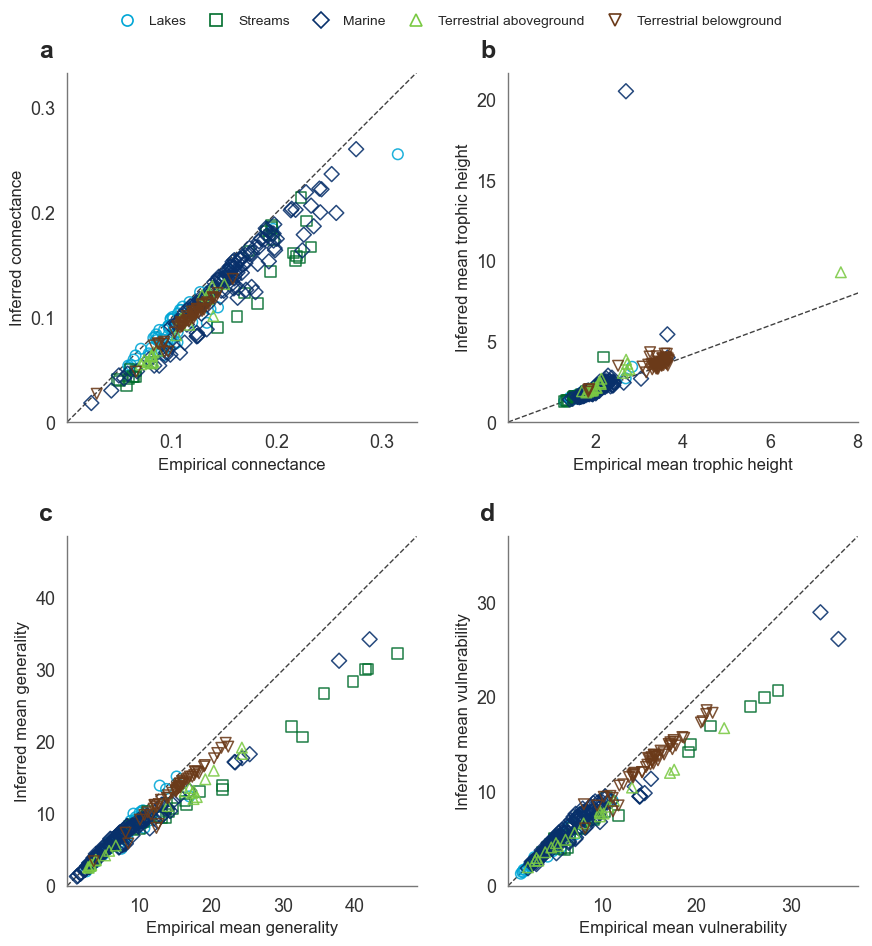

In [4]:
# Plot 1: empirical versus mean inferred value across all food webs
# Layout: 2 rows × 2 columns

fig, axes = plt.subplots(
    2,
    2,
    figsize=(11.5, 10.0),
    constrained_layout=False,
)

axes = np.asarray(axes).reshape(-1)

for panel_index, (ax, metric) in enumerate(
    zip(axes, METRIC_ORDER)
):
    metric_data = property_pairs.loc[
        property_pairs["Metric"].eq(metric)
    ]

    limits = identity_limits(metric_data)

    # Give both axes the same range and make them start at zero.
    limits = (0.0, limits[1])

    for ecosystem in ECOSYSTEM_ORDER:
        ecosystem_data = metric_data.loc[
            metric_data["Ecosystem"].eq(ecosystem)
        ]

        ax.scatter(
            ecosystem_data["EmpiricalValue"],
            ecosystem_data["MeanPseudoAfterFiltering"],
            s=58,
            marker=ECOSYSTEM_MARKERS[ecosystem],
            facecolors="none",
            edgecolors=ECOSYSTEM_PALETTE[ecosystem],
            linewidths=1.1,
            alpha=0.88,
            zorder=2,
        )

    add_identity_line(ax, limits)

    # Ensure that x and y share the same origin and range.
    ax.set_xlim(limits)
    ax.set_ylim(limits)

    # Panel B: empirical values do not exceed 10.
    if panel_index == 1:
        ax.set_xlim(0.0, 8.0)

    # Keep every panel physically square, even when its x- and y-ranges differ.
    ax.set_aspect("auto")
    ax.set_box_aspect(1)

    # Hide the x-axis zero label so only one zero is shown
    # at the lower-left corner.
    ax.xaxis.set_major_formatter(
        FuncFormatter(
            lambda value, position: (
                ""
                if np.isclose(value, 0.0)
                else f"{value:g}"
            )
        )
    )

    # Simplify the y-axis ticks in panels A, B, and D.
    if panel_index == 0:
        ax.set_yticks(
            [0.0, 0.1, 0.2, 0.3],
            labels=["0", "0.1", "0.2", "0.3"],
        )

    elif panel_index == 1:
        ax.set_yticks(
            [0, 5, 10, 15, 20],
            labels=["0", "5", "10", "15", "20"],
        )

    elif panel_index == 3:
        ax.set_yticks(
            [0, 10, 20, 30],
            labels=["0", "10", "20", "30"],
        )

    metric_axis_label = METRIC_LABELS[metric].lower()

    ax.set_xlabel(
        f"Empirical {metric_axis_label}",
        fontsize=12,
    )
    ax.set_ylabel(
        f"Inferred {metric_axis_label}",
        fontsize=12,
    )

    add_panel_label(
        ax,
        PANEL_LETTERS[panel_index],
    )

legend_handles = [
    Line2D(
        [0],
        [0],
        marker=ECOSYSTEM_MARKERS[ecosystem],
        linestyle="none",
        markersize=8,
        markerfacecolor="none",
        markeredgecolor=ECOSYSTEM_PALETTE[ecosystem],
        markeredgewidth=1.2,
        label=ECOSYSTEM_LABELS[ecosystem],
    )
    for ecosystem in ECOSYSTEM_ORDER
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.4, 0.95),
    columnspacing=1.2,
    handletextpad=0.6,
    fontsize=10,
)

fig.tight_layout(
    rect=(0, 0, 0.8, 0.93),
    h_pad=2.0,
    w_pad=1.8,
)

finish_figure(
    fig,
    "empirical_vs_inferred_all_foodwebs.png",
)

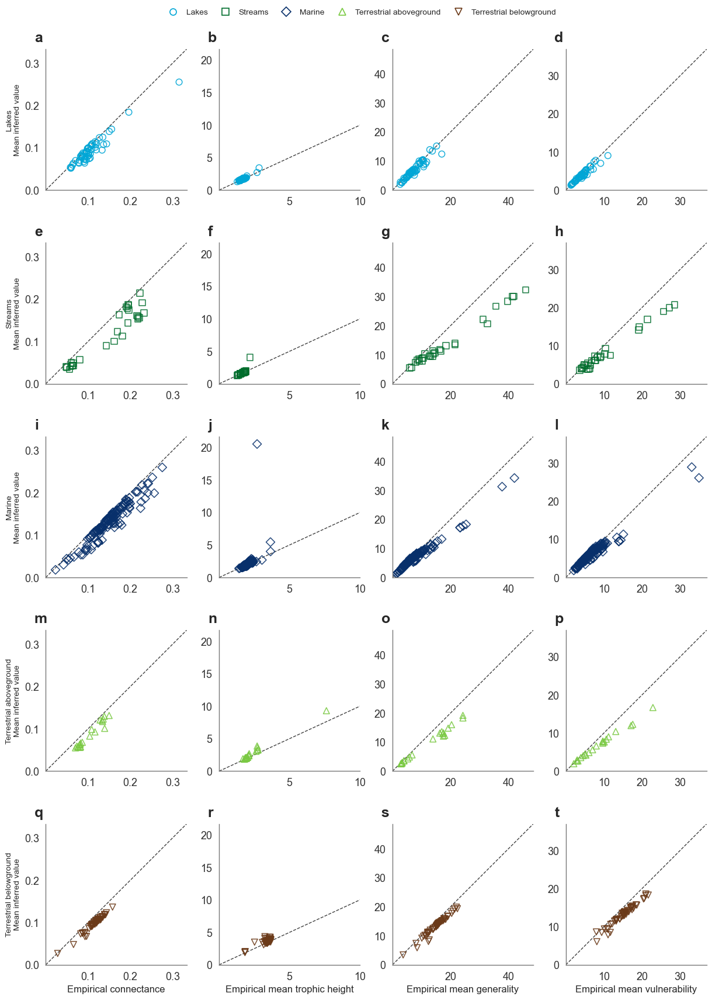

In [5]:
# Plot 2: empirical versus mean inferred value
# for each ecosystem and metric

fig, axes = plt.subplots(
    len(ECOSYSTEM_ORDER),
    len(METRIC_ORDER),
    figsize=(15.5, 17.5),
    squeeze=False,
    sharex=False,
    sharey=False
)

metric_limits = {}

for metric in METRIC_ORDER:
    metric_data = property_pairs.loc[
        property_pairs["Metric"].eq(metric)
    ]

    calculated_limits = identity_limits(metric_data)

    metric_limits[metric] = (
        0.0,
        calculated_limits[1],
    )

for row_index, ecosystem in enumerate(
    ECOSYSTEM_ORDER
):
    for column_index, metric in enumerate(
        METRIC_ORDER
    ):
        ax = axes[row_index, column_index]

        panel_data = property_pairs.loc[
            property_pairs["Ecosystem"].eq(ecosystem)
            & property_pairs["Metric"].eq(metric)
        ]

        ax.scatter(
            panel_data["EmpiricalValue"],
            panel_data["MeanPseudoAfterFiltering"],
            s=58,
            marker=ECOSYSTEM_MARKERS[ecosystem],
            facecolors="none",
            edgecolors=ECOSYSTEM_PALETTE[ecosystem],
            linewidths=1.1,
            alpha=0.88,
            zorder=2,
        )

        add_identity_line(
            ax,
            metric_limits[metric],
        )

        limits = metric_limits[metric]

        # Make both axes start at the same origin.
        ax.set_xlim(limits)
        ax.set_ylim(limits)

        # Panels B, F, J, N, and R.
        if column_index == 1:
            ax.set_xlim(0.0, 10.0)
            ax.set_xticks([0, 5, 10])

            ax.set_yticks(
                [0, 5, 10, 15, 20],
                labels=["0", "5", "10", "15", "20"],
            )

            # Preserve the physical size of the panel.
            ax.set_aspect("auto")
            ax.set_box_aspect(1)

        # Hide the x-axis zero label so that only the
        # y-axis zero appears in the lower-left corner.
        ax.xaxis.set_major_formatter(
            FuncFormatter(
                lambda value, position: (
                    ""
                    if np.isclose(value, 0.0)
                    else f"{value:g}"
                )
            )
        )

        if row_index == len(ECOSYSTEM_ORDER) - 1:
            ax.set_xlabel(
                f"Empirical {METRIC_LABELS[metric].lower()}",
                fontsize=12,
            )
        else:
            ax.set_xlabel("")

        if column_index == 0:
            ax.set_ylabel(
                f"{ECOSYSTEM_LABELS[ecosystem]}\n"
                "Mean inferred value",
                fontsize=10,
            )
        else:
            ax.set_ylabel("")

        panel_index = (
            row_index * len(METRIC_ORDER)
            + column_index
        )

        add_panel_label(
            ax,
            PANEL_LETTERS[panel_index],
        )


# ============================================================
# Global ecosystem legend
# ============================================================

legend_handles = [
    Line2D(
        [0],
        [0],
        marker=ECOSYSTEM_MARKERS[ecosystem],
        linestyle="none",
        markersize=8,
        markerfacecolor="none",
        markeredgecolor=ECOSYSTEM_PALETTE[ecosystem],
        markeredgewidth=1.2,
        label=ECOSYSTEM_LABELS[ecosystem],
    )
    for ecosystem in ECOSYSTEM_ORDER
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.4, 0.98),
    ncol=5,
    frameon=False,
    columnspacing=1.2,
    handletextpad=0.6,
    fontsize=10,
)

fig.tight_layout(
    rect=(0, 0, 0.8, 0.96),
    h_pad=2,
    w_pad=1.4,
)

finish_figure(
    fig,
    "empirical_vs_inferred_by_ecosystem.png",
)

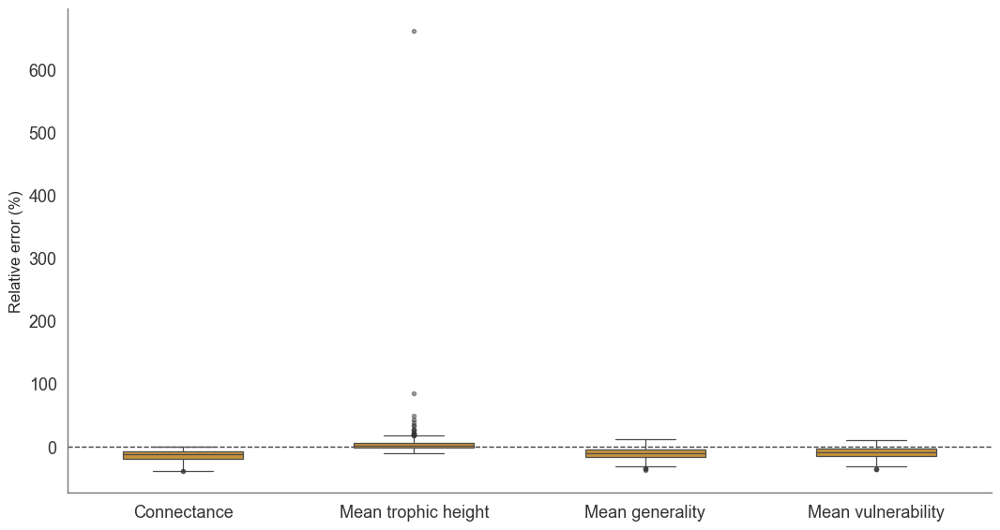

In [6]:
# Plot 3: relative-error distributions across all food webs
fig, ax = plt.subplots(figsize=(10.8, 5.8))

sns.boxplot(
    data=property_pairs,
    x="Metric",
    y="RelativeErrorPercent",
    order=METRIC_ORDER,
    color=INFERRED_COLOR,
    saturation=1.0,
    width=0.52,
    showfliers=True,
    linewidth=0.9,
    flierprops={
        "marker": "o",
        "markersize": 3.0,
        "markerfacecolor": "0.20",
        "markeredgecolor": "0.20",
        "alpha": 0.45,
    },
    ax=ax,
)

ax.axhline(0, color="0.25", linestyle="--", linewidth=1.0, zorder=0)
# ax.set_yscale("symlog", linthresh=10, linscale=1.0)
ax.set_yscale("linear")
ax.set_xlabel("")
ax.set_ylabel("Relative error (%)", fontsize=12)
ax.set_xticks(
    ax.get_xticks(),
    labels=[METRIC_LABELS[metric] for metric in METRIC_ORDER],
)
style_publication_axis(ax)
# add_panel_label(ax, "a")
# ax.text(
#     1.0, -0.18,
#     "Symmetric-log scale; linear between -10% and 10%. No food webs omitted.",
#     transform=ax.transAxes, ha="right", va="top", fontsize=9, color="0.35",
# )
fig.tight_layout()
finish_figure(fig, "relative_error_all_foodwebs.png")


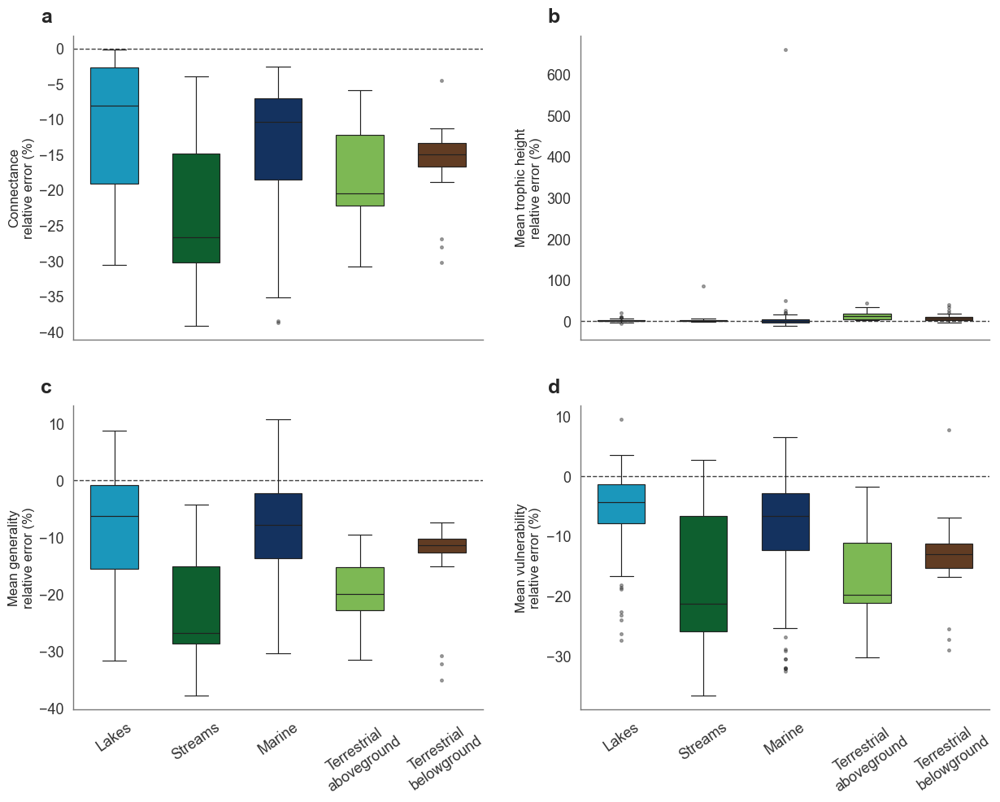

In [7]:
# Plot 4: relative errors by ecosystem,
# with one panel per property
# Layout: 2 rows × 2 columns

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12.5, 10.0),
    sharey=False,
    sharex=True,
    constrained_layout=False,
)

axes = np.asarray(axes).reshape(-1)

for panel_index, (ax, metric) in enumerate(
    zip(axes, METRIC_ORDER)
):
    metric_data = property_pairs.loc[
        property_pairs["Metric"].eq(metric)
    ]

    sns.boxplot(
        data=metric_data,
        x="Ecosystem",
        y="RelativeErrorPercent",
        hue="Ecosystem",
        order=ECOSYSTEM_ORDER,
        hue_order=ECOSYSTEM_ORDER,
        palette=ECOSYSTEM_PALETTE,
        dodge=False,
        width=0.58,
        showfliers=True,
        linewidth=0.85,
        flierprops={
            "marker": "o",
            "markersize": 2.6,
            "markerfacecolor": "0.20",
            "markeredgecolor": "0.20",
            "alpha": 0.42,
        },
        legend=False,
        ax=ax,
    )

    ax.axhline(
        0,
        color="0.25",
        linestyle="--",
        linewidth=1.0,
        zorder=0,
    )

    # ax.set_yscale(
    #     "symlog",
    #     linthresh=10,
    #     linscale=1.0,
    # )
    ax.set_yscale("linear")

    ax.set_xlabel("")

    # Show the y-axis label on the left column.
    ax.set_ylabel(
        f"{METRIC_LABELS[metric]}\nrelative error (%)",
        fontsize=12,
    )

    ax.set_xticks(
        ax.get_xticks(),
        labels=[
            "Lakes",
            "Streams",
            "Marine",
            "Terrestrial\naboveground",
            "Terrestrial\nbelowground",
        ],
        rotation=35,
        ha="center",
    )

    style_publication_axis(ax)

    add_panel_label(
        ax,
        PANEL_LETTERS[panel_index],
    )

# Optional explanatory note:
#
# fig.text(
#     0.995,
#     0.01,
#     (
#         "Symmetric-log scale; linear between -10% and 10%. "
#         "No food webs omitted."
#     ),
#     ha="right",
#     va="bottom",
#     fontsize=9,
#     color="0.35",
# )

fig.tight_layout(
    h_pad=3.0,
    w_pad=2.0,
)

finish_figure(
    fig,
    "relative_error_by_ecosystem.png",
)

In [14]:
# ============================================================
# Athen/Dave analysis: empirical vs inferred food-web properties
# Data preparation shared by the four plotting cells below
# ============================================================
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

sns.set_theme(context="paper", style="white", font_scale=1.15)


def find_repo_root(start=Path.cwd()):
    start = Path(start).resolve()
    candidates = [start, *start.parents]
    fallback = Path("/Users/acw792/Developer/qmul-phd-framework")
    if fallback not in candidates:
        candidates.append(fallback)

    for candidate in candidates:
        if (candidate / "src/matlab").is_dir() and (candidate / "docs").is_dir():
            return candidate

    raise RuntimeError("Could not locate the repository root.")


REPO_ROOT = find_repo_root()
RESULT_ROOT = (
    REPO_ROOT
    / "src/matlab/data"
    / (
        "result_wlnm_dir_neg_roleonly_trophicv2_"
        "100x290_train10-90_Apocrita_20260910_011848"
    )
)
TRAIN_RATIO = 60
CLASSIFICATION_THRESHOLD = 0.50
EXPECTED_K = 10
EXPECTED_RAW_RUNS = 100
EXPECTED_VERSION = "WLNM_dir_neg"
RAW_RESULTS_DIR = RESULT_ROOT / "prediction_scores_logs"
FOODWEB_METADATA_FILE = (
    REPO_ROOT
    / "src/matlab/data/foodwebs_mat/foodweb_metrics_ecosystem.csv"
)
FIGURE_DIR = REPO_ROOT / "docs/progress_notebooks_logs/2026/figures/week-39"
SAVE_FIGURES = False

ECOSYSTEM_ORDER = [
    "lakes",
    "streams",
    "marine",
    "terrestrial aboveground",
    "terrestrial belowground",
]
ECOSYSTEM_LABELS = {
    "lakes": "Lakes",
    "streams": "Streams",
    "marine": "Marine",
    "terrestrial aboveground": "Terrestrial aboveground",
    "terrestrial belowground": "Terrestrial belowground",
}
EXPECTED_FOODWEBS = {
    "lakes": 55,
    "streams": 28,
    "marine": 134,
    "terrestrial aboveground": 21,
    "terrestrial belowground": 52,
}
METRIC_ORDER = [
    "Connectance",
    "MeanTrophicHeight",
    "MeanNormalizedGeneralityConsumersOnly",
    "MeanNormalizedVulnerabilityResourcesOnly",
]
METRIC_LABELS = {
    "Connectance": "Connectance",
    "MeanTrophicHeight": "Mean trophic height",
    "MeanNormalizedGeneralityConsumersOnly": "Generality",
    "MeanNormalizedVulnerabilityResourcesOnly": "Vulnerability",
}
METRIC_TICK_LABELS = {
    **METRIC_LABELS,
    "MeanNormalizedGeneralityConsumersOnly": "Generality",
    "MeanNormalizedVulnerabilityResourcesOnly": "Vulnerability",
}
METRIC_AXIS_OVERRIDES = {
    "Connectance": {
        "yticks": [0.0, 0.1, 0.2, 0.3],
    },
    "MeanTrophicHeight": {
        "xlim": (0.0, 8.0),
        "xticks": [0, 5],
        "yticks": [0, 5, 10, 15, 20],
    },
}
ECOSYSTEM_PALETTE = {
    "lakes": "#00A6D6",
    "streams": "#006D2C",
    "marine": "#08306B",
    "terrestrial aboveground": "#7AC943",
    "terrestrial belowground": "#6B3A19",
}
ECOSYSTEM_MARKERS = {
    "lakes": "o",
    "streams": "s",
    "marine": "D",
    "terrestrial aboveground": "^",
    "terrestrial belowground": "v",
}
INFERRED_COLOR = "#C6923A"
PANEL_LETTERS = list("abcdefghijklmnopqrstuvwxyz") + ["aa", "ab", "ac", "ad"]

def normalize_foodweb_key(value):
    name = Path(str(value).strip()).name
    for extension in (".mat", ".csv"):
        if name.casefold().endswith(extension):
            name = name[: -len(extension)].rstrip()
    for suffix in ("_tax_mass", "_taxmass"):
        if name.casefold().endswith(suffix):
            name = name[: -len(suffix)].rstrip()
    return " ".join(name.replace("_", " ").casefold().split())


def foodweb_from_result_filename(path):
    marker = "_tax_mass_results_random_wlnm_dir_neg"
    if marker not in path.name:
        raise ValueError(f"Unexpected raw-result filename: {path.name}")
    return path.name.split(marker, 1)[0]


if not RAW_RESULTS_DIR.is_dir():
    raise FileNotFoundError(RAW_RESULTS_DIR)
if not FOODWEB_METADATA_FILE.is_file():
    raise FileNotFoundError(FOODWEB_METADATA_FILE)

metadata = pd.read_csv(FOODWEB_METADATA_FILE)
metadata_required = {"Foodweb", "EcosystemType"}
metadata_missing = metadata_required.difference(metadata.columns)
if metadata_missing:
    raise KeyError(
        f"Food-web metadata is missing columns: {sorted(metadata_missing)}"
    )
metadata["FW_KEY"] = metadata["Foodweb"].map(normalize_foodweb_key)
if metadata["FW_KEY"].duplicated().any():
    raise RuntimeError("Duplicated normalized food-web keys in metadata.")
metadata_by_key = metadata.set_index("FW_KEY")

raw_columns = [
    "Version",
    "K",
    "TrainRatio",
    "ExperimentID",
    "Seed",
    "Threshold",
    "EmpiricalNumSpecies",
    "EmpiricalLinks",
    "EmpiricalConnectance",
    "EmpiricalMeanGenerality",
    "EmpiricalMeanVulnerability",
    "EmpiricalNetworkXMeanTrophicLevel",
    "EmpiricalNetworkXTrophicLevelStatusCode",
    "EmpiricalNetworkXTrophicLevelNumSpeciesWithLevel",
    "PseudoNumSpecies",
    "PseudoLinks",
    "PseudoConnectance",
    "PseudoMeanGenerality",
    "PseudoMeanVulnerability",
    "PseudoNetworkXMeanTrophicLevel",
    "PseudoNetworkXTrophicLevelStatusCode",
    "PseudoNetworkXTrophicLevelNumSpeciesWithLevel",
]
numeric_raw_columns = [
    column for column in raw_columns if column != "Version"
]


def add_raw_metric(rows, common, metric, pseudo_values, empirical_values, valid):
    pseudo_values = pd.to_numeric(pseudo_values, errors="coerce")
    empirical_values = pd.to_numeric(empirical_values, errors="coerce")
    valid = (
        valid
        & np.isfinite(pseudo_values)
        & np.isfinite(empirical_values)
    )
    valid_count = int(valid.sum())
    if valid_count == 0:
        raise RuntimeError(
            f"{common['FoodWeb']}, {metric}: no valid raw runs."
        )
    if metric != "MeanTrophicHeight" and valid_count != EXPECTED_RAW_RUNS:
        raise RuntimeError(
            f"{common['FoodWeb']}, {metric}: expected {EXPECTED_RAW_RUNS} "
            f"raw runs, found {valid_count}."
        )

    reference_values = empirical_values.loc[valid].to_numpy(dtype=float)
    if np.ptp(reference_values) > 1e-12:
        raise RuntimeError(
            f"{common['FoodWeb']}, {metric}: empirical reference varies "
            "across raw runs."
        )

    empirical_value = float(reference_values[0])
    mean_pseudo_raw = float(pseudo_values.loc[valid].mean())
    difference = mean_pseudo_raw - empirical_value
    rows.append(
        {
            **common,
            "Metric": metric,
            "EmpiricalValue": empirical_value,
            "MeanPseudoRaw": mean_pseudo_raw,
            "ValidRawRuns": valid_count,
            "TukeyOutliersRemoved": 0,
            "Difference": difference,
            "DifferenceDirection": (
                "Pseudo > empirical" if difference > 0
                else "Pseudo < empirical" if difference < 0
                else "Equal"
            ),
        }
    )


raw_files = sorted(RAW_RESULTS_DIR.glob("*.csv"))
if len(raw_files) != 290:
    raise RuntimeError(
        f"Expected 290 raw result files, found {len(raw_files)}."
    )

raw_metric_rows = []
for raw_path in raw_files:
    raw = pd.read_csv(raw_path, usecols=raw_columns)
    for column in numeric_raw_columns:
        raw[column] = pd.to_numeric(raw[column], errors="coerce")

    selected = raw.loc[
        raw["Version"].eq(EXPECTED_VERSION)
        & raw["TrainRatio"].eq(TRAIN_RATIO)
        & np.isclose(raw["Threshold"], CLASSIFICATION_THRESHOLD)
        & raw["K"].eq(EXPECTED_K)
    ].copy()
    if len(selected) != EXPECTED_RAW_RUNS:
        raise RuntimeError(
            f"{raw_path.name}: expected {EXPECTED_RAW_RUNS} raw runs at "
            f"TrainRatio={TRAIN_RATIO}, found {len(selected)}."
        )
    if selected.duplicated(["ExperimentID", "Seed"]).any():
        raise RuntimeError(f"{raw_path.name}: duplicated raw runs.")

    key = normalize_foodweb_key(foodweb_from_result_filename(raw_path))
    if key not in metadata_by_key.index:
        raise RuntimeError(f"Missing ecosystem metadata for {raw_path.name}.")
    metadata_row = metadata_by_key.loc[key]
    common = {
        "Scenario": RESULT_ROOT.name,
        "Version": EXPECTED_VERSION,
        "TrainRatio": TRAIN_RATIO,
        "FoodWeb": str(metadata_row["Foodweb"]),
        "FW_KEY": key,
        "Ecosystem": str(metadata_row["EcosystemType"]),
    }

    all_runs = pd.Series(True, index=selected.index)
    add_raw_metric(
        raw_metric_rows,
        common,
        "Connectance",
        selected["PseudoConnectance"],
        selected["EmpiricalConnectance"],
        all_runs,
    )

    trophic_valid = (
        selected["PseudoNetworkXTrophicLevelStatusCode"].eq(0)
        & selected["PseudoNetworkXTrophicLevelNumSpeciesWithLevel"].ge(2)
        & selected["EmpiricalNetworkXTrophicLevelStatusCode"].eq(0)
        & selected["EmpiricalNetworkXTrophicLevelNumSpeciesWithLevel"].ge(2)
    )
    add_raw_metric(
        raw_metric_rows,
        common,
        "MeanTrophicHeight",
        selected["PseudoNetworkXMeanTrophicLevel"],
        selected["EmpiricalNetworkXMeanTrophicLevel"],
        trophic_valid,
    )

    pseudo_scale = selected["PseudoLinks"] / selected["PseudoNumSpecies"]
    empirical_scale = (
        selected["EmpiricalLinks"] / selected["EmpiricalNumSpecies"]
    )
    normalized_valid = pseudo_scale.gt(0) & empirical_scale.gt(0)
    add_raw_metric(
        raw_metric_rows,
        common,
        "MeanNormalizedGeneralityConsumersOnly",
        selected["PseudoMeanGenerality"] / pseudo_scale,
        selected["EmpiricalMeanGenerality"] / empirical_scale,
        normalized_valid,
    )
    add_raw_metric(
        raw_metric_rows,
        common,
        "MeanNormalizedVulnerabilityResourcesOnly",
        selected["PseudoMeanVulnerability"] / pseudo_scale,
        selected["EmpiricalMeanVulnerability"] / empirical_scale,
        normalized_valid,
    )

property_pairs = pd.DataFrame(raw_metric_rows)

# Compatibility aliases keep the four plotting cells below unchanged.  Both
# columns contain raw, unfiltered summaries; no Tukey fences are calculated.
property_pairs["MeanPseudoAfterFiltering"] = property_pairs["MeanPseudoRaw"]
property_pairs["ValidRunsAfterFiltering"] = property_pairs["ValidRawRuns"]

if property_pairs.duplicated(["FoodWeb", "Ecosystem", "Metric"]).any():
    raise RuntimeError("Duplicated food-web/ecosystem/metric pairs were found.")

numeric_columns = ["EmpiricalValue", "MeanPseudoRaw", "ValidRawRuns"]
if not np.isfinite(property_pairs[numeric_columns].to_numpy(dtype=float)).all():
    raise RuntimeError("Non-finite values were found in the raw plotting input.")
if (property_pairs["EmpiricalValue"] <= 0).any():
    raise RuntimeError("Relative error requires strictly positive empirical values.")

for metric in METRIC_ORDER:
    metric_data = property_pairs.loc[property_pairs["Metric"].eq(metric)]
    if metric_data["FoodWeb"].nunique() != 290:
        raise RuntimeError(
            f"{metric}: expected 290 food webs, found "
            f"{metric_data['FoodWeb'].nunique()}."
        )

observed_counts = (
    property_pairs.groupby(["Ecosystem", "Metric"], observed=False)
    .size()
)
for ecosystem in ECOSYSTEM_ORDER:
    for metric in METRIC_ORDER:
        observed = int(observed_counts.get((ecosystem, metric), 0))
        expected = EXPECTED_FOODWEBS[ecosystem]
        if observed != expected:
            raise RuntimeError(
                f"{ecosystem}, {metric}: expected {expected}, found {observed}."
            )

property_pairs["RelativeError"] = (
    property_pairs["MeanPseudoRaw"]
    - property_pairs["EmpiricalValue"]
) / property_pairs["EmpiricalValue"]
property_pairs["RelativeErrorPercent"] = 100 * property_pairs["RelativeError"]
property_pairs["MetricLabel"] = property_pairs["Metric"].map(METRIC_LABELS)
property_pairs["EcosystemLabel"] = property_pairs["Ecosystem"].map(ECOSYSTEM_LABELS)


def identity_limits(data, pad_fraction=0.06):
    values = np.concatenate(
        [
            data["EmpiricalValue"].to_numpy(dtype=float),
            data["MeanPseudoAfterFiltering"].to_numpy(dtype=float),
        ]
    )
    lower = float(np.nanmin(values))
    upper = float(np.nanmax(values))
    span = upper - lower
    if np.isclose(span, 0):
        span = max(abs(lower), 1.0) * 0.10
    padding = pad_fraction * span
    return lower - padding, upper + padding


def style_publication_axis(ax):
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#777777")
    ax.spines["bottom"].set_color("#777777")
    ax.tick_params(axis="both", colors="#333333", labelsize=13)


def add_panel_label(ax, letter):
    ax.text(
        -0.08, 1.03, letter,
        transform=ax.transAxes,
        fontsize=18,
        fontweight="bold",
        va="bottom",
        ha="left",
        clip_on=False,
    )


def add_identity_line(ax, limits):
    ax.plot(limits, limits, color="0.25", linestyle="--", linewidth=1.0, zorder=1)
    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_aspect("equal", adjustable="box")
    style_publication_axis(ax)


def finish_figure(fig, filename):
    if SAVE_FIGURES:
        FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        output_path = FIGURE_DIR / filename
        fig.savefig(output_path, dpi=300, bbox_inches="tight")
        print(f"[SAVED] {output_path}")
    plt.show()


validation_summary = (
    property_pairs.groupby(["EcosystemLabel", "MetricLabel"], observed=False)
    .agg(
        FoodWebs=("FoodWeb", "nunique"),
        MinimumRawRuns=("ValidRawRuns", "min"),
        MaximumRawRuns=("ValidRawRuns", "max"),
        MedianRelativeErrorPercent=("RelativeErrorPercent", "median"),
    )
    .reset_index()
)

print(f"[INFO] Raw source directory: {RAW_RESULTS_DIR}")
print(
    f"[INFO] Train ratio: {TRAIN_RATIO}%; arithmetic means over raw valid "
    "runs; no Tukey filtering."
)
print(
    "[INFO] MeanTrophicHeight excludes only diagnostically invalid raw "
    "NetworkX values; it does not exclude Tukey outliers."
)
print("[INFO] Relative error = (mean inferred - empirical) / empirical.")
expected_rows = 290 * len(METRIC_ORDER)
if len(property_pairs) != expected_rows:
    raise RuntimeError(
        f"Expected {expected_rows:,} plotting rows, found {len(property_pairs):,}."
    )
print(
    f"[INFO] Validated rows: {len(property_pairs):,} = "
    f"290 food webs x {len(METRIC_ORDER)} metrics."
)
display(validation_summary)


[INFO] Raw source directory: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848/prediction_scores_logs
[INFO] Train ratio: 60%; arithmetic means over raw valid runs; no Tukey filtering.
[INFO] MeanTrophicHeight excludes only diagnostically invalid raw NetworkX values; it does not exclude Tukey outliers.
[INFO] Relative error = (mean inferred - empirical) / empirical.
[INFO] Validated rows: 1,160 = 290 food webs x 4 metrics.


,EcosystemLabel,MetricLabel,FoodWebs,MinimumRawRuns,MaximumRawRuns,MedianRelativeErrorPercent
0,Lakes,Connectance,55,100,100,-8.439024e+00
1,Lakes,Generality,55,100,100,2.620748e+00
2,Lakes,Mean trophic height,55,65,100,3.507046e+00
3,Lakes,Vulnerability,55,100,100,2.633519e+00
4,Marine,Connectance,134,100,100,-1.026585e+01
5,Marine,Generality,134,100,100,5.126529e+00
6,Marine,Mean trophic height,134,51,100,4.778552e+00
7,Marine,Vulnerability,134,100,100,6.269641e+00
8,Streams,Connectance,28,100,100,-2.666525e+01
9,Streams,Generality,28,100,100,-5.271716e-11


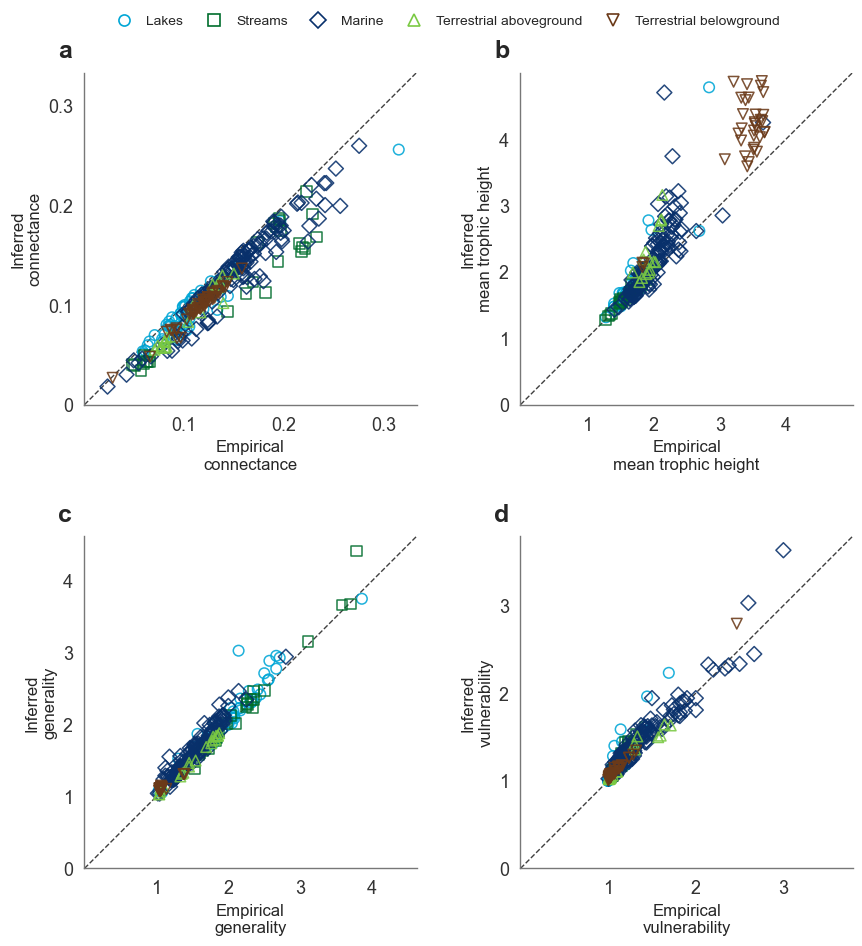

In [15]:
# Plot 1: empirical versus mean inferred value across all food webs
# Layout: 2 rows × 2 columns

fig, axes = plt.subplots(
    2,
    2,
    figsize=(11.5, 10.0),
    constrained_layout=False,
)

axes = np.asarray(axes).reshape(-1)

for panel_index, (ax, metric) in enumerate(
    zip(axes, METRIC_ORDER)
):
    metric_data = property_pairs.loc[
        property_pairs["Metric"].eq(metric)
    ]

    limits = identity_limits(metric_data)

    # Give both axes the same range and make them start at zero.
    limits = (0.0, limits[1])

    for ecosystem in ECOSYSTEM_ORDER:
        ecosystem_data = metric_data.loc[
            metric_data["Ecosystem"].eq(ecosystem)
        ]

        ax.scatter(
            ecosystem_data["EmpiricalValue"],
            ecosystem_data["MeanPseudoAfterFiltering"],
            s=58,
            marker=ECOSYSTEM_MARKERS[ecosystem],
            facecolors="none",
            edgecolors=ECOSYSTEM_PALETTE[ecosystem],
            linewidths=1.1,
            alpha=0.88,
            zorder=2,
        )

    add_identity_line(ax, limits)

    # Ensure that x and y share the same origin and range.
    ax.set_xlim(limits)
    ax.set_ylim(limits)

    axis_config = METRIC_AXIS_OVERRIDES.get(metric, {})
    if "xlim" in axis_config:
        ax.set_xlim(axis_config["xlim"])
    if "xticks" in axis_config:
        ax.set_xticks(axis_config["xticks"])
    if "yticks" in axis_config:
        ax.set_yticks(axis_config["yticks"])

    # Panel b: use evenly spaced empirical trophic-height ticks.
    if panel_index == 1:
        ax.set_xticks([1, 2, 3, 4])
        ax.set_yticks([0, 1, 2, 3, 4])

    # Panels c and d: show integer ticks only on both axes.
    if panel_index in (2, 3):
        x_upper = np.floor(ax.get_xlim()[1])
        y_upper = np.floor(ax.get_ylim()[1])
        ax.set_xticks(np.arange(0.0, x_upper + 1.0, 1.0))
        ax.set_yticks(np.arange(0.0, y_upper + 1.0, 1.0))

    # Keep every panel physically square, even when its x- and y-ranges differ.
    ax.set_aspect("auto")
    ax.set_box_aspect(1)

    # Hide the x-axis zero label so only one zero is shown
    # at the lower-left corner.
    ax.xaxis.set_major_formatter(
        FuncFormatter(
            lambda value, position: (
                ""
                if np.isclose(value, 0.0)
                else f"{value:g}"
            )
        )
    )

    # Show the single lower-left zero as an integer on the y-axis.
    ax.yaxis.set_major_formatter(
        FuncFormatter(
            lambda value, position: (
                "0"
                if np.isclose(value, 0.0)
                else f"{value:g}"
            )
        )
    )

    metric_axis_label = METRIC_TICK_LABELS[metric].lower()

    ax.set_xlabel(
        f"Empirical\n{metric_axis_label}",
        fontsize=12,
    )
    ax.set_ylabel(
        f"Inferred\n{metric_axis_label}",
        fontsize=12,
    )

    add_panel_label(
        ax,
        PANEL_LETTERS[panel_index],
    )

legend_handles = [
    Line2D(
        [0],
        [0],
        marker=ECOSYSTEM_MARKERS[ecosystem],
        linestyle="none",
        markersize=8,
        markerfacecolor="none",
        markeredgecolor=ECOSYSTEM_PALETTE[ecosystem],
        markeredgewidth=1.2,
        label=ECOSYSTEM_LABELS[ecosystem],
    )
    for ecosystem in ECOSYSTEM_ORDER
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.4, 0.95),
    columnspacing=1.2,
    handletextpad=0.6,
    fontsize=10,
)

# Zoom panel b while preserving all underlying observations.
axes[1].set_xlim(0, 5)
axes[1].set_ylim(0, 5)

fig.tight_layout(
    rect=(0, 0, 0.8, 0.93),
    h_pad=2.0,
    w_pad=1.8,
)

finish_figure(
    fig,
    "empirical_vs_inferred_all_foodwebs_athen_normalized_gv.png",
)

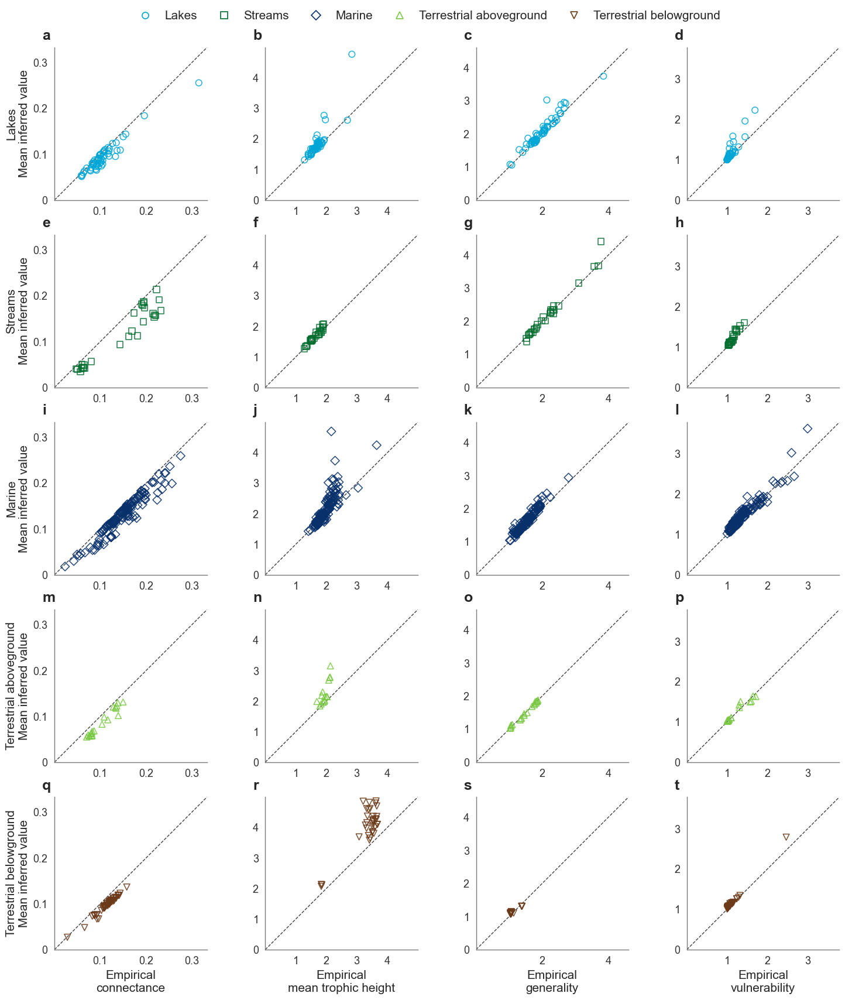

In [16]:
# Plot 2: empirical versus mean inferred value
# for each ecosystem and metric

fig, axes = plt.subplots(
    len(ECOSYSTEM_ORDER),
    len(METRIC_ORDER),
    figsize=(15.5, 17.5),
    squeeze=False,
    sharex=False,
    sharey=False
)

metric_limits = {}

for metric in METRIC_ORDER:
    metric_data = property_pairs.loc[
        property_pairs["Metric"].eq(metric)
    ]

    calculated_limits = identity_limits(metric_data)

    metric_limits[metric] = (
        0.0,
        calculated_limits[1],
    )

for row_index, ecosystem in enumerate(
    ECOSYSTEM_ORDER
):
    for column_index, metric in enumerate(
        METRIC_ORDER
    ):
        ax = axes[row_index, column_index]

        panel_data = property_pairs.loc[
            property_pairs["Ecosystem"].eq(ecosystem)
            & property_pairs["Metric"].eq(metric)
        ]

        ax.scatter(
            panel_data["EmpiricalValue"],
            panel_data["MeanPseudoAfterFiltering"],
            s=58,
            marker=ECOSYSTEM_MARKERS[ecosystem],
            facecolors="none",
            edgecolors=ECOSYSTEM_PALETTE[ecosystem],
            linewidths=1.1,
            alpha=0.88,
            zorder=2,
        )

        add_identity_line(
            ax,
            metric_limits[metric],
        )

        limits = metric_limits[metric]

        # Make both axes start at the same origin.
        ax.set_xlim(limits)
        ax.set_ylim(limits)

        axis_config = METRIC_AXIS_OVERRIDES.get(metric, {})
        if "xlim" in axis_config:
            ax.set_xlim(axis_config["xlim"])
        if "xticks" in axis_config:
            ax.set_xticks(axis_config["xticks"])
        if "yticks" in axis_config:
            ax.set_yticks(axis_config["yticks"])

        # Trophic-height column (panels b, f, j, n, r).
        if metric == "MeanTrophicHeight":
            ax.set_xlim(0, 5)
            ax.set_ylim(0, 5)
            ax.set_xticks([1, 2, 3, 4])
            ax.set_yticks([0, 1, 2, 3, 4])

        # Format the single visible origin label as 0, not 0.0.
        ax.yaxis.set_major_formatter(
            FuncFormatter(
                lambda value, position: (
                    "0"
                    if np.isclose(value, 0.0)
                    else f"{value:g}"
                )
            )
        )

        # Preserve the physical size of every panel.
        ax.set_aspect("auto")
        ax.set_box_aspect(1)

        # Hide the x-axis zero label so that only the
        # y-axis zero appears in the lower-left corner.
        ax.xaxis.set_major_formatter(
            FuncFormatter(
                lambda value, position: (
                    ""
                    if np.isclose(value, 0.0)
                    else f"{value:g}"
                )
            )
        )

        if row_index == len(ECOSYSTEM_ORDER) - 1:
            ax.set_xlabel(
                f"Empirical\n{METRIC_TICK_LABELS[metric].lower()}",
                fontsize=15,
            )
        else:
            ax.set_xlabel("")

        if column_index == 0:
            ax.set_ylabel(
                f"{ECOSYSTEM_LABELS[ecosystem]}\n"
                "Mean inferred value",
                fontsize=15,
            )
        else:
            ax.set_ylabel("")

        panel_index = (
            row_index * len(METRIC_ORDER)
            + column_index
        )

        add_panel_label(
            ax,
            PANEL_LETTERS[panel_index],
        )


# ============================================================
# Global ecosystem legend
# ============================================================

legend_handles = [
    Line2D(
        [0],
        [0],
        marker=ECOSYSTEM_MARKERS[ecosystem],
        linestyle="none",
        markersize=8,
        markerfacecolor="none",
        markeredgecolor=ECOSYSTEM_PALETTE[ecosystem],
        markeredgewidth=1.2,
        label=ECOSYSTEM_LABELS[ecosystem],
    )
    for ecosystem in ECOSYSTEM_ORDER
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.98),
    ncol=5,
    frameon=False,
    columnspacing=1.2,
    handletextpad=0.6,
    fontsize=15,
)

fig.tight_layout(
    rect=(0, 0, 1, 0.96),
    h_pad=0,
    w_pad=0,
)

finish_figure(
    fig,
    "empirical_vs_inferred_by_ecosystem_athen_normalized_gv.png",
)

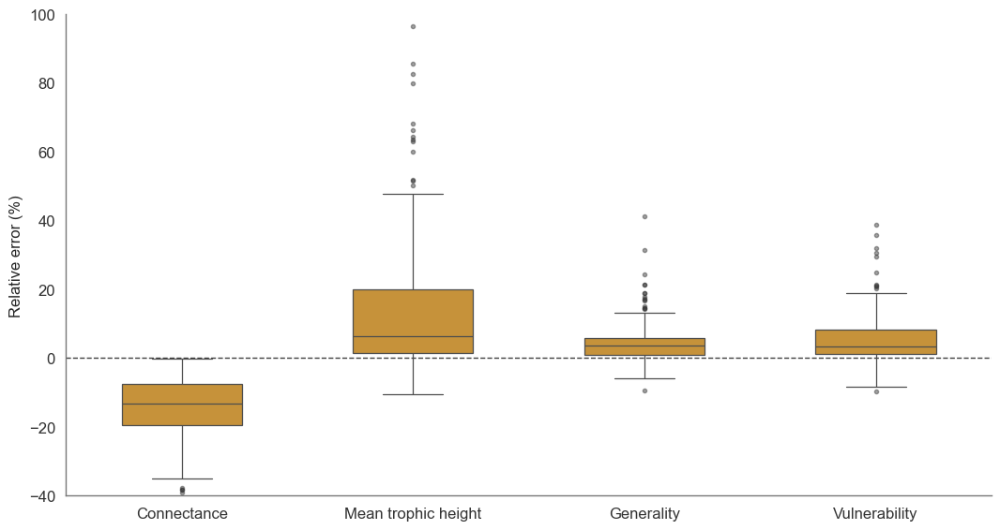

In [25]:
# Plot 3: relative-error distributions across all food webs
fig, ax = plt.subplots(figsize=(10.8, 5.8))

sns.boxplot(
    data=property_pairs,
    x="Metric",
    y="RelativeErrorPercent",
    order=METRIC_ORDER,
    color=INFERRED_COLOR,
    saturation=1.0,
    width=0.52,
    showfliers=True,
    linewidth=0.9,
    flierprops={
        "marker": "o",
        "markersize": 3.0,
        "markerfacecolor": "0.20",
        "markeredgecolor": "0.20",
        "alpha": 0.45,
    },
    ax=ax,
)

ax.axhline(0, color="0.25", linestyle="--", linewidth=1.0, zorder=0)
# ax.set_yscale("symlog", linthresh=10, linscale=1.0)
ax.set_yscale("linear")
ax.set_xlabel("")
ax.set_ylabel("Relative error (%)", fontsize=12)
ax.set_xticks(
    ax.get_xticks(),
    labels=[METRIC_TICK_LABELS[metric] for metric in METRIC_ORDER],
)
style_publication_axis(ax)
# add_panel_label(ax, "a")
# ax.text(
#     1.0, -0.18,
#     "Symmetric-log scale; linear between -10% and 10%. No food webs omitted.",
#     transform=ax.transAxes, ha="right", va="top", fontsize=9, color="0.35",
# )
# Zoom in without altering the data used to calculate the boxplots.
# Four trophic-height outliers fall outside the visible range; the
# normalized Generality and Vulnerability observations remain visible.
ax.set_ylim(-40, 100)
ax.tick_params(axis="both", labelsize=12)
fig.tight_layout()
finish_figure(fig, "relative_error_all_foodwebs_athen_normalized_gv.png")


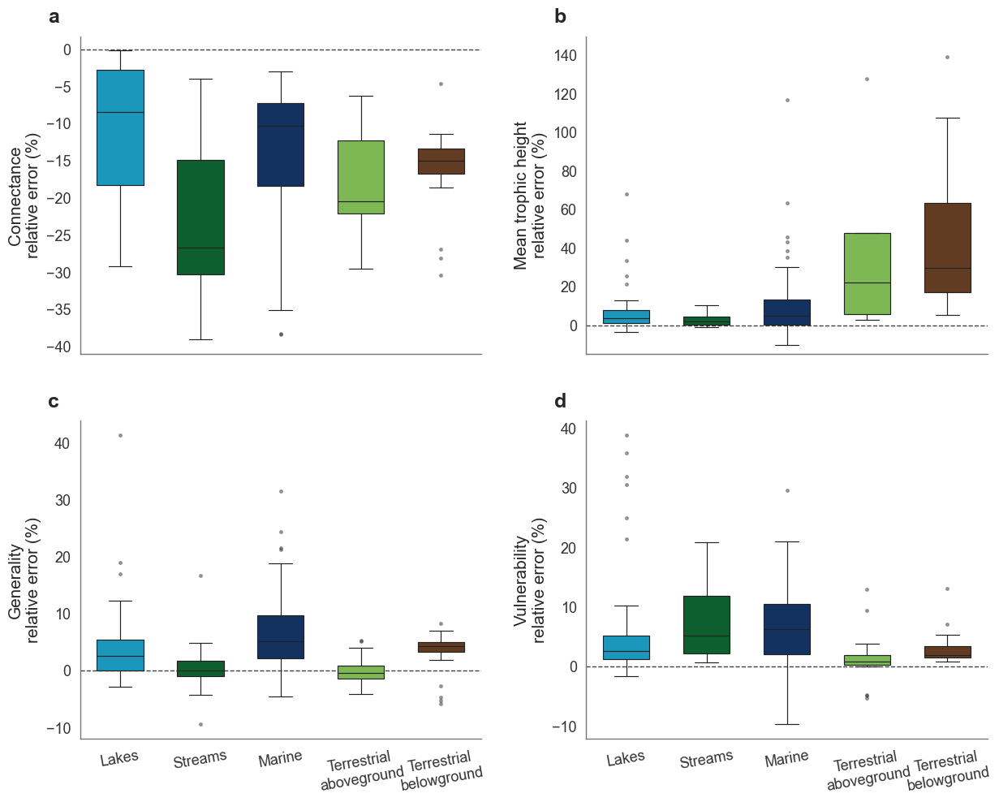

In [31]:
# Plot 4: relative errors by ecosystem,
# with one panel per property
# Layout: 2 rows × 2 columns

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12.5, 10.0),
    sharey=False,
    sharex=True,
    constrained_layout=False,
)

axes = np.asarray(axes).reshape(-1)

for panel_index, (ax, metric) in enumerate(
    zip(axes, METRIC_ORDER)
):
    metric_data = property_pairs.loc[
        property_pairs["Metric"].eq(metric)
    ]

    sns.boxplot(
        data=metric_data,
        x="Ecosystem",
        y="RelativeErrorPercent",
        hue="Ecosystem",
        order=ECOSYSTEM_ORDER,
        hue_order=ECOSYSTEM_ORDER,
        palette=ECOSYSTEM_PALETTE,
        dodge=False,
        width=0.58,
        showfliers=True,
        linewidth=0.85,
        flierprops={
            "marker": "o",
            "markersize": 2.6,
            "markerfacecolor": "0.20",
            "markeredgecolor": "0.20",
            "alpha": 0.42,
        },
        legend=False,
        ax=ax,
    )

    ax.axhline(
        0,
        color="0.25",
        linestyle="--",
        linewidth=1.0,
        zorder=0,
    )

    # ax.set_yscale(
    #     "symlog",
    #     linthresh=10,
    #     linscale=1.0,
    # )
    ax.set_yscale("linear")

    ax.set_xlabel("")

    # Show the y-axis label on the left column.
    ax.set_ylabel(
        f"{METRIC_LABELS[metric]}\nrelative error (%)",
        fontsize=15,
    )

    ax.set_xticks(
        ax.get_xticks(),
        labels=[
            "Lakes",
            "Streams",
            "Marine",
            "Terrestrial\naboveground",
            "Terrestrial\nbelowground",
        ],
        rotation=10,
        ha="center",
    )

    style_publication_axis(ax)

    add_panel_label(
        ax,
        PANEL_LETTERS[panel_index],
    )

# Optional explanatory note:
#
# fig.text(
#     0.995,
#     0.01,
#     (
#         "Symmetric-log scale; linear between -10% and 10%. "
#         "No food webs omitted."
#     ),
#     ha="right",
#     va="bottom",
#     fontsize=9,
#     color="0.35",
# )

# Zoom panel b while preserving all underlying observations.
axes[1].set_ylim(-15, 150)

fig.tight_layout(
    h_pad=3.0,
    w_pad=2.0,
)

finish_figure(
    fig,
    "relative_error_by_ecosystem_athen_normalized_gv.png",
)

In [19]:
# Tukey 1.5 x IQR: outliers removed from the 100 Modified WLNM runs
# reported for Figure 3 (TrainRatio = 90, threshold = 0.50).
from pathlib import Path
import json

import numpy as np
import pandas as pd
from IPython.display import display


def find_repo_root(start=Path.cwd()):
    candidates = [Path(start).resolve(), *Path(start).resolve().parents]
    fallback = Path("/Users/acw792/Developer/qmul-phd-framework")
    if fallback not in candidates:
        candidates.append(fallback)

    for candidate in candidates:
        if (candidate / "src/matlab").is_dir() and (candidate / "docs").is_dir():
            return candidate

    raise RuntimeError("Could not locate the qmul-phd-framework repository.")


repo_root = find_repo_root()
result_name = (
    "result_wlnm_dir_neg_roleonly_trophicv2_"
    "100x290_train10-90_Apocrita_20260910_011848"
)
retention_root = (
    repo_root
    / "src/matlab/data"
    / result_name
    / "retention_protocol"
    / "tukey_iqr_1p5_min25runs_threshold0p50_v1"
)
retention_path = retention_root / "retention_by_foodweb_metric.csv"
manifest_path = retention_root / "retention_manifest.json"

for required_path in (retention_path, manifest_path):
    if not required_path.is_file():
        raise FileNotFoundError(required_path)

with manifest_path.open("r", encoding="utf-8") as file:
    manifest = json.load(file)

source_manifest = manifest["source_manifest"]
assert manifest["scenario"] == result_name
assert np.isclose(manifest["tukey_iqr_multiplier"], 1.5)
assert np.isclose(manifest["classification_threshold"], 0.50)
assert source_manifest["Version"] == "WLNM_dir_neg"
assert source_manifest["NumExperiments"] == "100"
assert source_manifest["FoodWebs"] == "290"
assert source_manifest["MinimumRetainedAfterTukey"] == "25"

retention = pd.read_csv(retention_path)

metric_labels = {
    "ROC_AUC": "ROC-AUC",
    "F1Score": "F1",
    "TestMCC": "MCC",
    "Precision": "Precision",
}

selected = retention.loc[
    retention["Scenario"].eq(result_name)
    & retention["Version"].eq("WLNM_dir_neg")
    & retention["TrainRatio"].eq(90)
    & np.isclose(retention["Threshold"], 0.50)
    & retention["Metric"].isin(metric_labels),
].copy()

# One independent Tukey calculation must exist for every
# Foodweb x Metric group used in Figure 3.
assert len(selected) == 290 * len(metric_labels)
assert not selected.duplicated(["Foodweb", "Metric"]).any()
assert selected.groupby("Metric")["Foodweb"].nunique().eq(290).all()
assert selected["ExpectedRuns"].eq(100).all()
assert selected["ValidRunsBeforeTukey"].eq(100).all()
assert selected["InvalidRunsBeforeTukey"].eq(0).all()
assert (
    selected["OutlierRunsExcluded"]
    == selected["ValidRunsBeforeTukey"] - selected["RetainedRunsAfterTukey"]
).all()
assert selected["MinimumRetainedRuns"].eq(25).all()
assert selected["MeetsMinimumRetainedRuns"].eq(1).all()

summary = (
    selected.groupby("Metric", observed=True)
    .agg(
        FoodWebs=("Foodweb", "nunique"),
        ValuesUsedForSEM=("OutlierRunsExcluded", "size"),
        MeanOutliersRemoved=("OutlierRunsExcluded", "mean"),
        SEM=("OutlierRunsExcluded", "sem"),
        MedianRunsRetained=("RetainedRunsAfterTukey", "median"),
        MinimumRunsRetained=("RetainedRunsAfterTukey", "min"),
        MaximumRunsRetained=("RetainedRunsAfterTukey", "max"),
    )
    .reindex(metric_labels)
    .reset_index()
)
summary["Metric"] = summary["Metric"].map(metric_labels)

# This final row is explicitly descriptive: it pools the four
# metric-specific values for each of the 290 food webs (n = 1,160).
overall = pd.DataFrame(
    [{
        "Metric": "Overall (descriptive)",
        "FoodWebs": selected["Foodweb"].nunique(),
        "ValuesUsedForSEM": len(selected),
        "MeanOutliersRemoved": selected["OutlierRunsExcluded"].mean(),
        "SEM": selected["OutlierRunsExcluded"].sem(),
        "MedianRunsRetained": selected["RetainedRunsAfterTukey"].median(),
        "MinimumRunsRetained": selected["RetainedRunsAfterTukey"].min(),
        "MaximumRunsRetained": selected["RetainedRunsAfterTukey"].max(),
    }]
)
summary = pd.concat([summary, overall], ignore_index=True)

summary["Outliers removed, mean ± SEM"] = summary.apply(
    lambda row: f"{row['MeanOutliersRemoved']:.2f} ± {row['SEM']:.2f}",
    axis=1,
)
summary["Retained runs, median"] = summary["MedianRunsRetained"].map(
    lambda value: f"{value:.0f}"
)
summary["Retained runs, range"] = summary.apply(
    lambda row: (
        f"{row['MinimumRunsRetained']:.0f}–{row['MaximumRunsRetained']:.0f}"
    ),
    axis=1,
)

display_table = summary[
    [
        "Metric",
        "FoodWebs",
        "ValuesUsedForSEM",
        "Outliers removed, mean ± SEM",
        "Retained runs, median",
        "Retained runs, range",
    ]
].rename(
    columns={
        "FoodWebs": "Food webs",
        "ValuesUsedForSEM": "n used for SEM",
    }
)

print("Tukey 1.5×IQR applied independently to each Foodweb × Metric group.")
print("All groups started with 100 runs; 25 runs was only the exclusion threshold.")
display(
    display_table.style
    .hide(axis="index")
    .set_caption(
        "Modified WLNM, Figure 3: runs excluded as Tukey outliers"
    )
)
print(
    "Per-metric SEM uses 290 food webs; the descriptive overall SEM "
    "pools 1,160 food-web–metric values."
)

Tukey 1.5×IQR applied independently to each Foodweb × Metric group.
All groups started with 100 runs; 25 runs was only the exclusion threshold.


Metric,Food webs,n used for SEM,"Outliers removed, mean ± SEM","Retained runs, median","Retained runs, range"
ROC-AUC,290,290,4.60 ± 0.35,98,75–100
F1,290,290,2.59 ± 0.22,99,76–100
MCC,290,290,2.39 ± 0.22,99,76–100
Precision,290,290,6.38 ± 0.44,98,75–100
Overall (descriptive),290,1160,3.99 ± 0.17,98,75–100


Per-metric SEM uses 290 food webs; the descriptive overall SEM pools 1,160 food-web–metric values.


[INFO] Repository: /Users/acw792/Developer/qmul-phd-framework
[INFO] Yujie networks: 178
[INFO] Raw runs per network: 100
[INFO] Raw observations loaded: 17800
[INFO] Food-web means per metric: 178
[INFO] Each food-web mean uses all 100 raw runs; no Tukey filtering.
[INFO] Standard boxplots: 1.5 x IQR whiskers; food-web-level fliers shown.
[WARN] Zero-height IQR boxes: ['ROC-AUC', 'PR-AUC', 'F1', 'MCC', 'Precision', 'Recall', 'TSS']


,Metric,FoodWebs,RunsPerFoodWeb,FoodWebMeans,Mean,SD,Minimum,Q1,Median,Q3,Maximum,IQR,ZeroFoodWebs,ZeroPercent
0,ROC-AUC,178,100,178.0,0.5436,0.0982,0.3873,0.5,0.5,0.5,0.8961,0.0,0,0.0000
1,PR-AUC,178,100,178.0,0.1218,0.2284,0.0000,0.0,0.0,0.0,0.7667,0.0,135,75.8427
2,F1,178,100,178.0,0.0825,0.1732,0.0000,0.0,0.0,0.0,0.6139,0.0,135,75.8427
3,MCC,178,100,178.0,0.0692,0.1478,0.0000,0.0,0.0,0.0,0.5435,0.0,135,75.8427
4,Precision,178,100,178.0,0.1526,0.2930,0.0000,0.0,0.0,0.0,0.9200,0.0,135,75.8427
5,Recall,178,100,178.0,0.0610,0.1321,0.0000,0.0,0.0,0.0,0.4890,0.0,135,75.8427
6,TSS,178,100,178.0,0.0514,0.1154,0.0000,0.0,0.0,0.0,0.4500,0.0,135,75.8427



[INFO] Saved Yujie food-web-mean outputs (raw, no Tukey):
  PNG: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_yujie_primary60_observedzero_20261008_001116/figures_raw_unfiltered/figure_yujie_primary60_7metrics_raw_unfiltered.png
  SVG: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_yujie_primary60_observedzero_20261008_001116/figures_raw_unfiltered/figure_yujie_primary60_7metrics_raw_unfiltered.svg
  PDF: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_yujie_primary60_observedzero_20261008_001116/figures_raw_unfiltered/figure_yujie_primary60_7metrics_raw_unfiltered.pdf
  Summary: /Users/acw792/Developer/qmul-phd-framework/src/matlab/data/result_wlnm_dir_neg_yujie_primary60_observedzero_20261008_001116/figures_raw_unfiltered/figure_yujie_primary60_7metrics_raw_unfiltered_summary.csv


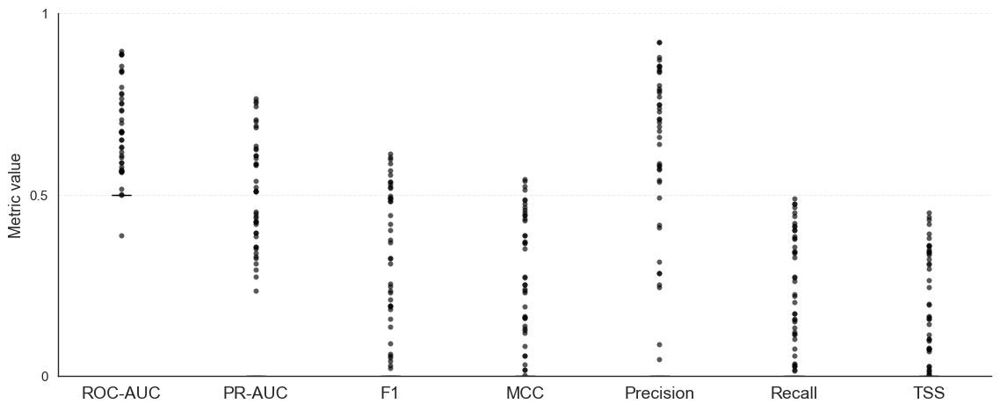

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display


sns.set_theme(
    context="paper",
    style="white",
    font_scale=1.1,
)


# ============================================================
# Locate repository and raw Yujie results
# ============================================================

def find_repo_root(start=Path.cwd()):
    start = Path(start).resolve()
    candidates = [start, *start.parents]
    fallback = Path("/Users/acw792/Developer/qmul-phd-framework")

    if fallback not in candidates:
        candidates.append(fallback)

    for candidate in candidates:
        if (
            (candidate / "src/matlab").is_dir()
            and (candidate / "docs").is_dir()
        ):
            return candidate

    raise RuntimeError("Could not locate the qmul-phd-framework repository.")


REPO_ROOT = find_repo_root()
RESULT_ROOT = (
    REPO_ROOT
    / "src/matlab/data"
    / "result_wlnm_dir_neg_yujie_primary60_observedzero_20261008_001116"
)
PREDICTION_DIR = RESULT_ROOT / "prediction_scores_logs"

EXPECTED_NETWORKS = 178
EXPECTED_RUNS_PER_NETWORK = 100
EXPECTED_VERSION = "WLNM_dir_neg"
TRAIN_RATIO_TARGET = 60
CLASSIFICATION_THRESHOLD = 0.50
K_TARGET = 10


# ============================================================
# Metrics and publication output
# ============================================================

METRIC_SPECS = [
    ("ROC_AUC", "ROC-AUC"),
    ("PR_AUC", "PR-AUC"),
    ("F1Score", "F1"),
    ("TestMCC", "MCC"),
    ("Precision", "Precision"),
    ("Recall", "Recall"),
    ("TestTSS", "TSS"),
]
METRIC_ORDER = [metric for metric, _ in METRIC_SPECS]
METRIC_LABELS = dict(METRIC_SPECS)

OUT_DIR = RESULT_ROOT / "figures_raw_unfiltered"
OUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_STEM = "figure_yujie_primary60_7metrics_raw_unfiltered"
PNG_PATH = OUT_DIR / f"{OUTPUT_STEM}.png"
SVG_PATH = OUT_DIR / f"{OUTPUT_STEM}.svg"
PDF_PATH = OUT_DIR / f"{OUTPUT_STEM}.pdf"
SUMMARY_PATH = OUT_DIR / f"{OUTPUT_STEM}_summary.csv"

YUJIE_COLOR = "#1F78B4"
SHOW_WEB_LEVEL_FLIERS = True


# ============================================================
# Load raw runs and average within each food web; no Tukey filtering
# ============================================================

files = sorted(PREDICTION_DIR.glob("*.csv"))
if len(files) != EXPECTED_NETWORKS:
    raise ValueError(
        f"Expected {EXPECTED_NETWORKS} Yujie result files; found {len(files)}."
    )

required_columns = {
    "Version",
    "TrainRatio",
    "ExperimentID",
    "Threshold",
    "K",
    *METRIC_ORDER,
}

frames = []
for path in files:
    frame = pd.read_csv(
        path,
        usecols=lambda column: column in required_columns,
    )
    missing = required_columns.difference(frame.columns)
    if missing:
        raise ValueError(f"{path.name}: missing columns {sorted(missing)}")

    numeric_columns = required_columns.difference({"Version"})
    for column in numeric_columns:
        frame[column] = pd.to_numeric(frame[column], errors="coerce")

    frame["TrainRatio"] = np.where(
        frame["TrainRatio"].abs().le(1.0),
        frame["TrainRatio"] * 100.0,
        frame["TrainRatio"],
    )

    valid_configuration = (
        frame["Version"].eq(EXPECTED_VERSION)
        & np.isclose(frame["TrainRatio"], TRAIN_RATIO_TARGET)
        & np.isclose(frame["Threshold"], CLASSIFICATION_THRESHOLD)
        & np.isclose(frame["K"], K_TARGET)
    )
    if not valid_configuration.all():
        raise ValueError(f"{path.name}: contains rows outside the Yujie protocol.")

    if len(frame) != EXPECTED_RUNS_PER_NETWORK:
        raise ValueError(
            f"{path.name}: expected {EXPECTED_RUNS_PER_NETWORK} raw runs; "
            f"found {len(frame)}."
        )
    if frame["ExperimentID"].duplicated().any():
        raise ValueError(f"{path.name}: duplicated ExperimentID values.")
    if set(frame["ExperimentID"].astype(int)) != set(
        range(1, EXPECTED_RUNS_PER_NETWORK + 1)
    ):
        raise ValueError(f"{path.name}: incomplete ExperimentID coverage.")

    frame["Foodweb"] = re.sub(
        r"_results_random_wlnm_dir_neg\.csv$",
        "",
        path.name,
        flags=re.I,
    )
    frames.append(frame)

raw = pd.concat(frames, ignore_index=True)
expected_rows = EXPECTED_NETWORKS * EXPECTED_RUNS_PER_NETWORK
if len(raw) != expected_rows:
    raise ValueError(f"Expected {expected_rows} raw rows; found {len(raw)}.")
if raw.duplicated(["Foodweb", "ExperimentID"]).any():
    raise ValueError("Duplicated Foodweb x ExperimentID rows detected.")
if not np.isfinite(raw[METRIC_ORDER].to_numpy(float)).all():
    raise ValueError("Non-finite predictive metric values detected.")

probability_metrics = [
    "ROC_AUC",
    "PR_AUC",
    "F1Score",
    "Precision",
    "Recall",
]
if (
    (raw[probability_metrics].to_numpy(float) < 0)
    | (raw[probability_metrics].to_numpy(float) > 1)
).any():
    raise ValueError("Probability metrics must be within [0, 1].")
if (
    (raw[["TestMCC", "TestTSS"]].to_numpy(float) < -1)
    | (raw[["TestMCC", "TestTSS"]].to_numpy(float) > 1)
).any():
    raise ValueError("MCC and TSS must be within [-1, 1].")

foodweb_means = (
    raw.groupby("Foodweb", as_index=False)[METRIC_ORDER]
    .mean()
)
if len(foodweb_means) != EXPECTED_NETWORKS:
    raise ValueError(
        f"Expected {EXPECTED_NETWORKS} food-web means; "
        f"found {len(foodweb_means)}."
    )
if not np.isfinite(foodweb_means[METRIC_ORDER].to_numpy(float)).all():
    raise ValueError("Non-finite food-web mean metric values detected.")

summary_table = (
    foodweb_means[METRIC_ORDER]
    .describe(percentiles=[0.25, 0.50, 0.75])
    .T
    .rename(
        columns={
            "count": "FoodWebMeans",
            "mean": "Mean",
            "std": "SD",
            "min": "Minimum",
            "25%": "Q1",
            "50%": "Median",
            "75%": "Q3",
            "max": "Maximum",
        }
    )
    .reset_index(names="Metric")
)
summary_table["IQR"] = summary_table["Q3"] - summary_table["Q1"]
zero_counts = foodweb_means[METRIC_ORDER].eq(0).sum().to_dict()
summary_table["ZeroFoodWebs"] = summary_table["Metric"].map(zero_counts)
summary_table["ZeroPercent"] = (
    100.0 * summary_table["ZeroFoodWebs"] / EXPECTED_NETWORKS
)
summary_table["Metric"] = summary_table["Metric"].map(METRIC_LABELS)
summary_table.insert(1, "FoodWebs", EXPECTED_NETWORKS)
summary_table.insert(2, "RunsPerFoodWeb", EXPECTED_RUNS_PER_NETWORK)
summary_table.to_csv(SUMMARY_PATH, index=False)

print(f"[INFO] Repository: {REPO_ROOT}")
print(f"[INFO] Yujie networks: {EXPECTED_NETWORKS}")
print(f"[INFO] Raw runs per network: {EXPECTED_RUNS_PER_NETWORK}")
print(f"[INFO] Raw observations loaded: {expected_rows}")
print(f"[INFO] Food-web means per metric: {len(foodweb_means)}")
print("[INFO] Each food-web mean uses all 100 raw runs; no Tukey filtering.")
print("[INFO] Standard boxplots: 1.5 x IQR whiskers; food-web-level fliers shown.")
if summary_table["IQR"].eq(0).any():
    collapsed = summary_table.loc[summary_table["IQR"].eq(0), "Metric"].tolist()
    print(f"[WARN] Zero-height IQR boxes: {collapsed}")
display(summary_table.round(4))


# ============================================================
# Plot: same styling, Yujie food-web means only
# ============================================================

fig, ax = plt.subplots(figsize=(11.5, 4.8))

group_gap = 1.5
group_centers = 1.0 + np.arange(len(METRIC_SPECS)) * group_gap

metric_values = [
    foodweb_means[metric].to_numpy(float)
    for metric, _ in METRIC_SPECS
]

ax.boxplot(
    metric_values,
    positions=group_centers,
    widths=0.22,
    patch_artist=True,
    manage_ticks=False,
    showfliers=SHOW_WEB_LEVEL_FLIERS,
    whis=1.5,
    boxprops={
        "facecolor": YUJIE_COLOR,
        "edgecolor": "black",
        "linewidth": 0.8,
        "alpha": 0.95,
    },
    medianprops={
        "color": "black",
        "linewidth": 1.0,
    },
    whiskerprops={
        "color": "black",
        "linewidth": 0.8,
    },
    capprops={
        "color": "black",
        "linewidth": 0.8,
    },
    flierprops={
        "marker": "o",
        "markersize": 4,
        "markerfacecolor": "black",
        "markeredgecolor": "black",
        "markeredgewidth": 0.2,
        "alpha": 0.65,
    },
)

ax.set_xlim(group_centers[0] - 0.7, group_centers[-1] + 0.7)
ax.set_ylim(0, 1.0)
ax.set_xticks(
    group_centers,
    labels=[label for _, label in METRIC_SPECS],
)

plt.setp(
    ax.get_xticklabels(),
    rotation=0,
    fontsize=14,
)

ax.set_ylabel("Metric value", fontsize=13)
ax.set_xlabel("")
ax.set_yticks([0, 0.5, 1.0])
ax.set_yticklabels(["0", "0.5", "1"])
ax.tick_params(axis="y", labelsize=11)
ax.grid(
    True,
    axis="y",
    linestyle="--",
    alpha=0.35,
)

sns.despine(ax=ax)
plt.tight_layout()


# ============================================================
# Export
# ============================================================

fig.savefig(
    PNG_PATH,
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
)
fig.savefig(
    SVG_PATH,
    bbox_inches="tight",
    facecolor="white",
)
fig.savefig(
    PDF_PATH,
    bbox_inches="tight",
    facecolor="white",
)

print("\n[INFO] Saved Yujie food-web-mean outputs (raw, no Tukey):")
print(f"  PNG: {PNG_PATH}")
print(f"  SVG: {SVG_PATH}")
print(f"  PDF: {PDF_PATH}")
print(f"  Summary: {SUMMARY_PATH}")

plt.show()

[INFO] Yujie networks available: 178
[INFO] Pages: 15 (12 networks per page)
[INFO] Pages selected: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


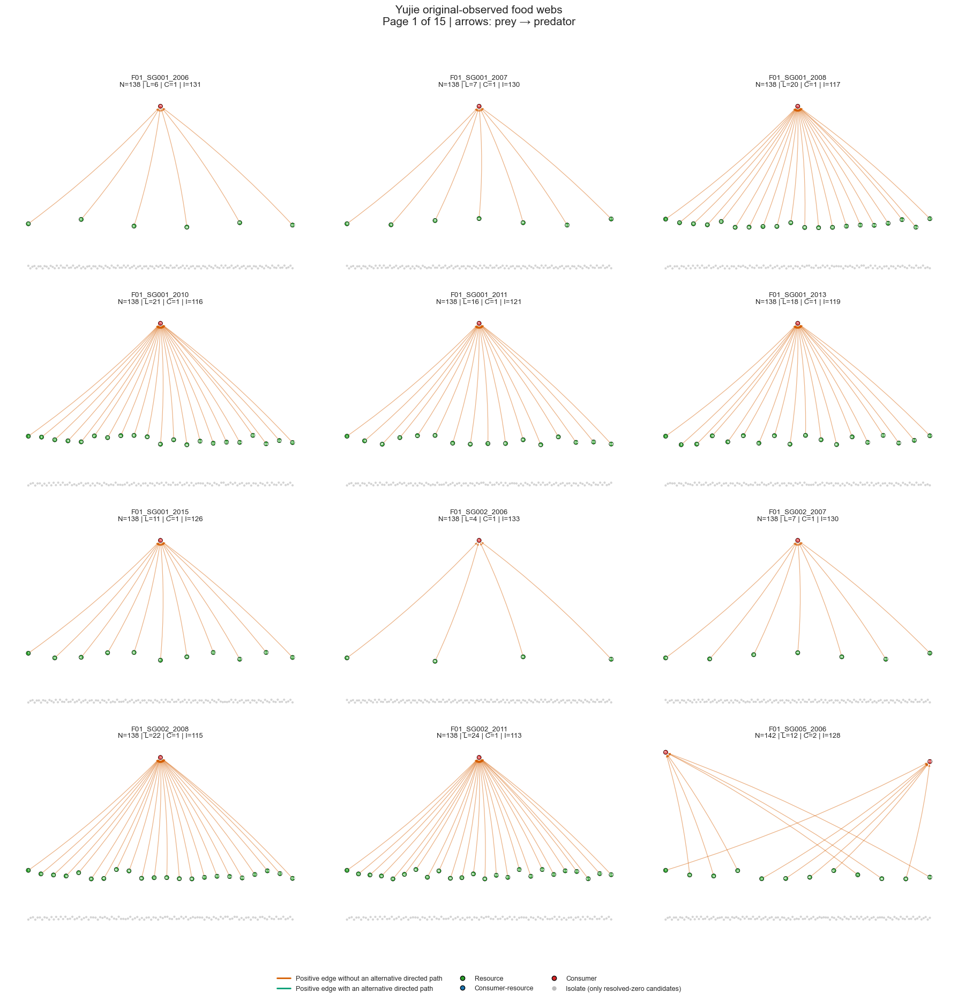

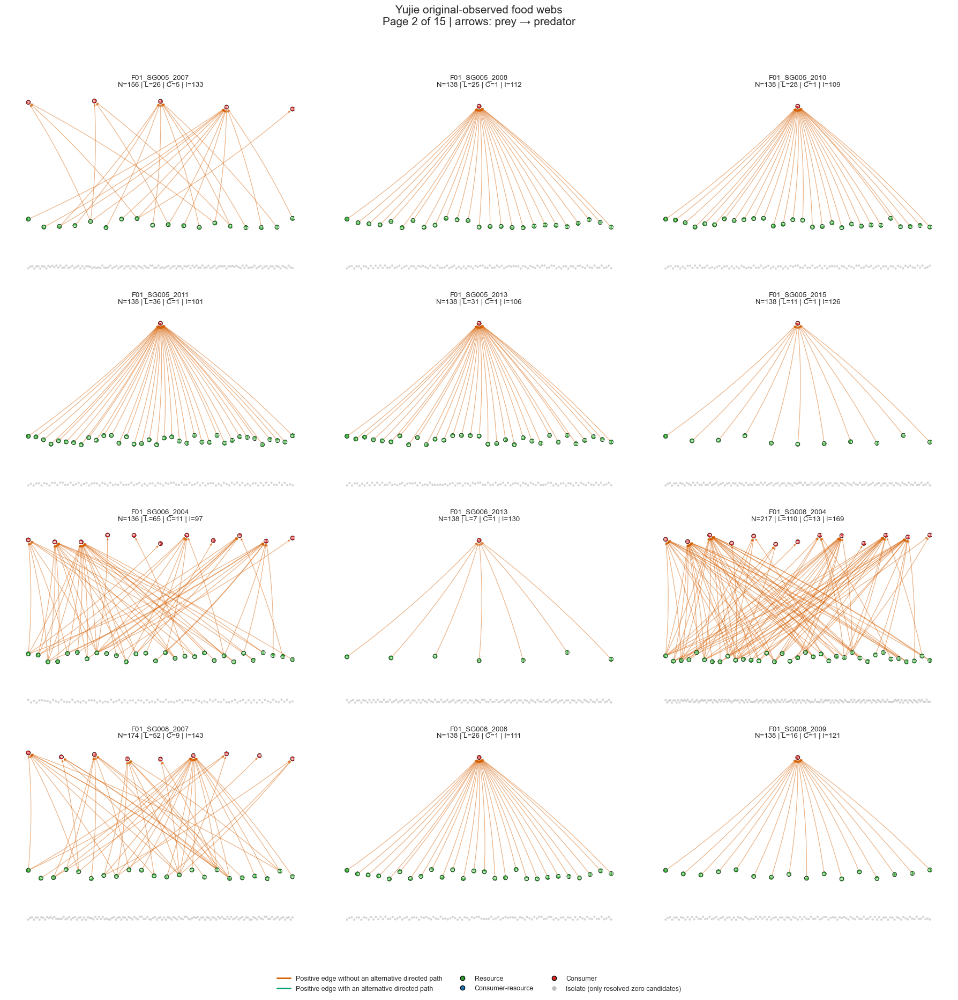

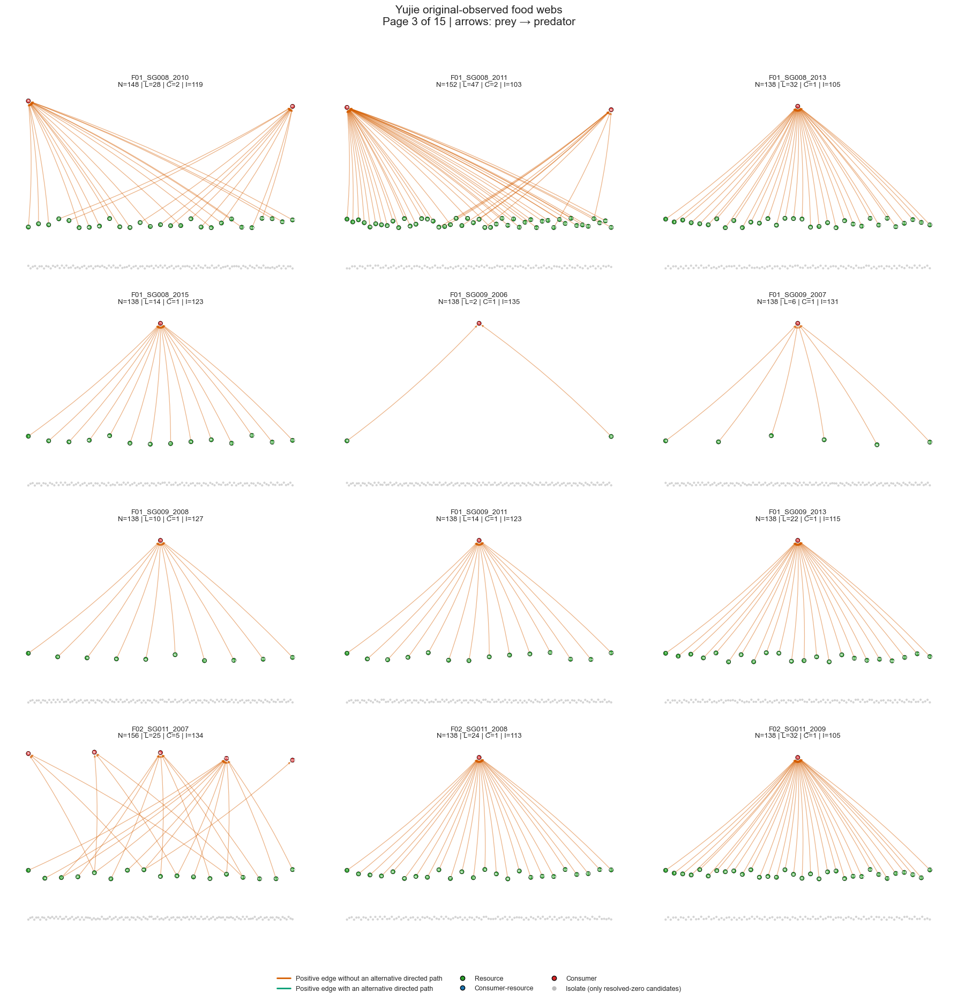

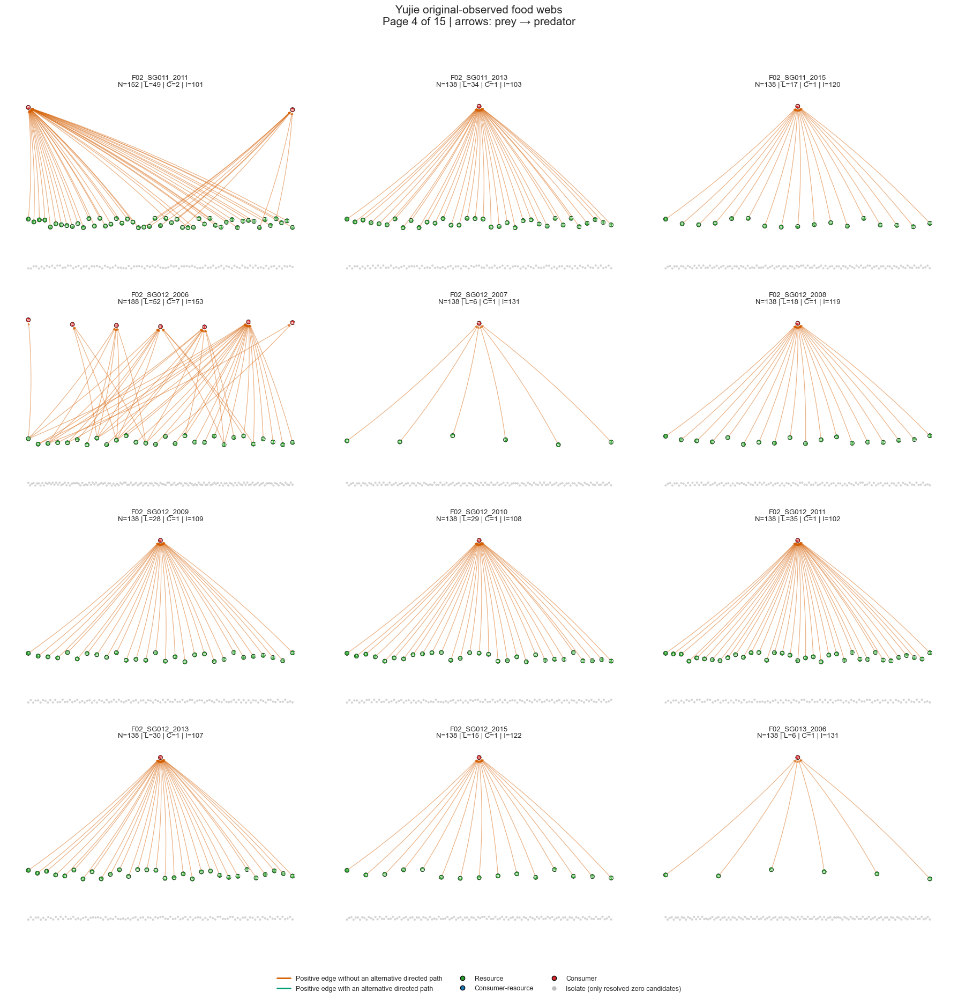

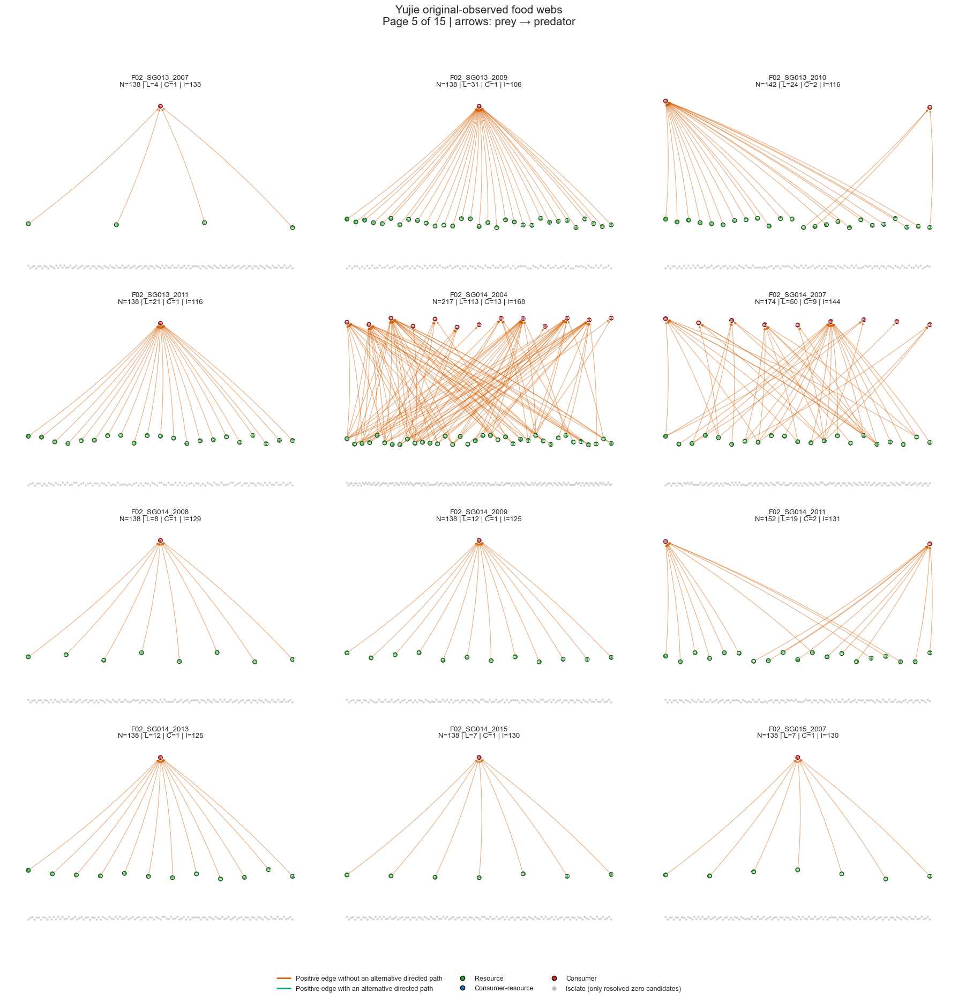

...

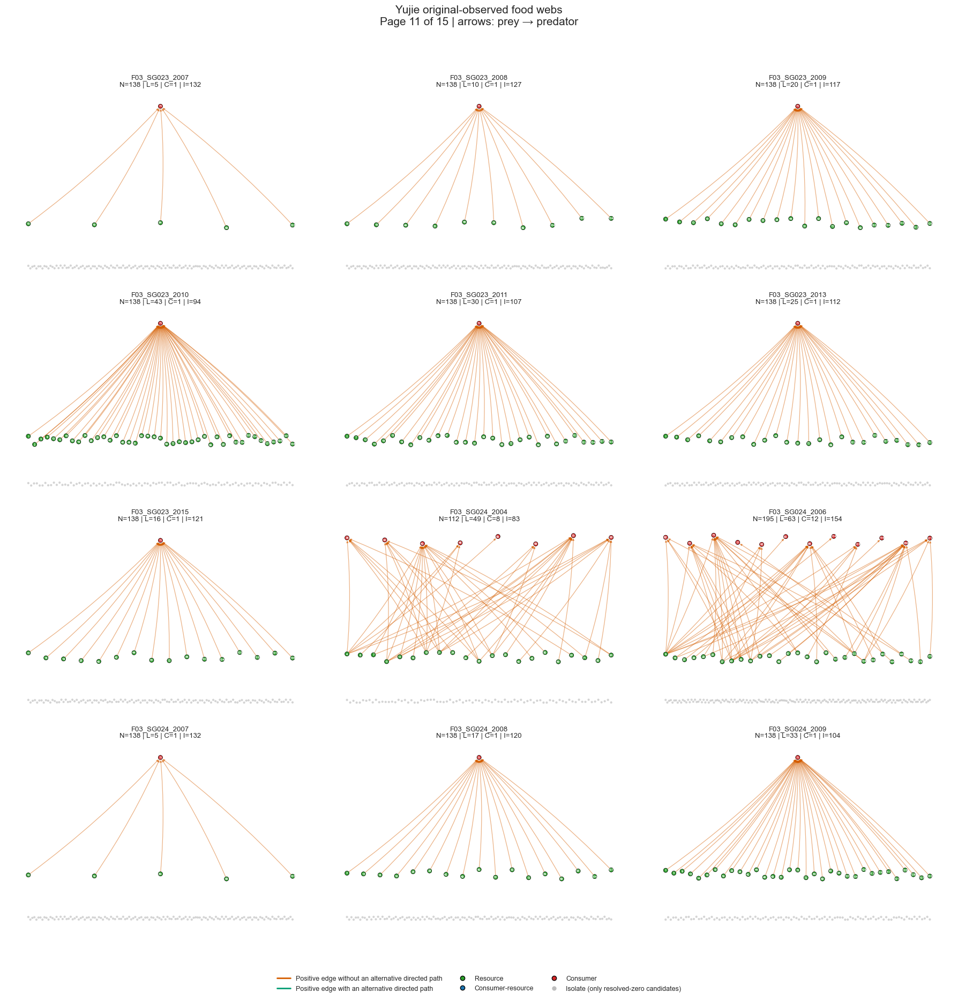

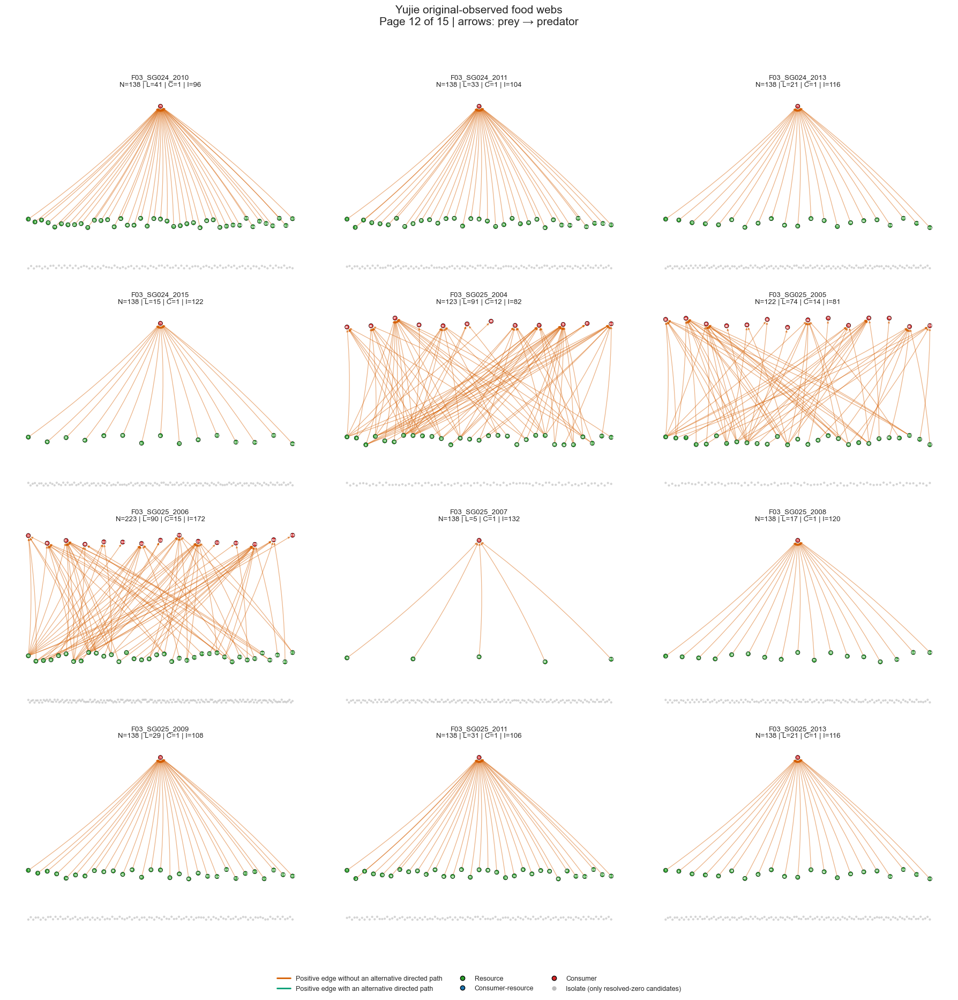

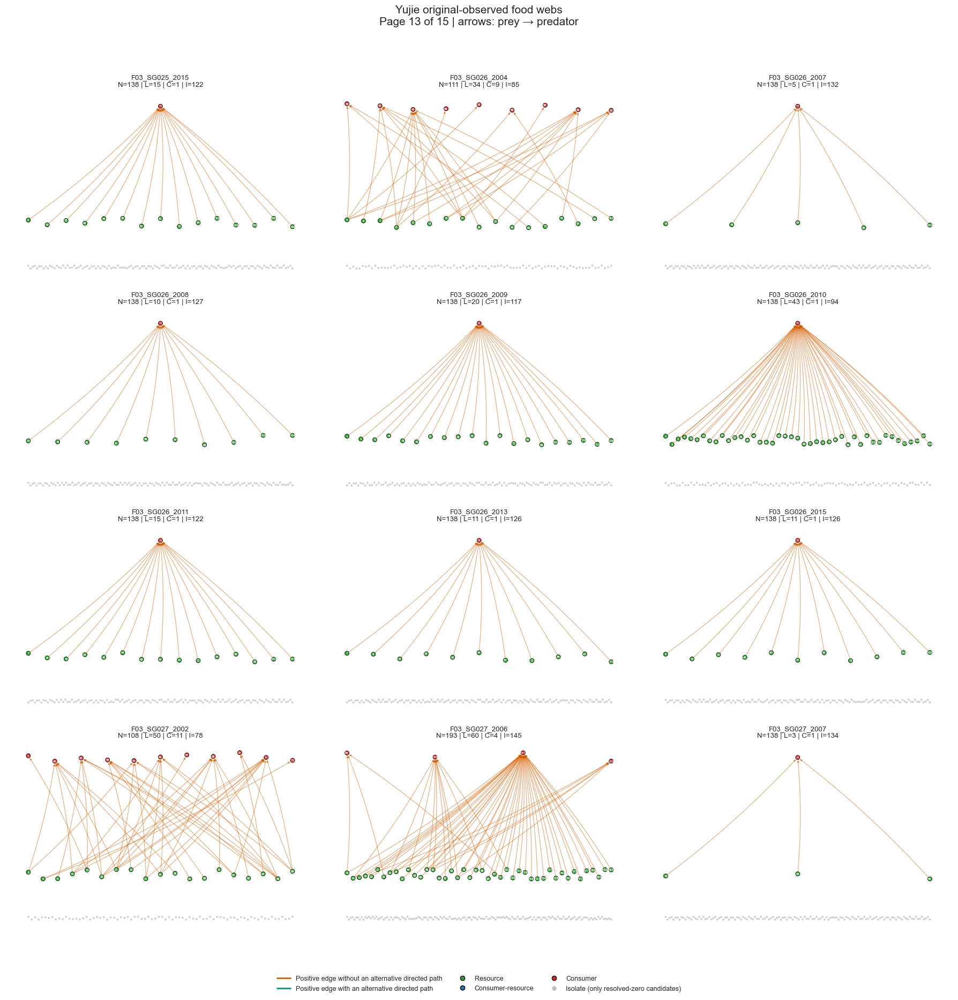

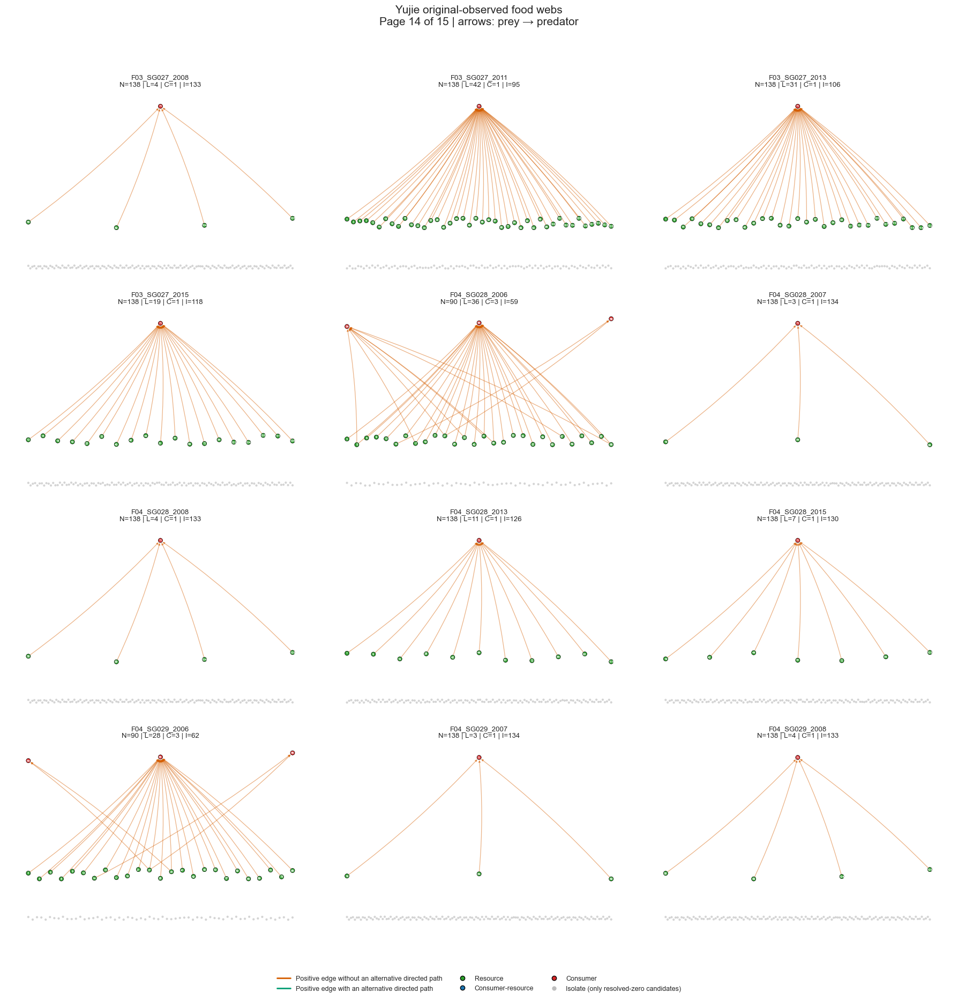

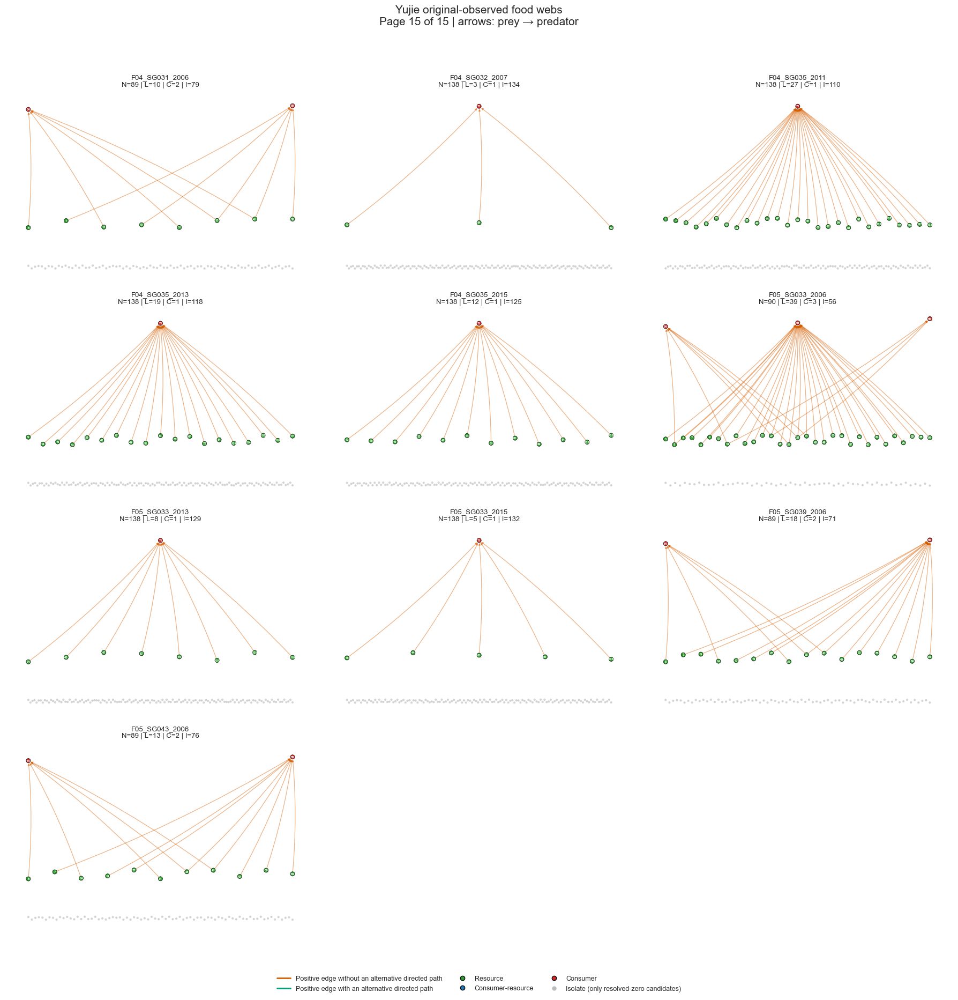

### Structural summary of displayed Yujie networks

,FoodWeb,Fold,Group,Year,Nodes,PositiveLinks,ObservedZeros,Resources,ConsumerResources,Consumers,Isolates,EdgesWithAlternativePath,ProtectedEdges
0,F01_SG001_2006,1,SG001,2006,138,6,131,6,0,1,131,0,6
1,F01_SG001_2007,1,SG001,2007,138,7,130,7,0,1,130,0,7
2,F01_SG001_2008,1,SG001,2008,138,20,117,20,0,1,117,0,20
3,F01_SG001_2010,1,SG001,2010,138,21,116,21,0,1,116,0,21
4,F01_SG001_2011,1,SG001,2011,138,16,121,16,0,1,121,0,16
...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,F05_SG033_2006,5,SG033,2006,90,39,85,31,0,3,56,0,39
174,F05_SG033_2013,5,SG033,2013,138,8,129,8,0,1,129,0,8
175,F05_SG033_2015,5,SG033,2015,138,5,132,5,0,1,132,0,5
176,F05_SG039_2006,5,SG039,2006,89,18,103,16,0,2,71,0,18


### Node-number lookup (first 25 rows)

,FoodWeb,NodeID,Taxon,Role,ParticipatesInPositiveNetwork
15,F01_SG001_2006,16,Annelida,resource,True
29,F01_SG001_2006,30,Cancridae,resource,True
50,F01_SG001_2006,51,Echinodermata,resource,True
68,F01_SG001_2006,69,Hydroida,resource,True
70,F01_SG001_2006,71,Limanda limanda_BE,consumer,True
83,F01_SG001_2006,84,Mollusca,resource,True
102,F01_SG001_2006,103,Ophiurida,resource,True
153,F01_SG001_2007,16,Annelida,resource,True
156,F01_SG001_2007,19,Arthropoda,resource,True
172,F01_SG001_2007,35,Chordata,resource,True


[INFO] Use node_key.loc[node_key['FoodWeb'].eq('F01_SG001_2006')] to translate node numbers into taxa.
[INFO] Networks with one consumer: 135
[INFO] Networks with at least one alternative directed path: 0


In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import Markdown, display
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch
from scipy import sparse
from scipy.io import loadmat


# ============================================================
# Configuration
# ============================================================

def find_repo_root(start=Path.cwd()):
    start = Path(start).resolve()
    candidates = [start, *start.parents]
    fallback = Path("/Users/acw792/Developer/qmul-phd-framework")

    if fallback not in candidates:
        candidates.append(fallback)

    for candidate in candidates:
        if (
            (candidate / "src/matlab").is_dir()
            and (candidate / "docs").is_dir()
        ):
            return candidate

    raise RuntimeError("Could not locate the qmul-phd-framework repository.")


REPO_ROOT = find_repo_root()
RESULT_ROOT = (
    REPO_ROOT
    / "src/matlab/data"
    / "result_wlnm_dir_neg_yujie_primary60_observedzero_20261008_001116"
)
MAT_DIR = (
    REPO_ROOT
    / "src/matlab/data/yujie_wlnm_preprocessed_v1/original_observed"
)
INPUT_MANIFEST = RESULT_ROOT / "INPUT_NETWORKS.csv"
FIG_DIR = RESULT_ROOT / "figures_network_structure"

EXPECTED_NETWORKS = 178
NETWORKS_PER_PAGE = 12
NUMBER_COLUMNS = 3

# None displays every page. For example, [1, 2] displays only pages 1 and 2.
PAGES_TO_DISPLAY = None

SHOW_ISOLATES = True
SHOW_ACTIVE_NODE_IDS = True
SAVE_FIGURES = False


# ============================================================
# Networks included in the completed Yujie campaign
# ============================================================

if not INPUT_MANIFEST.is_file():
    raise FileNotFoundError(INPUT_MANIFEST)

manifest = pd.read_csv(INPUT_MANIFEST)

required_manifest_columns = {
    "Foodweb",
    "fold",
    "group_id",
    "year",
    "n_nodes",
    "n_positive",
    "n_observed_zero",
    "n_resource",
    "n_consumer",
    "n_consumer_resource",
    "n_isolate",
}
missing_manifest_columns = required_manifest_columns.difference(manifest.columns)
if missing_manifest_columns:
    raise ValueError(
        f"INPUT_NETWORKS.csv is missing {sorted(missing_manifest_columns)}"
    )

manifest = (
    manifest
    .sort_values(["fold", "group_id", "year", "Foodweb"])
    .reset_index(drop=True)
)

if len(manifest) != EXPECTED_NETWORKS:
    raise ValueError(
        f"Expected {EXPECTED_NETWORKS} Yujie networks; found {len(manifest)}."
    )
if manifest["Foodweb"].duplicated().any():
    raise ValueError("Duplicated Yujie network identifiers in INPUT_NETWORKS.csv.")

TARGET_FOODWEBS = manifest["Foodweb"].tolist()

missing_mat_files = [
    network_id
    for network_id in TARGET_FOODWEBS
    if not (MAT_DIR / f"{network_id}.mat").is_file()
]
if missing_mat_files:
    raise FileNotFoundError(
        "Missing Yujie MAT files: " + ", ".join(missing_mat_files[:10])
    )

number_pages = int(np.ceil(len(TARGET_FOODWEBS) / NETWORKS_PER_PAGE))

if PAGES_TO_DISPLAY is None:
    selected_pages = list(range(1, number_pages + 1))
else:
    selected_pages = sorted(set(int(page) for page in PAGES_TO_DISPLAY))
    invalid_pages = [
        page for page in selected_pages if page < 1 or page > number_pages
    ]
    if invalid_pages:
        raise ValueError(
            f"Invalid pages {invalid_pages}; valid range is 1-{number_pages}."
        )

print(f"[INFO] Yujie networks available: {len(TARGET_FOODWEBS)}")
print(f"[INFO] Pages: {number_pages} ({NETWORKS_PER_PAGE} networks per page)")
print(f"[INFO] Pages selected: {selected_pages}")


# ============================================================
# Roles, colours and MAT loading
# ============================================================

ROLE_CODE = {
    "resource": 1,
    "consumer-resource": 2,
    "consumer resource": 2,
    "consumer_resource": 2,
    "consumer": 3,
    "isolate": 4,
}

ROLE_LABEL = {
    1: "Resource",
    2: "Consumer-resource",
    3: "Consumer",
    4: "Isolate (only resolved-zero candidates)",
    0: "Unknown",
}

ROLE_COLOR = {
    1: "#2CA02C",
    2: "#1F77B4",
    3: "#D62728",
    4: "#BDBDBD",
    0: "#222222",
}

PROTECTED_EDGE_COLOR = "#D55E00"
REMOVABLE_EDGE_COLOR = "#009E73"


def matlab_string_array_to_list(values):
    array = np.asarray(values).squeeze()

    if array.ndim == 0:
        return [str(array.item()).strip()]

    output = []
    for item in array.ravel():
        if isinstance(item, np.ndarray):
            item = np.asarray(item).squeeze()
            if item.ndim == 0:
                output.append(str(item.item()).strip())
            else:
                output.append("".join(item.astype(str).ravel()).strip())
        else:
            output.append(str(item).strip())

    return output


def encode_role(role_value):
    return ROLE_CODE.get(str(role_value).strip().lower(), 0)


def as_boolean_sparse(matrix):
    if sparse.issparse(matrix):
        output = matrix.astype(bool).tocsr()
    else:
        output = sparse.csr_matrix(np.asarray(matrix) > 0)
    output.eliminate_zeros()
    return output


def load_yujie_network(network_id):
    mat_path = MAT_DIR / f"{network_id}.mat"
    data = loadmat(
        mat_path,
        squeeze_me=True,
        struct_as_record=False,
        spmatrix=True,
    )

    required_fields = {
        "net",
        "observed_negative_mask",
        "candidate_mask",
        "role",
        "taxonomy",
        "network_id",
        "data_regime",
    }
    missing_fields = required_fields.difference(data)
    if missing_fields:
        raise KeyError(f"{mat_path.name}: missing {sorted(missing_fields)}")

    net = as_boolean_sparse(data["net"])
    observed_zero = as_boolean_sparse(data["observed_negative_mask"])
    candidate_mask = as_boolean_sparse(data["candidate_mask"])
    roles = matlab_string_array_to_list(data["role"])
    taxonomy = matlab_string_array_to_list(data["taxonomy"])

    number_nodes = net.shape[0]
    if net.shape[0] != net.shape[1]:
        raise ValueError(f"{mat_path.name}: net is not square")
    if observed_zero.shape != net.shape or candidate_mask.shape != net.shape:
        raise ValueError(f"{mat_path.name}: mask dimensions do not match net")
    if len(roles) != number_nodes or len(taxonomy) != number_nodes:
        raise ValueError(f"{mat_path.name}: node metadata length mismatch")
    if net.multiply(observed_zero).nnz:
        raise ValueError(f"{mat_path.name}: positives overlap observed zeros")

    return {
        "path": mat_path,
        "net": net,
        "observed_zero": observed_zero,
        "candidate_mask": candidate_mask,
        "roles": roles,
        "taxonomy": taxonomy,
    }


# ============================================================
# Directed alternative paths
# ============================================================

def has_alternative_directed_path(adjacency, source, target):
    visited = {source}
    stack = [source]

    while stack:
        current = stack.pop()

        for neighbor in adjacency[current]:
            if current == source and neighbor == target:
                continue
            if neighbor == target:
                return True
            if neighbor not in visited:
                visited.add(neighbor)
                stack.append(neighbor)

    return False


def classify_positive_edges(net):
    adjacency = [
        net.indices[net.indptr[node]:net.indptr[node + 1]].tolist()
        for node in range(net.shape[0])
    ]
    source, target = net.nonzero()
    positive_edges = [
        (int(i), int(j))
        for i, j in zip(source, target)
        if i != j
    ]

    removable = []
    protected = []
    for i, j in positive_edges:
        if has_alternative_directed_path(adjacency, i, j):
            removable.append((i, j))
        else:
            protected.append((i, j))

    return positive_edges, removable, protected


# ============================================================
# Role-layered layout and drawing
# ============================================================

def role_layered_layout(role_codes):
    y_by_role = {
        4: -0.75,  # isolates
        1: 0.0,    # resources
        2: 1.0,    # consumer-resources
        3: 2.0,    # consumers
        0: 2.8,    # unknown
    }
    positions = np.zeros((len(role_codes), 2), dtype=float)

    for role_code in [4, 1, 2, 3, 0]:
        indices = np.where(role_codes == role_code)[0]
        if len(indices) == 0:
            continue

        x_values = (
            np.array([0.5])
            if len(indices) == 1
            else np.linspace(0.04, 0.96, len(indices))
        )
        y_base = y_by_role[role_code]

        for x_value, node_index in zip(x_values, indices):
            jitter_scale = 0.025 if role_code == 4 else 0.08
            jitter = jitter_scale * np.sin((node_index + 1) * 2.17)
            positions[node_index] = [x_value, y_base + jitter]

    return positions


def draw_arrow(axis, positions, source, target, color, linewidth, alpha, zorder):
    axis.add_patch(
        FancyArrowPatch(
            positions[source],
            positions[target],
            arrowstyle="-|>",
            mutation_scale=5.5,
            linewidth=linewidth,
            color=color,
            alpha=alpha,
            shrinkA=3.5,
            shrinkB=3.5,
            connectionstyle="arc3,rad=0.045",
            zorder=zorder,
        )
    )


def draw_yujie_network(axis, network_id, manifest_row):
    network = load_yujie_network(network_id)
    net = network["net"]
    role_codes = np.asarray([encode_role(role) for role in network["roles"]])

    observed_counts = {
        "n_nodes": int(net.shape[0]),
        "n_positive": int(net.nnz),
        "n_observed_zero": int(network["observed_zero"].nnz),
        "n_resource": int((role_codes == 1).sum()),
        "n_consumer_resource": int((role_codes == 2).sum()),
        "n_consumer": int((role_codes == 3).sum()),
        "n_isolate": int((role_codes == 4).sum()),
    }
    for column, observed in observed_counts.items():
        expected = int(manifest_row[column])
        if observed != expected:
            raise ValueError(
                f"{network_id}: {column}={observed}, expected {expected}"
            )

    positions = role_layered_layout(role_codes)

    positive_edges, removable_edges, protected_edges = classify_positive_edges(net)

    for source, target in protected_edges:
        draw_arrow(
            axis,
            positions,
            source,
            target,
            PROTECTED_EDGE_COLOR,
            linewidth=0.9,
            alpha=0.48,
            zorder=1,
        )

    for source, target in removable_edges:
        draw_arrow(
            axis,
            positions,
            source,
            target,
            REMOVABLE_EDGE_COLOR,
            linewidth=1.6,
            alpha=0.9,
            zorder=2,
        )

    active_mask = role_codes != ROLE_CODE["isolate"]
    isolate_mask = role_codes == ROLE_CODE["isolate"]

    if SHOW_ISOLATES and isolate_mask.any():
        axis.scatter(
            positions[isolate_mask, 0],
            positions[isolate_mask, 1],
            s=9,
            c=ROLE_COLOR[4],
            edgecolors="none",
            alpha=0.65,
            zorder=0,
        )

    if active_mask.any():
        axis.scatter(
            positions[active_mask, 0],
            positions[active_mask, 1],
            s=34,
            c=[ROLE_COLOR.get(int(code), ROLE_COLOR[0]) for code in role_codes[active_mask]],
            edgecolors="black",
            linewidths=0.45,
            zorder=3,
        )

    if SHOW_ACTIVE_NODE_IDS:
        for node_index in np.where(active_mask)[0]:
            x_value, y_value = positions[node_index]
            axis.text(
                x_value,
                y_value,
                str(node_index + 1),
                ha="center",
                va="center",
                fontsize=4.2,
                color="white",
                fontweight="bold",
                zorder=4,
            )

    axis.set_title(
        f"{network_id}\n"
        f"N={net.shape[0]} | L={len(positive_edges)} | "
        f"C={int((role_codes == 3).sum())} | "
        f"I={int(isolate_mask.sum())}",
        fontsize=9.5,
    )
    axis.set_xlim(-0.04, 1.04)
    axis.set_ylim(-1.02 if SHOW_ISOLATES else -0.22, 2.25)
    axis.set_xticks([])
    axis.set_yticks([])
    for spine in axis.spines.values():
        spine.set_visible(False)

    structural_row = {
        "FoodWeb": network_id,
        "Fold": int(manifest_row["fold"]),
        "Group": manifest_row["group_id"],
        "Year": int(manifest_row["year"]),
        "Nodes": int(net.shape[0]),
        "PositiveLinks": int(len(positive_edges)),
        "ObservedZeros": int(network["observed_zero"].nnz),
        "Resources": int((role_codes == 1).sum()),
        "ConsumerResources": int((role_codes == 2).sum()),
        "Consumers": int((role_codes == 3).sum()),
        "Isolates": int(isolate_mask.sum()),
        "EdgesWithAlternativePath": int(len(removable_edges)),
        "ProtectedEdges": int(len(protected_edges)),
    }

    node_rows = [
        {
            "FoodWeb": network_id,
            "NodeID": int(node_index + 1),
            "Taxon": network["taxonomy"][node_index],
            "Role": network["roles"][node_index],
            "ParticipatesInPositiveNetwork": bool(active_mask[node_index]),
        }
        for node_index in range(net.shape[0])
    ]

    return structural_row, node_rows


# ============================================================
# Paginated visualization of all selected Yujie networks
# ============================================================

legend_elements = [
    Line2D(
        [0], [0], color=PROTECTED_EDGE_COLOR, linewidth=2,
        label="Positive edge without an alternative directed path",
    ),
    Line2D(
        [0], [0], color=REMOVABLE_EDGE_COLOR, linewidth=2,
        label="Positive edge with an alternative directed path",
    ),
    *[
        Line2D(
            [0], [0], marker="o", linestyle="None",
            markerfacecolor=ROLE_COLOR[role_code],
            markeredgecolor="black" if role_code != 4 else "none",
            markersize=6,
            label=ROLE_LABEL[role_code],
        )
        for role_code in [1, 2, 3, 4]
    ],
]

structural_rows = []
node_key_rows = []

for page_number in selected_pages:
    first_index = (page_number - 1) * NETWORKS_PER_PAGE
    page_networks = TARGET_FOODWEBS[
        first_index:first_index + NETWORKS_PER_PAGE
    ]
    number_rows = int(np.ceil(len(page_networks) / NUMBER_COLUMNS))

    fig, axes = plt.subplots(
        number_rows,
        NUMBER_COLUMNS,
        figsize=(18, 4.7 * number_rows),
        squeeze=False,
    )
    axes = axes.reshape(-1)

    for axis, network_id in zip(axes, page_networks):
        manifest_row = manifest.loc[manifest["Foodweb"].eq(network_id)].iloc[0]
        structural_row, node_rows = draw_yujie_network(
            axis,
            network_id,
            manifest_row,
        )
        structural_rows.append(structural_row)
        node_key_rows.extend(node_rows)

    for axis in axes[len(page_networks):]:
        axis.set_visible(False)

    fig.legend(
        handles=legend_elements,
        loc="lower center",
        ncol=3,
        frameon=False,
        bbox_to_anchor=(0.5, 0.01),
        fontsize=9,
    )
    fig.suptitle(
        "Yujie original-observed food webs\n"
        f"Page {page_number} of {number_pages} | arrows: prey → predator",
        fontsize=15,
        y=0.995,
    )
    fig.tight_layout(rect=[0, 0.065, 1, 0.965])

    if SAVE_FIGURES:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        output_path = FIG_DIR / f"yujie_networks_page_{page_number:02d}.png"
        fig.savefig(output_path, dpi=300, bbox_inches="tight", facecolor="white")
        print(f"[INFO] Saved: {output_path}")

    plt.show()
    plt.close(fig)


# ============================================================
# Structural summary and node-number lookup
# ============================================================

structural_summary = (
    pd.DataFrame(structural_rows)
    .sort_values(["Fold", "Group", "Year", "FoodWeb"])
    .reset_index(drop=True)
)
node_key = (
    pd.DataFrame(node_key_rows)
    .sort_values(["FoodWeb", "NodeID"])
    .reset_index(drop=True)
)

display(Markdown("### Structural summary of displayed Yujie networks"))
display(structural_summary)

display(Markdown("### Node-number lookup (first 25 rows)"))
display(
    node_key.loc[node_key["ParticipatesInPositiveNetwork"]]
    .head(25)
)

print(
    "[INFO] Use node_key.loc[node_key['FoodWeb'].eq('F01_SG001_2006')] "
    "to translate node numbers into taxa."
)

if PAGES_TO_DISPLAY is None:
    if len(structural_summary) != EXPECTED_NETWORKS:
        raise RuntimeError(
            f"Expected summaries for {EXPECTED_NETWORKS} networks; "
            f"found {len(structural_summary)}."
        )
    if structural_summary["FoodWeb"].duplicated().any():
        raise RuntimeError("A Yujie network was visualized more than once.")

    print(
        "[INFO] Networks with one consumer: "
        f"{int(structural_summary['Consumers'].eq(1).sum())}"
    )
    print(
        "[INFO] Networks with at least one alternative directed path: "
        f"{int(structural_summary['EdgesWithAlternativePath'].gt(0).sum())}"
    )

if SAVE_FIGURES:
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    structural_summary.to_csv(
        FIG_DIR / "yujie_network_structural_summary.csv",
        index=False,
    )
    node_key.to_csv(
        FIG_DIR / "yujie_network_node_key.csv",
        index=False,
    )
